# NINO3.4, TSA and AMM in monthly quintile forecasts of rainfall in Northeast Brazil: assessed lags, calibration and three machine learning models

`monthly CHIRPS v2.0 · 0.05° pixels · 1981–2025 · targets NNEB, INEB and ENEB · hydrological year, wet season and dry season · reference 1981–2010 · quintiles q20, q40, q60 and q80 · ridge regression, random forest and dense neural network (MLP) · forecasts for the whole target (regional hypothesis) and for each pixel (local hypotheses)`

The study checks whether NINO3.4, TSA and AMM, each on its own, are associated with monthly rainfall in NNEB, INEB and ENEB, when and how, and whether that association improves rainfall forecasts in 2011–2025. Quintiles, lags and model configurations are metrics assessed with 1981–2010 and stored before the test.

**Question and hypothesis.** Are the indices associated with the rainfall of each target? When (lag) and how (sign, and where within the target)? Does that association help forecast the rainfall response to ocean anomalies? The design measures association and forecast skill; the physical reading of this evidence is interpretation, with no causal effect estimated.

- **RPS** (Epstein, 1969) is the error of a probability forecast for ordered classes: 0 if perfect; missing by two classes weighs more than by one.
- **Climatology N** is the forecast of someone who does not know the index: the frequency of each class in the same month in 1981–2010 (about 20%). The **control** is the model's twin without the index: same architecture, regularization, number of networks, training, dimensions, seeds and initializations, with the input replaced by zeros.
- **H0:** the RPSS of the model with the index aligned at L\*, measured over its control, does not exceed that obtained with the time-shifted index (with no temporal relation to rainfall). **H1:** it does. The RPSS measures the benefit of giving the index to that model; on its own, it does not show a gain over the empirical climatology.
- **RPSS** = 100 × (1 − RPS of the model / RPS of the reference): 0% equals the reference; positive is better. Example with N: in a Q1 month, N has RPS 0.30, and a model giving 40, 25, 20, 10 and 5% from Q1 to Q5 has 0.13 (+58%); had the month been Q5, it would have 0.55 (−84%). That is why the hypothesis sums all test months.
- **Decision:** hypothesis supported with RPSS > 0 and q < 0.05. The p-value comes from circularly shifting the index relative to rainfall (4-month step, chosen for cost; minimum p 1/131), repeating in each shift the index preparation, the choice of L\*, the fit and the control, without repeating calibration; a shared trend between index and rainfall counts as association. Correction for the 27 tests of each model (Benjamini and Hochberg, 1995). Where the ridge check (Section 9) shows rejection above 5% when the index shares only the linear trend with rainfall, the gain cannot be attributed to interannual variability and is reclassified as inconclusive. Inference is conditional on the input form and hyperparameters from calibration, which are not redone in the shifts.
- **Reading:** a positive RPSS without significance is an indication, not confirmation; "not detected" is not "no effect" (the 95% CI expresses the uncertainty of the estimate; it neither proves the absence of an effect nor replaces the adopted test); association without skill is a legitimate result. The test period was examined during the development of the study, and this is declared.

**Periods and pipeline.** 45 years of data (1981–2025). Each role is a calendar window, and only hydrological years with all 12 months inside it are used; a year that crosses the boundary enters no role. Final reference Jan 1981–Dec 2010: quantiles, classes and N with the 30 calendar years (the run stops if there are fewer), and lags and final fit with 30 hydrological years in NNEB and 29 in INEB and ENEB, whose hydrological years start in November and March. Calibration: training Jan 1981–Dec 1995 (with its own quantiles) and validation Jan 1996–Dec 2010 (15 years in NNEB, 14 in INEB and ENEB). Test Jan 2011–Dec 2025: 15 hydrological years in NNEB and 14 in INEB and ENEB, opened after the metrics are stored. The run stops if the shared calibration choice uses any month after the start of the test of any target.

| order | steps | years used |
|---|---|---|
| 1 | CHIRPS homogeneity (S1) | 1981–2025, without the indices (quality control) |
| 2 | reference, quintiles and calendar (S1); regional and pixel lags (S2, S3) | Jan 1981–Dec 2010 |
| 3 | calibration and synthetic experiment (S4) | training Jan 1981–Dec 1995, validation Jan 1996–Dec 2010 |
| — | **gate: assessed metrics stored in `registros/` before opening the test** | |
| 4 | final fit, null with shifted index, comparison and pixel by pixel (S5–S10) | training Jan 1981–Dec 2010, test Jan 2011–Dec 2025 |
| 5 | closing: answers, verdict and SHA-256 manifest | — |

**The sections, one by one.**

**Section 1 · Climatology and sanity.** Sets the yardstick: quintiles of monthly rainfall for each month in 1981–2010, the season calendar and the class of each month in each 0.05° CHIRPS pixel (Funk et al., 2015) and in each target; ties count by half, N uses the observed frequency of each class, and the table of limits in mm follows the same rule, indicating whether each limit is included in the class (ties) and any empty classes. Four homogeneity tests (Wijngaard et al., 2003) flag pixels with a possible break, counted in the sanity figure, listed in `registros/pixels_suspeitos.csv` and kept in the analyses.

**Section 2 · Regional association and lag.** Correlation of the index at t − L with the rainfall quantile of the target, from L0 to L12, in 1981–2010: answers whether there is association, when (L*, the lag of largest |r|) and with what sign. The p-value shifts the index in time and repeats the search, keeping the internal order of the index.

**Section 3 · Pixel association.** The same correlation in each pixel shows where, within the target, the association appears. Test by map and by pixel, with a 10% false discovery rate (Wilks, 2016); a significant pixel uses its own lag, and the others the regional one.

**Section 4 · Calibration.** With the same protocol as the application (training 1981–1995, validation 1996–2010), assesses the input form of the index and the hyperparameters of the three models, over grids that reach climatology; the simplest configuration within one standard error of the best is kept (Hastie et al., 2009). A synthetic experiment, with one noise realization, describes how calibration reacts to a weak planted signal (it is not a power calculation).

**Section 5 · Climatology as a forecast.** Compares N with N-index (class frequency by index phase at L\*): does the index help without a model? Sets the common rules: hydrological year as the unit, 95% CI from circular 3-year blocks (a heuristic; Künsch, 1989), the control of the same model without the index and the p-value from shifting the index, with its resolution declared.

**Section 6 · Ridge.** Linear response (Hoerl and Kennard, 1970): each standard deviation of the index at L* shifts the forecast distribution. Single training 1981–2010, test 2011–2025; compares L* with N (hypothesis) and with L1 (does the assessed lag matter?).

**Section 7 · Random forest.** Same input and test; 100 classification trees (Breiman, 2001) split the months by index thresholds and capture an effect that appears only above a threshold, as in a strong El Niño.

**Section 8 · Neural network.** Same input and test; one hidden layer with output over the five classes, AdamW (Loshchilov and Hutter, 2019), no early stopping, regularization assessed in calibration and the mean of 3 networks: a smooth, nonlinear response.

**Section 9 · Comparison and validity.** Methods are compared through the RPS difference in the same months, with climatology N as the scale (the RPSS of each method has a different control and cannot be compared); the three cases side by side; reliability of the probabilities (grouped Brier components; Murphy, 1973); check of the shift test with ridge regression, for the whole target, in a scenario with the index trend (Ebisuzaki, 1997), not extended to the other models or the maps; sensitivity of the 95% CI to 2- and 4-year blocks.

**Section 10 · Pixel by pixel.** In each pixel, the three models make their own local forecast against the no-index twin (same dimensions, seeds and initializations), with a t-test by year and a 10% false discovery rate over the map (Wilks, 2016); validation with the shifted index measures false alarms without proving control of the rate. The maps answer a local question and may differ from the regional result, which comes from the target mean; hyperparameters from the regional calibration.

**Closing.** One answer per section drawn from the tables, a verdict by target, case, index and model, and a SHA-256 manifest of the outputs.

**Cover references.** BENJAMINI, Y.; HOCHBERG, Y. **J. R. Stat. Soc. B**, v. 57, p. 289-300, 1995 · BREIMAN, L. **Machine Learning**, v. 45, p. 5-32, 2001 · EPSTEIN, E. S. **J. Appl. Meteorol.**, v. 8, p. 985-987, 1969 · FUNK, C. et al. **Scientific Data**, v. 2, 150066, 2015 · HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. **The elements of statistical learning**. 2nd ed. Springer, 2009 · HOERL, A. E.; KENNARD, R. W. **Technometrics**, v. 12, p. 55-67, 1970 · KÜNSCH, H. R. **Ann. Stat.**, v. 17, p. 1217-1241, 1989 · LOSHCHILOV, I.; HUTTER, F. ICLR, 2019 · MURPHY, A. H. **J. Appl. Meteorol.**, v. 12, p. 595-600, 1973 · WIJNGAARD, J. B. et al. **Int. J. Climatol.**, v. 23, p. 679-692, 2003 · EBISUZAKI, W. **J. Climate**, v. 10, p. 2147-2153, 1997 · POLITIS, D. N.; ROMANO, J. P. In: Exploring the limits of bootstrap. Wiley, 1992, p. 263-270 · WILKS, D. S. **Bull. Am. Meteorol. Soc.**, v. 97, p. 2263-2273, 2016. Full references in each section.

In [1]:
# =============================================================================
# Ambiente: bibliotecas, versões, dispositivo (GPU ou CPU), sementes e determinismo.
# Não lê dados nem grava resultados.
# =============================================================================
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')    # GPU determinística (antes do torch)

import copy
import hashlib
import itertools
import json
import platform
import random
import re
import sys
import threading
import time
import unicodedata
import warnings
import zipfile
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path

if sys.version_info < (3, 10):
    raise RuntimeError('O notebook exige Python 3.10 ou mais recente.')

_FALTANDO = []
for _modulo in ('numpy', 'pandas', 'scipy', 'sklearn', 'matplotlib', 'torch', 'xarray',
                'h5netcdf', 'fsspec', 'requests', 'geopandas', 'shapely', 'pyproj', 'tqdm', 'PIL'):
    try:
        __import__(_modulo)
    except ImportError:
        _FALTANDO.append(_modulo)
if _FALTANDO:
    raise ImportError('Pacotes ausentes: ' + ', '.join(_FALTANDO)
                      + '. Instale com: pip install -r requirements.txt (ver README).')

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy import stats
from scipy.special import ndtr, ndtri
warnings.filterwarnings('ignore', message='IProgress not found')    # aviso com caminho local
from tqdm.auto import tqdm

%matplotlib inline

SEMENTE_RAIZ = 42
random.seed(SEMENTE_RAIZ)
np.random.seed(SEMENTE_RAIZ)
torch.manual_seed(SEMENTE_RAIZ)
torch.use_deterministic_algorithms(True)            # estrito: operação não determinística é erro
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(max(1, os.cpu_count() or 1))
# as redes do estudo são pequenas e treinadas em lote na CPU, o que garante o mesmo resultado
# em qualquer máquina; a GPU, se houver, não é usada
DISPOSITIVO = torch.device('cpu')
N_NUCLEOS = max(1, os.cpu_count() or 1)

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice')
warnings.filterwarnings('ignore', message='All-NaN slice encountered')
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0')
warnings.filterwarnings('ignore', message='invalid value encountered')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

# threads que podem mudar a ordem das somas em ponto flutuante: registradas e incluídas na
# assinatura; sementes iguais não garantem números idênticos entre plataformas ou versões
from threadpoolctl import threadpool_info
THREADS = {'pytorch (intra-op)': torch.get_num_threads(),
           'pytorch (inter-op)': torch.get_num_interop_threads(),
           'BLAS e OpenMP': '; '.join(sorted({f"{d['internal_api']} {d['num_threads']}"
                                              for d in threadpool_info()})),
           'processos paralelos (joblib)': N_NUCLEOS}
AMBIENTE = pd.DataFrame([
    ('Python', platform.python_version()), ('sistema', platform.platform()),
    ('arquitetura', platform.machine()),
    ('NumPy', np.__version__), ('pandas', pd.__version__), ('SciPy', scipy.__version__),
    ('scikit-learn', sklearn.__version__), ('PyTorch', torch.__version__),
    ('Matplotlib', matplotlib.__version__), ('dispositivo das redes', str(DISPOSITIVO)),
    ('determinismo do PyTorch', 'estrito (use_deterministic_algorithms)'),
    *[(f'threads: {k}', v) for k, v in THREADS.items()],
    ('núcleos de CPU', N_NUCLEOS), ('semente raiz', SEMENTE_RAIZ)],
    columns=['item', 'valor'])
display(AMBIENTE)

,item,valor
0,Python,3.13.15
1,sistema,Windows-11-10.0.26200-SP0
2,arquitetura,AMD64
3,NumPy,2.5.3
4,pandas,3.0.5
5,SciPy,1.18.1
6,scikit-learn,1.9.1
7,PyTorch,2.14.1+cpu
8,Matplotlib,3.11.2
9,dispositivo das redes,cpu


In [2]:
# =============================================================================
# Configuração única, modo de execução (completo ou piloto), pastas do repositório e
# assinatura SHA-256 da execução (código das células + configuração). Não lê dados.
# =============================================================================
# 'completo' roda o estudo inteiro; 'piloto' confere o código de ponta a ponta com menos
# reamostragens, menos árvores, menos passagens, menos deslocamentos e um pixel a cada 40 na
# Seção 10 (os números do piloto não servem para conclusões). O modo é escolhido pela variável
# de ambiente CLIMATE_MODO.
MODO = os.environ.get('CLIMATE_MODO', 'completo')

CONFIG = {
    # 45 anos de dados (1981–2025); normal 1991–2020 (OMM): só descrição; referência final
    # 1981–2010 (30 anos, mínimo exigido): quantis, classes, climatologia N, defasagens e ajuste
    # final; a calibração interna (Seção 4) usa 15 + 15 anos por desenho, fora desta trava
    'periodo': {'inicio': '1981-01', 'fim': '2025-12', 'normal': [1991, 2020],
                'referencia': [1981, 2010], 'anos_referencia_minimo': 30,
                'meses_indice_antes': 24},
    # anos hidrológicos: defasagens, calibração e treino em 1981–2010; teste em 2011–2025
    'particao': {'treino': [1981, 2010], 'teste': [2011, 2025]},
    # pixels nativos do CHIRPS (0,05°), sem agregação
    'malha': {'resolucao_origem': 0.05, 'resolucao': 0.05},
    'fontes': {
        'chirps': ('https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/netcdf/'
                   'byYear/chirps-v2.0.{ano}.monthly.nc'),
        'indices': {'NINO3.4': 'https://psl.noaa.gov/data/correlation/nina34.anom.data',
                    'TSA': 'https://psl.noaa.gov/data/correlation/tsa.data',
                    'AMM': 'https://psl.noaa.gov/data/correlation/amm.data'},
        'ibge': ('https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/'
                 'malhas_municipais/municipio_2022'),
        'ufs': ['MA', 'PI', 'CE', 'RN', 'PB', 'PE', 'AL', 'SE', 'BA'],
    },
    'dominio': {'alvos': ['NNEB', 'INEB', 'ENEB'], 'indices': ['NINO3.4', 'TSA', 'AMM'],
                'sinal_esperado': {'NINO3.4': -1, 'TSA': 1, 'AMM': -1}},
    # estação chuvosa de cada alvo, fixada antes da execução; a Seção 1 recalcula o calendário
    # pela anomalia acumulada da referência 1981–2010 e interrompe a execução se houver diferença
    'calendario_chuvosa': {'NNEB': [1, 2, 3, 4, 5], 'INEB': [11, 12, 1, 2, 3, 4],
                           'ENEB': [3, 4, 5, 6, 7]},
    'casos': ['ano', 'chuvosa', 'seca'],
    # quintis do mesmo mês na referência: limites das cinco classes
    'quintis': [0.2, 0.4, 0.6, 0.8],
    # classes de um mês são marcadas como desequilibradas quando alguma classe se afasta mais que
    # este valor de 20 % na referência (empates); N usa a frequência observada de cada classe
    'desequilibrio_classes': 0.05,
    # homogeneidade relativa (Wijngaard et al., 2003): razão anual pixel/alvo, 4 testes a 1 %;
    # pixel suspeito (3 ou 4 testes rejeitam) é marcado nos mapas, não excluído
    'homogeneidade': {'alfa': 0.01, 'simulacoes': 20000, 'testes_para_marcar': 3},
    # janela L1–L12 em todos os casos; perfil diagnóstico até L18 (não altera L*)
    'defasagem': {'maxima_ano': 12, 'maxima_estacao': 12, 'diagnostico_ate': 18,
                  'deslocamento_minimo_meses': 24, 'passo_deslocamento': 1, 'reamostras': 1000},
    # calibração só com 1981–2010, com o mesmo protocolo da aplicação (treino único): treino
    # 1981–1995, validação 1996–2010; erro-padrão entre os 15 anos de validação
    'calibracao': {
        'treino': [1981, 1995], 'validacao': [1996, 2010],
        'entradas': ['pontual', 'media3', 'tendencia', 'janela3'],
        'sazonal': [False, True],
        'filtros': ['bruto', 'sem_tendencia'],
        # grades em ordem de simplicidade (a primeira é a mais regularizada)
        'ridge_penalidade_por_mes': [100.0, 10.0, 1.0, 0.1, 0.01],
        'rf_profundidade': [1, 2, 4, None], 'rf_folha': [0.3, 0.2, 0.1, 0.05],
        # folha 0,5 retirada (auditoria de 30/10/2026): exige metade exata do peso em cada folha;
        # com número ímpar de meses sorteados nenhuma árvore divide e a floresta vira o controle
        'rf_arvores': 100,
        'rede_oculta': [2, 4, 8], 'rede_decaimento': [10.0, 1.0, 0.1, 0.01, 0.001],
        'rede_passagens': [200, 1000], 'rede_ativacao': ['tanh', 'relu'], 'rede_taxa': 1e-2,
        'sinal_plantado': [0.0, 0.3],
    },
    # o mesmo número de redes na calibração, no alvo inteiro e nos pixels
    'redes': 3,
    # Seção 10: custo relativo de cada método (pesos do relatório de tempo); validação do teste
    # por pixel com deslocamentos do índice (Ridge); significância só pela taxa de falsas
    # descobertas; 1 % é apenas o limite da primeira classe de cor dos mapas
    'pixel': {'lote_redes': 6144, 'alfa_fdr': 0.10, 'classe_cor': 1.0, 'passo_piloto': 40,
              'deslocamentos_validacao': 5,
              'custo_relativo': {'Ridge': 1, 'Rede neural': 60, 'Random Forest': 60}},
    # IC95 por reamostragem conjunta de blocos de anos; nulo por deslocamento circular do índice
    # (procedimento inteiro repetido), com passo de 'passo_nulo' meses: 4 por custo computacional,
    # não por razão estatística (p mínimo 1/131)
    # validade do teste por deslocamento: realizações de um índice substituto (tendência linear +
    # resíduos com fases sorteadas; Ebisuzaki, 1997), procedimento da Ridge inteiro em cada uma;
    # sensibilidade do IC95 ao comprimento dos blocos
    'avaliacao': {'reamostras': 2000, 'alfa': 0.05, 'bloco_anos': 3, 'passo_nulo': 4,
                  'realizacoes_validade': 200, 'blocos_sensibilidade': [2, 3, 4]},
    'figuras': {'dpi': 1200, 'dpi_mapas': 600},
    # relatório parcial a cada 'intervalo_segundos'; a previsão de cada seção usa o tempo medido
    # assim que ela começa e, antes disso, a estimativa a priori em segundos por unidade
    'relatorio': {'intervalo_segundos': 7200,
                  'segundos_por_unidade': {'Aquisição': 10, 'Seção 1': 200, 'Seção 2': 5,
                                           'Seção 3': 30, 'Seção 4': 40, 'Seção 5': 3,
                                           'Seção 6': 1, 'Seção 7': 2, 'Seção 8': 8,
                                           'Seção 9': 65, 'Seção 10': 14,
                                           'Fechamento': 60}},
}

if MODO == 'piloto':
    CONFIG['defasagem'].update(reamostras=100, passo_deslocamento=6)
    CONFIG['calibracao'].update(rf_arvores=10, rede_passagens=[20, 50])
    CONFIG['redes'] = 2
    CONFIG['avaliacao'].update(reamostras=200, passo_nulo=48, realizacoes_validade=3)
    CONFIG['homogeneidade']['simulacoes'] = 2000
    CONFIG['pixel']['deslocamentos_validacao'] = 2
    CONFIG['figuras'].update(dpi=200, dpi_mapas=150)
elif MODO != 'completo':
    raise ValueError("CLIMATE_MODO deve ser 'completo' ou 'piloto'.")


def validar_configuracao(cfg):
    """Interrompe a execução se a configuração for incoerente."""
    p = cfg['particao']
    if not p['treino'][1] < p['teste'][0]:
        raise ValueError('O treino precisa terminar antes do teste.')
    c = cfg['calibracao']
    if not (p['treino'][0] == c['treino'][0] and c['treino'][1] < c['validacao'][0]
            and c['validacao'][1] == p['treino'][1]):
        raise ValueError('A calibração divide o treino em treino e validação, em ordem.')
    if cfg['periodo']['referencia'][1] >= p['teste'][0]:
        raise ValueError('A referência dos quantis não pode conter anos do teste.')
    ref = cfg['periodo']['referencia']
    if ref[1] - ref[0] + 1 < cfg['periodo']['anos_referencia_minimo']:
        raise ValueError('A referência final (quantis, classes e climatologia N) precisa de pelo '
                         f"menos {cfg['periodo']['anos_referencia_minimo']} anos. A calibração "
                         'interna usa 15 + 15 anos por desenho e não passa por esta trava.')
    d = cfg['defasagem']
    if max(d['maxima_ano'], d['maxima_estacao'], d['diagnostico_ate']) + 3 > \
            cfg['periodo']['meses_indice_antes']:
        raise ValueError('A série dos índices precisa começar antes da maior defasagem + 3.')
    for alvo, meses in cfg['calendario_chuvosa'].items():
        if not meses or any(m not in range(1, 13) for m in meses) or len(set(meses)) != len(meses):
            raise ValueError(f'Calendário inválido para {alvo}.')
    if set(cfg['casos']) != {'ano', 'chuvosa', 'seca'}:
        raise ValueError("Os casos são 'ano', 'chuvosa' e 'seca'.")
    if cfg['quintis'] != [0.2, 0.4, 0.6, 0.8]:
        raise ValueError('As classes são os quintis q20, q40, q60 e q80.')
    return cfg


CFG = validar_configuracao(copy.deepcopy(CONFIG))
ALVOS = CFG['dominio']['alvos']
INDICES = CFG['dominio']['indices']
CASOS = CFG['casos']
ROTULO_CASO = {'ano': 'ano hidrológico', 'chuvosa': 'estação chuvosa', 'seca': 'estação seca'}
LIMITES_Q = np.array(CFG['quintis'])
K_CLASSES = len(LIMITES_Q) + 1
CLASSES = ['Q1 muito seco', 'Q2 seco', 'Q3 normal', 'Q4 chuvoso', 'Q5 muito chuvoso']
CLASSES_EN = ['Q1 very dry', 'Q2 dry', 'Q3 normal', 'Q4 wet', 'Q5 very wet']
# eventos da curva ROC: classes que formam cada evento
EVENTOS = {'muito seco (Q1)': [0], 'seco ou muito seco (Q1–Q2)': [0, 1],
           'chuvoso ou muito chuvoso (Q4–Q5)': [3, 4], 'muito chuvoso (Q5)': [4]}
# versões de cada modelo, para cada índice: na defasagem aferida (L*) e no mês anterior (L1)
VERSOES = ['aferida', 'L1']
ROTULO_VERSAO = {'aferida': 'L* (aferida)', 'L1': 'L1 (mês anterior)'}
CLIMATOLOGIAS = ['N'] + [f'N-{n}' for n in INDICES]
MODELOS = ['Ridge', 'Random Forest', 'Rede neural']
SECAO_DO_MODELO = {'Ridge': 'Seção 6', 'Random Forest': 'Seção 7', 'Rede neural': 'Seção 8'}
SECOES = ['Aquisição'] + [f'Seção {k}' for k in range(1, 11)] + ['Fechamento']
N_COMB = len(ALVOS) * len(CASOS)
_ANOS_CHIRPS = int(CFG['periodo']['fim'][:4]) - int(CFG['periodo']['inicio'][:4]) + 1
_CAL = CFG['calibracao']
_N_GRADES = (len(_CAL['ridge_penalidade_por_mes'])
             + len(_CAL['rf_profundidade']) * len(_CAL['rf_folha'])
             + len(_CAL['rede_oculta']) * len(_CAL['rede_decaimento'])
             * len(_CAL['rede_passagens']) * len(_CAL['rede_ativacao']))
N_CONFIG_CAL = (len(_CAL['entradas']) * len(_CAL['sazonal']) * len(_CAL['filtros'])
                + _N_GRADES * (1 + len(_CAL['sinal_plantado'])))
UNIDADES_PREVISTAS = {'Aquisição': _ANOS_CHIRPS + 1, 'Seção 1': 1, 'Seção 2': N_COMB,
                      'Seção 3': N_COMB, 'Seção 4': N_CONFIG_CAL, 'Seção 5': N_COMB,
                      'Seção 9': 1 + CONFIG['avaliacao']['realizacoes_validade'],
                      'Seção 10': N_COMB * len(INDICES)
                      * sum(CONFIG['pixel']['custo_relativo'].values()),
                      'Fechamento': 1,
                      **{s: N_COMB * len(INDICES) * len(VERSOES) for s in SECAO_DO_MODELO.values()}}


def semente(nome):
    """Semente derivada da raiz e de um nome, estável entre execuções e máquinas."""
    return int(hashlib.sha256(f'{SEMENTE_RAIZ}:{nome}'.encode()).hexdigest()[:8], 16)


# ----- pastas: tudo dentro do repositório -----
RAIZ = Path.cwd().resolve()
NOTEBOOK = RAIZ / 'climate.ipynb'
if not NOTEBOOK.exists():
    raise FileNotFoundError('climate.ipynb não está na pasta de trabalho. Abra o notebook a '
                            'partir da pasta do repositório.')
DADOS = RAIZ / 'dados'
SAIDA = RAIZ / 'resultados' / MODO
PASTAS = {n: SAIDA / n for n in ('tabelas', 'figuras', 'modelos', 'preditos', 'pixels',
                                 'registros')}

# ----- assinatura: código das células + configuração + versões das bibliotecas e ambiente de
# execução (sistema, dispositivo e threads); os dados entram ao fim da Aquisição. Toda unidade
# reaproveitada na retomada está nesta pasta, que só é reaproveitada se os quatro coincidirem
# -----
from importlib import metadata as _metadata
_celulas = json.loads(NOTEBOOK.read_text(encoding='utf-8'))['cells']
_codigo = '\n'.join(''.join(c['source']) for c in _celulas if c['cell_type'] == 'code')
SHA_CODIGO = hashlib.sha256(_codigo.encode()).hexdigest()
SHA_CONFIG = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()
def _versao(pacote):
    """Versão instalada de um pacote, ou 'ausente'."""
    try:
        return _metadata.version(pacote)
    except _metadata.PackageNotFoundError:
        return 'ausente'


VERSOES_BIB = {'python': platform.python_version(),
               **{p: _versao(p) for p in (
                   'numpy', 'pandas', 'scipy', 'scikit-learn', 'torch', 'xarray', 'h5netcdf',
                   'h5py', 'fsspec', 'aiohttp', 'requests', 'matplotlib', 'geopandas', 'pyogrio',
                   'shapely', 'pyproj', 'joblib', 'threadpoolctl', 'tqdm', 'pillow')},
               'sistema': f'{platform.system()} {platform.machine()}',
               'dispositivo': str(DISPOSITIVO), 'threads': THREADS}
SHA_VERSOES = hashlib.sha256(json.dumps(VERSOES_BIB, sort_keys=True).encode()).hexdigest()
ASSINATURA = dict(assinatura=hashlib.sha256(
    f'{SHA_CODIGO}:{SHA_CONFIG}:{SHA_VERSOES}'.encode()).hexdigest(),
    codigo=SHA_CODIGO, configuracao=SHA_CONFIG, versoes=VERSOES_BIB, modo=MODO)

_arq_assinatura = PASTAS['registros'] / 'assinatura.json'
if _arq_assinatura.exists():
    _anterior = json.loads(_arq_assinatura.read_text(encoding='utf-8'))
    if _anterior.get('assinatura') != ASSINATURA['assinatura']:
        _difere = [n for n, k in (('código', 'codigo'), ('configuração', 'configuracao'),
                                  ('versões das bibliotecas ou ambiente de execução', 'versoes'))
                   if _anterior.get(k) != ASSINATURA[k]]
        raise RuntimeError(
            f'resultados/{MODO} contém saídas de outra execução (difere: '
            f"{', '.join(_difere) or 'assinatura'}). Para não misturar execuções, mova ou apague "
            f'a pasta resultados/{MODO}.')
    ASSINATURA['dados'] = _anterior.get('dados')
for _p in [DADOS, *PASTAS.values()]:
    _p.mkdir(parents=True, exist_ok=True)
if not _arq_assinatura.exists():
    _tmp = _arq_assinatura.with_name(_arq_assinatura.name + '.tmp')
    _tmp.write_text(json.dumps(ASSINATURA, indent=2), encoding='utf-8')
    _tmp.replace(_arq_assinatura)

display(pd.DataFrame([('modo', MODO), ('pasta do repositório', RAIZ.name),
                      ('resultados', f'resultados/{MODO}/'),
                      ('alvos', ', '.join(ALVOS)), ('índices', ', '.join(INDICES)),
                      ('casos', ', '.join(ROTULO_CASO[c] for c in CASOS)),
                      ('classes', ', '.join(CLASSES)),
                      ('modelos', ', '.join(MODELOS)),
                      ('dados', f"{CFG['periodo']['inicio'][:4]}–{CFG['periodo']['fim'][:4]} "
                                f'({_ANOS_CHIRPS} anos)'),
                      ('referência final', '{}–{} ({} anos): quantis, classes, N, defasagens e '
                       'ajuste final'.format(*CFG['periodo']['referencia'],
                                             np.diff(CFG['periodo']['referencia'])[0] + 1)),
                      ('ajuste interno (Seção 4)', '{}–{} treino e {}–{} validação ({} + {} '
                       'anos; quantis do treino interno)'.format(
                           *_CAL['treino'], *_CAL['validacao'], np.diff(_CAL['treino'])[0] + 1,
                           np.diff(_CAL['validacao'])[0] + 1)),
                      ('teste', '{}–{} (14 ou 15 anos hidrológicos, conforme o alvo)'.format(
                          *CFG['particao']['teste'])),
                      ('assinatura', ASSINATURA['assinatura'][:16])],
                     columns=['item', 'valor']))

,item,valor
0,modo,completo
1,pasta do repositório,climate3
2,resultados,resultados/completo/
3,alvos,"NNEB, INEB, ENEB"
4,índices,"NINO3.4, TSA, AMM"
5,casos,"ano hidrológico, estação chuvosa, estação seca"
6,classes,"Q1 muito seco, Q2 seco, Q3 normal, Q4 chuvoso,..."
7,modelos,"Ridge, Random Forest, Rede neural"
8,dados,1981–2025 (45 anos)
9,referência final,"1981–2010 (30 anos): quantis, classes, N, defa..."


In [3]:
# =============================================================================
# Utilitários: registro, relatório parcial de execução, tabelas e figuras numeradas, síntese
# numérica e funções estatísticas usadas em mais de uma seção. Não lê dados.
# =============================================================================
# Padrão de figura do International Journal of Climatology: texto em inglês com ponto decimal,
# fonte sem serifa de 7 a 9 pt, largura de 80 a 180 mm, painéis (a), (b), sem vermelho com verde.
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight', 'font.size': 8,
                     'font.family': 'sans-serif', 'axes.titlesize': 8, 'axes.labelsize': 8,
                     'legend.fontsize': 7, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'legend.frameon': False, 'figure.constrained_layout.use': True,
                     'axes.unicode_minus': True, 'axes.formatter.use_locale': False,
                     'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.pad_inches': 0.02})
import matplotlib.ticker as mticker
from matplotlib.text import Text as _Texto
from PIL import Image

# Paleta de Paul Tol (sem vermelho com verde, legível em escala de cinza)
COR = {'NINO3.4': '#BB5566', 'TSA': '#004488', 'AMM': '#DDAA33',
       'Ridge': '#004488', 'Random Forest': '#DDAA33', 'Rede neural': '#BB5566',
       'NNEB': '#44AA99', 'INEB': '#DDCC77', 'ENEB': '#004488',
       'chuvosa': '#004488', 'seca': '#DDAA33', 'ano': '#555555'}
# classes de quintil: marrom (seco) a verde-azulado (chuvoso), BrBG, sem vermelho com verde
COR_CLASSE = ['#8c510a', '#d8b365', '#bdbdbd', '#5ab4ac', '#01665e']
ESTILO = {'NINO3.4': dict(color=COR['NINO3.4'], marker='o', ls='-'),
          'TSA': dict(color=COR['TSA'], marker='s', ls='--'),
          'AMM': dict(color=COR['AMM'], marker='^', ls='-.')}
MESES = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
EN = {'ano': 'hydrological year', 'chuvosa': 'wet season', 'seca': 'dry season',
      'Ridge': 'Ridge', 'Random Forest': 'Random Forest', 'Rede neural': 'neural network'}
FIGURAS_INV = []  # inventário: largura e tamanho de cada figura gravada
REF = {}          # chave -> rótulo numerado (Tabela n / Figura n)
_CONTADOR = {'tabela': 0, 'figura': 0}


def agora_utc():
    """Data e hora UTC em ISO 8601."""
    return datetime.now(timezone.utc).isoformat(timespec='seconds')


def sha256_arquivo(caminho, bloco=1 << 20):
    """SHA-256 de um arquivo, lido em blocos."""
    h = hashlib.sha256()
    with open(caminho, 'rb') as f:
        for parte in iter(lambda: f.read(bloco), b''):
            h.update(parte)
    return h.hexdigest()


def salvar_json(caminho, obj):
    """Grava JSON de forma atômica (arquivo temporário renomeado)."""
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)
    tmp = caminho.with_suffix(caminho.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
    tmp.replace(caminho)


def ler_json(caminho):
    """Lê um JSON em UTF-8."""
    return json.loads(Path(caminho).read_text(encoding='utf-8'))


def _gravar_atomico(caminho, escrever):
    """Grava num temporário da mesma pasta, força a escrita em disco e renomeia: um arquivo
    com o nome final está sempre completo."""
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)
    tmp = caminho.with_name(caminho.name + '.tmp')
    with open(tmp, 'wb') as f:
        escrever(f)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, caminho)


def salvar_npz(caminho, **arrays):
    """np.savez_compressed atômico."""
    _gravar_atomico(caminho, lambda f: np.savez_compressed(f, **arrays))


def salvar_npy(caminho, a):
    """np.save atômico."""
    _gravar_atomico(caminho, lambda f: np.save(f, a))


def linhas_validas(obj, n, campos, numericos=()):
    """Conferência de conteúdo de uma tabela gravada em JSON (lista de linhas): exatamente n
    linhas, todos os campos obrigatórios em cada linha e valores numéricos finitos."""
    return (isinstance(obj, list) and len(obj) == n
            and all(isinstance(r, dict) and all(c in r for c in campos) for r in obj)
            and all(isinstance(r[c], (int, float)) and np.isfinite(r[c])
                    for r in obj for c in numericos))


def prob_validas(p, n):
    """Probabilidades de n meses: forma (n, 5), finitas, em [0, 1] e cada linha somando 1."""
    p = np.asarray(p, 'float64')
    return (p.shape == (n, K_CLASSES) and bool(np.isfinite(p).all()) and bool((p >= 0).all())
            and bool((p <= 1).all()) and bool(np.allclose(p.sum(1), 1, rtol=0, atol=1e-4)))


def reaproveitar(caminho, chaves=(), forma=None, conferir=None):
    """True se a unidade gravada pode ser reaproveitada na retomada: o arquivo existe, abre por
    inteiro (no NPZ, cada array é descompactado, o que confere o CRC), tem as chaves e a forma
    esperadas e passa na conferência do conteúdo ('conferir': finitude, faixas, somas,
    identidade das amostras, campos obrigatórios). Um arquivo incompleto ou inválido é renomeado
    para <nome>.invalido e registrado, e a unidade é refeita. O vínculo com dados, código,
    configuração e versões vem da assinatura da pasta (Configuração e Aquisição)."""
    caminho = Path(caminho)
    if not caminho.exists():
        return False
    try:
        if caminho.suffix == '.json':
            obj = ler_json(caminho)
            ok = all(k in obj for k in chaves)
        elif caminho.suffix == '.npy':
            obj = np.load(caminho, allow_pickle=False)
            ok = forma is None or obj.shape == tuple(forma)
        else:
            with np.load(caminho, allow_pickle=False) as f:
                obj = {k: f[k] for k in f.files}
            ok = set(chaves) <= set(obj)
        ok = ok and (conferir is None or bool(conferir(obj)))
    except Exception:  # noqa: BLE001 - arquivo truncado ou corrompido
        ok = False
    if not ok:
        destino = caminho.with_name(caminho.name + '.invalido')
        os.replace(caminho, destino)
        registrar(f'retomada: {caminho.name} incompleto ou inválido, renomeado para '
                  f'{destino.name}; a unidade será refeita.')
    return ok


_TRAVA_LOG = threading.Lock()


def registrar(mensagem, mostrar=True):
    """Escreve a mensagem no log da execução e, se pedido, na saída da célula."""
    with _TRAVA_LOG:
        with open(PASTAS['registros'] / 'execucao.log', 'a', encoding='utf-8') as f:
            f.write(f'{agora_utc()} | {mensagem}\n')
    if mostrar:
        print(mensagem)


def duracao(segundos):
    """'2 h 05 min' ou '12 min'."""
    minutos = int(round(max(segundos, 0) / 60))
    h, m = divmod(minutos, 60)
    return f'{h} h {m:02d} min' if h else f'{m} min'


class Progresso:
    """Andamento de cada seção e relatório parcial de execução, gravado a cada 2 h (por uma
    linha de execução em segundo plano) e ao fim de cada seção, em registros/relatorio_parcial.md
    (histórico) e registros/relatorio_atual.md (último relatório)."""

    def __init__(self, secoes, estimativa, previstas, intervalo):
        self.inicio = time.time()
        self.estimativa = estimativa
        self.previstas = previstas
        self.secoes = {s: dict(total=None, feitas=0, inicio=None, fim=None) for s in secoes}
        self.trava = threading.Lock()
        self.numero = 0
        self.historico = PASTAS['registros'] / 'relatorio_parcial.md'
        self.atual = PASTAS['registros'] / 'relatorio_atual.md'
        self._parar = threading.Event()
        self._linha = threading.Thread(target=self._ciclo, args=(intervalo,), daemon=True)
        self._linha.start()

    def _ciclo(self, intervalo):
        while not self._parar.wait(intervalo):
            self.gravar('relatório a cada 2 h')

    def iniciar(self, secao, total):
        with self.trava:
            self.secoes[secao].update(total=int(total), feitas=0, inicio=time.time(), fim=None)
        registrar(f'{secao}: iniciada ({total} unidades de trabalho).', mostrar=False)

    def avancar(self, secao, n=1):
        with self.trava:
            self.secoes[secao]['feitas'] += n

    def concluir(self, secao):
        with self.trava:
            s = self.secoes[secao]
            s['feitas'] = s['total']
            s['fim'] = time.time()
        registrar(f'{secao}: concluída em {duracao(s["fim"] - s["inicio"])}.', mostrar=False)
        self.gravar(f'fim da {secao}')

    def parar(self):
        self._parar.set()

    def _restante(self, nome, s, agora):
        """Segundos que faltam: pelo ritmo medido, ou pela estimativa a priori."""
        if s['fim'] is not None:
            return 0.0, False
        if s['inicio'] is not None and s['feitas'] > 0:
            ritmo = (agora - s['inicio']) / s['feitas']
            return ritmo * (s['total'] - s['feitas']), False
        total = s['total'] if s['total'] is not None else self.previstas.get(nome, 1)
        decorrido = agora - s['inicio'] if s['inicio'] is not None else 0.0
        return max(self.estimativa.get(nome, 60) * total - decorrido, 0.0), True

    def tabela_md(self):
        """Tabela pequena: seção, situação, unidades, tempo decorrido e previsão."""
        agora = time.time()
        linhas = ['| seção | situação | feitas / total | decorrido | restante previsto '
                  '| término previsto |', '|---|---|---|---|---|---|']
        acumulado = 0.0
        with self.trava:
            for nome, s in self.secoes.items():
                restante, a_priori = self._restante(nome, s, agora)
                acumulado += restante
                if s['fim'] is not None:
                    situacao, decorrido, termino = 'concluída', s['fim'] - s['inicio'], '—'
                else:
                    situacao = 'em execução' if s['inicio'] is not None else 'aguardando'
                    decorrido = agora - s['inicio'] if s['inicio'] is not None else 0.0
                    termino = datetime.fromtimestamp(agora + acumulado).strftime('%d/%m %H:%M')
                total = s['total'] if s['total'] is not None else self.previstas.get(nome, '?')
                nota = ' (a priori)' if a_priori else ''
                linhas.append(f"| {nome} | {situacao} | {s['feitas']} / {total} | "
                              f'{duracao(decorrido)} | {duracao(restante)}{nota} | {termino} |')
        return '\n'.join(linhas), acumulado

    def gravar(self, motivo):
        """Grava o relatório parcial (histórico e último) com as três últimas linhas do log."""
        tabela_md, restante = self.tabela_md()
        with self.trava:
            self.numero += 1
            numero = self.numero
        agora = datetime.now()
        log = PASTAS['registros'] / 'execucao.log'
        ultimas = log.read_text(encoding='utf-8').splitlines()[-3:] if log.exists() else []
        texto = (f'### Relatório parcial {numero} · {agora:%d/%m/%Y %H:%M} · {motivo}\n\n'
                 f'Modo {MODO}. Tempo decorrido: {duracao(time.time() - self.inicio)}. '
                 f'Término geral previsto: '
                 f'{datetime.fromtimestamp(time.time() + restante):%d/%m/%Y %H:%M}.\n\n'
                 f'{tabela_md}\n\nÚltimos registros:\n'
                 + ''.join(f'- {u}\n' for u in ultimas) + '\n')
        with open(self.historico, 'a', encoding='utf-8') as f:
            f.write(texto)
        self.atual.write_text(texto, encoding='utf-8')
        if threading.current_thread() is threading.main_thread():
            display(Markdown(texto))


def _fmt(df):
    """Casas decimais proporcionais à magnitude de cada coluna numérica."""
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_float_dtype(out[c]):
            m = np.nanmax(np.abs(out[c].to_numpy())) if out[c].notna().any() else 0
            casas = 0 if m >= 100 else 1 if m >= 10 else 2 if m >= 1 else 3
            out[c] = out[c].round(casas)
    return out


def tabela(df, chave, titulo, legenda, n=25):
    """Numera, grava o CSV integral e exibe a tabela com título e legenda."""
    _CONTADOR['tabela'] += 1
    rotulo = f"Tabela {_CONTADOR['tabela']}"
    REF[chave] = rotulo
    arquivo = PASTAS['tabelas'] / f"T{_CONTADOR['tabela']:02d}_{chave}.csv"
    df.to_csv(arquivo, index=False, encoding='utf-8-sig', float_format='%.6g')
    display(Markdown(f'**{rotulo}. {titulo}**'))
    display(_fmt(df.head(n)))
    resto = f' Mostradas {min(n, len(df))} de {len(df)} linhas.' if len(df) > n else ''
    display(Markdown(f'*{legenda}{resto} Arquivo: `{arquivo.relative_to(RAIZ).as_posix()}`.*'))
    return df


def _rotular_paineis(fig):
    """Rótulos (a), (b), ... nos painéis, em ordem de leitura; ignora barras de cor e eixos
    gêmeos (twinx), que ocupam a mesma posição de um painel já rotulado."""
    eixos, posicoes = [], []
    for ax in fig.axes:
        if ax.get_label() == '<colorbar>' or not ax.get_visible() or not ax.axison:
            continue
        pos = tuple(np.round(ax.get_position().bounds, 3))
        if pos in posicoes:
            continue
        posicoes.append(pos)
        eixos.append(ax)
    if len(eixos) < 2:
        return
    for k, ax in enumerate(eixos):
        letra = chr(97 + k) if k < 26 else chr(97 + k // 26 - 1) + chr(97 + k % 26)
        ax.text(0.0, 1.0, f'({letra})', transform=ax.transAxes, ha='left', va='bottom',
                fontsize=7, fontweight='bold')


def figura(fig, chave, titulo, legenda, dpi=None):
    """Aplica o padrão do IJoC, numera, grava PNG e PDF e exibe a figura com título e legenda."""
    _CONTADOR['figura'] += 1
    rotulo = f"Figura {_CONTADOR['figura']}"
    REF[chave] = rotulo
    if fig._suptitle is not None:                          # sem título geral: vai na legenda
        fig._suptitle.remove()
        fig._suptitle = None
    w, h = fig.get_size_inches()
    alvo_mm = 170 if w * 25.4 > 120 else 85
    fig.set_size_inches(w * alvo_mm / (w * 25.4), h * alvo_mm / (w * 25.4))
    for t in fig.findobj(_Texto):
        if t.get_text().strip():
            t.set_fontsize(min(max(t.get_fontsize(), 7), 9))
    for ax in fig.axes:
        for c in ax.collections + ax.images:
            if c.__class__.__name__ in ('QuadMesh', 'AxesImage') or len(
                    getattr(c, 'get_offsets', lambda: [])()) > 2000:
                c.set_rasterized(True)
    _rotular_paineis(fig)
    base = PASTAS['figuras'] / f"F{_CONTADOR['figura']:02d}_{chave}"
    png, pdf = base.with_name(base.name + '.png'), base.with_name(base.name + '.pdf')
    dpi = dpi or CFG['figuras']['dpi']
    for _ in range(4):                     # o corte das margens muda a largura final
        fig.savefig(png, dpi=dpi)
        with Image.open(png) as im:
            largura, altura = (v / dpi * 25.4 for v in im.size)
        if abs(largura - alvo_mm) < 2:
            break
        w, h = fig.get_size_inches()
        fig.set_size_inches(w * alvo_mm / largura, h * alvo_mm / largura)
    fig.savefig(pdf, dpi=CFG['figuras']['dpi_mapas'])
    mb = {k: a.stat().st_size / 1e6 for k, a in (('png', png), ('pdf', pdf))}
    avisos = [] if 79.5 <= largura <= 180.5 else [f'largura {largura:.0f} mm fora de 80–180 mm']
    avisos += [f'{k.upper()} com {v:.1f} MB (limite 10 MB)' for k, v in mb.items() if v >= 10]
    for aviso in avisos:
        registrar(f'AVISO {rotulo} ({chave}): {aviso}')
    FIGURAS_INV.append({'figura': rotulo, 'arquivo': png.stem, 'largura (mm)': round(largura, 1),
                        'altura (mm)': round(altura, 1), 'dpi do PNG': dpi,
                        'PNG (MB)': round(mb['png'], 2), 'PDF (MB)': round(mb['pdf'], 2),
                        'dentro do padrão': not avisos})
    display(Markdown(f'**{rotulo}. {titulo}**'))
    plt.show()
    plt.close(fig)
    display(Markdown(f'*{legenda} Arquivos: `{png.relative_to(RAIZ).as_posix()}` e `.pdf` '
                     f'({largura:.0f} × {altura:.0f} mm).*'))


def br(texto):
    """Números com vírgula decimal e sinal de menos tipográfico (NINO3.4 fica intacto)."""
    texto = re.sub(r'(?<![A-Za-z\d.])(\d+)\.(\d+)', r'\1,\2', texto)
    return re.sub(r'(?<![A-Za-z\d])-(?=\d)', '−', texto)


def sintese(linhas):
    """Exibe a síntese numérica da seção, uma afirmação por item."""
    display(Markdown(br('#### Síntese numérica\n\n' + '\n'.join(f'- {l}' for l in linhas))))


def conc(n, singular, plural):
    """Concordância de número: '1 combinação', '3 combinações'."""
    return f'{n} {singular if n == 1 else plural}'


def nome_meses(meses):
    """'jan a mai' para uma lista de meses consecutivos."""
    return f'{MESES[meses[0] - 1]} a {MESES[meses[-1] - 1]}'


def formatar_mapa(ax, rotulos=True):
    """Eixos de mapa em graus, com proporção igual."""
    ax.set_aspect('equal')
    ax.xaxis.set_major_locator(mticker.MultipleLocator(4))
    ax.yaxis.set_major_locator(mticker.MultipleLocator(4))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{abs(v):g}°W'))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{abs(v):g}°S'))
    ax.set_xlabel('')
    ax.set_ylabel('')
    if not rotulos:
        ax.set_xticks([])
        ax.set_yticks([])
        for lado in ax.spines.values():
            lado.set_visible(False)


# ----- estatística -----
def corr_colunas(x, Y):
    """Correlação de Pearson entre x (n,) e cada coluna de Y (n, k), ignorando NaN em Y."""
    x = np.asarray(x, float)
    Y = np.asarray(Y, float).reshape(len(x), -1)
    ok = np.isfinite(Y) & np.isfinite(x)[:, None]
    n = ok.sum(0)
    xs = np.where(ok, x[:, None], 0.0)
    ys = np.where(ok, Y, 0.0)
    with np.errstate(invalid='ignore', divide='ignore'):
        mx, my = xs.sum(0) / n, ys.sum(0) / n
        cov = (np.where(ok, (x[:, None] - mx) * (Y - my), 0.0)).sum(0)
        vx = (np.where(ok, (x[:, None] - mx) ** 2, 0.0)).sum(0)
        vy = (np.where(ok, (Y - my) ** 2, 0.0)).sum(0)
        return cov / np.sqrt(vx * vy)


def p_por_maximo(observado, nulos):
    """Valor-p: fração das configurações (observada + nulas) com valor >= o observado."""
    nulos = np.asarray(nulos, float)
    return (1 + np.sum(nulos >= observado - 1e-12)) / (1 + len(nulos))


def benjamini_hochberg(p):
    """Valores q de Benjamini e Hochberg (1995) para uma família de testes."""
    p = np.asarray(p, float)
    if len(p) == 0:
        return p
    ordem = np.argsort(p)
    q = p[ordem] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    saida = np.empty_like(q)
    saida[ordem] = np.minimum(q, 1.0)
    return saida


def bootstrap_anos(anos, func, reamostras, nome):
    """IC95 por reamostragem de anos inteiros (semente fixa): func recebe a lista de anos."""
    rng = np.random.default_rng(semente(nome))
    unicos = np.unique(anos)
    valores = [func(rng.choice(unicos, len(unicos), replace=True)) for _ in range(reamostras)]
    valores = np.asarray(valores, float)
    return np.nanpercentile(valores, 2.5), np.nanpercentile(valores, 97.5)


def troca_de_sinal(d):
    """Teste exato por troca de sinal da média de d (bilateral); d tem um valor por ano."""
    d = np.asarray(d, float)
    n = len(d)
    if n > 16:
        rng = np.random.default_rng(semente('troca_de_sinal'))
        sinais = rng.choice([-1.0, 1.0], size=(100000, n))
    else:
        sinais = 1.0 - 2.0 * ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1)
    nulas = np.abs((sinais * d).mean(1))
    return float(np.mean(nulas >= abs(d.mean()) - 1e-12))


# ----- quantis, classes e escores probabilísticos -----
def quantil_u(referencia, x):
    """Posição de x entre os valores de referência (eixo 0), de 0 a 1: fração dos valores de
    referência menores que x, com os iguais contados pela metade. referencia: (n, ...);
    x: (m, ...) com as mesmas dimensões finais. NaN em x devolve NaN; NaN na referência não
    conta."""
    referencia = np.asarray(referencia, 'float32')
    x = np.asarray(x, 'float32')
    menor = np.zeros(x.shape, 'float32')
    igual = np.zeros(x.shape, 'float32')
    for r in referencia:
        menor += x > r
        igual += x == r
    n = np.isfinite(referencia).sum(0)                    # valores de referência definidos
    with np.errstate(invalid='ignore', divide='ignore'):
        u = (menor + 0.5 * igual) / n
    return np.where(np.isfinite(x) & (n > 0), u, np.nan).astype('float32')


def classe_de_u(u):
    """Classe de quintil (0 = Q1 muito seco ... 4 = Q5 muito chuvoso): u < 0,2 é Q1, e assim
    por diante; NaN fica −1."""
    u = np.asarray(u)
    return np.where(np.isfinite(u), np.digitize(np.nan_to_num(u), LIMITES_Q), -1).astype('int8')


def fronteiras_classes(referencia):
    """Fronteira superior de Q1 a Q4 na escala da variável, pela mesma regra que classifica
    (quantil_u e classe_de_u, em float32): lista de (valor, fechada); fechada: a classe vai até
    o valor inclusive (x ≤ valor); aberta: só abaixo dele (x < valor), o que ocorre com empates
    no valor. Abaixo do menor valor da referência u = 0, por isso a busca nunca fica vazia."""
    r = np.asarray(referencia, 'float32')
    v = np.unique(r[np.isfinite(r)])
    acima = np.nextafter(v, np.float32(np.inf))         # logo acima de cada valor distinto
    c_em, c_acima = classe_de_u(quantil_u(r, v)), classe_de_u(quantil_u(r, acima))
    saida = []
    for k in range(len(LIMITES_Q)):
        j = int(np.argmax(c_acima > k))                 # acima do maior valor, u = 1 (Q5)
        saida.append((float(v[j]), bool(c_em[j] <= k)))
    return saida


def classe_por_fronteiras(x, fronteiras):
    """Classe (0 a 4) de x pelas fronteiras de fronteiras_classes; NaN fica −1."""
    x = np.asarray(x, 'float32')
    c = np.zeros(x.shape, 'int8')
    for valor, fechada in fronteiras:
        c += (x > valor) if fechada else (x >= valor)
    return np.where(np.isfinite(x), c, -1).astype('int8')


def classes_vazias(fronteiras, minimo=0.0):
    """Classes sem nenhum valor possível (variável ≥ minimo): Q1 aberta no mínimo, ou uma
    classe cuja fronteira repete a anterior."""
    vazias = [0] if (not fronteiras[0][1] and fronteiras[0][0] <= minimo) else []
    return vazias + [k for k in range(1, len(fronteiras)) if fronteiras[k] == fronteiras[k - 1]]


def _testar_fronteiras(casos=2000):
    """Confere as fronteiras contra quantil_u em referências sintéticas com muitos empates
    (inclusive zeros repetidos e classes vazias), em cada valor, entre valores e fora deles.
    Devolve o número de casos com alguma classe vazia; interrompe se houver divergência."""
    rng = np.random.default_rng(semente('teste_fronteiras'))
    com_vazia = 0
    for _ in range(casos):
        n = int(rng.integers(5, 41))
        r = (rng.integers(0, int(rng.integers(1, 12)), n) * 2.5).astype('float32')
        if rng.random() < 0.3:                          # parte contínua, parte empatada
            m = rng.random(n) < 0.5
            r[m] = rng.gamma(2.0, 20.0, int(m.sum())).astype('float32')
        v = np.unique(r)
        x = np.concatenate([v, (v[:-1] + v[1:]) / 2, [v[0] - 1, v[-1] + 1],
                            rng.uniform(v[0] - 1, v[-1] + 1, 50)]).astype('float32')
        fr = fronteiras_classes(r)
        if not np.array_equal(classe_por_fronteiras(x, fr), classe_de_u(quantil_u(r, x))):
            raise RuntimeError('As fronteiras das classes não reproduzem quantil_u (teste '
                               'sintético com empates).')
        com_vazia += bool(classes_vazias(fr))
    return com_vazia


TESTE_FRONTEIRAS = dict(casos=2000, com_classe_vazia=_testar_fronteiras(2000))


LIMITES_NORMAL = ndtri(LIMITES_Q)                    # limites das classes na escala normal


def escore_normal(u, n_ref=30):
    """Escore normal do quantil u, com u limitado a [1/(2n), 1 − 1/(2n)]."""
    lim = 0.5 / n_ref
    return ndtri(np.clip(u, lim, 1 - lim))


def prob_gaussiana(media, desvio):
    """Probabilidade de cada uma das 5 classes para uma previsão normal (média e desvio na escala
    do escore normal). media, desvio: (...,); devolve (..., 5)."""
    media = np.asarray(media, 'float64')[..., None]
    desvio = np.asarray(desvio, 'float64')[..., None]
    acum = ndtr((LIMITES_NORMAL - media) / desvio)                       # (..., 4)
    zeros, uns = np.zeros_like(acum[..., :1]), np.ones_like(acum[..., :1])
    return np.diff(np.concatenate([zeros, acum, uns], -1), axis=-1)


def rps(prob, classe):
    """Escore de probabilidade ranqueada de cada previsão (Epstein, 1969): soma, nas 4 fronteiras,
    do quadrado da diferença entre a probabilidade acumulada prevista e a observada, dividida
    por 4. prob: (..., 5); classe: (...,) de 0 a 4."""
    prob = np.asarray(prob, 'float64')
    acum = np.cumsum(prob, -1)[..., :-1]
    obs = (np.asarray(classe)[..., None] <= np.arange(K_CLASSES - 1)).astype(float)
    return ((acum - obs) ** 2).sum(-1) / (K_CLASSES - 1)


def acerto_mais_provavel(prob, classe):
    """1 se a classe observada é a de maior probabilidade; empates dividem o acerto."""
    prob = np.asarray(prob, 'float64')
    maximo = prob.max(-1, keepdims=True)
    empatadas = np.isclose(prob, maximo, rtol=0, atol=1e-9)
    obs = np.take_along_axis(empatadas, np.asarray(classe)[..., None].astype(int), -1)[..., 0]
    return obs / empatadas.sum(-1)


def area_roc(escore, evento):
    """Área sob a curva ROC pela estatística de Mann-Whitney (empates contam meio); NaN se o
    evento não ocorreu ou ocorreu em todos os meses."""
    escore, evento = np.asarray(escore, float), np.asarray(evento, bool)
    n1, n0 = evento.sum(), (~evento).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    postos = stats.rankdata(escore)
    return float((postos[evento].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def p_t_por_ano(d, eixo=0):
    """Valor-p bilateral do teste t da média de d (um valor por ano) ao longo do eixo; usado nos
    pixels, onde a troca de sinal exata seria cara demais."""
    d = np.asarray(d, 'float64')
    n = d.shape[eixo]
    media, dp = d.mean(eixo), d.std(eixo, ddof=1)
    with np.errstate(invalid='ignore', divide='ignore'):
        t = media / (dp / np.sqrt(n))
    return np.where(dp > 0, 2 * stats.t.sf(np.abs(t), n - 1), 1.0)


def bh_rejeita(p, alfa):
    """Rejeições do procedimento de Benjamini-Hochberg com taxa de falsas descobertas alfa."""
    p = np.asarray(p, float)
    ok = np.isfinite(p)
    rejeita = np.zeros(p.shape, bool)
    if ok.sum() == 0:
        return rejeita
    pv = np.sort(p[ok])
    m = len(pv)
    abaixo = pv <= alfa * np.arange(1, m + 1) / m
    if abaixo.any():
        corte = pv[np.flatnonzero(abaixo).max()]
        rejeita[ok] = p[ok] <= corte
    return rejeita


PROGRESSO = Progresso(SECOES, CFG['relatorio']['segundos_por_unidade'], UNIDADES_PREVISTAS,
                      CFG['relatorio']['intervalo_segundos'])
registrar(f'início | modo {MODO} | assinatura {ASSINATURA["assinatura"][:12]}')
PROGRESSO.gravar('início da execução')

início | modo completo | assinatura 23f3260ccb7c


### Relatório parcial 1 · 30/10/2026 19:38 · início da execução

Modo completo. Tempo decorrido: 0 min. Término geral previsto: 31/10/2026 15:19.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | aguardando | 0 / 46 | 0 min | 8 min (a priori) | 30/10 19:46 |
| Seção 1 | aguardando | 0 / 1 | 0 min | 3 min (a priori) | 30/10 19:49 |
| Seção 2 | aguardando | 0 / 9 | 0 min | 1 min (a priori) | 30/10 19:50 |
| Seção 3 | aguardando | 0 / 9 | 0 min | 4 min (a priori) | 30/10 19:55 |
| Seção 4 | aguardando | 0 / 259 | 0 min | 2 h 53 min (a priori) | 30/10 22:47 |
| Seção 5 | aguardando | 0 / 9 | 0 min | 0 min (a priori) | 30/10 22:48 |
| Seção 6 | aguardando | 0 / 54 | 0 min | 1 min (a priori) | 30/10 22:49 |
| Seção 7 | aguardando | 0 / 54 | 0 min | 2 min (a priori) | 30/10 22:50 |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 22:58 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 31/10 02:35 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 15:18 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 15:19 |

Últimos registros:
- 2026-10-30T22:38:55+00:00 | início | modo completo | assinatura 23f3260ccb7c



In [4]:
# =============================================================================
# Aquisição: CHIRPS por leitura parcial (HTTP Range) em 0,05°, nos pixels nativos;
# índices da NOAA PSL; malhas do IBGE; área de interseção de cada célula com cada alvo.
# Cada arquivo é registrado (URL, data de acesso, SHA-256) em dados/registro.json.
# =============================================================================
PROGRESSO.iniciar('Aquisição', UNIDADES_PREVISTAS['Aquisição'])

# Municípios de cada alvo (códigos IBGE de 7 dígitos)
CODIGOS_MUNICIPAIS = {
    'NNEB': (
        2100055, 2100105, 2100154, 2100204, 2100303, 2100402, 2100436, 2100477, 2100550,
        2100600, 2100709, 2100808, 2100832, 2100873, 2100907, 2100956, 2101004, 2101103,
        2101202, 2101251, 2101301, 2101350, 2101509, 2101608, 2101707, 2101731, 2101772,
        2101905, 2101939, 2101970, 2102002, 2102036, 2102077, 2102101, 2102150, 2102200,
        2102309, 2102325, 2102358, 2102374, 2102408, 2102507, 2102556, 2102606, 2102705,
        2102754, 2102903, 2103000, 2103109, 2103125, 2103158, 2103174, 2103208, 2103257,
        2103307, 2103406, 2103505, 2103554, 2103604, 2103703, 2103752, 2103802, 2103901,
        2104008, 2104081, 2104099, 2104206, 2104305, 2104404, 2104503, 2104552, 2104602,
        2104628, 2104651, 2104677, 2104701, 2104800, 2104909, 2105005, 2105104, 2105153,
        2105203, 2105302, 2105351, 2105401, 2105427, 2105450, 2105476, 2105500, 2105609,
        2105658, 2105708, 2105807, 2105906, 2105922, 2105948, 2105963, 2105989, 2106003,
        2106201, 2106300, 2106326, 2106359, 2106375, 2106409, 2106508, 2106607, 2106631,
        2106672, 2106706, 2106755, 2106805, 2106904, 2107001, 2107100, 2107209, 2107308,
        2107357, 2107407, 2107456, 2107506, 2107605, 2107704, 2107803, 2107902, 2108009,
        2108058, 2108108, 2108207, 2108256, 2108306, 2108405, 2108454, 2108504, 2108603,
        2108702, 2108801, 2108900, 2109007, 2109056, 2109106, 2109205, 2109239, 2109270,
        2109304, 2109403, 2109452, 2109551, 2109601, 2109759, 2109809, 2109908, 2110005,
        2110039, 2110104, 2110203, 2110237, 2110278, 2110302, 2110401, 2110500, 2110609,
        2110708, 2110856, 2110906, 2111003, 2111029, 2111052, 2111078, 2111102, 2111201,
        2111250, 2111300, 2111409, 2111508, 2111631, 2111672, 2111706, 2111722, 2111748,
        2111763, 2111789, 2111805, 2111904, 2111953, 2112100, 2112209, 2112233, 2112274,
        2112308, 2112407, 2112456, 2112506, 2112605, 2112704, 2112803, 2112852, 2112902,
        2113009, 2114007, 2200103, 2200202, 2200251, 2200277, 2200301, 2200400, 2200509,
        2200608, 2200905, 2200954, 2201002, 2201051, 2201176, 2201200, 2201408, 2201507,
        2201572, 2201606, 2201770, 2201804, 2201919, 2201945, 2201960, 2202000, 2202026,
        2202059, 2202075, 2202083, 2202091, 2202133, 2202174, 2202208, 2202406, 2202539,
        2202554, 2202604, 2202653, 2202703, 2202711, 2202729, 2202737, 2202778, 2203255,
        2203271, 2203305, 2203404, 2203420, 2203503, 2203701, 2203859, 2203909, 2204006,
        2204105, 2204154, 2204204, 2204303, 2204352, 2204501, 2204600, 2204659, 2204709,
        2204808, 2205003, 2205102, 2205201, 2205250, 2205276, 2205300, 2205409, 2205458,
        2205508, 2205516, 2205540, 2205557, 2205573, 2205581, 2205599, 2205706, 2205805,
        2205854, 2205953, 2206001, 2206050, 2206100, 2206209, 2206308, 2206357, 2206407,
        2206506, 2206670, 2206696, 2206704, 2206720, 2206753, 2206803, 2206902, 2206951,
        2207009, 2207108, 2207207, 2207504, 2207553, 2207702, 2207751, 2207777, 2207793,
        2207900, 2208007, 2208106, 2208205, 2208304, 2208403, 2208502, 2208551, 2208601,
        2208809, 2209104, 2209153, 2209351, 2209377, 2209401, 2209450, 2209500, 2209609,
        2209708, 2209807, 2209856, 2209872, 2209906, 2209955, 2209971, 2210052, 2210102,
        2210201, 2210300, 2210375, 2210383, 2210391, 2210409, 2210508, 2210656, 2210706,
        2210938, 2210979, 2211001, 2211100, 2211308, 2211407, 2211506, 2211605, 2211704,
        2300101, 2300150, 2300200, 2300309, 2300408, 2300507, 2300606, 2300705, 2300754,
        2300804, 2300903, 2301000, 2301109, 2301208, 2301257, 2301307, 2301406, 2301505,
        2301604, 2301703, 2301802, 2301851, 2301901, 2301950, 2302008, 2302057, 2302107,
        2302206, 2302305, 2302404, 2302503, 2302602, 2302701, 2302800, 2302909, 2303006,
        2303105, 2303204, 2303303, 2303402, 2303501, 2303600, 2303659, 2303709, 2303808,
        2303907, 2303931, 2303956, 2304004, 2304103, 2304202, 2304236, 2304251, 2304269,
        2304277, 2304285, 2304301, 2304350, 2304400, 2304459, 2304509, 2304608, 2304657,
        2304707, 2304806, 2304905, 2304954, 2305001, 2305100, 2305209, 2305233, 2305266,
        2305308, 2305332, 2305357, 2305407, 2305506, 2305605, 2305654, 2305704, 2305803,
        2305902, 2306009, 2306108, 2306207, 2306256, 2306306, 2306405, 2306504, 2306553,
        2306603, 2306702, 2306801, 2306900, 2307007, 2307106, 2307205, 2307254, 2307304,
        2307403, 2307502, 2307601, 2307635, 2307650, 2307700, 2307809, 2307908, 2308005,
        2308104, 2308203, 2308302, 2308351, 2308377, 2308401, 2308500, 2308609, 2308708,
        2308807, 2308906, 2309003, 2309102, 2309201, 2309300, 2309409, 2309458, 2309508,
        2309607, 2309706, 2309805, 2309904, 2310001, 2310100, 2310209, 2310258, 2310308,
        2310407, 2310506, 2310605, 2310704, 2310803, 2310852, 2310902, 2310951, 2311009,
        2311108, 2311207, 2311231, 2311264, 2311306, 2311355, 2311405, 2311504, 2311603,
        2311702, 2311801, 2311900, 2311959, 2312007, 2312106, 2312205, 2312304, 2312403,
        2312502, 2312601, 2312700, 2312809, 2312908, 2313005, 2313104, 2313203, 2313252,
        2313302, 2313351, 2313401, 2313500, 2313559, 2313609, 2313708, 2313757, 2313807,
        2313906, 2313955, 2314003, 2314102, 2400109, 2400208, 2400307, 2400406, 2400505,
        2400604, 2400703, 2400802, 2400901, 2401008, 2401107, 2401305, 2401453, 2402006,
        2402303, 2402402, 2402501, 2402907, 2403004, 2403202, 2403301, 2403400, 2403707,
        2403756, 2403806, 2403905, 2404002, 2404309, 2404408, 2404705, 2404804, 2404853,
        2404903, 2405207, 2405603, 2405702, 2405900, 2406007, 2406106, 2406908, 2407005,
        2407203, 2407252, 2407302, 2407401, 2407609, 2408003, 2408409, 2408508, 2408607,
        2408706, 2408904, 2409308, 2409407, 2409902, 2410009, 2410207, 2410256, 2410504,
        2410603, 2410702, 2410801, 2411007, 2411056, 2411403, 2411429, 2411809, 2411908,
        2412104, 2412401, 2412500, 2412807, 2413003, 2413359, 2413409, 2413557, 2413607,
        2413805, 2414100, 2414159, 2414308, 2414456, 2414506, 2414605, 2414753, 2414902,
        2500106, 2500205, 2500700, 2500734, 2500775, 2501153, 2501351, 2502003, 2502052,
        2502102, 2502201, 2502300, 2502409, 2502607, 2502805, 2502904, 2503308, 2503407,
        2503555, 2503704, 2503753, 2504108, 2504207, 2504306, 2504405, 2504504, 2504801,
        2505303, 2505402, 2505501, 2505600, 2505907, 2506608, 2506707, 2507002, 2507408,
        2507705, 2507804, 2508000, 2508109, 2508406, 2508505, 2508703, 2508802, 2509008,
        2509156, 2509370, 2509396, 2509602, 2510006, 2510204, 2510303, 2510402, 2510600,
        2510659, 2510709, 2510808, 2510907, 2511004, 2511301, 2512036, 2512077, 2512101,
        2512200, 2512309, 2512606, 2512804, 2513000, 2513208, 2513307, 2513356, 2513406,
        2513505, 2513604, 2513653, 2513802, 2513851, 2513901, 2513927, 2513968, 2513984,
        2514206, 2514305, 2514404, 2514503, 2514552, 2514602, 2514651, 2514701, 2514800,
        2514909, 2515708, 2516201, 2516300, 2516508, 2516607, 2516706, 2516755, 2516805,
        2516904, 2517100, 2517209, 2600104, 2601102, 2601607, 2602001, 2602506, 2603009,
        2603900, 2603926, 2604304, 2605152, 2605301, 2605707, 2606309, 2607307, 2607406,
        2607703, 2608750, 2609303, 2609808, 2609907, 2610400, 2611101, 2612208, 2612455,
        2612604, 2612802, 2613503, 2613909, 2614006, 2614303, 2614402, 2614600, 2615201,
        2615607, 2616100, 2900207, 2901353, 2905107, 2905503, 2907707, 2909901, 2910859,
        2917003, 2917706, 2918407, 2924603, 2925253, 2925808, 2929800, 2930105, 2930774,
    ),
    'INEB': (
        2100501, 2101400, 2101806, 2102804, 2104057, 2104073, 2104107, 2106102, 2107258,
        2109502, 2109700, 2110658, 2110807, 2111573, 2111607, 2112001, 2200053, 2200459,
        2200707, 2200806, 2201101, 2201150, 2201309, 2201556, 2201705, 2201739, 2201903,
        2201929, 2201988, 2202109, 2202117, 2202251, 2202307, 2202455, 2202505, 2202752,
        2202802, 2202851, 2202901, 2203008, 2203107, 2203206, 2203230, 2203354, 2203453,
        2203602, 2203750, 2203800, 2204402, 2204550, 2204907, 2205151, 2205359, 2205524,
        2205532, 2205565, 2205607, 2205904, 2206605, 2206654, 2207306, 2207355, 2207405,
        2207603, 2207801, 2207850, 2207934, 2207959, 2208650, 2208700, 2208858, 2208874,
        2208908, 2209005, 2209203, 2209302, 2209559, 2209658, 2209757, 2210003, 2210359,
        2210607, 2210623, 2210631, 2210805, 2210904, 2210953, 2211209, 2211357, 2600203,
        2612554, 2900108, 2900504, 2900603, 2900801, 2901155, 2901205, 2901304, 2901403,
        2901809, 2901957, 2902005, 2902500, 2902609, 2902708, 2902807, 2902906, 2903003,
        2903201, 2903235, 2903508, 2903706, 2903805, 2903904, 2903953, 2904001, 2904050,
        2904100, 2904209, 2904308, 2904407, 2904506, 2904605, 2904753, 2904803, 2905008,
        2905156, 2905206, 2905305, 2905909, 2906006, 2906105, 2906204, 2906600, 2906709,
        2906857, 2906873, 2906899, 2906907, 2907103, 2907202, 2907400, 2907558, 2907608,
        2908101, 2908705, 2908804, 2909000, 2909109, 2909307, 2909406, 2909505, 2909703,
        2910107, 2910404, 2910727, 2910776, 2911105, 2911253, 2911303, 2911659, 2911709,
        2911808, 2911907, 2912004, 2912202, 2912400, 2912509, 2912608, 2912806, 2913002,
        2913101, 2913200, 2913408, 2914000, 2914109, 2914208, 2914307, 2914406, 2914604,
        2914653, 2914703, 2915007, 2915106, 2915304, 2915353, 2915601, 2915700, 2915809,
        2916005, 2916302, 2916401, 2916708, 2916807, 2916856, 2916906, 2917201, 2917334,
        2917359, 2917409, 2917508, 2917607, 2918001, 2918308, 2918357, 2918456, 2918506,
        2918605, 2918704, 2918753, 2918902, 2919009, 2919058, 2919157, 2919306, 2919405,
        2919504, 2919553, 2919603, 2919702, 2919801, 2919959, 2920007, 2920106, 2920205,
        2920304, 2920403, 2920452, 2920502, 2920809, 2921054, 2921104, 2921203, 2921302,
        2921401, 2921450, 2921609, 2921708, 2921807, 2921906, 2922003, 2922052, 2922102,
        2922250, 2922730, 2922805, 2922854, 2923001, 2923035, 2923209, 2923357, 2923407,
        2923506, 2923605, 2923704, 2923902, 2924058, 2924306, 2924405, 2924504, 2924652,
        2924702, 2924801, 2924900, 2925006, 2925105, 2925303, 2925402, 2925501, 2925600,
        2925709, 2925931, 2926004, 2926202, 2926301, 2926400, 2926657, 2926707, 2926806,
        2926905, 2927200, 2927705, 2927903, 2928109, 2928208, 2928406, 2928901, 2929057,
        2929255, 2929370, 2929909, 2930006, 2930154, 2930204, 2930303, 2930600, 2930758,
        2930808, 2930907, 2931004, 2931053, 2931301, 2931350, 2931806, 2932408, 2932457,
        2932606, 2932804, 2933059, 2933109, 2933158, 2933257, 2933307, 2933406, 2933455,
        2933505, 2933604,
    ),
    'ENEB': (
        2401206, 2401404, 2401503, 2401602, 2401651, 2401701, 2401800, 2401859, 2401909,
        2402105, 2402204, 2402600, 2402709, 2402808, 2403103, 2403251, 2403509, 2403608,
        2404101, 2404200, 2404507, 2404606, 2405009, 2405108, 2405306, 2405405, 2405504,
        2405801, 2406155, 2406205, 2406304, 2406403, 2406502, 2406601, 2406700, 2406809,
        2407104, 2407500, 2407708, 2407807, 2407906, 2408102, 2408201, 2408300, 2408805,
        2408953, 2409100, 2409209, 2409332, 2409506, 2409605, 2409704, 2409803, 2410108,
        2410306, 2410405, 2410900, 2411106, 2411205, 2411502, 2411601, 2411700, 2412005,
        2412203, 2412302, 2412559, 2412609, 2412708, 2412906, 2413102, 2413201, 2413300,
        2413508, 2413706, 2413904, 2414001, 2414209, 2414407, 2414704, 2414803, 2415008,
        2500304, 2500403, 2500502, 2500536, 2500577, 2500601, 2500809, 2500908, 2501005,
        2501104, 2501203, 2501302, 2501401, 2501500, 2501534, 2501575, 2501609, 2501708,
        2501807, 2501906, 2502151, 2502508, 2502706, 2503001, 2503100, 2503209, 2503506,
        2503605, 2503803, 2503902, 2504009, 2504033, 2504074, 2504157, 2504355, 2504603,
        2504702, 2504850, 2504900, 2505006, 2505105, 2505204, 2505238, 2505279, 2505352,
        2505709, 2505808, 2506004, 2506103, 2506202, 2506251, 2506301, 2506400, 2506509,
        2506806, 2506905, 2507101, 2507200, 2507309, 2507507, 2507606, 2507903, 2508208,
        2508307, 2508554, 2508604, 2508901, 2509057, 2509107, 2509206, 2509305, 2509339,
        2509404, 2509503, 2509701, 2509800, 2509909, 2510105, 2510501, 2511103, 2511202,
        2511400, 2511509, 2511608, 2511707, 2511806, 2511905, 2512002, 2512408, 2512507,
        2512705, 2512721, 2512747, 2512754, 2512762, 2512788, 2512903, 2513109, 2513158,
        2513703, 2513943, 2514008, 2514107, 2514453, 2515005, 2515104, 2515203, 2515302,
        2515401, 2515500, 2515609, 2515807, 2515906, 2515930, 2515971, 2516003, 2516102,
        2516151, 2516409, 2517001, 2517407, 2600054, 2600302, 2600401, 2600500, 2600609,
        2600708, 2600807, 2600906, 2601003, 2601052, 2601201, 2601300, 2601409, 2601508,
        2601706, 2601805, 2601904, 2602100, 2602209, 2602308, 2602407, 2602605, 2602704,
        2602803, 2602902, 2603108, 2603207, 2603306, 2603405, 2603454, 2603504, 2603603,
        2603702, 2603801, 2604007, 2604106, 2604155, 2604205, 2604403, 2604502, 2604601,
        2604700, 2604809, 2604908, 2605004, 2605103, 2605202, 2605400, 2605509, 2605608,
        2605806, 2605905, 2606002, 2606101, 2606200, 2606408, 2606507, 2606606, 2606705,
        2606804, 2606903, 2607000, 2607109, 2607208, 2607505, 2607604, 2607653, 2607752,
        2607802, 2607901, 2607950, 2608008, 2608057, 2608107, 2608206, 2608255, 2608305,
        2608404, 2608453, 2608503, 2608602, 2608701, 2608800, 2608909, 2609006, 2609105,
        2609154, 2609204, 2609402, 2609501, 2609600, 2609709, 2610004, 2610103, 2610202,
        2610301, 2610509, 2610608, 2610707, 2610806, 2610905, 2611002, 2611200, 2611309,
        2611408, 2611507, 2611533, 2611606, 2611705, 2611804, 2611903, 2612000, 2612109,
        2612307, 2612406, 2612471, 2612505, 2612703, 2612901, 2613008, 2613107, 2613206,
        2613305, 2613404, 2613602, 2613701, 2613800, 2614105, 2614204, 2614501, 2614709,
        2614808, 2614857, 2615003, 2615102, 2615300, 2615409, 2615508, 2615706, 2615805,
        2615904, 2616001, 2616183, 2616209, 2616308, 2616407, 2616506, 2700102, 2700201,
        2700300, 2700409, 2700508, 2700607, 2700706, 2700805, 2700904, 2701001, 2701100,
        2701209, 2701308, 2701357, 2701407, 2701506, 2701605, 2701704, 2701803, 2701902,
        2702009, 2702108, 2702207, 2702306, 2702355, 2702405, 2702504, 2702553, 2702603,
        2702702, 2702801, 2702900, 2703007, 2703106, 2703205, 2703304, 2703403, 2703502,
        2703601, 2703700, 2703759, 2703809, 2703908, 2704005, 2704104, 2704203, 2704302,
        2704401, 2704500, 2704609, 2704708, 2704807, 2704906, 2705002, 2705101, 2705200,
        2705309, 2705408, 2705507, 2705606, 2705705, 2705804, 2705903, 2706000, 2706109,
        2706208, 2706307, 2706406, 2706422, 2706448, 2706505, 2706604, 2706703, 2706802,
        2706901, 2707008, 2707107, 2707206, 2707305, 2707404, 2707503, 2707602, 2707701,
        2707800, 2707909, 2708006, 2708105, 2708204, 2708303, 2708402, 2708501, 2708600,
        2708709, 2708808, 2708907, 2708956, 2709004, 2709103, 2709152, 2709202, 2709301,
        2709400, 2800100, 2800209, 2800308, 2800407, 2800506, 2800605, 2800670, 2800704,
        2801009, 2801108, 2801207, 2801306, 2801405, 2801504, 2801603, 2801702, 2801900,
        2802007, 2802106, 2802205, 2802304, 2802403, 2802502, 2802601, 2802700, 2802809,
        2802908, 2803005, 2803104, 2803203, 2803302, 2803401, 2803500, 2803609, 2803708,
        2803807, 2803906, 2804003, 2804102, 2804201, 2804300, 2804409, 2804458, 2804508,
        2804607, 2804706, 2804805, 2804904, 2805000, 2805109, 2805208, 2805307, 2805406,
        2805505, 2805604, 2805703, 2805802, 2805901, 2806008, 2806107, 2806206, 2806305,
        2806404, 2806503, 2806602, 2806701, 2806800, 2806909, 2807006, 2807105, 2807204,
        2807303, 2807402, 2807501, 2807600, 2900306, 2900355, 2900405, 2900702, 2900900,
        2901007, 2901106, 2901502, 2901601, 2901700, 2901908, 2902054, 2902104, 2902203,
        2902252, 2902302, 2902401, 2902658, 2903102, 2903276, 2903300, 2903409, 2903607,
        2904704, 2904852, 2904902, 2905404, 2905602, 2905701, 2905800, 2906303, 2906402,
        2906501, 2906808, 2906824, 2907004, 2907301, 2907509, 2907806, 2907905, 2908002,
        2908200, 2908309, 2908408, 2908507, 2908606, 2908903, 2909208, 2909604, 2909802,
        2910008, 2910057, 2910206, 2910305, 2910503, 2910602, 2910701, 2910750, 2910800,
        2910909, 2911006, 2911204, 2911402, 2911501, 2911600, 2911857, 2912103, 2912301,
        2912707, 2912905, 2913309, 2913457, 2913507, 2913606, 2913705, 2913804, 2913903,
        2914505, 2914802, 2914901, 2915205, 2915403, 2915502, 2915908, 2916104, 2916203,
        2916500, 2916609, 2917102, 2917300, 2917805, 2917904, 2918100, 2918209, 2918555,
        2918803, 2919108, 2919207, 2919900, 2919926, 2920601, 2920700, 2920908, 2921005,
        2921500, 2922201, 2922300, 2922409, 2922508, 2922607, 2922656, 2922706, 2922755,
        2922904, 2923050, 2923100, 2923308, 2923803, 2924009, 2924108, 2924207, 2924678,
        2925204, 2925758, 2925907, 2925956, 2926103, 2926509, 2926608, 2927002, 2927101,
        2927309, 2927408, 2927507, 2927606, 2927804, 2928000, 2928059, 2928307, 2928505,
        2928604, 2928703, 2928802, 2928950, 2929008, 2929107, 2929206, 2929305, 2929354,
        2929404, 2929503, 2929602, 2929701, 2929750, 2930402, 2930501, 2930709, 2930766,
        2931103, 2931202, 2931400, 2931509, 2931608, 2931707, 2931905, 2932002, 2932101,
        2932200, 2932309, 2932507, 2932705, 2932903, 2933000, 2933174, 2933208,
    ),
}
NOTA_TERRITORIAL = ('NNEB (norte), INEB (interior) e ENEB (leste): união dos municípios '
                    'listados no código, sobre as geometrias municipais do IBGE de 2022.')
CODIGO_UF = dict(MA=21, PI=22, CE=23, RN=24, PB=25, PE=26, AL=27, SE=28, BA=29)
REGISTRO = DADOS / 'registro.json'


class ErroDados(ValueError):
    """Dado ausente, incompleto ou diferente do registrado na aquisição."""


def registro():
    """Registro dos arquivos de dados (URL, bytes, SHA-256, data de acesso)."""
    return ler_json(REGISTRO) if REGISTRO.exists() else {}


def registrar_arquivo(relativo, url, **extra):
    """Acrescenta ou atualiza a entrada de um arquivo no registro."""
    reg = registro()
    arquivo = DADOS / relativo
    reg[relativo] = dict(url=url, bytes=arquivo.stat().st_size, sha256=sha256_arquivo(arquivo),
                         acesso_utc=agora_utc(), **extra)
    salvar_json(REGISTRO, reg)


def conferir(relativo):
    """Devolve o caminho do arquivo registrado e confere o SHA-256."""
    arquivo = DADOS / relativo
    reg = registro()
    if not arquivo.exists():
        raise ErroDados(f'dados/{relativo} está no registro, mas não na pasta. Apague a entrada '
                        'em dados/registro.json para baixá-lo de novo.')
    if sha256_arquivo(arquivo) != reg[relativo]['sha256']:
        raise ErroDados(f'dados/{relativo} mudou depois da aquisição (SHA-256 diferente).')
    return arquivo


def obter(url, relativo, tentativas=3, timeout=(15, 180)):
    """Usa o arquivo já registrado; se ele existir sem registro, registra como cópia local;
    senão, baixa da fonte com gravação atômica e registra."""
    import requests
    if relativo in registro():
        return conferir(relativo)
    destino = DADOS / relativo
    if destino.exists():
        registrar_arquivo(relativo, url, origem='cópia local fornecida pelo usuário')
        return destino
    destino.parent.mkdir(parents=True, exist_ok=True)
    parcial = destino.with_suffix(destino.suffix + '.part')
    erro = None
    for tentativa in range(tentativas):
        try:
            cabecalho = {'User-Agent': 'climate-neb', 'Accept-Encoding': 'identity'}
            with requests.get(url, stream=True, timeout=timeout, headers=cabecalho) as resp:
                resp.raise_for_status()
                total = 0
                with parcial.open('wb') as f:
                    for bloco in resp.iter_content(1 << 20):
                        f.write(bloco)
                        total += len(bloco)
                tamanho = resp.headers.get('Content-Length')
                if not total or (tamanho and total != int(tamanho)):
                    raise IOError('download incompleto')
            parcial.replace(destino)
            registrar_arquivo(relativo, url)
            return destino
        except Exception as exc:  # noqa: BLE001 - repete falhas de rede
            erro = exc
            if parcial.exists():
                parcial.unlink()
            time.sleep(min(2 ** tentativa, 8))
    raise ConnectionError(f'Fonte indisponível após {tentativas} tentativas: {url}. {erro}')


def ler_indice_psl(arquivo, nome):
    """Formato da NOAA PSL (ano + 12 meses); sentinelas de ausência viram NaN; nada é
    interpolado."""
    registros, limites, sentinelas = {}, None, []
    for linha in Path(arquivo).read_text(encoding='utf-8-sig').splitlines():
        campos = linha.split()
        if limites is None and len(campos) == 2:
            try:
                lo, hi = map(int, campos)
                if 1800 <= lo <= hi <= 2200:
                    limites = (lo, hi)
                    continue
            except ValueError:
                pass
        if limites and len(campos) == 13:
            try:
                ano = int(campos[0])
                valores = list(map(float, campos[1:]))
            except ValueError:
                continue
            if limites[0] <= ano <= limites[1]:
                for m, v in enumerate(valores, 1):
                    registros[pd.Timestamp(ano, m, 1)] = v
        elif limites and len(campos) == 1:
            try:
                sentinelas.append(float(campos[0]))
            except ValueError:
                pass
    if not registros:
        raise ErroDados(f'Formato NOAA PSL não reconhecido: {nome}.')
    serie = pd.Series(registros, name=nome, dtype=float).sort_index()
    invalido = serie.abs() >= 90
    for marca in sentinelas:
        invalido |= np.isclose(serie, marca, rtol=0, atol=1e-6)
    return serie.mask(invalido)


def _normalizar(texto):
    """Texto sem acentos e em minúsculas, para comparar nomes."""
    return unicodedata.normalize('NFKD', str(texto)).encode('ascii', 'ignore').decode().casefold()


def ler_ibge(relativo, url):
    """Malha do IBGE em EPSG:4326, lida do zip numa pasta temporária."""
    import tempfile
    import geopandas as gpd
    import shapely
    arquivo = obter(url, relativo)
    with tempfile.TemporaryDirectory() as tmp:
        with zipfile.ZipFile(arquivo) as pacote:
            for membro in pacote.infolist():
                if not (Path(tmp) / membro.filename).resolve().is_relative_to(Path(tmp).resolve()):
                    raise ErroDados('Caminho inesperado dentro da malha do IBGE.')
            pacote.extractall(tmp)
        shp = list(Path(tmp).rglob('*.shp'))
        if len(shp) != 1:
            raise ErroDados(f'Esperava um único shapefile em {relativo}.')
        quadro = gpd.read_file(shp[0]).to_crs(4326)
    quadro['geometry'] = shapely.make_valid(quadro.geometry.to_numpy())
    return quadro


def geometrias_dos_alvos():
    """Nordeste (malha regional do IBGE) e NNEB, INEB e ENEB (união dos municípios)."""
    import shapely
    base = CFG['fontes']['ibge']
    regioes = ler_ibge('ibge/BR_Regioes_2022.zip', f'{base}/Brasil/BR/BR_Regioes_2022.zip')
    nordeste = regioes[regioes.NM_REGIAO.map(_normalizar) == 'nordeste']
    if len(nordeste) != 1:
        raise ErroDados('Região Nordeste não encontrada na malha do IBGE.')
    geometrias = {'NEB': nordeste.geometry.union_all()}
    desejados = set(itertools.chain.from_iterable(CODIGOS_MUNICIPAIS.values()))
    quadros = []
    for uf in CFG['fontes']['ufs']:
        if any(c // 100000 == CODIGO_UF[uf] for c in desejados):
            quadros.append(ler_ibge(f'ibge/{uf}_Municipios_2022.zip',
                                    f'{base}/UFs/{uf}/{uf}_Municipios_2022.zip'))
    municipios = pd.concat(quadros, ignore_index=True)
    codigos = pd.to_numeric(municipios.CD_MUN, errors='raise').astype(int)
    ausentes = desejados - set(codigos)
    if ausentes:
        raise ErroDados(f'Códigos municipais ausentes na malha de 2022: {sorted(ausentes)[:10]}')
    for nome, lista in CODIGOS_MUNICIPAIS.items():
        selecao = codigos.isin(lista)
        geometrias[nome] = shapely.union_all(municipios.loc[selecao, 'geometry'].to_numpy())
    uf = ler_ibge('ibge/BR_UF_2022.zip', f'{base}/Brasil/BR/BR_UF_2022.zip')
    return geometrias, uf[uf.SIGLA_UF.isin(CFG['fontes']['ufs'])]


def chirps_ano(ano, limites, tentativas=3):
    """Recorte anual do CHIRPS em 0,05° por leitura parcial do arquivo remoto (HTTP Range)."""
    import fsspec
    import xarray as xr
    relativo = f'chirps/CHIRPS_{ano}.nc'
    url = CFG['fontes']['chirps'].format(ano=ano)
    if relativo in registro():
        with xr.open_dataset(conferir(relativo), engine='scipy') as aberto:
            return aberto.load()
    destino = DADOS / relativo
    destino.parent.mkdir(parents=True, exist_ok=True)
    erro = None
    for tentativa in range(tentativas):
        try:
            with fsspec.open(url, 'rb', block_size=262144, cache_type='blockcache',
                             client_kwargs={'trust_env': True}, timeout=180) as remoto:
                with xr.open_dataset(remoto, engine='h5netcdf') as original:
                    lat = 'latitude' if 'latitude' in original.coords else 'lat'
                    lon = 'longitude' if 'longitude' in original.coords else 'lon'
                    tempos = pd.DatetimeIndex(original.time.values).to_period('M')
                    desejados = pd.DatetimeIndex([pd.Timestamp(ano, m, 1) for m in range(1, 13)])
                    pega = tempos.to_timestamp().get_indexer(desejados)
                    if (pega < 0).any():
                        raise ErroDados(f'CHIRPS sem os 12 meses de {ano}.')
                    oeste, sul, leste, norte = limites
                    yi = np.flatnonzero((original[lat].values >= sul)
                                        & (original[lat].values <= norte))
                    xi = np.flatnonzero((original[lon].values >= oeste)
                                        & (original[lon].values <= leste))
                    recorte = original[['precip']].isel(
                        time=pega, **{lat: slice(yi[0], yi[-1] + 1),
                                      lon: slice(xi[0], xi[-1] + 1)}).load()
                    renomear = {k: v for k, v in ((lat, 'lat'), (lon, 'lon')) if k != v}
                    recorte = recorte.rename(renomear).assign_coords(time=desejados)
                    recorte = recorte.sortby('lat').sortby('lon')
                    unidade = str(recorte.precip.attrs.get('units', '')).lower()
                    if unidade not in ('mm/month', 'mm/months', 'mm'):
                        raise ErroDados(f'Unidade CHIRPS inesperada: {unidade}')
                    recorte['precip'] = recorte.precip.where(recorte.precip >= 0).astype('float32')
            temporario = destino.with_suffix('.part.nc')
            recorte.to_netcdf(temporario, engine='scipy')
            temporario.replace(destino)
            registrar_arquivo(relativo, url, ano=int(ano), limites=list(limites))
            return recorte
        except Exception as exc:  # noqa: BLE001 - repete falhas de rede ou leitura
            erro = exc
            time.sleep(min(2 ** tentativa, 8))
    raise ConnectionError(f'CHIRPS {ano} indisponível ({url}). {erro}')


def agregar_025(P, lat, lon, completo):
    """Leva os pixels de 0,05° à malha de trabalho (CFG['malha']['resolucao']); com resolução
    igual à de origem, cada célula é o próprio pixel. Em malha maior, média dos
    pixels completos de cada célula, ponderada pela área (cosseno da latitude)."""
    from scipy import sparse
    r0, R = CFG['malha']['resolucao_origem'], CFG['malha']['resolucao']
    if abs(round(R / r0) * r0 - R) > 1e-9:
        raise ValueError('A resolução da malha precisa ser múltiplo inteiro de 0,05°.')
    # índice da célula de cada pixel; a folga de 0,001 absorve o erro de arredondamento das
    # coordenadas do CHIRPS (ex.: −1,0250015), que mandaria o pixel para a célula vizinha
    by = np.floor((lat - r0 / 2) / R + 1e-3).astype(int)
    bx = np.floor((lon - r0 / 2) / R + 1e-3).astype(int)
    lat_c = (np.arange(by.min(), by.max() + 1) + 0.5) * R
    lon_c = (np.arange(bx.min(), bx.max() + 1) + 0.5) * R
    ny, nx = len(lat_c), len(lon_c)
    k = ((by - by.min())[:, None] * nx + (bx - bx.min())[None, :]).ravel()
    peso = (np.cos(np.deg2rad(lat))[:, None] * completo).ravel()
    M = sparse.csr_matrix((peso, (np.arange(len(k)), k)), shape=(len(k), ny * nx))
    soma_peso = np.asarray(M.sum(0)).ravel()
    T = P.shape[0]
    Pc = np.asarray(M.T @ np.nan_to_num(P.reshape(T, -1)).T).T
    with np.errstate(invalid='ignore', divide='ignore'):
        Pc = (Pc / soma_peso[None, :]).reshape(T, ny, nx).astype('float32')
    valido = (soma_peso > 0).reshape(ny, nx)
    Pc[:, ~valido] = np.nan
    n_pix = np.bincount(k, completo.ravel().astype(float), minlength=ny * nx).reshape(ny, nx)
    return lat_c, lon_c, Pc, n_pix


def chirps_025(limites, minimos):
    """Chuva mensal de 1981 a 2025 na malha de trabalho, no retângulo do Nordeste, guardada em
    dados/derivados/chirps_neb_<resolução>.npz. limites: retângulo a baixar; minimos:
    retângulo que um
    arquivo já existente precisa cobrir."""
    import xarray as xr
    R = CFG['malha']['resolucao']
    relativo = f'derivados/chirps_neb_{int(round(R * 100)):03d}.npz'
    arquivo = DADOS / relativo
    if relativo in registro():
        with np.load(conferir(relativo)) as f:
            dados = {k: f[k] for k in f.files}
        lat, lon = dados['lat'], dados['lon']
        if (lon.min() > minimos[0] + R or lat.min() > minimos[1] + R
                or lon.max() < minimos[2] - R or lat.max() < minimos[3] - R):
            raise ErroDados(f'dados/{relativo} não cobre o Nordeste inteiro.')
        PROGRESSO.avancar('Aquisição', _ANOS_CHIRPS)
        return dados
    anos = range(int(CFG['periodo']['inicio'][:4]), int(CFG['periodo']['fim'][:4]) + 1)
    partes = []
    for ano in tqdm(list(anos), desc='CHIRPS (anos)'):
        partes.append(chirps_ano(ano, limites))
        PROGRESSO.avancar('Aquisição')
    bruto = xr.concat(partes, dim='time', join='exact')
    datas = pd.date_range(CFG['periodo']['inicio'] + '-01', CFG['periodo']['fim'] + '-01',
                          freq='MS')
    if not pd.DatetimeIndex(bruto.time.values).equals(datas):
        raise ErroDados('Meses ausentes ou fora de ordem no CHIRPS.')
    P = bruto.precip.values.astype('float32')
    completo = np.isfinite(P).all(0) & (np.nansum(P, 0) > 0)
    if np.any(P[:, completo] < 0):
        raise ErroDados('Chuva negativa no CHIRPS.')
    removidos = int((np.isfinite(P).any(0) & ~completo).sum())
    P[:, ~completo] = np.nan
    lat_c, lon_c, Pc, n_pix = agregar_025(P, bruto.lat.values, bruto.lon.values, completo)
    del P, bruto, partes
    dados = dict(p=Pc, lat=lat_c, lon=lon_c, tempo=datas.to_numpy('datetime64[D]'),
                 n_pixels=n_pix, pixels_removidos=np.array(removidos))
    salvar_npz(arquivo, **dados)
    registrar_arquivo(relativo, f'derivado: recortes anuais do CHIRPS v2.0 na malha de {R:g}°',
                      limites=limites)
    return dados


def areas_de_intersecao(geometria, lat, lon, res):
    """Área (km²) da interseção de cada célula com o polígono, em EPSG:6933 (áreas iguais)."""
    import geopandas as gpd
    import shapely
    from pyproj import Transformer
    transformar = Transformer.from_crs(4326, 6933, always_xy=True)
    poligono = gpd.GeoSeries([geometria], crs=4326).to_crs(6933).iloc[0]
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    oeste = transformar.transform(lon - res / 2, np.zeros_like(lon))[0]
    leste = transformar.transform(lon + res / 2, np.zeros_like(lon))[0]
    sul = transformar.transform(np.zeros_like(lat), lat - res / 2)[1]
    norte = transformar.transform(np.zeros_like(lat), lat + res / 2)[1]
    caixas = shapely.box(oeste[None, :], sul[:, None], leste[None, :], norte[:, None])
    shapely.prepare(poligono)
    dentro = shapely.covers(poligono, caixas)
    borda = shapely.intersects(poligono, caixas) & ~dentro
    areas = np.where(dentro, (leste - oeste)[None, :] * (norte - sul)[:, None], 0.0)
    for linha, coluna in np.argwhere(borda):
        recorte = shapely.clip_by_rect(poligono, oeste[coluna], sul[linha], leste[coluna],
                                       norte[linha])
        areas[linha, coluna] = shapely.area(shapely.make_valid(recorte))
    return areas / 1e6, float(shapely.area(poligono) / 1e6)


@dataclass
class Dados:
    """Malha de trabalho (pixels de 0,05°): chuva por pixel, áreas dos alvos e índices."""
    tempos: pd.DatetimeIndex     # (T,) meses de chuva
    ano: np.ndarray              # (T,)
    mes: np.ndarray              # (T,) 1..12
    lat: np.ndarray              # (ny,) crescente
    lon: np.ndarray              # (nx,) crescente
    P: np.ndarray                # (T, ny, nx) mm/mês; NaN fora das células válidas
    valido: np.ndarray           # (ny, nx) célula com todos os meses
    n_pixels: np.ndarray         # (ny, nx) pixels de 0,05° completos em cada célula
    area: dict                   # nome -> (ny, nx) km² de interseção da célula com o polígono
    area_poligono: dict          # nome -> km² do polígono
    indices: pd.DataFrame        # (T + D, 3) valores originais dos índices
    D: int                       # meses de índice antes do primeiro mês de chuva
    res: float                   # resolução da malha (graus)
    pixels_removidos: int        # pixels de 0,05° sem todos os meses


def carregar_dados():
    """Monta a malha de trabalho a partir dos dados registrados (ou baixados)."""
    geometrias, ufs = geometrias_dos_alvos()
    b = np.array([g.bounds for g in geometrias.values()])
    R = CFG['malha']['resolucao']
    limites = [float(np.floor(b[:, 0].min() / R) * R), float(np.floor(b[:, 1].min() / R) * R),
               float(np.ceil(b[:, 2].max() / R) * R), float(np.ceil(b[:, 3].max() / R) * R)]
    bruto = chirps_025(limites, [float(b[:, 0].min()), float(b[:, 1].min()),
                                 float(b[:, 2].max()), float(b[:, 3].max())])
    D = CFG['periodo']['meses_indice_antes']
    inicio = pd.Timestamp(CFG['periodo']['inicio'] + '-01') - pd.DateOffset(months=D)
    datas_idx = pd.date_range(inicio, CFG['periodo']['fim'] + '-01', freq='MS')
    series = {}
    for nome, url in CFG['fontes']['indices'].items():
        arquivo = obter(url, f"indices/{url.rsplit('/', 1)[1]}")
        s = ler_indice_psl(arquivo, nome).reindex(datas_idx)
        if s.isna().any():
            raise ErroDados(f'{nome}: {int(s.isna().sum())} meses ausentes desde {inicio:%Y-%m}.')
        series[nome] = s
    PROGRESSO.avancar('Aquisição')
    tempos = pd.DatetimeIndex(pd.to_datetime(bruto['tempo']))
    P = bruto['p'].astype('float32')
    valido = np.isfinite(P).all(0)
    area, area_poligono = {}, {}
    for nome in ['NEB'] + list(CODIGOS_MUNICIPAIS):
        a, area_poligono[nome] = areas_de_intersecao(geometrias[nome], bruto['lat'],
                                                     bruto['lon'], R)
        area[nome] = np.where(valido, a, 0.0)
    dados = Dados(tempos, tempos.year.to_numpy(), tempos.month.to_numpy(), bruto['lat'],
                  bruto['lon'], P, valido, bruto['n_pixels'], area, area_poligono,
                  pd.DataFrame(series), D, R, int(bruto['pixels_removidos']))
    return dados, geometrias, ufs


G, GEOMETRIAS, UFS = carregar_dados()
registrar(f'dados: {len(G.tempos)} meses ({G.tempos[0]:%Y-%m} a {G.tempos[-1]:%Y-%m}); malha de '
          f'{G.res:g}° com {G.P.shape[1]} x {G.P.shape[2]} células e {int(G.valido.sum())} '
          'válidas')



def impressao_dados(g):
    """SHA-256 dos valores usados (chuva, coordenadas, índices e áreas dos alvos), e não dos
    bytes dos arquivos: downloads em datas ou sistemas diferentes têm bytes diferentes com os
    mesmos valores."""
    h = hashlib.sha256()
    for a in [g.P, g.lat, g.lon, g.indices.to_numpy('float64'),
              *[g.area[k] for k in sorted(g.area)]]:
        a = np.ascontiguousarray(np.nan_to_num(np.asarray(a), nan=-9999.0))
        h.update(f'{a.dtype}{a.shape}'.encode())
        h.update(a.tobytes())
    return h.hexdigest()


SHA_DADOS = impressao_dados(G)
if ASSINATURA.get('dados') not in (None, SHA_DADOS):
    raise RuntimeError(f'resultados/{MODO} foi gerada com outros dados (valores diferentes dos '
                       'atuais). Para não misturar execuções, mova ou apague a pasta '
                       f'resultados/{MODO}.')
ASSINATURA['dados'] = SHA_DADOS
salvar_json(PASTAS['registros'] / 'assinatura.json', ASSINATURA)

_reg = registro()
tabela(pd.DataFrame([dict(arquivo=k, fonte=v['url'], bytes=v['bytes'], acesso=v['acesso_utc'],
                          sha256=v['sha256'][:16], origem=v.get('origem', 'download'))
                     for k, v in sorted(_reg.items())]),
       'manifesto_dados', 'Manifesto dos dados de entrada',
       'Cada arquivo de dados com a fonte, o tamanho, a data de acesso (UTC) e os 16 primeiros '
       'caracteres do SHA-256.', n=12)
PROGRESSO.concluir('Aquisição')

dados: 540 meses (1981-01 a 2025-12); malha de 0.05° com 347 x 329 células e 74701 válidas


**Tabela 1. Manifesto dos dados de entrada**

,arquivo,fonte,bytes,acesso,sha256,origem
0,chirps/CHIRPS_1981.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:42:53+00:00,cd985f519591179f,download
1,chirps/CHIRPS_1982.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:43:08+00:00,77029cc1cb986bb5,download
2,chirps/CHIRPS_1983.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:43:23+00:00,96d7dbc9973ef37f,download
3,chirps/CHIRPS_1984.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:43:39+00:00,b6d5bb93e462c674,download
4,chirps/CHIRPS_1985.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:43:56+00:00,0cbf2a047c10a403,download
5,chirps/CHIRPS_1986.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:44:10+00:00,98b24615c63d7f71,download
6,chirps/CHIRPS_1987.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:44:24+00:00,e394408cd796b101,download
7,chirps/CHIRPS_1988.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:44:40+00:00,f4551881e3df6a29,download
8,chirps/CHIRPS_1989.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:44:56+00:00,94b6e4934759a81d,download
9,chirps/CHIRPS_1990.nc,https://data.chc.ucsb.edu/products/CHIRPS-2.0/...,5485640,2026-10-28T17:45:11+00:00,ca12492b56c8a932,download


*Cada arquivo de dados com a fonte, o tamanho, a data de acesso (UTC) e os 16 primeiros caracteres do SHA-256. Mostradas 12 de 60 linhas. Arquivo: `resultados/completo/tabelas/T01_manifesto_dados.csv`.*

### Relatório parcial 2 · 30/10/2026 19:39 · fim da Aquisição

Modo completo. Tempo decorrido: 0 min. Término geral previsto: 31/10/2026 15:11.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | aguardando | 0 / 1 | 0 min | 3 min (a priori) | 30/10 19:42 |
| Seção 2 | aguardando | 0 / 9 | 0 min | 1 min (a priori) | 30/10 19:43 |
| Seção 3 | aguardando | 0 / 9 | 0 min | 4 min (a priori) | 30/10 19:47 |
| Seção 4 | aguardando | 0 / 259 | 0 min | 2 h 53 min (a priori) | 30/10 22:40 |
| Seção 5 | aguardando | 0 / 9 | 0 min | 0 min (a priori) | 30/10 22:40 |
| Seção 6 | aguardando | 0 / 54 | 0 min | 1 min (a priori) | 30/10 22:41 |
| Seção 7 | aguardando | 0 / 54 | 0 min | 2 min (a priori) | 30/10 22:43 |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 22:50 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 31/10 02:28 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 15:10 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 15:11 |

Últimos registros:
- 2026-10-30T22:38:55+00:00 | Aquisição: iniciada (46 unidades de trabalho).
- 2026-10-30T22:39:12+00:00 | dados: 540 meses (1981-01 a 2025-12); malha de 0.05° com 347 x 329 células e 74701 válidas
- 2026-10-30T22:39:13+00:00 | Aquisição: concluída em 0 min.



---

# Section 1. Climatology: reference, CHIRPS homogeneity, calendar, quantiles and classes

### 1.1 Theoretical and methodological basis

**Scientific question.** How is rainfall distributed over the year in each target, which months form the wet and the dry season, which quintile class does each month from 1981 to 2025 fall into, which CHIRPS pixels have reliable series, and how did the ocean indices vary over this period?

**Introduction.** In the north of Northeast Brazil, the wet season follows the southernmost position of the Intertropical Convergence Zone; in the interior, frontal systems bring rain at the end and the start of the year; in the east, the maximum occurs in austral autumn and winter. Before relating rainfall to the oceans, we need to fix the yardstick (the reference), the months of each season and the common scale of the study (the quintile classes), and to check that the rainfall dataset itself has no breaks.

**Rationale.** The 1981–2010 reference is the control of every comparison: the quantile `u`, the classes and the reference forecast N derive from it, and it contains no test year (2011–2025). The 1991–2020 normal (WMO, 2017) appears only in the description. Equal-frequency classes are the usual way of forecasting Northeast Brazil rainfall (Greischar and Hastenrath, 2000; Folland et al., 2001) and do not let a few very wet months dominate the error. CHIRPS blends satellite and rain gauges; a station entering or leaving the network changes the series of neighbouring pixels, and such a break would be mistaken for an ocean effect (Funk et al., 2015).

**Hypotheses.** There is no hypothesis test on the oceans in this section. Section 1 checks whether the computed calendar matches the one fixed on the cover, whether the classes are balanced in the reference period, and which pixels have breaks.

**Objective.** Compute the normal and the reference of each pixel and target, the season calendar, the quantile `u` and class of each month, the homogeneity of each pixel and the standardization of the indices, and show the sanity of the data before any assessment.

**Data and methodology.**
- Grid: monthly CHIRPS v2.0 at the native 0.05° pixels, without aggregation; pixels without all months are excluded. Each pixel belongs to the target with which it has the largest intersection area.
- Relative homogeneity (Wijngaard et al., 2003): in each pixel, the annual series (1981–2025) of the ratio between the rainfall of the pixel and that of its target, which cancels regional variations. Four tests at 1%: SNHT (Alexandersson, 1986), Buishand range (1982), Pettitt (1979) and von Neumann ratio (1941); critical values from simulated break-free series with fixed seeds. Pixels with 3 or 4 rejections (suspect) are counted in the sanity figure (area fraction) and listed in `registros/pixels_suspeitos.csv`, and are neither excluded nor marked on the maps: a statistical change may also be real climate, the procedure was proposed for stations and not for CHIRPS pixels, and eligibility should not depend on test-period rainfall.
- Regional series: mean of the target's pixels, weighted by their intersection area with the target.
- Normal `C(m)`: mean of month `m` in 1991–2020 (description). Reference `C81(m)`: mean of month `m` in 1981–2010 (calendar and evaluation).
- Quantile `u`: fraction of the 30 values of the same month in 1981–2010 that are smaller than the month's rainfall, with ties counted by half; it ranges from 0 to 1 and is computed in each pixel and for the regional series. Class: Q1 (very dry) if `u` < 0.2; Q2 (dry) from 0.2 to 0.4; Q3 (normal) from 0.4 to 0.6; Q4 (wet) from 0.6 to 0.8; Q5 (very wet) from 0.8.
- A single response variable: monthly rainfall, in all months and pixels. Ties (for example, months without rain) count by half; where they unbalance the classes in the reference period, climatology N uses the observed frequency of each class, and the sanity figure shows how much of the area has such months.
- Normal score: `Φ⁻¹(u)`, with `u` bounded to [1/60, 59/60], used by ridge regression.
- Calendar: cumulative anomaly of the annual cycle of the reference (Liebmann and Marengo, 2001). The wet season runs from the month after the minimum of the cumulative sum to its maximum. The hydrological year starts in the first month of the wet season.
- Indices: NINO3.4 (Trenberth, 1997), TSA (Enfield et al., 1999) and AMM (Chiang and Vimont, 2004), from NOAA PSL, already as anomalies. Standardization by 1991–2020 serves only the figures and the correlations (which do not depend on it); in the models, each index is prepared with the training months only (trend filter and standardization) before any interaction with the calendar month. The trend is described by the Theil–Sen slope (Sen, 1968), without a test.

**Limitations declared before the run.** The relative test detects breaks of the pixel relative to the target; a break that hits the whole target at once is not detected, and a flagged change may be real. Critical values assume normal series and independent years; the observed annual ratios may be skewed and dependent across years (which tends to increase rejections), so the classes are indicative. Where there are few gauges, CHIRPS variability may be smoothed. In months with almost no rain, the classes carry little physical information.

**Outputs.** Tables: targets; calendar (1991–2020 normal and 1981–2010 reference); quintile limits; cases; regional monthly series; indices; seasonal normal; sanity (homogeneity and ties); checks. Figures: map of the targets; annual cycle and calendar; regional monthly quantile; index series; seasonal normal; sanity by target (area fraction by homogeneity class, distribution of the mean test-period quantile and months with unbalanced classes). Log: list of suspect pixels.

In [5]:
# =============================================================================
# 1.2 Processamento: pixels de cada alvo, homogeneidade relativa do CHIRPS (pixels suspeitos
# marcados, não excluídos), normal descritiva 1991–2020, referência 1981–2010, quantil u e classes
# da chuva mensal por pixel e por alvo, calendário, casos, índices e verificações.
# Não gera figuras.
# =============================================================================
PROGRESSO.iniciar('Seção 1', 1)
T_MESES = len(G.tempos)
NORMAL = (G.ano >= CFG['periodo']['normal'][0]) & (G.ano <= CFG['periodo']['normal'][1])
MESES_REF = (G.ano >= CFG['periodo']['referencia'][0]) & (G.ano <= CFG['periodo']['referencia'][1])
N_REF = int(CFG['periodo']['referencia'][1] - CFG['periodo']['referencia'][0] + 1)
DESEQ, HOM_CFG = CFG['desequilibrio_classes'], CFG['homogeneidade']


# ----- transformação comum: quantil u, classe, escore normal e climatologia -----
def transformar(P, ref):
    """Para a chuva mensal P (meses,) ou (meses, unidades) e a máscara dos meses de referência:
    u é a posição da chuva do mês entre os valores do mesmo mês na referência (empates pela
    metade); classe de quintil; escore normal; frequência de cada classe na referência
    (climatologia N, que absorve os empates); meses com classes desequilibradas (12, unidades)."""
    P = np.asarray(P, 'float64')
    normal = np.stack([np.nanmean(P[ref & (G.mes == m)], 0) for m in range(1, 13)])
    X = P
    U = np.full(P.shape, np.nan, dtype='float32')
    for m in range(1, 13):
        sel = G.mes == m
        U[sel] = quantil_u(X[ref & sel], X[sel])
    n_ref = int((ref & (G.mes == 1)).sum())
    CL = classe_de_u(U)
    freq = np.stack([np.stack([(CL[ref & (G.mes == m)] == k_).mean(0)
                               for k_ in range(K_CLASSES)]) for m in range(1, 13)])
    deseq = np.abs(freq - 1 / K_CLASSES).max(1) > DESEQ
    return dict(u=U, ns=escore_normal(U, n_ref), cl=CL, freq=freq, deseq=deseq, normal=normal)


# ----- pixels de cada alvo: o alvo de maior área de interseção -----
_areas = np.stack([G.area[a] for a in ALVOS])
DONO = np.where((_areas.max(0) > 0) & G.valido, np.argmax(_areas, 0), -1)


def celulas_e_pesos():
    """Pixels e pesos (área de interseção) de cada alvo, a partir de DONO."""
    cel = {a: np.nonzero(DONO == k) for k, a in enumerate(ALVOS)}
    return cel, {a: G.area[a][cel[a]] for a in ALVOS}


CELULAS, PESO = celulas_e_pesos()

# ----- homogeneidade relativa (Wijngaard et al., 2003): série anual (ano civil) da razão entre
# a chuva do pixel e a do seu alvo; SNHT, Buishand, Pettitt e von Neumann a 1 %; valores
# críticos por simulação de séries sem quebra (semente fixa) -----
ANOS_CIVIS = np.arange(G.ano.min(), G.ano.max() + 1)
_H_ANO = (G.ano[:, None] == ANOS_CIVIS[None]).astype(float)


def testes_homogeneidade(Z):
    """SNHT, Buishand (R/√n), Pettitt (K) e razão de von Neumann de colunas padronizadas."""
    n = Z.shape[0]
    k = np.arange(1, n)[:, None]
    c = np.cumsum(Z, 0)[:-1]
    snht = (k * (c / k) ** 2 + (n - k) * ((Z.sum(0) - c) / (n - k)) ** 2).max(0)
    S = np.cumsum(Z - Z.mean(0), 0)
    buishand = (S.max(0) - S.min(0)) / Z.std(0) / np.sqrt(n)
    postos = Z.argsort(0).argsort(0) + 1.0
    pettitt = np.abs(2 * np.cumsum(postos, 0)[:-1] - k * (n + 1)).max(0)
    von_neumann = (np.diff(Z, axis=0) ** 2).sum(0) / ((Z - Z.mean(0)) ** 2).sum(0)
    return snht, buishand, pettitt, von_neumann


_sim = np.random.default_rng(semente('homogeneidade')).standard_normal(
    (len(ANOS_CIVIS), HOM_CFG['simulacoes']))
_nulo = testes_homogeneidade((_sim - _sim.mean(0)) / _sim.std(0, ddof=1))   # como nos pixels
del _sim
CRIT_HOMOG = {'SNHT': np.quantile(_nulo[0], 1 - HOM_CFG['alfa']),
              'Buishand': np.quantile(_nulo[1], 1 - HOM_CFG['alfa']),
              'Pettitt': np.quantile(_nulo[2], 1 - HOM_CFG['alfa']),
              'von Neumann': np.quantile(_nulo[3], HOM_CFG['alfa'])}
HOMOG = np.full(DONO.shape, np.nan)                    # testes que rejeitam (0 a 4)
for alvo in ALVOS:
    iy, ix = CELULAS[alvo]
    anual = _H_ANO.T @ G.P[:, iy, ix].astype('float64')
    ref_anual = anual @ PESO[alvo] / PESO[alvo].sum()
    q = anual / ref_anual[:, None]
    s, b, p_, v = testes_homogeneidade((q - q.mean(0)) / q.std(0, ddof=1))
    HOMOG[iy, ix] = ((s > CRIT_HOMOG['SNHT']).astype(int) + (b > CRIT_HOMOG['Buishand'])
                     + (p_ > CRIT_HOMOG['Pettitt']) + (v < CRIT_HOMOG['von Neumann']))
SUSPEITO = (HOMOG >= HOM_CFG['testes_para_marcar']) & (DONO >= 0)  # marcados, não excluídos
DONO_ORIGINAL = DONO

# ----- normal descritiva 1991–2020 e transformação de referência (1981–2010) por pixel -----
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    C_CEL = np.stack([np.nanmean(G.P[NORMAL & (G.mes == m)], 0) for m in range(1, 13)])
_T = transformar(G.P[:, G.valido], MESES_REF)
U_CEL = np.full(G.P.shape, np.nan, dtype='float32')
U_CEL[:, G.valido] = _T['u']
FREQ_CEL = _T['freq'].astype('float32')                                # (12, 5, pixels válidos)
DESEQ_CEL = np.full((12,) + DONO.shape, False)
DESEQ_CEL[:, G.valido] = _T['deseq']
COLUNA_VALIDA = np.full(G.valido.shape, -1, dtype='int64')            # pixel -> coluna
COLUNA_VALIDA[G.valido] = np.arange(int(G.valido.sum()))
# quantil médio de 2011–2025 por pixel (sanidade: perto de 0,5 sem mudança no dado)
_teste = G.ano >= CFG['particao']['teste'][0]
U_TESTE_MEDIO = np.where(DONO >= 0, np.nanmean(U_CEL[_teste], 0), np.nan)
del _T


def calendario_liebmann_marengo(ciclo):
    """Meses da estação chuvosa e da seca a partir do ciclo anual (12 valores, jan a dez)."""
    Q = np.cumsum(ciclo - ciclo.mean())
    m_min, m_max = int(np.argmin(Q)) + 1, int(np.argmax(Q)) + 1
    chuvosa, m = [], m_min % 12 + 1
    while True:
        chuvosa.append(m)
        if m == m_max:
            break
        m = m % 12 + 1
    seca = [((chuvosa[-1] + k - 1) % 12) + 1 for k in range(1, 12 - len(chuvosa) + 1)]
    return {'chuvosa': chuvosa, 'seca': seca}, Q


# ----- séries regionais, transformação e calendário -----
P_REG, C_REG, C81_REG, A_REG, U_REG, CL_REG, NS_REG, FREQ_REG, DESEQ_REG = ({} for _ in range(9))
Q_REG, CAL, CAL_NORMAL, FRONTEIRAS = {}, {}, {}, {}
for alvo in ALVOS:
    iy, ix = CELULAS[alvo]
    w = PESO[alvo]
    P_REG[alvo] = (G.P[:, iy, ix] * w[None]).sum(1) / w.sum()
    C_REG[alvo] = np.array([P_REG[alvo][NORMAL & (G.mes == m)].mean() for m in range(1, 13)])
    A_REG[alvo] = P_REG[alvo] - C_REG[alvo][G.mes - 1]
    t = transformar(P_REG[alvo], MESES_REF)
    U_REG[alvo], CL_REG[alvo], NS_REG[alvo] = t['u'], t['cl'], t['ns']
    FREQ_REG[alvo], DESEQ_REG[alvo], C81_REG[alvo] = t['freq'], t['deseq'], t['normal']
    # fronteira superior de cada classe (valor e se é incluído), pela mesma regra que classifica
    # os meses; a execução para se a tabela não reproduzir a classe de todos os meses
    FRONTEIRAS[alvo] = [fronteiras_classes(P_REG[alvo][MESES_REF & (G.mes == m)])
                        for m in range(1, 13)]
    _cl = np.empty(len(G.mes), 'int8')
    for m in range(1, 13):
        _cl[G.mes == m] = classe_por_fronteiras(P_REG[alvo][G.mes == m], FRONTEIRAS[alvo][m - 1])
    if not np.array_equal(_cl, CL_REG[alvo]):
        raise RuntimeError(f'{alvo}: a tabela de limites não reproduz a classe de todos os meses.')
    CAL[alvo], Q_REG[alvo] = calendario_liebmann_marengo(C81_REG[alvo])
    CAL_NORMAL[alvo], _ = calendario_liebmann_marengo(C_REG[alvo])

# ----- ano hidrológico, anos de cada papel, meses de cada caso e defasagem máxima -----
INICIO = {a: CAL[a]['chuvosa'][0] for a in ALVOS}
ESTACAO_MES = {a: np.array(['chuvosa' if m in CAL[a]['chuvosa'] else 'seca'
                            for m in range(1, 13)]) for a in ALVOS}
ANO_HIDRO = {a: np.where(G.mes >= INICIO[a], G.ano, G.ano - 1) for a in ALVOS}
PART = CFG['particao']


def anos_na_janela(anos, inicio, janela):
    """Anos hidrológicos (numerados pelo ano civil em que começam) cujos 12 meses ficam inteiros
    na janela civil de jan/janela[0] a dez/janela[1]. Um ano hidrológico que atravessa a fronteira
    entre dois papéis não entra em nenhum deles: assim, nenhuma escolha usa meses de outro papel,
    em nenhum alvo."""
    anos = np.asarray(anos)
    fim = anos if inicio == 1 else anos + 1                     # ano civil do último mês
    return anos[(anos >= janela[0]) & (fim <= janela[1])]


def meses_civis(anos, inicio):
    """Primeiro e último mês, como (ano, mês), cobertos pelos anos hidrológicos dados."""
    a0, a1 = int(np.min(anos)), int(np.max(anos))
    return (a0, int(inicio)), ((a1, 12) if inicio == 1 else (a1 + 1, int(inicio) - 1))


ANOS = {}
for alvo in ALVOS:
    contagem = pd.Series(ANO_HIDRO[alvo]).value_counts()
    completos = np.array(sorted(contagem.index[contagem == 12]))
    ANOS[alvo] = {papel: anos_na_janela(completos, INICIO[alvo], PART[papel])
                  for papel in ('treino', 'teste')}
    ANOS[alvo]['todos'] = completos
MESES_CASO = {a: {'ano': [((INICIO[a] - 1 + k) % 12) + 1 for k in range(12)],
                  'chuvosa': CAL[a]['chuvosa'], 'seca': CAL[a]['seca']} for a in ALVOS}
LMAX = {(a, c): CFG['defasagem']['maxima_ano'] if c == 'ano'
        else CFG['defasagem']['maxima_estacao'] for a in ALVOS for c in CASOS}


def meses_do_caso(alvo, caso, anos):
    """Índices absolutos (0 = jan/1981) dos meses do caso nos anos hidrológicos dados, com
    quantil definido."""
    selecao = (np.isin(ANO_HIDRO[alvo], anos) & np.isin(G.mes, MESES_CASO[alvo][caso])
               & np.isfinite(U_REG[alvo]))
    return np.flatnonzero(selecao)


# ----- índices padronizados (dp) em 1991–2020 (descritivo; os modelos repadronizam no treino) --
DATAS_IDX = G.indices.index
_ref_idx = (DATAS_IDX.year >= CFG['periodo']['normal'][0]) & (
    DATAS_IDX.year <= CFG['periodo']['normal'][1])
MEDIA_IDX = G.indices[_ref_idx].mean()
DP_IDX = G.indices[_ref_idx].std(ddof=1)
Z_IDX = ((G.indices - MEDIA_IDX) / DP_IDX).to_numpy('float64')     # (T + D, 3)
_desde_1981 = DATAS_IDX >= G.tempos[0]
_n_meses = int(_desde_1981.sum())
TENDENCIA_IDX = {}
for k, nome in enumerate(INDICES):
    inc, _, inf, sup = stats.theilslopes(Z_IDX[_desde_1981, k], np.arange(_n_meses), alpha=0.95)
    TENDENCIA_IDX[nome] = (inc * _n_meses, inf * _n_meses, sup * _n_meses)

# ----- mapas descritivos: normal 1991–2020 por estação e meses com classes desequilibradas -----
NORMAL_ESTACAO = {e: np.full(DONO.shape, np.nan) for e in ('chuvosa', 'seca')}
MESES_DESEQ = np.where(DONO >= 0, DESEQ_CEL.sum(0), np.nan)
for k, alvo in enumerate(ALVOS):
    for e in ('chuvosa', 'seca'):
        media = C_CEL[np.array(CAL[alvo][e]) - 1].mean(0)
        NORMAL_ESTACAO[e][DONO == k] = media[DONO == k]

# ----- verificações (as essenciais interrompem a execução) -----
VERIFICACOES = []


def verificar(nome, condicao, detalhe, essencial=True):
    """Registra uma verificação; interrompe a execução se uma verificação essencial falhar."""
    VERIFICACOES.append(dict(verificação=nome, resultado='ok' if condicao else 'falhou',
                             detalhe=detalhe))
    if essencial and not condicao:
        raise ErroDados(f'Verificação falhou: {nome} ({detalhe})')


esperado = pd.date_range(CFG['periodo']['inicio'] + '-01', CFG['periodo']['fim'] + '-01',
                         freq='MS')
verificar('eixo mensal regular', G.tempos.equals(esperado),
          f'{len(G.tempos)} meses, {G.tempos[0]:%Y-%m} a {G.tempos[-1]:%Y-%m}')
verificar('meses completos na referência e na normal',
          MESES_REF.sum() == 12 * N_REF and NORMAL.sum() == 360,
          f'referência {int(MESES_REF.sum())} meses; normal {int(NORMAL.sum())} meses')
verificar('chuva não negativa', bool(np.nanmin(G.P) >= 0), f'mínimo {np.nanmin(G.P):.2f} mm')
verificar('índices sem falhas', not G.indices.isna().any().any(),
          f'{G.indices.index[0]:%Y-%m} a {G.indices.index[-1]:%Y-%m}')
verificar('alinhamento índice × chuva', DATAS_IDX[G.D] == G.tempos[0],
          f'índice[{G.D}] = {DATAS_IDX[G.D]:%Y-%m}; chuva[0] = {G.tempos[0]:%Y-%m}')
for alvo in ALVOS:
    fixado = CFG['calendario_chuvosa'][alvo]
    verificar(f'{alvo}: calendário (referência 1981–2010) igual ao fixado na capa',
              CAL[alvo]['chuvosa'] == fixado,
              f"calculado: {', '.join(MESES[m - 1] for m in CAL[alvo]['chuvosa'])}; fixado: "
              f"{', '.join(MESES[m - 1] for m in fixado)}")
    verificar(f'{alvo}: calendário da normal 1991–2020 igual', CAL_NORMAL[alvo] == CAL[alvo],
              ', '.join(MESES[m - 1] for m in CAL_NORMAL[alvo]['chuvosa']), essencial=False)
    _sus = SUSPEITO[CELULAS[alvo]]
    verificar(f'{alvo}: pixels atribuídos', len(PESO[alvo]) > 0,
              f'{len(PESO[alvo])} pixels de 0,05°; suspeitos de quebra (marcados, mantidos): '
              f'{100 * PESO[alvo][_sus].sum() / PESO[alvo].sum():.1f} % da área')
    verificar(f'{alvo}: cobertura da área do polígono',
              G.area[alvo].sum() / G.area_poligono[alvo] > 0.95,
              f'{G.area[alvo].sum() / G.area_poligono[alvo]:.4f}')
    verificar(f'{alvo}: anos de treino e de teste', len(ANOS[alvo]['treino']) >= 25
              and len(ANOS[alvo]['teste']) >= 10,
              f"treino {len(ANOS[alvo]['treino'])} anos; teste {len(ANOS[alvo]['teste'])} anos")
    # corte temporal comum: o treino de cada alvo termina dentro da referência e antes do
    # primeiro mês de teste de qualquer alvo
    _tr0, _tr1 = meses_civis(ANOS[alvo]['treino'], INICIO[alvo])
    _te0, _te1 = meses_civis(ANOS[alvo]['teste'], INICIO[alvo])
    _primeiro_teste = min(meses_civis(ANOS[a]['teste'], INICIO[a])[0] for a in ALVOS)
    verificar(f'{alvo}: treino inteiro em jan/{PART["treino"][0]}–dez/{PART["treino"][1]} e '
              'antes do primeiro mês de teste de qualquer alvo',
              _tr0 >= (PART['treino'][0], 1) and _tr1 <= (PART['treino'][1], 12)
              and _tr1 < _primeiro_teste and _te0 >= (PART['teste'][0], 1)
              and _te1 <= (PART['teste'][1], 12),
              f'treino {_tr0[1]:02d}/{_tr0[0]}–{_tr1[1]:02d}/{_tr1[0]}; '
              f'teste {_te0[1]:02d}/{_te0[0]}–{_te1[1]:02d}/{_te1[0]}')
    desvio = float(np.abs(FREQ_REG[alvo] - 0.2).max())
    verificar(f'{alvo}: classes de quintil equilibradas na referência (série regional)',
              desvio <= DESEQ, f'maior desvio de 20 % em um mês e classe: {100 * desvio:.1f} p.p.; '
              'meses desequilibrados: '
              f"{', '.join(MESES[m] for m in np.flatnonzero(DESEQ_REG[alvo])) or 'nenhum'}",
              essencial=False)
    verificar(f'{alvo}: quantis definidos em todos os meses',
              bool(np.isfinite(U_REG[alvo]).all()), 'chuva mensal em todos os meses')
PROGRESSO.avancar('Seção 1')
registrar('Seção 1: homogeneidade, referência, quantis, classes e índices calculados.')

Seção 1: homogeneidade, referência, quantis, classes e índices calculados.


**Tabela 2. Alvos, células e normal mensal média por estação**

,alvo,municípios,"pixels de 0,05°",área coberta (km²),normal média dos meses chuvosos (mm/mês),normal média dos meses secos (mm/mês)
0,NNEB,774,22127,663882.0,175.0,29.9
1,INEB,317,21179,624730.0,124.0,20.0
2,ENEB,701,8717,256847.0,103.0,48.6


*NNEB (norte), INEB (interior) e ENEB (leste): união dos municípios listados no código, sobre as geometrias municipais do IBGE de 2022. Cada pixel de 0,05° pertence ao alvo de maior área de interseção. Normal: médias mensais de 1991–2020 (descritiva). Pixels suspeitos de quebra no CHIRPS (homogeneidade, abaixo) são mantidos nas análises e não são marcados nos mapas; a fração da área está na figura de sanidade e a localização em `registros/pixels_suspeitos.csv`. Pixels de 0,05° sem todos os meses, excluídos antes da agregação: 0. Arquivo: `resultados/completo/tabelas/T02_alvos.csv`.*

**Figura 1. Alvos e pixels de 0,05°**

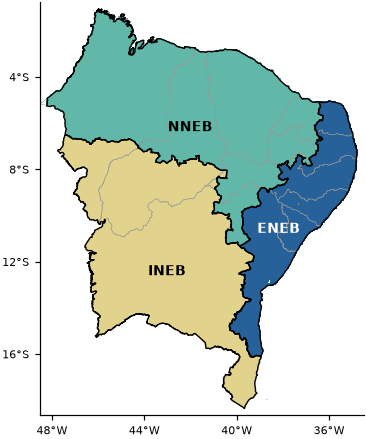

*Cores: pixels de 0,05° atribuídos a NNEB (norte), INEB (interior) e ENEB (leste); linhas pretas: limites dos alvos (união dos municípios); linhas cinza: estados. Arquivos: `resultados/completo/figuras/F01_mapa_alvos.png` e `.pdf` (84 × 101 mm).*

**Tabela 3. Ciclo anual e calendário das estações**

,alvo,mês,normal 1991–2020 (mm),normal 1981–2010 (mm),anomalia acumulada Q (mm),estação,classes desequilibradas na referência
0,NNEB,jan,157.0,153.0,60.0,chuvosa,False
1,NNEB,fev,178.0,172.0,140.0,chuvosa,False
2,NNEB,mar,234.0,250.0,297.0,chuvosa,False
3,NNEB,abr,202.0,214.0,418.0,chuvosa,False
4,NNEB,mai,104.0,104.0,428.0,chuvosa,False
5,NNEB,jun,38.0,40.0,375.0,seca,False
6,NNEB,jul,22.0,23.0,306.0,seca,False
7,NNEB,ago,8.0,10.0,222.0,seca,False
8,NNEB,set,8.0,9.0,139.0,seca,False
9,NNEB,out,20.0,21.0,67.0,seca,False


*Normal mensal de 1991–2020 (descritiva) e de 1981–2010 (referência); Q é a soma acumulada de (normal de referência do mês − média das 12 normais), que define o calendário. Classes desequilibradas: alguma classe se afasta mais de 5 p.p. de 20 % na referência (empates); N usa a frequência observada. NNEB: chuvosa jan a mai, seca jun a dez; INEB: chuvosa nov a abr, seca mai a out; ENEB: chuvosa mar a jul, seca ago a fev. Arquivo: `resultados/completo/tabelas/T03_calendario.csv`.*

**Figura 2. Normal mensal e calendário das estações**

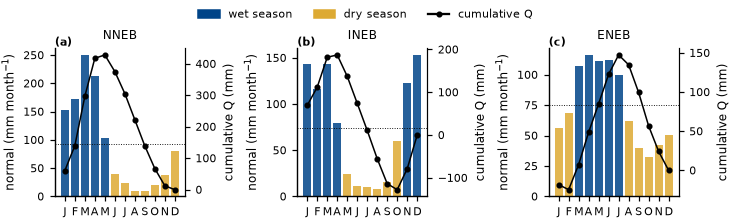

*Barras: normal de referência de cada mês, 1981–2010 (mm), coloridas pela estação; pontos: anomalia acumulada Q; linha pontilhada: média das 12 normais. A estação chuvosa vai do mês seguinte ao mínimo de Q até o máximo. Arquivos: `resultados/completo/figuras/F02_ciclo_anual.png` e `.pdf` (169 × 51 mm).*

**Tabela 4. Limites das classes de quintil da chuva regional**

,alvo,mês,estação,limite superior de Q1 (mm),Q1 inclui o limite,limite superior de Q2 (mm),Q2 inclui o limite,limite superior de Q3 (mm),Q3 inclui o limite,limite superior de Q4 (mm),Q4 inclui o limite,classes vazias,média de referência 1981–2010 (mm)
0,NNEB,jan,chuvosa,93.0,sim,132.0,sim,164.0,sim,182.0,sim,,153.0
1,NNEB,fev,chuvosa,125.0,sim,158.0,sim,172.0,sim,224.0,sim,,172.0
2,NNEB,mar,chuvosa,190.0,sim,238.0,sim,272.0,sim,299.0,sim,,250.0
3,NNEB,abr,chuvosa,124.0,sim,176.0,sim,220.0,sim,288.0,sim,,214.0
4,NNEB,mai,chuvosa,58.0,sim,81.0,sim,104.0,sim,150.0,sim,,104.0
5,NNEB,jun,seca,25.0,sim,31.0,sim,42.0,sim,51.0,sim,,40.0
6,NNEB,jul,seca,16.0,sim,18.0,sim,24.0,sim,27.0,sim,,23.0
7,NNEB,ago,seca,7.0,sim,8.0,sim,10.0,sim,12.0,sim,,10.0
8,NNEB,set,seca,6.0,sim,8.0,sim,10.0,sim,12.0,sim,,9.0
9,NNEB,out,seca,11.0,sim,18.0,sim,21.0,sim,26.0,sim,,21.0


*Limite superior de cada classe da chuva mensal do alvo inteiro, por mês do calendário (mm), pela mesma regra que classifica os meses: u é a posição da chuva entre os 30 valores do mesmo mês em 1981–2010 (empates pela metade), e o mês é Q1 se u < 0,2, Q2 se 0,2 ≤ u < 0,4, e assim por diante. "Inclui o limite" = sim: a classe vai até o limite inclusive (chuva ≤ limite) e a seguinte começa acima dele; não: a classe fica abaixo do limite (chuva < limite) e a seguinte começa nele, o que ocorre com empates no limite. Classe vazia: nenhuma chuva possível cai nela, por empates. Sem empates, os limites são o 6.º, o 12.º, o 18.º e o 24.º menor valor da referência, incluídos. A tabela reproduz a classe de todos os meses de 1981–2025 (conferido na execução) e passou num teste com 2000 referências sintéticas com empates. Arquivo: `resultados/completo/tabelas/T04_limites_quintis.csv`.*

**Tabela 5. Casos analisados: meses, defasagens e anos**

,alvo,caso,meses (ordem do ano hidrológico),defasagens (associação),defasagens (previsão),anos de treino,anos de teste
0,NNEB,ano hidrológico,"jan, fev, mar, abr, mai, jun, jul, ago, set, o...",L0 a L12,L1 a L12,1981–2010 (30),2011–2025 (15)
1,NNEB,estação chuvosa,"jan, fev, mar, abr, mai",L0 a L12,L1 a L12,1981–2010 (30),2011–2025 (15)
2,NNEB,estação seca,"jun, jul, ago, set, out, nov, dez",L0 a L12,L1 a L12,1981–2010 (30),2011–2025 (15)
3,INEB,ano hidrológico,"nov, dez, jan, fev, mar, abr, mai, jun, jul, a...",L0 a L12,L1 a L12,1981–2009 (29),2011–2024 (14)
4,INEB,estação chuvosa,"nov, dez, jan, fev, mar, abr",L0 a L12,L1 a L12,1981–2009 (29),2011–2024 (14)
5,INEB,estação seca,"mai, jun, jul, ago, set, out",L0 a L12,L1 a L12,1981–2009 (29),2011–2024 (14)
6,ENEB,ano hidrológico,"mar, abr, mai, jun, jul, ago, set, out, nov, d...",L0 a L12,L1 a L12,1981–2009 (29),2011–2024 (14)
7,ENEB,estação chuvosa,"mar, abr, mai, jun, jul",L0 a L12,L1 a L12,1981–2009 (29),2011–2024 (14)
8,ENEB,estação seca,"ago, set, out, nov, dez, jan, fev",L0 a L12,L1 a L12,1981–2009 (29),2011–2024 (14)


*O ano hidrológico começa no primeiro mês da estação chuvosa do alvo e é identificado pelo ano em que começa. Cada caso usa só os seus meses, no treino e no teste. Anos: anos hidrológicos completos. Arquivo: `resultados/completo/tabelas/T05_casos.csv`.*

**Tabela 6. Série mensal regional: chuva, quantil e classe**

,alvo,mês,ano hidrológico,estação,chuva (mm),normal do mês (mm),anomalia (mm),quantil u,classe
0,NNEB,1981-01,1981,chuvosa,140.0,157.0,-18.0,0.517,Q3 normal
1,NNEB,1981-02,1981,chuvosa,86.0,178.0,-92.0,0.050,Q1 muito seco
2,NNEB,1981-03,1981,chuvosa,283.0,234.0,50.0,0.750,Q4 chuvoso
3,NNEB,1981-04,1981,chuvosa,84.0,202.0,-117.0,0.050,Q1 muito seco
4,NNEB,1981-05,1981,chuvosa,60.0,104.0,-44.0,0.217,Q2 seco
5,NNEB,1981-06,1981,seca,18.0,38.0,-20.0,0.083,Q1 muito seco
6,NNEB,1981-07,1981,seca,15.0,22.0,-7.0,0.150,Q1 muito seco
7,NNEB,1981-08,1981,seca,8.0,8.0,-0.0,0.383,Q2 seco
8,NNEB,1981-09,1981,seca,7.0,8.0,-1.0,0.250,Q2 seco
9,NNEB,1981-10,1981,seca,21.0,20.0,1.0,0.550,Q3 normal


*Chuva regional (média dos pixels ponderada pela área), normal do mês (1991–2020, descritiva), anomalia, quantil u (posição da chuva do mês entre os 30 valores do mesmo mês em 1981–2010, empates pela metade) e classe de quintil. Mostradas 12 de 1620 linhas. Arquivo: `resultados/completo/tabelas/T06_serie_mensal.csv`.*

**Figura 3. Quantil mensal da chuva regional, 1981–2025**

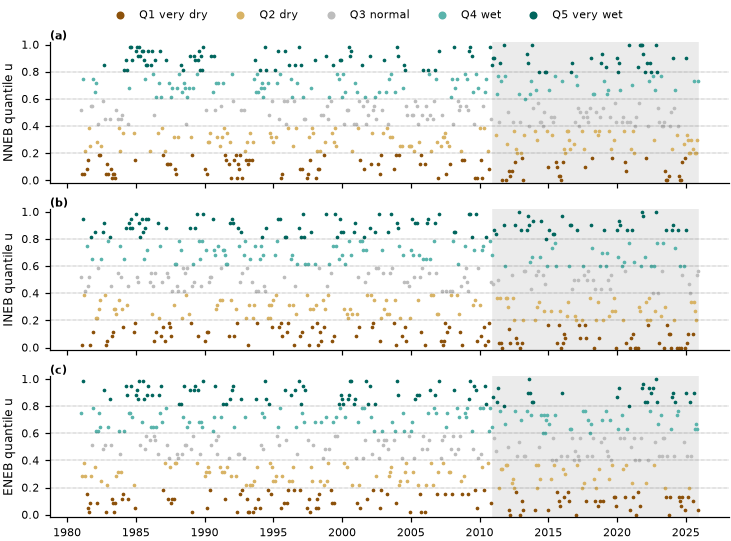

*Pontos: quantil u de cada mês em relação aos 30 valores do mesmo mês em 1981–2010, coloridos pela classe de quintil (marrom: muito seco; verde-azulado: muito chuvoso). Linhas pontilhadas: limites q20, q40, q60 e q80. Fundo cinza: período de teste. Arquivos: `resultados/completo/figuras/F03_serie_mensal_u.png` e `.pdf` (169 × 125 mm).*

**Tabela 7. Índices oceânicos padronizados**

,índice,início,fim,média 1991–2020 (unid. orig.),1 dp (unid. orig.),autocorrelação 3 meses,autocorrelação 6 meses,variação pela tendência em 1981–2025 (dp),IC95 inferior,IC95 superior
0,NINO3.4,1979-01,2025-12,0.110,0.75,0.789,0.455,0.19,-0.13,0.50
1,TSA,1979-01,2025-12,-0.000,0.33,0.607,0.338,1.40,1.12,1.68
2,AMM,1979-01,2025-12,0.559,2.69,0.489,0.134,1.19,0.89,1.47


*Padronização pela média e pelo desvio-padrão (dp) de 1991–2020. Unidades originais: °C para NINO3.4 e TSA. Variação pela tendência: inclinação de Theil-Sen da série mensal de 1981–2025 multiplicada pelo número de meses do período; descritiva. Arquivo: `resultados/completo/tabelas/T07_indices.csv`.*

**Figura 4. Séries dos índices oceânicos padronizados**

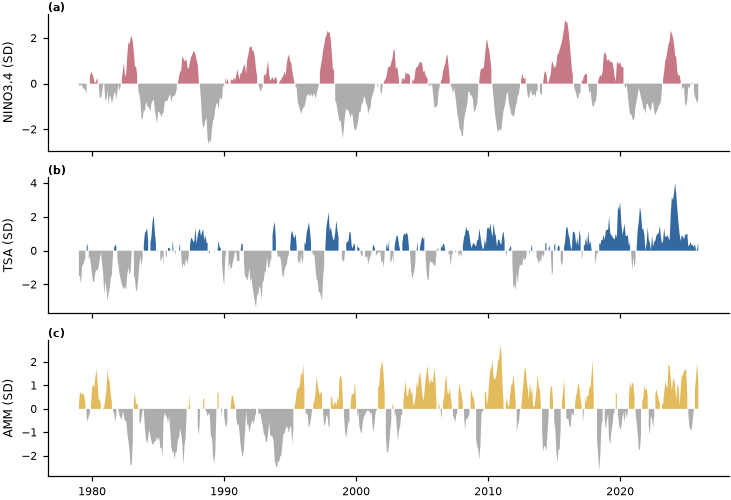

*Índices mensais em desvios-padrão de 1991–2020; cor: valores positivos; cinza: negativos. Arquivos: `resultados/completo/figuras/F04_series_indices.png` e `.pdf` (169 × 115 mm).*

**Tabela 8. Normal mensal média por estação nas células**

,alvo,estação,média ponderada (mm/mês),P10 das células (mm/mês),P90 das células (mm/mês)
0,NNEB,chuvosa,175.0,90.8,290.0
1,NNEB,seca,30.0,11.8,54.0
2,INEB,chuvosa,124.0,76.7,180.0
3,INEB,seca,20.0,7.1,35.0
4,ENEB,chuvosa,103.0,50.3,176.0
5,ENEB,seca,49.0,26.5,84.0


*Média das normais mensais (1991–2020) dos meses de cada estação, calculada em cada célula com o calendário do seu alvo. Arquivo: `resultados/completo/tabelas/T08_normal_estacao.csv`.*

**Figura 5. Normal mensal média nas estações chuvosa e seca**

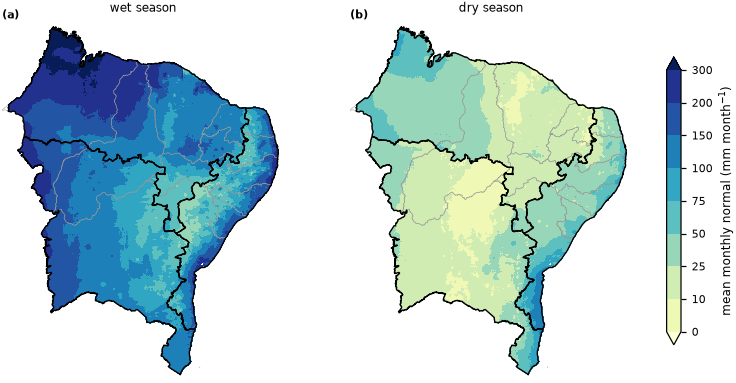

*Média das normais mensais de 1991–2020 dos meses da estação chuvosa (a) e da seca (b) de cada alvo, por pixel de 0,05° (mm/mês). Arquivos: `resultados/completo/figuras/F05_mapas_normal_estacao.png` e `.pdf` (170 × 89 mm).*

**Tabela 9. Sanidade do CHIRPS: homogeneidade e empates**

,alvo,pixels,"útil, 0–1 testes (% da área)","duvidoso, 2 testes (% da área)","suspeito, 3–4 testes, marcado (% da área)",área com ao menos 1 mês desequilibrado (%)
0,NNEB,22127,93.6,2.50,3.9,0.000
1,INEB,21179,96.9,1.46,1.7,0.058
2,ENEB,8717,85.5,4.48,10.0,0.000


*Homogeneidade relativa (Wijngaard et al., 2003): série anual de 1981 a 2025 da razão entre a chuva do pixel e a do seu alvo, que cancela variações regionais reais; SNHT (Alexandersson, 1986), Buishand (1982), Pettitt (1979) e von Neumann (1941), a 1 %, com valores críticos por simulação de séries sem quebra (SNHT 10.92, Buishand 1.76, Pettitt 264.00, von Neumann 1.34). Suspeito: 3 ou 4 testes rejeitam; é mantido nas análises e não é marcado nos mapas (localização em registros/pixels_suspeitos.csv), porque uma mudança estatística também pode ser clima real. Mês desequilibrado: alguma classe se afasta mais de 5 p.p. de 20 % na referência, em geral por empates de meses quase sem chuva. Arquivo: `resultados/completo/tabelas/T09_sanidade_homogeneidade.csv`.*

**Figura 6. Sanidade do CHIRPS antes das aferições**

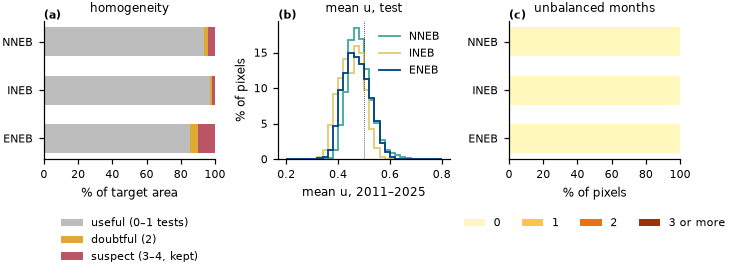

*(a) Fração da área de cada alvo por número de testes de homogeneidade que rejeitam: útil (0–1), duvidoso (2) e suspeito (3–4). Os pixels suspeitos são mantidos nas análises; a figura não os mapeia, para que uma triagem estatística não pese visualmente mais do que os resultados, e a localização de cada um está em `resultados/completo/registros/pixels_suspeitos.csv`. (b) Distribuição, entre os pixels de cada alvo, do quantil médio de 2011–2025 em relação a 1981–2010: perto de 0,5 sem mudança no dado; caudas largas indicariam setores mais secos ou mais chuvosos depois de 2010, por mudança no produto ou variação local real, que a figura não distingue. (c) Fração dos pixels por número de meses do calendário com classes desequilibradas na referência (empates); nesses meses N usa a frequência observada. Arquivos: `resultados/completo/figuras/F06_sanidade.png` e `.pdf` (168 × 65 mm).*

**Tabela 10. Verificações de qualidade**

,verificação,resultado,detalhe
0,eixo mensal regular,ok,"540 meses, 1981-01 a 2025-12"
1,meses completos na referência e na normal,ok,referência 360 meses; normal 360 meses
2,chuva não negativa,ok,mínimo 0.00 mm
3,índices sem falhas,ok,1979-01 a 2025-12
4,alinhamento índice × chuva,ok,índice[24] = 1981-01; chuva[0] = 1981-01
5,NNEB: calendário (referência 1981–2010) igual ...,ok,"calculado: jan, fev, mar, abr, mai; fixado: ja..."
6,NNEB: calendário da normal 1991–2020 igual,ok,"jan, fev, mar, abr, mai"
7,NNEB: pixels atribuídos,ok,"22127 pixels de 0,05°; suspeitos de quebra (ma..."
8,NNEB: cobertura da área do polígono,ok,1.0000
9,NNEB: anos de treino e de teste,ok,treino 30 anos; teste 15 anos


*Uma verificação essencial que falhe interrompe a execução. Mostradas 25 de 29 linhas. Arquivo: `resultados/completo/tabelas/T10_verificacoes.csv`.*

#### Síntese numérica

- NNEB: estação chuvosa jan a mai e seca jun a dez; 22127 pixels; 30 anos hidrológicos de treino e 15 de teste.
- INEB: estação chuvosa nov a abr e seca mai a out; 21179 pixels; 29 anos hidrológicos de treino e 14 de teste.
- ENEB: estação chuvosa mar a jul e seca ago a fev; 8717 pixels; 29 anos hidrológicos de treino e 14 de teste.
- NNEB: em 1981–2010, cada classe de quintil reúne entre 20 % e 20 % dos meses de cada mês do calendário.
- INEB: em 1981–2010, cada classe de quintil reúne entre 20 % e 20 % dos meses de cada mês do calendário.
- ENEB: em 1981–2010, cada classe de quintil reúne entre 20 % e 20 % dos meses de cada mês do calendário.
- NNEB: 3,9 % da área suspeita de quebra no CHIRPS (mantida; lista em registros/pixels_suspeitos.csv) e 2,5 % duvidosa; 0 % da área tem ao menos 1 mês com classes desequilibradas.
- INEB: 1,7 % da área suspeita de quebra no CHIRPS (mantida; lista em registros/pixels_suspeitos.csv) e 1,5 % duvidosa; 0 % da área tem ao menos 1 mês com classes desequilibradas.
- ENEB: 10,0 % da área suspeita de quebra no CHIRPS (mantida; lista em registros/pixels_suspeitos.csv) e 4,5 % duvidosa; 0 % da área tem ao menos 1 mês com classes desequilibradas.
- NINO3.4: variação pela tendência de Theil-Sen em 1981–2025 de +0,19 dp (IC95 −0,13 a +0,50).
- TSA: variação pela tendência de Theil-Sen em 1981–2025 de +1,40 dp (IC95 +1,12 a +1,68).
- AMM: variação pela tendência de Theil-Sen em 1981–2025 de +1,19 dp (IC95 +0,89 a +1,47).

### Relatório parcial 3 · 30/10/2026 19:39 · fim da Seção 1

Modo completo. Tempo decorrido: 1 min. Término geral previsto: 31/10/2026 15:08.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | aguardando | 0 / 9 | 0 min | 1 min (a priori) | 30/10 19:40 |
| Seção 3 | aguardando | 0 / 9 | 0 min | 4 min (a priori) | 30/10 19:44 |
| Seção 4 | aguardando | 0 / 259 | 0 min | 2 h 53 min (a priori) | 30/10 22:37 |
| Seção 5 | aguardando | 0 / 9 | 0 min | 0 min (a priori) | 30/10 22:37 |
| Seção 6 | aguardando | 0 / 54 | 0 min | 1 min (a priori) | 30/10 22:38 |
| Seção 7 | aguardando | 0 / 54 | 0 min | 2 min (a priori) | 30/10 22:40 |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 22:47 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 31/10 02:25 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 15:07 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 15:08 |

Últimos registros:
- 2026-10-30T22:39:13+00:00 | Seção 1: iniciada (1 unidades de trabalho).
- 2026-10-30T22:39:22+00:00 | Seção 1: homogeneidade, referência, quantis, classes e índices calculados.
- 2026-10-30T22:39:36+00:00 | Seção 1: concluída em 0 min.



In [6]:
# =============================================================================
# 1.3 Tabelas, figuras e síntese numérica da Seção 1. Lê apenas o que 1.2 calculou. Define os
# auxiliares de mapa usados nas seções seguintes.
# =============================================================================
from matplotlib.colors import BoundaryNorm, ListedColormap, to_rgb
from matplotlib.patches import Patch


def contornos(geometria, pixels_min=4):
    """Coordenadas (x, y) das linhas de contorno de um polígono ou multipolígono. Partes e
    buracos com área menor que `pixels_min` pixels de 0,05° (ilhas, recortes de divisa) não são
    desenhados: na escala do mapa virariam pontos pretos sem informação."""
    import shapely
    area_min = pixels_min * G.res ** 2
    partes = geometria.geoms if hasattr(geometria, 'geoms') else [geometria]
    linhas = []
    for p in partes:
        if p.area < area_min:
            continue
        linhas.append(np.asarray(p.exterior.coords))
        linhas += [np.asarray(r.coords) for r in p.interiors
                   if shapely.Polygon(r).area >= area_min]
    return linhas


CONTORNO = {a: contornos(GEOMETRIAS[a]) for a in ALVOS}
EXTENSAO = (G.lon[0] - G.res / 2, G.lon[-1] + G.res / 2, G.lat[0] - G.res / 2,
            G.lat[-1] + G.res / 2)
_b = np.array([GEOMETRIAS[a].bounds for a in ALVOS])
LIM_LON = (float(_b[:, 0].min()) - 0.3, float(_b[:, 2].max()) + 0.3)
LIM_LAT = (float(_b[:, 1].min()) - 0.3, float(_b[:, 3].max()) + 0.3)


def desenhar_alvos(ax, destaque=None):
    """Contorno dos alvos (linha preta) e dos estados (cinza); destaque: alvos em linha
    contínua grossa, os demais em linha tracejada fina."""
    UFS.boundary.plot(ax=ax, color='0.6', linewidth=0.3)
    for alvo in ALVOS:
        forte = destaque is None or alvo in destaque
        for c in CONTORNO[alvo]:
            ax.plot(c[:, 0], c[:, 1], color='k', lw=0.9 if forte else 0.5,
                    ls='-' if forte else '--', zorder=3)
    ax.set(xlim=LIM_LON, ylim=LIM_LAT)


def mapa_celulas(ax, campo, cmap, limites, destaque=None):
    """Campo por pixel de 0,05° em classes discretas; pixels fora dos alvos ficam em branco.
    Os pixels suspeitos de quebra no CHIRPS não são marcados (lista em registros)."""
    norma = BoundaryNorm(limites, plt.get_cmap(cmap).N, extend='both')
    im = ax.imshow(np.where(DONO >= 0, campo, np.nan), origin='lower', extent=EXTENSAO,
                   cmap=cmap, norm=norma, interpolation='nearest')
    desenhar_alvos(ax, destaque)
    formatar_mapa(ax, rotulos=False)
    return im


def limites_simetricos(campo, passos=6, maximo=None):
    """Limites de classe simétricos em torno de zero, com passo redondo (1, 2, 2,5 ou 5 vezes
    uma potência de 10) que cobre o percentil 98 do módulo."""
    v = maximo if maximo is not None else np.nanpercentile(np.abs(campo), 98)
    v = float(v) if np.isfinite(v) and v > 0 else 1.0
    bruto = v / passos
    escala = 10.0 ** np.floor(np.log10(bruto))
    passo = escala * min(m for m in (1, 2, 2.5, 5, 10) if m * escala >= bruto * (1 - 1e-9))
    return np.arange(-passos, passos + 1) * passo


# ----- alvos -----
linhas = []
for alvo in ALVOS:
    linhas.append({'alvo': alvo, 'municípios': len(CODIGOS_MUNICIPAIS[alvo]),
                   'pixels de 0,05°': len(PESO[alvo]),
                   'área coberta (km²)': float(PESO[alvo].sum()),
                   'normal média dos meses chuvosos (mm/mês)':
                       float(C_REG[alvo][np.array(CAL[alvo]['chuvosa']) - 1].mean()),
                   'normal média dos meses secos (mm/mês)':
                       float(C_REG[alvo][np.array(CAL[alvo]['seca']) - 1].mean())})
tabela(pd.DataFrame(linhas), 'alvos', 'Alvos, células e normal mensal média por estação',
       f'{NOTA_TERRITORIAL} Cada pixel de 0,05° pertence ao alvo de maior área de interseção. '
       f'Normal: médias mensais de 1991–2020 (descritiva). Pixels suspeitos de quebra no CHIRPS '
       f'(homogeneidade, abaixo) são mantidos nas análises e não são marcados nos mapas; a fração da área está na figura de sanidade e a localização em `registros/pixels_suspeitos.csv`. Pixels de 0,05° sem todos '
       f'os meses, excluídos '
       f'antes da agregação: {G.pixels_removidos}.')
fig, ax = plt.subplots(figsize=(4.5, 4.5))
cores = ListedColormap([COR[a] for a in ALVOS])
ax.imshow(np.where(DONO >= 0, DONO, np.nan), origin='lower', extent=EXTENSAO, cmap=cores,
          vmin=-0.5, vmax=len(ALVOS) - 0.5, interpolation='nearest', alpha=0.85)
desenhar_alvos(ax)
for alvo in ALVOS:
    c = GEOMETRIAS[alvo].representative_point()
    ax.text(c.x, c.y, alvo, ha='center', va='center', fontsize=9, weight='bold',
            color='w' if alvo == 'ENEB' else 'k')
formatar_mapa(ax)
figura(fig, 'mapa_alvos', 'Alvos e pixels de 0,05°',
       'Cores: pixels de 0,05° atribuídos a NNEB (norte), INEB (interior) e ENEB (leste); linhas '
       'pretas: limites dos alvos (união dos municípios); linhas cinza: estados.',
       dpi=CFG['figuras']['dpi_mapas'])

# ----- ciclo anual e calendário -----
linhas = []
for alvo in ALVOS:
    for m in range(1, 13):
        linhas.append({'alvo': alvo, 'mês': MESES[m - 1],
                       'normal 1991–2020 (mm)': C_REG[alvo][m - 1],
                       'normal 1981–2010 (mm)': C81_REG[alvo][m - 1],
                       'anomalia acumulada Q (mm)': Q_REG[alvo][m - 1],
                       'estação': ESTACAO_MES[alvo][m - 1],
                       'classes desequilibradas na referência': bool(DESEQ_REG[alvo][m - 1])})
tabela(pd.DataFrame(linhas), 'calendario', 'Ciclo anual e calendário das estações',
       'Normal mensal de 1991–2020 (descritiva) e de 1981–2010 (referência); Q é a soma '
       'acumulada de (normal de referência do mês − média das 12 normais), que define o '
       'calendário. Classes desequilibradas: alguma classe se afasta mais de '
       f'{100 * DESEQ:.0f} p.p. de 20 % na referência (empates); N usa a frequência observada. '
       + '; '.join(
           f"{a}: chuvosa {nome_meses(CAL[a]['chuvosa'])}, seca {nome_meses(CAL[a]['seca'])}"
           for a in ALVOS) + '.', n=36)
fig, axs = plt.subplots(1, len(ALVOS), figsize=(2.6 * len(ALVOS), 2.4), squeeze=False)
for ax, alvo in zip(axs[0], ALVOS):
    ax.bar(range(1, 13), C81_REG[alvo], color=[COR[e] for e in ESTACAO_MES[alvo]], alpha=0.85)
    ax.axhline(C81_REG[alvo].mean(), color='k', lw=0.6, ls=':')
    ax2 = ax.twinx()
    ax2.plot(range(1, 13), Q_REG[alvo], color='k', marker='o', ms=3, lw=1)
    ax2.spines['right'].set_visible(True)
    ax2.set_ylabel('cumulative Q (mm)')
    ax.set(xticks=range(1, 13), xticklabels=[m[0] for m in MONTHS], title=alvo,
           ylabel='normal (mm month$^{-1}$)')
fig.legend(handles=[Patch(color=COR['chuvosa'], label='wet season'),
                    Patch(color=COR['seca'], label='dry season'),
                    plt.Line2D([], [], color='k', marker='o', ms=3, label='cumulative Q')],
           loc='outside upper center', ncol=3)
figura(fig, 'ciclo_anual', 'Normal mensal e calendário das estações',
       'Barras: normal de referência de cada mês, 1981–2010 (mm), coloridas pela estação; '
       'pontos: anomalia '
       'acumulada Q; linha pontilhada: média das 12 normais. A estação chuvosa vai do mês '
       'seguinte ao mínimo de Q até o máximo.')

# ----- limites dos quintis -----
linhas = []
for alvo in ALVOS:
    for m in range(1, 13):
        fr = FRONTEIRAS[alvo][m - 1]
        linhas.append({'alvo': alvo, 'mês': MESES[m - 1], 'estação': ESTACAO_MES[alvo][m - 1],
                       **{c: v for k in range(len(LIMITES_Q)) for c, v in (
                           (f'limite superior de {CLASSES[k][:2]} (mm)', fr[k][0]),
                           (f'{CLASSES[k][:2]} inclui o limite', 'sim' if fr[k][1] else 'não'))},
                       'classes vazias': ', '.join(CLASSES[k][:2] for k in classes_vazias(fr)),
                       'média de referência 1981–2010 (mm)': C81_REG[alvo][m - 1]})
tabela(pd.DataFrame(linhas), 'limites_quintis', 'Limites das classes de quintil da chuva regional',
       'Limite superior de cada classe da chuva mensal do alvo inteiro, por mês do calendário '
       '(mm), pela mesma regra que classifica os meses: u é a posição da chuva entre os 30 '
       'valores do mesmo mês em 1981–2010 (empates pela metade), e o mês é Q1 se u < 0,2, Q2 se '
       '0,2 ≤ u < 0,4, e assim por diante. "Inclui o limite" = sim: a classe vai até o limite '
       'inclusive (chuva ≤ limite) e a seguinte começa acima dele; não: a classe fica abaixo do '
       'limite (chuva < limite) e a seguinte começa nele, o que ocorre com empates no limite. '
       'Classe vazia: nenhuma chuva possível cai nela, por empates. Sem empates, os limites são '
       'o 6.º, o 12.º, o 18.º e o 24.º menor valor da referência, incluídos. A tabela reproduz a '
       f"classe de todos os meses de 1981–2025 (conferido na execução) e passou num teste com "
       f"{TESTE_FRONTEIRAS['casos']} referências sintéticas com empates.", n=36)

# ----- casos -----
linhas = []
for alvo, caso in itertools.product(ALVOS, CASOS):
    linhas.append({'alvo': alvo, 'caso': ROTULO_CASO[caso],
                   'meses (ordem do ano hidrológico)': ', '.join(
                       MESES[m - 1] for m in MESES_CASO[alvo][caso]),
                   'defasagens (associação)': f'L0 a L{LMAX[(alvo, caso)]}',
                   'defasagens (previsão)': f'L1 a L{LMAX[(alvo, caso)]}',
                   'anos de treino': f"{ANOS[alvo]['treino'][0]}–{ANOS[alvo]['treino'][-1]} "
                                     f"({len(ANOS[alvo]['treino'])})",
                   'anos de teste': f"{ANOS[alvo]['teste'][0]}–{ANOS[alvo]['teste'][-1]} "
                                    f"({len(ANOS[alvo]['teste'])})"})
tabela(pd.DataFrame(linhas), 'casos', 'Casos analisados: meses, defasagens e anos',
       'O ano hidrológico começa no primeiro mês da estação chuvosa do alvo e é identificado '
       'pelo ano em que começa. Cada caso usa só os seus meses, no treino e no teste. Anos: '
       'anos hidrológicos completos.')

# ----- série mensal regional -----
linhas = []
for alvo in ALVOS:
    for t in range(T_MESES):
        linhas.append({'alvo': alvo, 'mês': f'{G.tempos[t]:%Y-%m}',
                       'ano hidrológico': int(ANO_HIDRO[alvo][t]),
                       'estação': ESTACAO_MES[alvo][G.mes[t] - 1], 'chuva (mm)': P_REG[alvo][t],
                       'normal do mês (mm)': C_REG[alvo][G.mes[t] - 1],
                       'anomalia (mm)': A_REG[alvo][t], 'quantil u': U_REG[alvo][t],
                       'classe': CLASSES[CL_REG[alvo][t]]})
tabela(pd.DataFrame(linhas), 'serie_mensal', 'Série mensal regional: chuva, quantil e classe',
       'Chuva regional (média dos pixels ponderada pela área), normal do mês (1991–2020, '
       'descritiva), '
       'anomalia, quantil u (posição da chuva do mês entre os 30 valores do mesmo mês em '
       '1981–2010, empates pela metade) e classe de quintil.', n=12)
fig, axs = plt.subplots(len(ALVOS), 1, figsize=(7.0, 1.6 * len(ALVOS) + 0.4), sharex=True)
for ax, alvo in zip(np.atleast_1d(axs), ALVOS):
    for k in range(K_CLASSES):
        sel = CL_REG[alvo] == k
        ax.scatter(G.tempos[sel], U_REG[alvo][sel], s=2, color=COR_CLASSE[k],
                   label=CLASSES_EN[k])
    for q in LIMITES_Q:
        ax.axhline(q, color='k', lw=0.3, ls=':')
    ax.axvspan(pd.Timestamp(f"{CFG['particao']['teste'][0]}-01-01"), G.tempos[-1],
               color='0.92', zorder=0)
    ax.set(ylabel=f'{alvo} quantile u', ylim=(-0.02, 1.02))
fig.legend(*np.atleast_1d(axs)[0].get_legend_handles_labels(), loc='outside upper center',
           ncol=5, markerscale=3)
figura(fig, 'serie_mensal_u', 'Quantil mensal da chuva regional, 1981–2025',
       'Pontos: quantil u de cada mês em relação aos 30 valores do mesmo mês em 1981–2010, '
       'coloridos pela classe de quintil (marrom: muito seco; verde-azulado: muito chuvoso). '
       'Linhas pontilhadas: limites q20, q40, q60 e q80. Fundo cinza: período de teste.')

# ----- índices -----
linhas = []
for k, nome in enumerate(INDICES):
    z = pd.Series(Z_IDX[:, k])
    inc, inf, sup = TENDENCIA_IDX[nome]
    linhas.append({'índice': nome, 'início': f'{DATAS_IDX[0]:%Y-%m}',
                   'fim': f'{DATAS_IDX[-1]:%Y-%m}',
                   'média 1991–2020 (unid. orig.)': MEDIA_IDX[nome],
                   '1 dp (unid. orig.)': DP_IDX[nome],
                   'autocorrelação 3 meses': z.autocorr(3), 'autocorrelação 6 meses': z.autocorr(6),
                   'variação pela tendência em 1981–2025 (dp)': inc, 'IC95 inferior': inf,
                   'IC95 superior': sup})
tabela(pd.DataFrame(linhas), 'indices', 'Índices oceânicos padronizados',
       'Padronização pela média e pelo desvio-padrão (dp) de 1991–2020. Unidades originais: °C '
       'para NINO3.4 e TSA. Variação pela tendência: inclinação de Theil-Sen da série mensal '
       'de 1981–2025 multiplicada pelo número de meses do período; descritiva.')
fig, axs = plt.subplots(3, 1, figsize=(7.0, 4.8), sharex=True)
for ax, (k, nome) in zip(axs, enumerate(INDICES)):
    z = Z_IDX[:, k]
    ax.fill_between(DATAS_IDX, 0, z, where=z >= 0, color=COR[nome], alpha=0.8, lw=0)
    ax.fill_between(DATAS_IDX, 0, z, where=z < 0, color='0.6', alpha=0.8, lw=0)
    ax.set(ylabel=f'{nome} (SD)')
figura(fig, 'series_indices', 'Séries dos índices oceânicos padronizados',
       'Índices mensais em desvios-padrão de 1991–2020; cor: valores positivos; cinza: negativos.')

# ----- normal mensal média por estação, por célula -----
linhas = []
for alvo in ALVOS:
    sel = DONO == ALVOS.index(alvo)
    for e in ('chuvosa', 'seca'):
        v = NORMAL_ESTACAO[e][sel]
        linhas.append({'alvo': alvo, 'estação': e,
                       'média ponderada (mm/mês)': float(np.average(v, weights=G.area[alvo][sel])),
                       'P10 das células (mm/mês)': float(np.percentile(v, 10)),
                       'P90 das células (mm/mês)': float(np.percentile(v, 90))})
tabela(pd.DataFrame(linhas), 'normal_estacao', 'Normal mensal média por estação nas células',
       'Média das normais mensais (1991–2020) dos meses de cada estação, calculada em cada célula '
       'com o calendário do seu alvo.')
fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.4))
limites = np.array([0, 10, 25, 50, 75, 100, 150, 200, 300])
for ax, e in zip(axs, ('chuvosa', 'seca')):
    im = mapa_celulas(ax, NORMAL_ESTACAO[e], 'YlGnBu', limites)
    ax.set_title(EN[e])
fig.colorbar(im, ax=axs, shrink=0.8, label='mean monthly normal (mm month$^{-1}$)')
figura(fig, 'mapas_normal_estacao', 'Normal mensal média nas estações chuvosa e seca',
       'Média das normais mensais de 1991–2020 dos meses da estação chuvosa (a) e da seca (b) de '
       'cada alvo, por pixel de 0,05° (mm/mês).', dpi=CFG['figuras']['dpi_mapas'])

# ----- sanidade antes das aferições: homogeneidade, quantil médio do teste, meses secos -----
linhas = []
for k, alvo in enumerate(ALVOS):
    sel = DONO_ORIGINAL == k
    w, h = G.area[alvo][sel], HOMOG[sel]
    linhas.append({'alvo': alvo, 'pixels': int(sel.sum()),
                   'útil, 0–1 testes (% da área)': 100 * w[h <= 1].sum() / w.sum(),
                   'duvidoso, 2 testes (% da área)': 100 * w[h == 2].sum() / w.sum(),
                   'suspeito, 3–4 testes, marcado (% da área)': 100 * w[h >= 3].sum() / w.sum(),
                   'área com ao menos 1 mês desequilibrado (%)':
                       100 * w[MESES_DESEQ[sel] > 0].sum() / w.sum()})
HOMOG_TAB = pd.DataFrame(linhas)
tabela(HOMOG_TAB, 'sanidade_homogeneidade', 'Sanidade do CHIRPS: homogeneidade e empates',
       'Homogeneidade relativa (Wijngaard et al., 2003): série anual de 1981 a 2025 da razão '
       'entre a chuva do pixel e a do seu alvo, que cancela variações regionais reais; SNHT '
       '(Alexandersson, 1986), Buishand (1982), Pettitt (1979) e von Neumann (1941), a 1 %, com '
       'valores críticos por simulação de séries sem quebra (' + ', '.join(
           f'{k} {v:.2f}' for k, v in CRIT_HOMOG.items()) + '). Suspeito: 3 ou 4 testes rejeitam; '
       'é mantido nas análises e não é marcado nos mapas (localização em registros/pixels_suspeitos.csv), porque uma mudança estatística também pode ser clima '
       'real. Mês desequilibrado: alguma classe se afasta mais de '
       f'{100 * DESEQ:.0f} p.p. de 20 % na referência, em geral por empates de meses quase sem '
       'chuva.')
# lista dos pixels suspeitos (documentação; os mapas não os marcam)
_iy, _ix = np.nonzero(SUSPEITO)
pd.DataFrame({'alvo': [ALVOS[k] for k in DONO_ORIGINAL[_iy, _ix]],
              'longitude': np.round(G.lon[_ix], 3), 'latitude': np.round(G.lat[_iy], 3),
              'testes que rejeitam': HOMOG[_iy, _ix].astype(int)}).to_csv(
    PASTAS['registros'] / 'pixels_suspeitos.csv', index=False, encoding='utf-8-sig')

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.6), squeeze=False)
_y = np.arange(len(ALVOS))
_classes = [('útil, 0–1 testes (% da área)', '#bdbdbd', 'useful (0–1 tests)'),
            ('duvidoso, 2 testes (% da área)', '#DDAA33', 'doubtful (2)'),
            ('suspeito, 3–4 testes, marcado (% da área)', '#BB5566', 'suspect (3–4, kept)')]
_esq = np.zeros(len(ALVOS))
for coluna, cor, rotulo in _classes:
    v = HOMOG_TAB[coluna].to_numpy()
    axs[0, 0].barh(_y, v, left=_esq, color=cor, label=rotulo, height=0.6)
    _esq += v
axs[0, 0].set(yticks=_y, yticklabels=ALVOS, xlim=(0, 100), xlabel='% of target area',
              title='homogeneity')
axs[0, 0].invert_yaxis()
axs[0, 0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.35), fontsize=7, frameon=False)
_bordas = np.arange(0.20, 0.8001, 0.02)
for k, alvo in enumerate(ALVOS):
    sel = (DONO_ORIGINAL == k) & np.isfinite(U_TESTE_MEDIO)
    dens, _ = np.histogram(np.clip(U_TESTE_MEDIO[sel], 0.2, 0.8), _bordas)
    axs[0, 1].stairs(100 * dens / dens.sum(), _bordas, color=COR[alvo], lw=1.2, label=alvo)
axs[0, 1].axvline(0.5, color='k', lw=0.5, ls=':')
axs[0, 1].set(xlabel='mean u, 2011–2025', ylabel='% of pixels', title='mean u, test')
axs[0, 1].legend(fontsize=7, frameon=False)
_meses = [(0, '0'), (1, '1'), (2, '2'), (3, '3 or more')]
_esq = np.zeros(len(ALVOS))
_tons = ['#fff7bc', '#fec44f', '#ec7014', '#993404']
for (m, rotulo), cor in zip(_meses, _tons):
    v = []
    for k, alvo in enumerate(ALVOS):
        sel = DONO_ORIGINAL == k
        n = MESES_DESEQ[sel]
        v.append(100 * np.mean(n >= m) if m == 3 else 100 * np.mean(n == m))
    axs[0, 2].barh(_y, v, left=_esq, color=cor, label=rotulo, height=0.6)
    _esq += np.array(v)
axs[0, 2].set(yticks=_y, yticklabels=ALVOS, xlim=(0, 100), xlabel='% of pixels',
              title='unbalanced months')
axs[0, 2].invert_yaxis()
axs[0, 2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=4, fontsize=7,
                 frameon=False)
figura(fig, 'sanidade', 'Sanidade do CHIRPS antes das aferições',
       '(a) Fração da área de cada alvo por número de testes de homogeneidade que rejeitam: '
       'útil (0–1), duvidoso (2) e suspeito (3–4). Os pixels suspeitos são mantidos nas análises; '
       'a figura não os mapeia, para que uma triagem estatística não pese visualmente mais do '
       'que os resultados, e a localização de cada um está em '
       f'`resultados/{MODO}/registros/pixels_suspeitos.csv`. (b) Distribuição, entre os pixels '
       'de cada alvo, do quantil médio de 2011–2025 em relação a 1981–2010: perto de 0,5 sem '
       'mudança no dado; caudas largas indicariam setores mais secos ou mais chuvosos depois de '
       '2010, por mudança no produto ou variação local real, que a figura não distingue. (c) '
       'Fração dos pixels por número de meses do calendário com classes desequilibradas na '
       'referência (empates); nesses meses N usa a frequência observada.',
       dpi=CFG['figuras']['dpi'])

tabela(pd.DataFrame(VERIFICACOES), 'verificacoes', 'Verificações de qualidade',
       'Uma verificação essencial que falhe interrompe a execução.')

linhas = [f"{a}: estação chuvosa {nome_meses(CAL[a]['chuvosa'])} e seca "
          f"{nome_meses(CAL[a]['seca'])}; {len(PESO[a])} pixels; "
          f"{len(ANOS[a]['treino'])} anos hidrológicos de treino e {len(ANOS[a]['teste'])} "
          'de teste.' for a in ALVOS]
linhas += [f'{a}: em 1981–2010, cada classe de quintil reúne entre '
           f'{100 * FREQ_REG[a].min():.0f} % e {100 * FREQ_REG[a].max():.0f} % dos meses de cada '
           'mês do calendário.' for a in ALVOS]
linhas += [f"{r['alvo']}: {r['suspeito, 3–4 testes, marcado (% da área)']:.1f} % da área "
           "suspeita de quebra no CHIRPS (mantida; lista em registros/pixels_suspeitos.csv) e "
           f"{r['duvidoso, 2 testes (% da área)']:.1f} % duvidosa; "
           f"{r['área com ao menos 1 mês desequilibrado (%)']:.0f} % da área tem ao menos 1 mês "
           "com classes desequilibradas."
           for _, r in HOMOG_TAB.iterrows()]
linhas += [f'{n}: variação pela tendência de Theil-Sen em 1981–2025 de '
           f'{TENDENCIA_IDX[n][0]:+.2f} dp (IC95 {TENDENCIA_IDX[n][1]:+.2f} a '
           f'{TENDENCIA_IDX[n][2]:+.2f}).' for n in INDICES]
sintese(linhas)
PROGRESSO.concluir('Seção 1')

### 1.4 Results and discussion

The targets table and the map show the pixels assigned to each target. The calendar table checks the calendar computed from the reference against the one fixed on the cover; the run continues only if the two match. The class limits in millimetres, obtained with the same rule that classifies the months, place the classes in the rainfall of each month; the class check confirms that each class holds about 20% of the months of 1981–2010. The sanity figure should be read before Sections 2 to 10: suspect pixels have a statistical change in the pixel/target ratio, which may come from changes in the product's gauge network or from real local variation; the test does not tell the two apart. These pixels are neither excluded nor marked on the maps: the figure shows the area fraction, and the location of each is in `registros/pixels_suspeitos.csv`, for anyone who wants to check whether a patch on a result map coincides with them. The distribution of the mean test-period quantile shows whether there are drier or wetter pixels after 2010, without identifying the cause, and that of ties shows how much of the area has months in which climatology N is no longer exactly 20% per class.

### 1.5 Conclusion

The section delivers the reference, the quantile and the class of each month in each pixel and target, the calendar, the months and maximum lag of each case, the list of pixels flagged for breaks and the standardized indices. The numerical statements are in the summary generated by cell 1.3.

### 1.6 References

ALEXANDERSSON, H. A homogeneity test applied to precipitation data. **Journal of Climatology**, v. 6, p. 661-675, 1986. DOI: 10.1002/joc.3370060607.

BUISHAND, T. A. Some methods for testing the homogeneity of rainfall records. **Journal of Hydrology**, v. 58, p. 11-27, 1982. DOI: 10.1016/0022-1694(82)90066-X.

CHIANG, J. C. H.; VIMONT, D. J. Analogous Pacific and Atlantic meridional modes of tropical atmosphere–ocean variability. **Journal of Climate**, v. 17, p. 4143-4158, 2004. DOI: 10.1175/JCLI4953.1.

ENFIELD, D. B. et al. How ubiquitous is the dipole relationship in tropical Atlantic sea surface temperatures? **Journal of Geophysical Research: Oceans**, v. 104, n. C4, p. 7841-7848, 1999. DOI: 10.1029/1998JC900109.

FOLLAND, C. K. et al. Predictability of northeast Brazil rainfall and real-time forecast skill, 1987–98. **Journal of Climate**, v. 14, p. 1937-1958, 2001.

FUNK, C. et al. The climate hazards infrared precipitation with stations — a new environmental record for monitoring extremes. **Scientific Data**, v. 2, 150066, 2015. DOI: 10.1038/sdata.2015.66.

GREISCHAR, L.; HASTENRATH, S. The rainy seasons of the 1990s in northeast Brazil: real-time forecasts and verification. **Journal of Climate**, v. 13, p. 3821-3826, 2000.

LIEBMANN, B.; MARENGO, J. A. Interannual variability of the rainy season and rainfall in the Brazilian Amazon Basin. **Journal of Climate**, v. 14, p. 4308-4318, 2001. DOI: 10.1175/1520-0442(2001)014<4308:IVOTRS>2.0.CO;2.

PETTITT, A. N. A non-parametric approach to the change-point problem. **Journal of the Royal Statistical Society: Series C**, v. 28, n. 2, p. 126-135, 1979. DOI: 10.2307/2346729.

SEN, P. K. Estimates of the regression coefficient based on Kendall’s tau. **Journal of the American Statistical Association**, v. 63, n. 324, p. 1379-1389, 1968. DOI: 10.1080/01621459.1968.10480934.

TRENBERTH, K. E. The definition of El Niño. **Bulletin of the American Meteorological Society**, v. 78, p. 2771-2777, 1997. DOI: 10.1175/1520-0477(1997)078<2771:TDOENO>2.0.CO;2.

VON NEUMANN, J. Distribution of the ratio of the mean square successive difference to the variance. **The Annals of Mathematical Statistics**, v. 12, n. 4, p. 367-395, 1941. DOI: 10.1214/aoms/1177731677.

WIJNGAARD, J. B.; KLEIN TANK, A. M. G.; KÖNNEN, G. P. Homogeneity of 20th century European daily temperature and precipitation series. **International Journal of Climatology**, v. 23, p. 679-692, 2003. DOI: 10.1002/joc.906.

WORLD METEOROLOGICAL ORGANIZATION. **WMO guidelines on the calculation of climate normals**. Geneva: WMO, 2017. (WMO-No. 1203).

---

# Section 2. Regional correlation: assessment and assignment of lags

### 2.1 Theoretical and methodological basis

**Scientific question.** At what lag is each index associated with the monthly rainfall of each target and case in 1981–2010?

**Introduction.** The relationship between tropical Pacific and Atlantic temperatures and Northeast Brazil rainfall changes from one month to the next, and lagged relationships have forecast potential (Uvo et al., 1998).

**Rationale.** Sections 5 to 9 read each index at the lag assessed here. Assessing it in 1981–2010 ensures that the 2011–2025 forecasts use only what was known before the test.

**Hypotheses.** For each target, case and index: H0, the monthly rainfall quantile of the target is not associated with the index at any lag from L1 to L12; H1, it is associated at one lag at least. The expected physical sign (negative for NINO3.4 and AMM, positive for TSA) is checked, not imposed.

**Objective.** Compute, for the whole-target series, the correlation of each index with the quantile `u` at each lag from L0 to L12, and assign the lag L* used in forecasting. Each index is treated on its own.

**Data and methodology.**
- Response: quantile `u(t)` (1981–2010 reference) of whole-target rainfall, in the months of the case, in the training hydrological years (1981–2010). The correlation is Pearson's between the untransformed index and `u`; only rainfall is converted to a position relative to the same month, which limits the weight of extreme-rainfall months. It is therefore not a rank (Spearman) correlation, and r² refers to `u`, not to rainfall in millimetres.
- Lag L: the index of month `t − L` is compared with `u(t)`. The window is L0 to L12 in all three cases, fixed beforehand; at L0 the relationship is simultaneous and only describes the association. A diagnostic profile up to L18 shows whether the |r| peak would lie beyond the window; it does not change L*.
- Pearson correlation `r` and effect: slope of the regression of 100 × `u` on the index (percentage points of quantile per standard deviation of the index).
- Assigned lag: L* is the lag of largest |r| between L1 and L12.
- Descriptive diagnostic: r(L*) recomputed after removing the linear time trend from the index and from `u` in the training months. It does not enter the test or the choice of L*; it shows how much of the association does not depend on a shared trend.
- Maximum-statistic test, without random draws: the index series, from 1979 to the end of the last training hydrological year, is circularly shifted by k months for every k from 24 months to the series length minus 24; in each shift, the search for the strongest lag between L1 and L12 is repeated. The p-value is the fraction of configurations (observed and shifted) in which the largest |r| reaches the observed one.
- Multiplicity: Benjamini and Hochberg (1995) q-values over the 27 combinations of target, case and index.
- Uncertainty of r(L*): 95% CI from resampling whole hydrological years.

**Limitations declared before the run.** Correlation does not demonstrate cause. The persistence of the indices spreads the relationship over neighbouring lags; L* indicates the most informative lag in 1981–2010, not the physical response time. The 95% CI of r(L*) does not include the uncertainty of the lag choice; the p-value does, because the search is repeated in each shift. A detected association does not imply forecast skill: that is tested in Sections 5 to 9.

**Outputs.** Tables: association and assigned lags; profile by lag; beyond-window diagnostic (L1 to L18). Figures: correlation profiles by lag.

In [7]:
# =============================================================================
# 2.2 Processamento: correlação de cada índice, sozinho, com o quantil u do alvo inteiro, por
# alvo, caso e defasagem (L0 a Lmáx), em 1981–2010; teste pelo máximo sobre deslocamentos
# circulares; atribuição de L*; gravação das defasagens. Não gera figuras.
# =============================================================================
PROGRESSO.iniciar('Seção 2', N_COMB)
REAMOSTRAS = CFG['defasagem']['reamostras']
ALFA = CFG['avaliacao']['alfa']
ESPERADO = CFG['dominio']['sinal_esperado']


def series_deslocadas(alvo):
    """Série dos índices de 1979 ao fim do último ano hidrológico de treino do alvo (posição 0)
    e a mesma série deslocada circularmente de k meses (hipótese nula), sem sorteio."""
    t_fim = int(meses_do_caso(alvo, 'ano', ANOS[alvo]['treino']).max())
    S = Z_IDX[:t_fim + G.D + 1]
    k_min = CFG['defasagem']['deslocamento_minimo_meses']
    desloc = np.arange(k_min, len(S) - k_min + 1, CFG['defasagem']['passo_deslocamento'])
    return np.stack([S] + [np.roll(S, k, axis=0) for k in desloc])


PERFIL, LINHAS_SINAL, DEFASAGENS, SERIES, LINHAS_DIAG = [], [], {}, {}, []
L_DIAG = CFG['defasagem']['diagnostico_ate']
for alvo in ALVOS:
    SERIES[alvo] = series_deslocadas(alvo)
    S = SERIES[alvo]
    for caso in CASOS:
        lags = np.arange(LMAX[(alvo, caso)] + 1)
        t = meses_do_caso(alvo, caso, ANOS[alvo]['treino'])
        y, h = U_REG[alvo][t].astype('float64'), ANO_HIDRO[alvo][t]
        R = np.empty((len(S), len(lags), len(INDICES)))
        for s in range(len(S)):
            for k, L in enumerate(lags):
                R[s, k] = corr_colunas(y, S[s][t + G.D - L])
        grupos = {a: np.flatnonzero(h == a) for a in np.unique(h)}
        DEFASAGENS[(alvo, caso)] = {'L*': {}}
        for j, nome in enumerate(INDICES):
            efeito = []
            for k, L in enumerate(lags):
                x = S[0][t + G.D - L, j]
                efeito.append(float(np.polyfit(x, 100 * y, 1)[0]))
                PERFIL.append({'alvo': alvo, 'caso': caso, 'índice': nome, 'L': int(L),
                               'r': R[0, k, j], 'efeito (p.p. de quantil por dp)': efeito[-1]})
            ks = 1 + int(np.nanargmax(np.abs(R[0, 1:, j])))      # busca entre L1 e Lmáx
            nulos = np.nanmax(np.abs(R[1:, 1:, j]), 1)
            x = S[0][t + G.D - lags[ks], j]

            def r_anos(sorteio, x=x, y=y, grupos=grupos):
                sel = np.concatenate([grupos[a] for a in sorteio])
                return np.corrcoef(x[sel], y[sel])[0, 1]

            ic = bootstrap_anos(h, r_anos, REAMOSTRAS, f'r:{alvo}:{caso}:{nome}')
            # descritivo: r(L*) sem a tendência linear no tempo do índice e de u (meses de treino)
            _xr = x - np.polyval(np.polyfit(t, x, 1), t)
            _yr = y - np.polyval(np.polyfit(t, y, 1), t)
            r_sem_tend = float(np.corrcoef(_xr, _yr)[0, 1])
            DEFASAGENS[(alvo, caso)]['L*'][nome] = int(lags[ks])
            LINHAS_SINAL.append({
                'alvo': alvo, 'caso': caso, 'índice': nome, 'meses': len(t), 'anos': len(grupos),
                'Lmáx': int(lags[-1]), 'r em L0': R[0, 0, j], 'L* (meses)': int(lags[ks]),
                'r(L*)': R[0, ks, j], 'IC95 inferior': ic[0], 'IC95 superior': ic[1],
                'p (busca de L)': p_por_maximo(abs(R[0, ks, j]), nulos),
                'efeito em L* (p.p. de quantil por dp)': efeito[ks], 'r em L1': R[0, 1, j],
                'sinal esperado': '+' if ESPERADO[nome] > 0 else '−',
                'r(L*) com o sinal esperado': bool(np.sign(R[0, ks, j]) == ESPERADO[nome]),
                'r(L*) sem tendência linear (descritivo)': r_sem_tend})
            # diagnóstico: correlação até L18, só na série observada; não altera L*
            r_ext = np.array([np.corrcoef(S[0][t + G.D - L, j], y)[0, 1]
                              for L in range(1, L_DIAG + 1)])
            k_ext = 1 + int(np.argmax(np.abs(r_ext)))
            LINHAS_DIAG.append({'alvo': alvo, 'caso': caso, 'índice': nome,
                                'L* na janela (L1–L12)': int(lags[ks]), 'r(L*)': R[0, ks, j],
                                f'maior |r| em L1–L{L_DIAG}': int(k_ext),
                                'r nessa defasagem': r_ext[k_ext - 1],
                                'pico além da janela': bool(k_ext > lags[-1]),
                                'ganho de |r| além da janela': abs(r_ext[k_ext - 1])
                                - abs(R[0, ks, j])})
        PROGRESSO.avancar('Seção 2')
SINAL = pd.DataFrame(LINHAS_SINAL)
SINAL['q (BH)'] = benjamini_hochberg(SINAL['p (busca de L)'])
SINAL['detectado (q < 0,05)'] = SINAL['q (BH)'] < ALFA
PERFIL = pd.DataFrame(PERFIL)
DIAG_JANELA = pd.DataFrame(LINHAS_DIAG)
salvar_json(PASTAS['registros'] / 'defasagens.json',
            {f'{a}|{c}': v for (a, c), v in DEFASAGENS.items()})
registrar(f"Seção 2: {len(SINAL)} combinações; {int(SINAL['detectado (q < 0,05)'].sum())} "
          'detectadas (q < 0,05); defasagens gravadas em registros/defasagens.json.')

Seção 2: 27 combinações; 11 detectadas (q < 0,05); defasagens gravadas em registros/defasagens.json.


**Tabela 11. Associação regional e defasagens atribuídas, 1981–2010**

,alvo,caso,índice,meses,anos,Lmáx,r em L0,L* (meses),r(L*),IC95 inferior,IC95 superior,p (busca de L),efeito em L* (p.p. de quantil por dp),r em L1,sinal esperado,r(L*) com o sinal esperado,r(L*) sem tendência linear (descritivo),q (BH),"detectado (q < 0,05)"
0,NNEB,ano hidrológico,NINO3.4,360,30,12,-0.277,4,-0.372,-0.488,-0.235,0.003,-10.7,-0.347,−,True,-0.372,0.007,True
1,NNEB,ano hidrológico,TSA,360,30,12,0.277,1,0.280,0.123,0.410,0.003,7.8,0.280,+,True,0.302,0.007,True
2,NNEB,ano hidrológico,AMM,360,30,12,-0.127,1,-0.174,-0.289,-0.041,0.112,-5.1,-0.174,−,True,-0.179,0.169,False
3,NNEB,estação chuvosa,NINO3.4,150,30,12,-0.340,1,-0.379,-0.507,-0.219,0.050,-9.9,-0.379,−,True,-0.378,0.090,False
4,NNEB,estação chuvosa,TSA,150,30,12,0.313,2,0.345,0.138,0.554,0.003,10.0,0.325,+,True,0.348,0.007,True
5,NNEB,estação chuvosa,AMM,150,30,12,-0.266,1,-0.251,-0.407,-0.057,0.038,-6.7,-0.251,−,True,-0.297,0.076,False
6,NNEB,estação seca,NINO3.4,210,30,12,-0.234,4,-0.390,-0.518,-0.237,0.003,-13.3,-0.322,−,True,-0.390,0.007,True
7,NNEB,estação seca,TSA,210,30,12,0.252,1,0.250,0.048,0.400,0.089,6.8,0.250,+,True,0.282,0.141,False
8,NNEB,estação seca,AMM,210,30,12,-0.019,4,-0.153,-0.306,0.013,0.382,-4.7,-0.111,−,True,-0.139,0.429,False
9,INEB,ano hidrológico,NINO3.4,348,29,12,-0.101,7,-0.186,-0.311,-0.045,0.003,-5.3,-0.136,−,True,-0.185,0.007,True


*Cada índice sozinho, no quantil u do alvo inteiro. L*: defasagem de maior |r| entre L1 e Lmáx. p: teste pelo máximo sobre os deslocamentos circulares da série do índice, que desconta a escolha da defasagem. q: Benjamini-Hochberg sobre as 27 combinações. Efeito: variação do quantil u da chuva do mês, em pontos percentuais, por 1 dp do índice. IC95 de r(L*) por reamostragem de anos hidrológicos. Arquivo: `resultados/completo/tabelas/T11_associacao.csv`.*

**Tabela 12. Correlação e efeito por defasagem**

,alvo,caso,índice,L,r,efeito (p.p. de quantil por dp)
0,NNEB,ano hidrológico,NINO3.4,0,-0.277,-7.8
1,NNEB,ano hidrológico,NINO3.4,1,-0.347,-9.8
2,NNEB,ano hidrológico,NINO3.4,2,-0.367,-10.5
3,NNEB,ano hidrológico,NINO3.4,3,-0.363,-10.4
4,NNEB,ano hidrológico,NINO3.4,4,-0.372,-10.7
5,NNEB,ano hidrológico,NINO3.4,5,-0.362,-10.4
6,NNEB,ano hidrológico,NINO3.4,6,-0.325,-9.4
7,NNEB,ano hidrológico,NINO3.4,7,-0.301,-8.7
8,NNEB,ano hidrológico,NINO3.4,8,-0.289,-8.3
9,NNEB,ano hidrológico,NINO3.4,9,-0.279,-8.1


*Uma linha por alvo, caso, índice e defasagem, de L0 a Lmáx, em 1981–2010. Em L0, índice e chuva são do mesmo mês (relação simultânea). Mostradas 21 de 351 linhas. Arquivo: `resultados/completo/tabelas/T12_perfil_defasagens.csv`.*

**Tabela 13. Diagnóstico: correlação além da janela de defasagens**

,alvo,caso,índice,L* na janela (L1–L12),r(L*),maior |r| em L1–L18,r nessa defasagem,pico além da janela,ganho de |r| além da janela
0,NNEB,ano hidrológico,NINO3.4,4,-0.372,4,-0.372,False,0.000
1,NNEB,ano hidrológico,TSA,1,0.280,1,0.280,False,0.000
2,NNEB,ano hidrológico,AMM,1,-0.174,1,-0.174,False,-0.000
3,NNEB,estação chuvosa,NINO3.4,1,-0.379,1,-0.379,False,0.000
4,NNEB,estação chuvosa,TSA,2,0.345,2,0.345,False,-0.000
5,NNEB,estação chuvosa,AMM,1,-0.251,1,-0.251,False,0.000
6,NNEB,estação seca,NINO3.4,4,-0.390,4,-0.390,False,-0.000
7,NNEB,estação seca,TSA,1,0.250,1,0.250,False,-0.000
8,NNEB,estação seca,AMM,4,-0.153,4,-0.153,False,-0.000
9,INEB,ano hidrológico,NINO3.4,7,-0.186,7,-0.186,False,-0.000


*Maior |r| entre L1 e L18 na série observada de 1981–2010, comparado com o L* da janela L1–L12. Só diagnóstico: não altera L* nem a previsão; um pico além da janela com ganho grande de |r| é declarado como limitação. Arquivo: `resultados/completo/tabelas/T13_defasagem_alem_da_janela.csv`.*

**Figura 7. Correlação por defasagem**

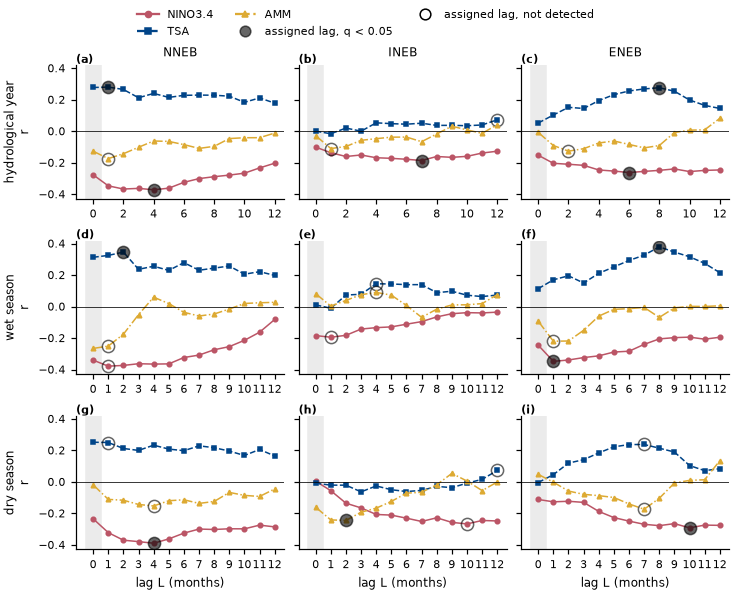

*Correlação de Pearson entre o índice no mês t − L e o quantil u da chuva do alvo inteiro no mês t, em 1981–2010, por caso (linhas) e alvo (colunas). Faixa cinza: L0, relação simultânea, fora da escolha. Círculo: defasagem atribuída L* (cheio: q < 0,05; vazio: não detectada). Arquivos: `resultados/completo/figuras/F07_perfis_r.png` e `.pdf` (169 × 137 mm).*

#### Síntese numérica

- 11 combinações detectadas de 27 com q < 0,05 (NNEB, ano hidrológico, NINO3.4 em L4: −0,37; NNEB, ano hidrológico, TSA em L1: +0,28; NNEB, estação chuvosa, TSA em L2: +0,35; NNEB, estação seca, NINO3.4 em L4: −0,39; INEB, ano hidrológico, NINO3.4 em L7: −0,19; INEB, estação seca, AMM em L2: −0,24; ENEB, ano hidrológico, NINO3.4 em L6: −0,26; ENEB, ano hidrológico, TSA em L8: +0,28; ENEB, estação chuvosa, NINO3.4 em L1: −0,35; ENEB, estação chuvosa, TSA em L8: +0,38; ENEB, estação seca, NINO3.4 em L10: −0,29).
- NNEB, ano hidrológico: L* = NINO3.4 L4, TSA L1, AMM L1.
- NNEB, estação chuvosa: L* = NINO3.4 L1, TSA L2, AMM L1.
- NNEB, estação seca: L* = NINO3.4 L4, TSA L1, AMM L4.
- INEB, ano hidrológico: L* = NINO3.4 L7, TSA L12, AMM L1.
- INEB, estação chuvosa: L* = NINO3.4 L1, TSA L4, AMM L4.
- INEB, estação seca: L* = NINO3.4 L10, TSA L12, AMM L2.
- ENEB, ano hidrológico: L* = NINO3.4 L6, TSA L8, AMM L2.
- ENEB, estação chuvosa: L* = NINO3.4 L1, TSA L8, AMM L1.
- ENEB, estação seca: L* = NINO3.4 L10, TSA L7, AMM L7.
- Diagnóstico além da janela: maior |r| depois de L12 em 2 de 27 combinações (INEB, ano hidrológico, TSA: L14, ganho de |r| 0,03; INEB, estação seca, TSA: L18, ganho de |r| 0,05).

### Relatório parcial 4 · 30/10/2026 19:39 · fim da Seção 2

Modo completo. Tempo decorrido: 1 min. Término geral previsto: 31/10/2026 15:08.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | aguardando | 0 / 9 | 0 min | 4 min (a priori) | 30/10 19:44 |
| Seção 4 | aguardando | 0 / 259 | 0 min | 2 h 53 min (a priori) | 30/10 22:36 |
| Seção 5 | aguardando | 0 / 9 | 0 min | 0 min (a priori) | 30/10 22:37 |
| Seção 6 | aguardando | 0 / 54 | 0 min | 1 min (a priori) | 30/10 22:38 |
| Seção 7 | aguardando | 0 / 54 | 0 min | 2 min (a priori) | 30/10 22:40 |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 22:47 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 31/10 02:25 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 15:07 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 15:08 |

Últimos registros:
- 2026-10-30T22:39:36+00:00 | Seção 2: iniciada (9 unidades de trabalho).
- 2026-10-30T22:39:42+00:00 | Seção 2: 27 combinações; 11 detectadas (q < 0,05); defasagens gravadas em registros/defasagens.json.
- 2026-10-30T22:39:46+00:00 | Seção 2: concluída em 0 min.



In [8]:
# =============================================================================
# 2.3 Tabelas, figuras e síntese numérica da Seção 2. Lê apenas o que 2.2 calculou.
# =============================================================================
_s = SINAL.copy()
_s['caso'] = _s['caso'].map(ROTULO_CASO)
tabela(_s, 'associacao', 'Associação regional e defasagens atribuídas, 1981–2010',
       'Cada índice sozinho, no quantil u do alvo inteiro. L*: defasagem de maior |r| entre L1 e '
       'Lmáx. p: teste pelo máximo sobre os deslocamentos circulares da série do índice, que '
       'desconta a escolha da defasagem. q: Benjamini-Hochberg sobre as 27 combinações. Efeito: '
       'variação do quantil u da chuva do mês, em pontos percentuais, por 1 dp do índice. IC95 '
       'de r(L*) por reamostragem de anos hidrológicos.', n=27)
_p = PERFIL.copy()
_p['caso'] = _p['caso'].map(ROTULO_CASO)
tabela(_p, 'perfil_defasagens', 'Correlação e efeito por defasagem',
       'Uma linha por alvo, caso, índice e defasagem, de L0 a Lmáx, em 1981–2010. Em L0, índice e '
       'chuva são do mesmo mês (relação simultânea).', n=21)

tabela(DIAG_JANELA.assign(caso=DIAG_JANELA.caso.map(ROTULO_CASO)),
       'defasagem_alem_da_janela', 'Diagnóstico: correlação além da janela de defasagens',
       f'Maior |r| entre L1 e L{L_DIAG} na série observada de 1981–2010, comparado com o L* da '
       'janela L1–L12. Só diagnóstico: não altera L* nem a previsão; um pico além da janela com '
       'ganho grande de |r| é declarado como limitação.', n=27)


def painel_perfis(coluna, coluna_l, coluna_q, chave, titulo, legenda):
    """Grade casos × alvos com o perfil de cada índice de L0 a Lmáx."""
    fig, axs = plt.subplots(len(CASOS), len(ALVOS), figsize=(2.5 * len(ALVOS) + 0.5,
                                                            2.0 * len(CASOS) + 0.5),
                            sharey=True, squeeze=False)
    for (i, caso), (k, alvo) in itertools.product(enumerate(CASOS), enumerate(ALVOS)):
        ax = axs[i, k]
        for nome in INDICES:
            d = PERFIL[(PERFIL.alvo == alvo) & (PERFIL.caso == caso) & (PERFIL['índice'] == nome)]
            ax.plot(d.L, d[coluna], **ESTILO[nome], ms=3, lw=1)
            s = SINAL[(SINAL.alvo == alvo) & (SINAL.caso == caso)
                      & (SINAL['índice'] == nome)].iloc[0]
            valor = d.set_index('L').loc[s[coluna_l], coluna]
            ax.plot(s[coluna_l], valor, marker='o', ms=8, mec='k', mew=1.0,
                    mfc='k' if s[coluna_q] < ALFA else 'none', alpha=0.6, ls='none')
        ax.axvspan(-0.5, 0.5, color='0.92', zorder=0)
        ax.axhline(0, color='k', lw=0.5)
        ax.set(xticks=range(0, LMAX[(alvo, caso)] + 1, 2 if caso == 'ano' else 1))
        if i == 0:
            ax.set_title(alvo)
        if k == 0:
            ax.set_ylabel(f'{EN[caso]}\nr')
        if i == len(CASOS) - 1:
            ax.set_xlabel('lag L (months)')
    fig.legend(handles=[plt.Line2D([], [], ms=4, label=n, **ESTILO[n]) for n in INDICES]
               + [plt.Line2D([], [], marker='o', ms=7, mfc='k', mec='k', ls='none', alpha=0.6,
                             label='assigned lag, q < 0.05'),
                  plt.Line2D([], [], marker='o', ms=7, mfc='none', mec='k', ls='none',
                             label='assigned lag, not detected')],
               loc='outside upper center', ncol=3)
    figura(fig, chave, titulo, legenda)


painel_perfis('r', 'L* (meses)', 'q (BH)', 'perfis_r', 'Correlação por defasagem',
              'Correlação de Pearson entre o índice no mês t − L e o quantil u da chuva do alvo '
              'inteiro no mês t, em 1981–2010, por caso (linhas) e alvo (colunas). '
              'Faixa cinza: L0, relação simultânea, fora da escolha. Círculo: defasagem atribuída '
              'L* (cheio: q < 0,05; vazio: não detectada).')

det = SINAL[SINAL['q (BH)'] < ALFA]
itens = '; '.join(f"{r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['índice']} em L{r['L* (meses)']}: "
                  f"{r['r(L*)']:+.2f}" for _, r in det.iterrows())
linhas = [f"{conc(len(det), 'combinação detectada', 'combinações detectadas')} de {len(SINAL)} "
          f'com q < 0,05' + (f' ({itens}).' if itens else '.')]
for (alvo, caso), d in DEFASAGENS.items():
    linhas.append(f"{alvo}, {ROTULO_CASO[caso]}: L* = " + ', '.join(
        f'{n} L{d["L*"][n]}' for n in INDICES) + '.')
_al = DIAG_JANELA[DIAG_JANELA['pico além da janela']]
_col = f'maior |r| em L1–L{L_DIAG}'
linhas.append(f'Diagnóstico além da janela: maior |r| depois de L12 em {len(_al)} de '
              f'{len(DIAG_JANELA)} combinações' + (' (' + '; '.join(
                  f"{r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['índice']}: L{r[_col]}, "
                  f"ganho de |r| {r['ganho de |r| além da janela']:.2f}" for _, r in _al.iterrows())
                  + ').' if len(_al) else '.'))
sintese(linhas)
PROGRESSO.concluir('Seção 2')

### 2.4 Results and discussion

In the profiles, a curve that stays on the same side of zero for several months is compatible with the persistence of the index; an isolated peak may be chance, and the maximum-statistic test discounts the choice of lag. The expected-sign column shows whether each relationship has the sign described in the literature. The assigned lag is used even when the association is not detected, because the question of Sections 5 to 9 is whether it improves the forecast. The diagnostic table shows the combinations whose |r| peak would lie between L13 and L18 and how much |r| would gain.

### 2.5 Conclusion

The section delivers, for each target, case and index, the correlation with the quantile at each lag from L0 to L12, the diagnostic up to L18, the test result and the assigned lag L*, stored in `registros/defasagens.json` and read by Sections 3 to 10.

### 2.6 References

BENJAMINI, Y.; HOCHBERG, Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. **Journal of the Royal Statistical Society: Series B**, v. 57, n. 1, p. 289-300, 1995. DOI: 10.1111/j.2517-6161.1995.tb02031.x.

UVO, C. B. et al. The relationships between tropical Pacific and Atlantic SST and northeast Brazil monthly precipitation. **Journal of Climate**, v. 11, p. 551-562, 1998. DOI: 10.1175/1520-0442(1998)011<0551:TRBTPA>2.0.CO;2.

---

# Section 3. Pixel correlation, lag of each pixel, sensitivity and dominant index

### 3.1 Theoretical and methodological basis

**Scientific question.** In which parts of each target does the association between each index and monthly rainfall appear, at what lag does each pixel respond, how much does pixel rainfall change per standard deviation of the index, and which index dominates in each pixel?

**Introduction.** The regional series summarizes the whole target and hides internal differences: the north responds to the position of the Intertropical Convergence Zone, and the east to disturbances coming from the Atlantic. Correlation maps tested pixel by pixel produce significant patches by chance (Wilks, 2016).

**Rationale.** Section 10 forecasts each pixel with a lag assessed here using 1981–2010 only. Knowing where the association appears helps to read the skill maps of that section and to recognize internal sectors (sub-basins) that respond differently from the whole target.

**Hypotheses.** For each target, case, index and lag: H0, the spatial pattern of the correlations is not stronger than that produced by chance; H1, it is stronger. In each pixel: H0, no lag from L1 to L12 is associated with the pixel's rainfall. Sensitivity and the dominant index are exploratory.

**Objective.** Compute, in each pixel, the correlation of each index with the quantile `u`, from L0 to L12, in 1981–2010; test each map as a whole and each pixel; assign the lag of each pixel; map the sensitivity at that lag and the dominant index.

**Data and methodology.**
- Response: `u` of each pixel (position among the 30 values of the same month in 1981–2010), in the months of the case and the training hydrological years. Each pixel uses the calendar of its target; pixels suspected of a break are kept (Section 1; list in `registros/pixels_suspeitos.csv`).
- Field test, one per map: the area-weighted mean of |r|, compared with the same statistic computed for each circular shift of the index series, as in Section 2; Benjamini and Hochberg (1995) q-values over all maps.
- p-value of each pixel: fraction of series (observed and shifted) in which the pixel's largest |r| between L1 and L12 reaches the observed one, with the lag search repeated in each shift; significance by a 10% false discovery rate in each map (Benjamini and Hochberg, 1995; Wilks, 2016).
- Pixel lag: where the pixel is significant, its own (the lag of largest |r| between L1 and L12); elsewhere, the regional lag L* of Section 2. This prevents pixels without signal from receiving a lag chosen by chance. Sensitivity: `r × sd(100·u) / sd(index)` at that lag, in percentage points of quantile per standard deviation of the index.
- Dominant index: in each pixel, the index with the largest |r| between L1 and L12, each evaluated on its own, at its own lag. Section 3 does not change the regional lags of Section 2.

**Limitations declared before the run.** The field test says whether the map as a whole beats chance; the pixel test says where. The own lag of a significant pixel is still the maximum of 12 correlations and may vary between neighbouring pixels; the dominant index picks the largest among three indices and several lags and favours high values by chance.

**Outputs.** Tables: field test; lag of each pixel, area with significant pixels and sensitivity; dominant index. Figures: correlation at the regional lags, by case; lag of each pixel; sensitivity of each pixel; dominant index and its lag.

In [9]:
# =============================================================================
# 3.2 Processamento: correlação de cada índice com o quantil u em cada pixel, por alvo, caso
# e defasagem (L0 a Lmáx), em 1981–2010; teste de campo de cada mapa e valor-p de cada pixel
# (deslocamentos circulares da Seção 2, com a busca da defasagem refeita); defasagem de cada
# pixel: a própria onde o pixel é significativo (taxa de falsas descobertas de 10 %), senão a
# regional; sensibilidade; índice predominante. Não gera figuras.
# =============================================================================
PROGRESSO.iniciar('Seção 3', N_COMB)
BLOCO_SERIES = 40                          # séries deslocadas por bloco nos produtos matriciais


def grade_vazia():
    """Grade da malha preenchida com NaN."""
    return np.full(DONO.shape, np.nan, dtype='float32')


R_CEL = {}                                 # (alvo, caso, índice) -> (L, células) correlações
L_PIX, R_PIX, SENS_PIX = {}, {}, {}        # (alvo, caso, índice) -> (células,) no L* usado
P_PIX, SIG_PIX, L_PROPRIO = {}, {}, {}     # valor-p, significância e L* próprio de cada pixel
ALFA_PIX = CFG['pixel']['alfa_fdr']
DOM = {c: {k: grade_vazia() for k in ('indice', 'forca', 'L')} for c in CASOS}
LINHAS_CAMPO, LINHAS_DOM = [], []
for alvo in ALVOS:
    iy, ix = CELULAS[alvo]
    w = PESO[alvo]
    S = SERIES[alvo]
    Zc = U_CEL[:, iy, ix].astype('float64')                       # (meses, células)
    for caso in CASOS:
        lags = np.arange(LMAX[(alvo, caso)] + 1)
        t = meses_do_caso(alvo, caso, ANOS[alvo]['treino'])
        Y = Zc[t]
        Yc = Y - Y.mean(0)
        norma = np.sqrt((Yc ** 2).sum(0))
        ok = norma > 1e-9
        wv = np.where(ok, w, 0.0)
        Ys = Yc / np.where(ok, norma, 1.0)
        linhas_idx = t[:, None] + G.D - lags[None, :]                 # (meses, L)
        r_obs = np.full((len(INDICES), len(lags), len(ok)), np.nan)
        stat = np.empty((len(INDICES), len(S), len(lags)))
        excede = np.zeros((len(INDICES), len(ok)))
        for j in range(len(INDICES)):
            for b0 in range(0, len(S), BLOCO_SERIES):
                bloco = S[b0:b0 + BLOCO_SERIES, :, j][:, linhas_idx]   # (s, meses, L)
                X = bloco.transpose(1, 0, 2).reshape(len(t), -1)
                Xc = X - X.mean(0)
                Rm = Ys.T @ (Xc / np.sqrt((Xc ** 2).sum(0)))           # (células, s × L)
                Rm[~ok] = np.nan
                stat[j, b0:b0 + len(bloco)] = (wv @ np.nan_to_num(np.abs(Rm)) / wv.sum()
                                               ).reshape(len(bloco), -1)
                # maior |r| entre L1 e Lmáx de cada pixel em cada série (observada ou deslocada)
                maximo = np.abs(Rm).reshape(len(ok), len(bloco), len(lags))[:, :, 1:].max(2)
                if b0 == 0:
                    r_obs[j] = Rm[:, :len(lags)].T
                    max_obs = maximo[:, 0]
                    maximo = maximo[:, 1:]
                excede[j] += (maximo >= max_obs[:, None] - 1e-12).sum(1)
                del Rm, X, Xc
        sy = 100 * norma / np.sqrt(len(t))                           # dp de 100·u por célula
        for j, nome in enumerate(INDICES):
            R_CEL[(alvo, caso, nome)] = r_obs[j]
            sx = S[0][:, j][linhas_idx].std(0)                          # dp do índice por L
            k_proprio = 1 + np.nanargmax(np.nan_to_num(np.abs(r_obs[j, 1:]), nan=-1.0), 0)
            p_pix = np.where(ok, (1 + excede[j]) / len(S), np.nan)
            sig = np.zeros(len(ok), bool)
            sig[ok] = bh_rejeita(p_pix[ok], ALFA_PIX)
            k_pix = np.where(sig, k_proprio, DEFASAGENS[(alvo, caso)]['L*'][nome])
            col = np.arange(len(ok))
            P_PIX[(alvo, caso, nome)], SIG_PIX[(alvo, caso, nome)] = p_pix, sig
            L_PROPRIO[(alvo, caso, nome)] = np.where(ok, lags[k_proprio], 0).astype('int16')
            L_PIX[(alvo, caso, nome)] = np.where(ok, lags[k_pix], 0).astype('int16')
            R_PIX[(alvo, caso, nome)] = np.where(ok, r_obs[j, k_pix, col], np.nan)
            SENS_PIX[(alvo, caso, nome)] = np.where(
                ok, r_obs[j, k_pix, col] * sy / sx[k_pix], np.nan)
            for k, L in enumerate(lags):
                r = r_obs[j, k]
                LINHAS_CAMPO.append({
                    'alvo': alvo, 'caso': caso, 'índice': nome, 'L': int(L),
                    'defasagem atribuída (L*)': int(L) == DEFASAGENS[(alvo, caso)]['L*'][nome],
                    'r médio': np.nansum(wv * r) / wv.sum(), 'média de |r|': stat[j, 0, k],
                    'percentil 95 do acaso': np.percentile(stat[j, 1:, k], 95),
                    'p (campo)': p_por_maximo(stat[j, 0, k], stat[j, 1:, k]),
                    'área com o sinal esperado (%)':
                        100 * wv[np.sign(r) == ESPERADO[nome]].sum() / wv.sum()})
        # índice predominante: maior |r| entre os índices, cada um na sua defasagem mais forte
        absr = np.nan_to_num(np.abs(r_obs[:, 1:, :]), nan=-1.0)       # (índice, L1.., célula)
        k_melhor = absr.argmax(1)
        j_dom = absr.max(1).argmax(0)
        col = np.arange(len(ok))
        L_dom = lags[1:][k_melhor[j_dom, col]]
        r_dom = r_obs[j_dom, 1 + k_melhor[j_dom, col], col]
        for nome_grade, valores in (('indice', j_dom), ('forca', np.abs(r_dom)), ('L', L_dom)):
            DOM[caso][nome_grade][iy, ix] = np.where(ok, valores, np.nan)
        for j, nome in enumerate(INDICES):
            sel = ok & (j_dom == j)
            wd = w[sel]
            LINHAS_DOM.append({
                'alvo': alvo, 'caso': caso, 'índice': nome,
                'área em que predomina (%)': 100 * wd.sum() / wv.sum(),
                '|r| médio onde predomina': float(np.average(np.abs(r_dom[sel]), weights=wd))
                if sel.any() else np.nan,
                'defasagem mais frequente onde predomina':
                    int(pd.Series(L_dom[sel]).value_counts().idxmax()) if sel.any() else np.nan,
                'onde predomina, com o sinal esperado (%)':
                    100 * wd[np.sign(r_dom[sel]) == ESPERADO[nome]].sum() / wd.sum()
                    if sel.any() else np.nan})
        PROGRESSO.avancar('Seção 3')
    del Zc
salvar_npz(PASTAS['pixels'] / 'defasagens_pixel.npz',
           **{f"{a}|{c}|{n}": L_PIX[(a, c, n)] for a, c, n in L_PIX})
CAMPO = pd.DataFrame(LINHAS_CAMPO)
CAMPO['q (BH)'] = benjamini_hochberg(CAMPO['p (campo)'])
CAMPO['campo detectado'] = CAMPO['q (BH)'] < ALFA
PREDOMINIO = pd.DataFrame(LINHAS_DOM)
registrar(f"Seção 3: {len(CAMPO)} mapas; {int(CAMPO['campo detectado'].sum())} detectados pelo "
          'teste de campo (q < 0,05).')

Seção 3: 351 mapas; 112 detectados pelo teste de campo (q < 0,05).


**Tabela 14. Teste de campo dos mapas de correlação por pixel, 1981–2010**

,alvo,caso,índice,L,defasagem atribuída (L*),r médio,média de |r|,percentil 95 do acaso,p (campo),área com o sinal esperado (%),q (BH),campo detectado
0,NNEB,ano hidrológico,NINO3.4,0,False,-0.190,0.190,0.118,0.003,100.0,0.015,True
1,NNEB,ano hidrológico,NINO3.4,1,False,-0.239,0.239,0.118,0.003,100.0,0.015,True
2,NNEB,ano hidrológico,NINO3.4,2,False,-0.254,0.254,0.118,0.003,100.0,0.015,True
3,NNEB,ano hidrológico,NINO3.4,3,False,-0.257,0.257,0.118,0.003,100.0,0.015,True
4,NNEB,ano hidrológico,NINO3.4,4,True,-0.262,0.262,0.116,0.003,100.0,0.015,True
5,NNEB,ano hidrológico,NINO3.4,5,False,-0.251,0.251,0.116,0.003,100.0,0.015,True
6,NNEB,ano hidrológico,NINO3.4,6,False,-0.222,0.222,0.115,0.003,100.0,0.015,True
7,NNEB,ano hidrológico,NINO3.4,7,False,-0.210,0.210,0.114,0.003,100.0,0.015,True
8,NNEB,ano hidrológico,NINO3.4,8,False,-0.199,0.199,0.113,0.003,100.0,0.015,True
9,NNEB,ano hidrológico,NINO3.4,9,False,-0.188,0.188,0.112,0.003,100.0,0.015,True


*Um teste por mapa (alvo, caso, índice e defasagem). Estatística: média de |r| ponderada pela área, comparada com a mesma estatística calculada com cada deslocamento circular da série dos índices. q: Benjamini-Hochberg sobre os 351 mapas. Mostradas 21 de 351 linhas. Arquivo: `resultados/completo/tabelas/T14_teste_campo.csv`.*

**Figura 8. Correlação por pixel na defasagem regional, ano hidrológico**

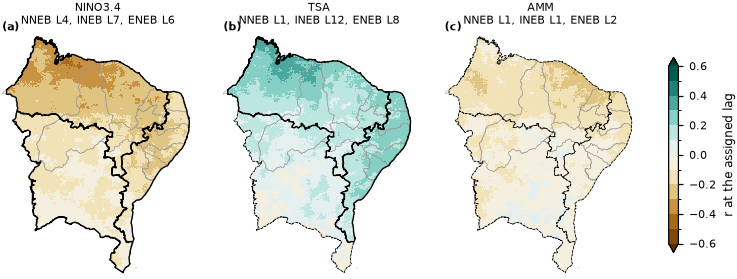

*Correlação entre o índice no mês t − L* e o quantil u da chuva do pixel no mês t, em 1981–2010, com a defasagem L* atribuída a cada alvo na Seção 2 (indicada no título do painel). Verde: mais chuva com o índice positivo; marrom: menos chuva. Contorno contínuo: alvo cujo mapa foi detectado pelo teste de campo (q < 0,05); tracejado: não detectado. Arquivos: `resultados/completo/figuras/F08_mapas_r_ano.png` e `.pdf` (170 × 65 mm).*

**Figura 9. Correlação por pixel na defasagem regional, estação chuvosa**

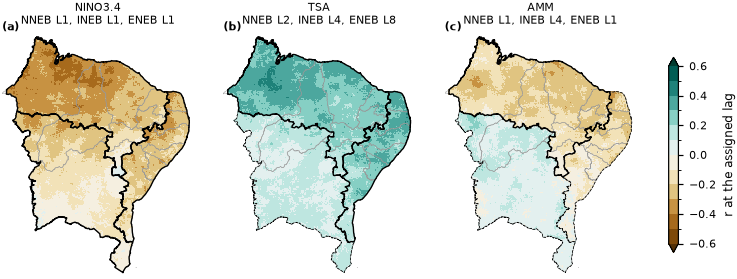

*Correlação entre o índice no mês t − L* e o quantil u da chuva do pixel no mês t, em 1981–2010, com a defasagem L* atribuída a cada alvo na Seção 2 (indicada no título do painel). Verde: mais chuva com o índice positivo; marrom: menos chuva. Contorno contínuo: alvo cujo mapa foi detectado pelo teste de campo (q < 0,05); tracejado: não detectado. Arquivos: `resultados/completo/figuras/F09_mapas_r_chuvosa.png` e `.pdf` (170 × 65 mm).*

**Figura 10. Correlação por pixel na defasagem regional, estação seca**

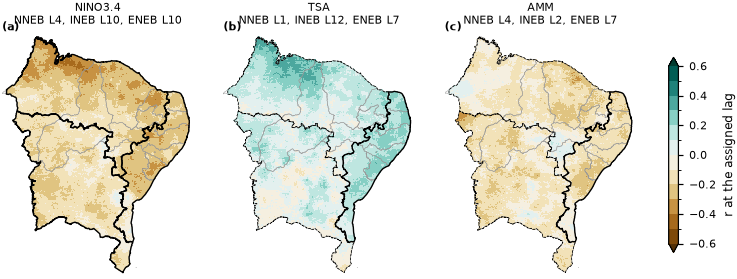

*Correlação entre o índice no mês t − L* e o quantil u da chuva do pixel no mês t, em 1981–2010, com a defasagem L* atribuída a cada alvo na Seção 2 (indicada no título do painel). Verde: mais chuva com o índice positivo; marrom: menos chuva. Contorno contínuo: alvo cujo mapa foi detectado pelo teste de campo (q < 0,05); tracejado: não detectado. Arquivos: `resultados/completo/figuras/F10_mapas_r_seca.png` e `.pdf` (170 × 65 mm).*

**Tabela 15. Defasagem de cada pixel e sensibilidade, 1981–2010**

,alvo,caso,índice,L* regional,área com pixel significativo (%),L* mais frequente nos pixels,área com L* do pixel igual ao regional (%),|r| médio no L* do pixel,sensibilidade média (p.p. por dp),área com o sinal esperado (%)
0,NNEB,ano hidrológico,NINO3.4,4,96.3,4,38.0,0.273,-7.83,100.0
1,NNEB,ano hidrológico,TSA,1,71.1,1,66.0,0.206,5.72,100.0
2,NNEB,ano hidrológico,AMM,1,10.9,1,98.0,0.143,-4.16,98.0
3,NNEB,estação chuvosa,NINO3.4,1,73.6,1,60.0,0.313,-8.04,100.0
4,NNEB,estação chuvosa,TSA,2,84.3,2,55.0,0.299,8.49,100.0
5,NNEB,estação chuvosa,AMM,1,5.3,1,100.0,0.196,-5.26,100.0
6,NNEB,estação seca,NINO3.4,4,84.9,4,45.0,0.258,-8.30,100.0
7,NNEB,estação seca,TSA,1,16.3,1,94.0,0.140,3.74,93.0
8,NNEB,estação seca,AMM,4,4.5,4,96.0,0.123,-3.53,91.0
9,INEB,ano hidrológico,NINO3.4,7,28.9,7,73.0,0.113,-3.22,100.0


*Valor-p de cada pixel: maior |r| entre L1 e L12 comparado com o mesmo máximo nas séries do índice deslocadas no tempo; significância com taxa de falsas descobertas de 10 % no mapa (Wilks, 2016). Pixel significativo usa a sua própria defasagem; os demais usam o L* regional. É a defasagem que a Seção 10 usa. Sensibilidade: variação do quantil u, em pontos percentuais, por 1 dp do índice nessa defasagem. Médias ponderadas pela área. Arquivo: `resultados/completo/tabelas/T15_defasagem_pixel.csv`.*

**Figura 11. Defasagem de cada pixel**

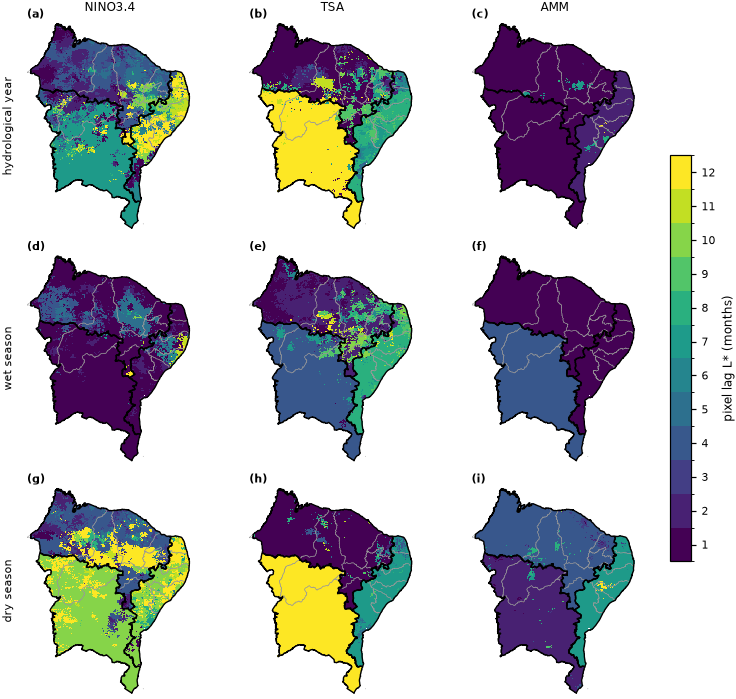

*Defasagem usada em cada pixel de 0,05°, por caso (linhas) e índice (colunas): a do próprio pixel (maior |r| entre L1 e L12 em 1981–2010) onde ele é significativo com taxa de falsas descobertas de 10 %; nos demais, o L* regional da Seção 2. Arquivos: `resultados/completo/figuras/F11_mapas_defasagem_pixel.png` e `.pdf` (170 × 162 mm).*

**Figura 12. Sensibilidade de cada pixel ao índice**

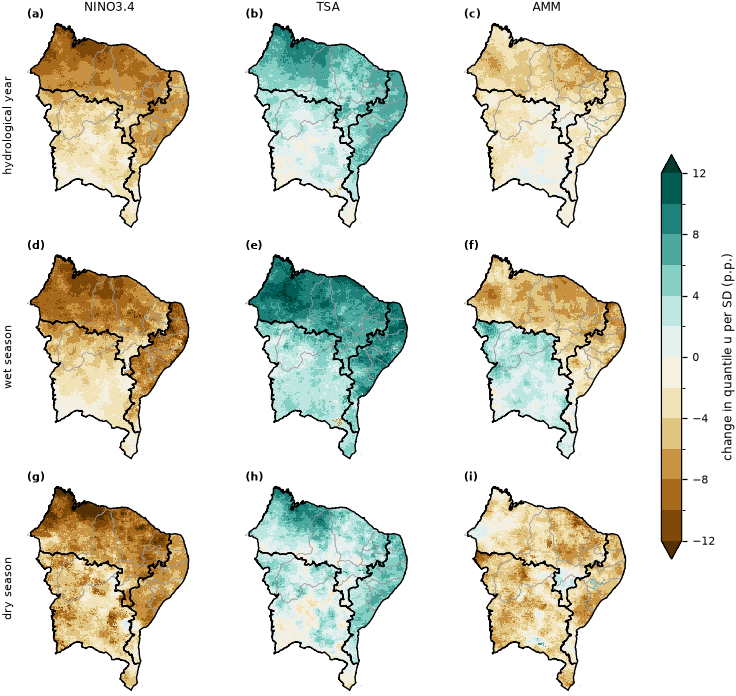

*Variação do quantil u da chuva de cada pixel (pontos percentuais) por 1 dp do índice, na defasagem L* do pixel, em 1981–2010, por caso (linhas) e índice (colunas). Verde: mais chuva com o índice positivo; marrom: menos chuva. Arquivos: `resultados/completo/figuras/F12_mapas_sensibilidade_pixel.png` e `.pdf` (170 × 161 mm).*

**Tabela 16. Índice predominante por alvo e caso**

,alvo,caso,índice,área em que predomina (%),|r| médio onde predomina,defasagem mais frequente onde predomina,"onde predomina, com o sinal esperado (%)"
0,NNEB,ano hidrológico,NINO3.4,85.7,0.285,4,100.0
1,NNEB,ano hidrológico,TSA,10.7,0.229,9,100.0
2,NNEB,ano hidrológico,AMM,3.6,0.229,7,100.0
3,NNEB,estação chuvosa,NINO3.4,62.7,0.354,1,100.0
4,NNEB,estação chuvosa,TSA,36.9,0.312,2,100.0
5,NNEB,estação chuvosa,AMM,0.4,0.262,1,93.0
6,NNEB,estação seca,NINO3.4,75.8,0.280,4,100.0
7,NNEB,estação seca,TSA,6.8,0.252,1,99.0
8,NNEB,estação seca,AMM,17.4,0.255,8,99.0
9,INEB,ano hidrológico,NINO3.4,51.5,0.153,4,100.0


*Em cada pixel, o índice de maior |r| entre L1 e Lmáx, em 1981–2010. Área em % da área do alvo. Exploratório, sem teste. Arquivo: `resultados/completo/tabelas/T16_indice_predominante.csv`.*

**Figura 13. Índice predominante e sua defasagem, por caso**

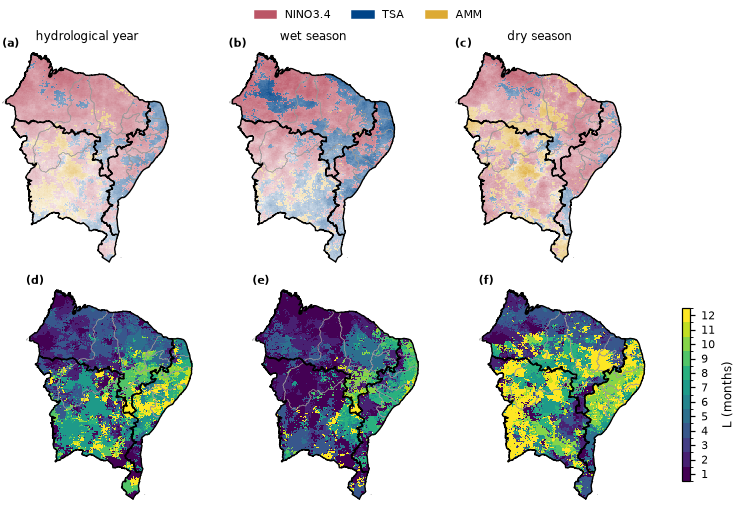

*Colunas: ano hidrológico, estação chuvosa e estação seca. Primeira linha: índice de maior |r| em cada pixel, com cor mais intensa quanto maior o |r| (saturada a partir de 0,5). Segunda linha: defasagem desse índice. Exploratório, sem teste. Arquivos: `resultados/completo/figuras/F13_indice_predominante.png` e `.pdf` (170 × 117 mm).*

#### Síntese numérica

- 112 de 351 mapas detectados pelo teste de campo (q < 0,05).
- Na defasagem atribuída L*: 16 de 27 mapas detectados (NNEB, ano hidrológico, NINO3.4 L4; NNEB, ano hidrológico, TSA L1; NNEB, estação chuvosa, NINO3.4 L1; NNEB, estação chuvosa, TSA L2; NNEB, estação chuvosa, AMM L1; NNEB, estação seca, NINO3.4 L4; INEB, ano hidrológico, NINO3.4 L7; INEB, estação chuvosa, NINO3.4 L1; INEB, estação seca, NINO3.4 L10; ENEB, ano hidrológico, NINO3.4 L6; ENEB, ano hidrológico, TSA L8; ENEB, estação chuvosa, NINO3.4 L1; ENEB, estação chuvosa, TSA L8; ENEB, estação seca, NINO3.4 L10; ENEB, estação seca, TSA L7; ENEB, estação seca, AMM L7).
- NNEB, ano hidrológico: NINO3.4 predomina em 86 % da área, com |r| médio de 0,28.
- NNEB, estação chuvosa: NINO3.4 predomina em 63 % da área, com |r| médio de 0,35.
- NNEB, estação seca: NINO3.4 predomina em 76 % da área, com |r| médio de 0,28.
- INEB, ano hidrológico: NINO3.4 predomina em 52 % da área, com |r| médio de 0,15.
- INEB, estação chuvosa: NINO3.4 predomina em 50 % da área, com |r| médio de 0,21.
- INEB, estação seca: NINO3.4 predomina em 50 % da área, com |r| médio de 0,22.
- ENEB, ano hidrológico: NINO3.4 predomina em 56 % da área, com |r| médio de 0,23.
- ENEB, estação chuvosa: TSA predomina em 57 % da área, com |r| médio de 0,29.
- ENEB, estação seca: NINO3.4 predomina em 78 % da área, com |r| médio de 0,26.

### Relatório parcial 5 · 30/10/2026 19:41 · fim da Seção 3

Modo completo. Tempo decorrido: 2 min. Término geral previsto: 31/10/2026 15:05.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | aguardando | 0 / 259 | 0 min | 2 h 53 min (a priori) | 30/10 22:33 |
| Seção 5 | aguardando | 0 / 9 | 0 min | 0 min (a priori) | 30/10 22:34 |
| Seção 6 | aguardando | 0 / 54 | 0 min | 1 min (a priori) | 30/10 22:35 |
| Seção 7 | aguardando | 0 / 54 | 0 min | 2 min (a priori) | 30/10 22:37 |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 22:44 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 31/10 02:22 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 15:04 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 15:05 |

Últimos registros:
- 2026-10-30T22:39:46+00:00 | Seção 3: iniciada (9 unidades de trabalho).
- 2026-10-30T22:40:25+00:00 | Seção 3: 351 mapas; 112 detectados pelo teste de campo (q < 0,05).
- 2026-10-30T22:41:17+00:00 | Seção 3: concluída em 2 min.



In [10]:
# =============================================================================
# 3.3 Tabelas, figuras e síntese numérica da Seção 3. Lê apenas o que 3.2 calculou.
# =============================================================================
_c = CAMPO.copy()
_c['caso'] = _c['caso'].map(ROTULO_CASO)
tabela(_c, 'teste_campo', 'Teste de campo dos mapas de correlação por pixel, 1981–2010',
       f'Um teste por mapa (alvo, caso, índice e defasagem). Estatística: média de |r| ponderada '
       f'pela área, comparada com a mesma estatística calculada com cada deslocamento circular da '
       f'série dos índices. q: Benjamini-Hochberg sobre os {len(CAMPO)} mapas.', n=21)

# ----- correlação nas defasagens atribuídas (L* de cada alvo, caso e índice) -----
limites_r = np.round(np.arange(-0.6, 0.61, 0.1), 2)
for caso in CASOS:
    fig, axs = plt.subplots(1, len(INDICES), figsize=(2.4 * len(INDICES) + 0.6, 2.9),
                            squeeze=False)
    for j, nome in enumerate(INDICES):
        campo = grade_vazia()
        detectados = []
        for alvo in ALVOS:
            L = DEFASAGENS[(alvo, caso)]['L*'][nome]
            campo[CELULAS[alvo]] = R_CEL[(alvo, caso, nome)][L]
            linha = CAMPO[(CAMPO.alvo == alvo) & (CAMPO.caso == caso) & (CAMPO['índice'] == nome)
                          & (CAMPO.L == L)].iloc[0]
            if linha['campo detectado']:
                detectados.append(alvo)
        im = mapa_celulas(axs[0, j], campo, 'BrBG', limites_r, destaque=detectados)
        axs[0, j].set_title(nome + '\n' + ', '.join(
            f"{a} L{DEFASAGENS[(a, caso)]['L*'][nome]}" for a in ALVOS), fontsize=7)
    fig.colorbar(im, ax=axs, shrink=0.8, label='r at the assigned lag')
    figura(fig, f'mapas_r_{caso}', f'Correlação por pixel na defasagem regional, '
           f'{ROTULO_CASO[caso]}',
           'Correlação entre o índice no mês t − L* e o quantil u da chuva do pixel no mês t, '
           'em 1981–2010, com a defasagem L* atribuída a cada alvo na Seção 2 (indicada '
           'no título do painel). Verde: mais chuva com o índice positivo; marrom: menos chuva. '
           'Contorno contínuo: alvo cujo mapa foi detectado pelo teste de campo (q < 0,05); '
           'tracejado: não detectado.', dpi=CFG['figuras']['dpi_mapas'])

# ----- defasagem L* de cada pixel e sensibilidade nela -----
lag_max = max(LMAX.values())
cmap_L = ListedColormap(plt.get_cmap('viridis')(np.linspace(0, 1, lag_max)))
norma_L = BoundaryNorm(np.arange(0.5, lag_max + 1), cmap_L.N)
linhas = []
for alvo, caso, nome in itertools.product(ALVOS, CASOS, INDICES):
    ok = np.isfinite(R_PIX[(alvo, caso, nome)])
    w, Lp = PESO[alvo][ok], L_PIX[(alvo, caso, nome)][ok]
    Lreg = DEFASAGENS[(alvo, caso)]['L*'][nome]
    freq = pd.Series(w).groupby(Lp).sum()
    sig = SIG_PIX[(alvo, caso, nome)][ok]
    linhas.append({'alvo': alvo, 'caso': caso, 'índice': nome, 'L* regional': Lreg,
                   'área com pixel significativo (%)': 100 * w[sig].sum() / w.sum(),
                   'L* mais frequente nos pixels': int(freq.idxmax()),
                   'área com L* do pixel igual ao regional (%)':
                       100 * w[Lp == Lreg].sum() / w.sum(),
                   '|r| médio no L* do pixel': float(np.average(
                       np.abs(R_PIX[(alvo, caso, nome)][ok]), weights=w)),
                   'sensibilidade média (p.p. por dp)': float(np.average(
                       SENS_PIX[(alvo, caso, nome)][ok], weights=w)),
                   'área com o sinal esperado (%)': 100 * w[np.sign(
                       R_PIX[(alvo, caso, nome)][ok]) == ESPERADO[nome]].sum() / w.sum()})
DEF_PIX = pd.DataFrame(linhas)
tabela(DEF_PIX.assign(caso=DEF_PIX.caso.map(ROTULO_CASO)), 'defasagem_pixel',
       'Defasagem de cada pixel e sensibilidade, 1981–2010',
       'Valor-p de cada pixel: maior |r| entre L1 e L12 comparado com o mesmo máximo nas séries '
       'do índice deslocadas no tempo; significância com taxa de falsas descobertas de 10 % no '
       'mapa (Wilks, 2016). Pixel significativo usa a sua própria defasagem; os demais usam o '
       'L* regional. É a defasagem que a Seção 10 usa. Sensibilidade: variação do quantil u, em '
       'pontos percentuais, por 1 dp do índice nessa defasagem. Médias ponderadas pela área.',
       n=27)


def grade_pixel(dic, caso, nome):
    """Grade da malha com o valor de cada pixel dos três alvos."""
    campo = grade_vazia()
    for alvo in ALVOS:
        campo[CELULAS[alvo]] = dic[(alvo, caso, nome)]
    return campo


fig, axs = plt.subplots(len(CASOS), len(INDICES), figsize=(2.3 * len(INDICES) + 0.6,
                                                          2.3 * len(CASOS)), squeeze=False)
for (i, caso), (j, nome) in itertools.product(enumerate(CASOS), enumerate(INDICES)):
    ax = axs[i, j]
    campo = grade_pixel(L_PIX, caso, nome).astype(float)
    campo[~np.isfinite(grade_pixel(R_PIX, caso, nome))] = np.nan
    im = ax.imshow(campo, origin='lower', extent=EXTENSAO, cmap=cmap_L, norm=norma_L,
                   interpolation='nearest')
    desenhar_alvos(ax)
    formatar_mapa(ax, rotulos=False)
    if i == 0:
        ax.set_title(nome)
    if j == 0:
        ax.text(-0.08, 0.5, EN[caso], transform=ax.transAxes, rotation=90, ha='right',
                va='center', fontsize=7)
fig.colorbar(im, ax=axs, shrink=0.6, ticks=range(1, lag_max + 1), label='pixel lag L* (months)')
figura(fig, 'mapas_defasagem_pixel', 'Defasagem de cada pixel',
       'Defasagem usada em cada pixel de 0,05°, por caso (linhas) e índice (colunas): a do '
       'próprio pixel (maior |r| entre L1 e L12 em 1981–2010) onde ele é significativo com taxa '
       'de falsas descobertas de 10 %; nos demais, o L* regional da Seção 2.',
       dpi=CFG['figuras']['dpi_mapas'])

todas = np.concatenate([v[np.isfinite(v)] for v in SENS_PIX.values()])
limites_s = limites_simetricos(todas)
fig, axs = plt.subplots(len(CASOS), len(INDICES), figsize=(2.3 * len(INDICES) + 0.6,
                                                          2.3 * len(CASOS)), squeeze=False)
for (i, caso), (j, nome) in itertools.product(enumerate(CASOS), enumerate(INDICES)):
    ax = axs[i, j]
    im = mapa_celulas(ax, grade_pixel(SENS_PIX, caso, nome), 'BrBG', limites_s)
    if i == 0:
        ax.set_title(nome)
    if j == 0:
        ax.text(-0.08, 0.5, EN[caso], transform=ax.transAxes, rotation=90, ha='right',
                va='center', fontsize=7)
fig.colorbar(im, ax=axs, shrink=0.6, label='change in quantile u per SD (p.p.)')
figura(fig, 'mapas_sensibilidade_pixel', 'Sensibilidade de cada pixel ao índice',
       'Variação do quantil u da chuva de cada pixel (pontos percentuais) por 1 dp do índice, na '
       'defasagem L* do pixel, em 1981–2010, por caso (linhas) e índice (colunas). Verde: mais '
       'chuva com o índice positivo; marrom: menos chuva.', dpi=CFG['figuras']['dpi_mapas'])

# ----- índice predominante -----
_d = PREDOMINIO.copy()
_d['caso'] = _d['caso'].map(ROTULO_CASO)
tabela(_d, 'indice_predominante', 'Índice predominante por alvo e caso',
       'Em cada pixel, o índice de maior |r| entre L1 e Lmáx, em 1981–2010. Área em % da área do '
       'alvo. Exploratório, sem teste.', n=27)
cores_idx = np.array([to_rgb(COR[n]) for n in INDICES])
fig, axs = plt.subplots(2, len(CASOS), figsize=(2.3 * len(CASOS) + 0.6, 5.0), squeeze=False)
for k, caso in enumerate(CASOS):
    d = DOM[caso]
    valido = np.isfinite(d['indice'])
    j = np.where(valido, d['indice'], 0).astype(int)
    a = np.clip(np.nan_to_num(d['forca']) / 0.5, 0.15, 1.0)[..., None]
    rgb = np.where(valido[..., None], 1 - a * (1 - cores_idx[j]), 1.0)
    axs[0, k].imshow(rgb, origin='lower', extent=EXTENSAO, interpolation='nearest')
    im = axs[1, k].imshow(d['L'], origin='lower', extent=EXTENSAO, cmap=cmap_L, norm=norma_L,
                          interpolation='nearest')
    for ax in axs[:, k]:
        desenhar_alvos(ax)
        formatar_mapa(ax, rotulos=False)
    axs[0, k].set_title(EN[caso])
fig.colorbar(im, ax=axs[1, :], shrink=0.8, ticks=range(1, lag_max + 1), label='L (months)')
fig.legend(handles=[Patch(color=COR[n], label=n) for n in INDICES], loc='outside upper center',
           ncol=3)
figura(fig, 'indice_predominante', 'Índice predominante e sua defasagem, por caso',
       'Colunas: ano hidrológico, estação chuvosa e estação seca. Primeira linha: índice de maior '
       '|r| em cada pixel, com cor mais intensa quanto maior o |r| (saturada a partir de 0,5). '
       'Segunda linha: defasagem desse índice. Exploratório, sem teste.',
       dpi=CFG['figuras']['dpi_mapas'])

linhas = []
det = CAMPO[CAMPO['campo detectado']]
linhas.append(f"{len(det)} de {len(CAMPO)} mapas detectados pelo teste de campo (q < 0,05).")
det_l = det[det['defasagem atribuída (L*)']]
linhas.append(f"Na defasagem atribuída L*: {len(det_l)} de "
              f"{int(CAMPO['defasagem atribuída (L*)'].sum())} mapas detectados"
              + (' (' + '; '.join(f"{r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['índice']} L{r['L']}"
                                  for _, r in det_l.iterrows()) + ').' if len(det_l) else '.'))
for (alvo, caso), g in PREDOMINIO.groupby(['alvo', 'caso'], sort=False):
    r = g.sort_values('área em que predomina (%)', ascending=False).iloc[0]
    linhas.append(f"{alvo}, {ROTULO_CASO[caso]}: {r['índice']} predomina em "
                  f"{r['área em que predomina (%)']:.0f} % da área, com |r| médio de "
                  f"{r['|r| médio onde predomina']:.2f}.")
sintese(linhas)
PROGRESSO.concluir('Seção 3')

### 3.4 Results and discussion

The field test separates maps whose pattern beats chance from those that may be only spatial noise. The area with significant pixels says how much of each target has its own association; in the other pixels, the lag is the regional one. The lag map shows whether the lag of significant pixels varies little or much within the target; the variation alone does not indicate its cause. Sensitivity translates the correlation into how far the rainfall quantile shifts per standard deviation of the index. The dominant index indicates which of the three, evaluated on its own, is most associated with the rainfall of each pixel; it is exploratory and does not separate the part of the Pacific influence that reaches Northeast Brazil through the Atlantic.

### 3.5 Conclusion

The section delivers the correlation of each pixel at each lag, the test of each map, the p-value, lag and sensitivity of each pixel (stored in `pixels/defasagens_pixel.npz` and read by Section 10) and the dominant index.

### 3.6 References

BENJAMINI, Y.; HOCHBERG, Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. **Journal of the Royal Statistical Society: Series B**, v. 57, n. 1, p. 289-300, 1995. DOI: 10.1111/j.2517-6161.1995.tb02031.x.

WILKS, D. S. “The stippling shows statistically significant grid points”: how research results are routinely overstated and overinterpreted, and what to do about it. **Bulletin of the American Meteorological Society**, v. 97, n. 12, p. 2263-2273, 2016. DOI: 10.1175/BAMS-D-15-00267.1.

---

# Section 4. Calibration in 1981–2010: input, filter and hyperparameters

### 4.1 Theoretical and methodological basis

**Scientific question.** With what input form, filter and hyperparameters should each model read an index to forecast the quintile class of rainfall, using only what was known up to 2010?

**Introduction.** Fixing hyperparameters a priori leaves the random forest and the neural network free to follow a few extreme training months; choosing them by looking at the test invalidates the test. The accepted solution is a validation inside the training period that respects the order of time (Bergmeir et al., 2018) and uses the same protocol as the application.

**Rationale.** The application (Sections 6 to 10) trains each model once, with 1981–2010, and forecasts 2011–2025. Calibration repeats exactly this protocol inside 1981–2010: a single training with 1981–1995 and validation in 1996–2010, with the same number of networks. The choice is made once for each model, from the mean of the 15 validation years over the 27 targets, cases and indices; the one-standard-error rule (Hastie et al., 2009) favours the simplest configuration when the difference is within the noise.

**Hypotheses.** Calibration does not test the hypothesis of the study. The planted signal is a synthetic experiment on calibration, with one noise realization: it shows how calibration reacts to a weak signal (ρ = 0.3) and to no signal (ρ = 0); it does not estimate the power of the test; false-positive control is the job of the shift null (Section 5) and its empirical check (Section 9).

**Objective.** Choose, in three stages and with 1981–2010 only, the target and metric, the input vector and filter, and the hyperparameters of each model; define the three models used in Sections 6 to 10.

**Data and methodology.**
- Validation: one training with 1981–1995 forecasts each month from 1996 to 2010. Quantiles and climatology come from 1981–1995 only, and the lag of each target, case and index is reassessed with 1981–1995 (the same procedure as Section 2), without looking at validation. Skill is the RPSS relative to climatology; in each validation year, the RPS of the 27 targets, cases and indices are summed, and the result is the mean of the 15 years with the standard error across years. Years are the independent unit; targets, cases and indices of the same year are not.
- Stage 1, target and metric: fixed by principle, quintile class and RPSS (Epstein, 1969; WMO, 2007).
- Stage 2, input vector and filter, with ridge regression (penalty 1 × months): the index at `t − L`; the mean of the 3 months ending at `t − L`; the index at `t − L` and its 3-month change; the 3 months ending at `t − L`; each with or without interaction with the calendar month (the first feature multiplied by the sine and cosine of the month, so that the effect changes over the season); raw index or with the linear trend removed, fitted on the training months only.
- Stage 3, hyperparameters, with the chosen input. The grids range from configurations so regularized that the forecast approaches climatology to flexible configurations, so that the best never sits at the edge for lack of options. Ridge: penalty of 100, 10, 1, 0.1 or 0.01 × training months. Classification random forest, 100 trees: depth 1, 2, 4 or unlimited; leaf with at least 30, 20, 10 or 5% of the months. A 50% leaf is excluded from the grid: it requires exactly half of the weight in each leaf, and with an odd number of drawn months no tree would split, so the forest would repeat the no-index control; with an even number, about a third of the trees would also have no split. Neural network: 2, 4 or 8 hidden neurons; weight decay 10, 1, 0.1, 0.01 or 0.001; 200 or 1000 passes; hyperbolic tangent or ReLU; mean of 3 networks.
- Choice rule, fixed beforehand and declared as a heuristic: the simplest configuration whose skill is within one standard error of the best. Order of simplicity: fewer features, index at L* before the other forms, raw index before detrended; larger penalty; shallower tree and larger leaf; smaller network, larger decay, fewer passes, tangent before ReLU.
- Models. Ridge (Hoerl and Kennard, 1970): a line on the normal score of `u`, whose training spread (with effective degrees of freedom) gives the probability of each class. Random forest (Breiman, 2001): classification trees with months drawn with replacement; the probability is the class fraction in the leaves. Neural network: input → hidden layer → 5 softmax outputs, cross-entropy, AdamW (Loshchilov and Hutter, 2019) with all training months in each pass and a cosine learning-rate schedule; each network starts from weights drawn with its own seed, and the forecast is the mean of 3 networks, as in the application.
- Planted signal: the class of each month is generated from the normal score `ρ × index(t − L*) + √(1 − ρ²) × noise`, with the same noise for ρ = 0 and ρ = 0.3, and stage 3 is repeated with these data (lag reassessed, grid and choice rule), with the stage-2 input form chosen on the real data. The hypothesis test (Sections 5 to 8) is not repeated. The experiment describes how calibration reacts to a known signal; it does not say whether the full protocol would confirm that gain.

**Limitations declared before the run.** Validation uses 1981–2010, and the test 2011–2025; if the relationship changes between the two periods, the chosen configuration may not be the best in the test. A single configuration per model may not be the best for each target, case and index; choosing per combination would multiply the decisions taken with few years.

**Outputs.** Tables: stage 2; stage 3; planted signal; chosen configuration. Figure: validation skill of each configuration and the planted signal.

In [11]:
# =============================================================================
# 4.2 Processamento: amostras, entradas e os três modelos (Ridge, Random Forest e rede neural,
# todos com saída em probabilidade de cada classe de quintil), usados também nas Seções 5 a 10;
# calibração só com 1981–2010, com o mesmo protocolo da aplicação (treino único), quantis
# estimados só no treino da calibração, e teste com sinal plantado. Não gera figuras.
# =============================================================================
import math
import torch.nn.functional as F
from sklearn.ensemble import RandomForestClassifier

CAL_CFG = CFG['calibracao']
REDES = CFG['redes']
PROGRESSO.iniciar('Seção 4', N_CONFIG_CAL)
FIM_TREINO_CAL = int(CAL_CFG['treino'][1])
ANOS_VAL = np.arange(CAL_CFG['validacao'][0], CAL_CFG['validacao'][1] + 1)
# transformações: 'final' (referência 1981–2010, Seção 1) e 'calibracao' (só os anos de treino
# da calibração, 1981–1995): quantis, classes, escore normal e climatologia de cada alvo
REF_CAL = (G.ano >= CAL_CFG['treino'][0]) & (G.ano <= FIM_TREINO_CAL)
TRANSF = {'final': {a: dict(u=U_REG[a], ns=NS_REG[a], cl=CL_REG[a], freq=FREQ_REG[a])
                    for a in ALVOS},
          'calibracao': {a: transformar(P_REG[a], REF_CAL) for a in ALVOS}}


@dataclass
class Amostras:
    """Meses de um alvo e caso; cada amostra é um mês com todo o território do alvo."""
    ref: np.ndarray       # mês previsto t (0 = jan/1981)
    h: np.ndarray         # ano hidrológico
    m: np.ndarray         # mês do calendário (0 a 11)
    u: np.ndarray         # quantil u do alvo inteiro no mês t
    ns: np.ndarray        # escore normal de u
    cl: np.ndarray        # classe de quintil (0 = Q1 ... 4 = Q5)
    clim: np.ndarray      # (n, 5) frequência de cada classe no mesmo mês na referência (N)

    def __len__(self):
        return len(self.u)


CAMPOS_AMOSTRA = ('ref', 'h', 'm', 'u', 'ns', 'cl', 'clim')


def montar_amostras(alvo, caso, anos, transf='final', sintetico=None):
    """Meses do caso nos anos hidrológicos dados, na transformação indicada; com 'sintetico'
    (u, escore normal e classe de todos os meses), a resposta é o sinal plantado e a
    climatologia é 20 % em cada classe."""
    t = TRANSF[transf][alvo]
    ref = meses_do_caso(alvo, caso, anos)
    ref = ref[np.isfinite(t['u'][ref])]
    m = G.mes[ref] - 1
    if sintetico is None:
        return Amostras(ref, ANO_HIDRO[alvo][ref], m, t['u'][ref].astype('float64'),
                        t['ns'][ref].astype('float64'), t['cl'][ref].astype(int), t['freq'][m])
    return Amostras(ref, ANO_HIDRO[alvo][ref], m, sintetico['u'][ref], sintetico['ns'][ref],
                    sintetico['cl'][ref], np.full((len(ref), K_CLASSES), 1 / K_CLASSES))


def hash_amostras(a):
    """SHA-256 dos meses previstos."""
    return hashlib.sha256(np.asarray(a.ref, 'int64').tobytes()).hexdigest()


# ----- entradas: um único índice, em quatro formas, ancoradas no mês t − L -----
N_ATRIBUTOS = {'pontual': 1, 'media3': 1, 'tendencia': 2, 'janela3': 3}


def serie_indice(j, filtro, t_fim, base=None):
    """Série do índice j preparada só com os meses do índice até o último mês de treino t_fim
    ('base' substitui Z_IDX, por exemplo pela série deslocada do nulo): 'sem_tendencia' retira a
    reta de mínimos quadrados ajustada nesses meses; depois a série é padronizada pela média e
    pelo desvio desses mesmos meses, antes das interações com o mês do ano (sem olhar o futuro)."""
    x = (Z_IDX if base is None else base)[:, j].astype('float64')
    fim = t_fim + G.D + 1
    if filtro != 'bruto':
        b, a = np.polyfit(np.arange(fim), x[:fim], 1)
        x = x - (a + b * np.arange(len(x)))
    return (x - x[:fim].mean()) / x[:fim].std()


def atributos(ref, m, serie, L, entrada, sazonal):
    """Matriz (meses, atributos) com o índice ancorado em t − L: o valor ('pontual'), a média
    dos 3 meses que terminam em t − L ('media3'), o valor e a sua variação em 3 meses
    ('tendencia') ou os 3 meses que terminam em t − L ('janela3'); com 'sazonal', mais o primeiro
    atributo multiplicado pelo seno e pelo cosseno do mês do ano."""
    p = np.asarray(ref) + G.D - L
    if entrada == 'pontual':
        X = serie[p][:, None]
    elif entrada == 'media3':
        X = ((serie[p] + serie[p - 1] + serie[p - 2]) / 3)[:, None]
    elif entrada == 'tendencia':
        X = np.stack([serie[p], serie[p] - serie[p - 3]], 1)
    elif entrada == 'janela3':
        X = np.stack([serie[p], serie[p - 1], serie[p - 2]], 1)
    else:
        raise ValueError(entrada)
    if sazonal:
        ang = 2 * np.pi * np.asarray(m) / 12
        X = np.concatenate([X, X[:, :1] * np.sin(ang)[:, None], X[:, :1] * np.cos(ang)[:, None]], 1)
    return X.astype('float64')


def aferir_L(am, alvo, caso, j, base=None):
    """Defasagem de maior |r| entre L1 e Lmáx entre u e o índice (bruto ou 'base'), nos meses
    dados."""
    x = Z_IDX if base is None else base
    lags = np.arange(1, LMAX[(alvo, caso)] + 1)
    X = np.stack([x[am.ref + G.D - L, j] for L in lags], 1)
    return int(lags[np.nanargmax(np.abs(corr_colunas(am.u, X)))])


def por_alvo(valor, alvo):
    """Valor de um dicionário por alvo, ou o próprio valor."""
    return valor[alvo] if isinstance(valor, dict) else valor


def montar_tarefas(problemas, entrada, sazonal, filtro, anos_treino, anos_previstos,
                   versao='calibracao', transf='final', sinteticos=None, base=None):
    """Uma tarefa por alvo, caso e índice (treino único): atributos e respostas de treino e
    atributos dos meses previstos. problemas: lista de (alvo, caso, índice, L)."""
    tarefas = []
    for alvo, caso, indice, L in problemas:
        j = INDICES.index(indice)
        sint = None if sinteticos is None else sinteticos[(alvo, caso, indice)]
        tr = montar_amostras(alvo, caso, por_alvo(anos_treino, alvo), transf, sint)
        pr = montar_amostras(alvo, caso, por_alvo(anos_previstos, alvo), transf, sint)
        serie = serie_indice(j, filtro, int(tr.ref.max()), base)
        tarefas.append(dict(
            chave=f'{versao}:{alvo}:{caso}:{indice}:L{L}', problema=(alvo, caso, indice),
            X_tr=atributos(tr.ref, tr.m, serie, L, entrada, sazonal), ns_tr=tr.ns, cl_tr=tr.cl,
            X_pr=atributos(pr.ref, pr.m, serie, L, entrada, sazonal), pr=pr,
            n_treino=len(tr), anos_treino=f'{tr.h.min()}–{tr.h.max()}'))
    return tarefas


# ----- modelo 1: Ridge (reta no escore normal de u, com dispersão do treino) -----
def ridge_ajustar(X, y, penalidade_por_mes):
    """Minimiza Σ (y − a − Xb)² + λ·|b|², λ = penalidade_por_mes × meses, com X padronizado pelo
    treino; o desvio do erro usa os graus de liberdade efetivos."""
    mx, sx = X.mean(0), X.std(0)
    sx = np.where(sx > 0, sx, 1.0)
    Xs = (X - mx) / sx
    n = len(y)
    lam = penalidade_por_mes * n
    A = Xs.T @ Xs + lam * np.eye(X.shape[1])
    beta = np.linalg.solve(A, Xs.T @ (y - y.mean()))
    gl = 1 + float(np.trace(np.linalg.solve(A, Xs.T @ Xs)))
    res = y - y.mean() - Xs @ beta
    return dict(mx=mx, sx=sx, a=float(y.mean()), b=beta,
                desvio=float(np.sqrt((res ** 2).sum() / max(n - gl, 1))))


def ridge_prever(mod, X):
    """Probabilidade de cada classe: normal com média da reta e desvio do treino."""
    return prob_gaussiana(mod['a'] + ((X - mod['mx']) / mod['sx']) @ mod['b'], mod['desvio'])


# ----- modelo 2: Random Forest de classificação -----
def rf_ajustar_prever(X_tr, cl_tr, X_pr, profundidade, folha, arvores, sem, referencia=False):
    """Floresta de classificação com meses sorteados com reposição em cada árvore; devolve a
    probabilidade de cada uma das 5 classes (zero para classe ausente no treino). Com
    'referencia', devolve também a previsão da mesma floresta sem o índice (mesmos sorteios de
    meses; sem entrada, cada árvore prevê a frequência das classes na sua amostra)."""
    mod = RandomForestClassifier(n_estimators=arvores, max_depth=profundidade,
                                 min_weight_fraction_leaf=folha, bootstrap=True, n_jobs=1,
                                 random_state=sem % (2 ** 31)).fit(X_tr, cl_tr)
    P = np.zeros((len(X_pr), K_CLASSES))
    P[:, mod.classes_] = mod.predict_proba(X_pr)
    if not referencia:
        return P
    P0 = np.mean([np.bincount(cl_tr[i], minlength=K_CLASSES) / len(i)
                  for i in mod.estimators_samples_], 0)
    return P, P0


# ----- modelo 3: rede neural densa, várias redes independentes treinadas em lote -----
def rede_lote(X_tr, Y_tr, M_tr, X_pr, sementes, oculta, decaimento, passagens, ativacao, taxa):
    """Treina B redes independentes (entrada → camada oculta → 5 saídas com softmax) com AdamW,
    perda de entropia cruzada, todos os meses de treino de cada rede em cada passagem e taxa de
    aprendizado em cosseno. X_tr: (B, n, d) ou (n, d) comum a todas; Y_tr: (B, n) classes;
    M_tr: (B, n) peso de cada mês na perda (1/n_i nos meses válidos, 0 no enchimento);
    X_pr: (B, m, d) ou (m, d). sementes: uma por rede (cada rede começa de pesos sorteados pela
    sua própria semente e não depende das outras do lote) ou um inteiro para o lote inteiro
    (usado nos pixels, com lotes fixos). Devolve (B, m, 5) e a perda final de cada rede."""
    B = len(Y_tr)
    X_tr = torch.as_tensor(X_tr, dtype=torch.float32)
    X_pr = torch.as_tensor(X_pr, dtype=torch.float32)
    Y_tr = torch.as_tensor(Y_tr, dtype=torch.long)
    M_tr = torch.as_tensor(M_tr, dtype=torch.float32)
    d, h = X_tr.shape[-1], oculta
    W1, b1 = torch.empty(B, d, h), torch.empty(B, h)
    W2, b2 = torch.empty(B, h, K_CLASSES), torch.empty(B, K_CLASSES)
    k1, k2 = 1 / math.sqrt(d), 1 / math.sqrt(h)
    if np.isscalar(sementes):
        g = torch.Generator().manual_seed(int(sementes))
        for p, k in ((W1, k1), (b1, k1), (W2, k2), (b2, k2)):
            p.uniform_(-k, k, generator=g)
    else:
        for i, s in enumerate(sementes):
            g = torch.Generator().manual_seed(int(s))
            W1[i].uniform_(-k1, k1, generator=g)
            b1[i].uniform_(-k1, k1, generator=g)
            W2[i].uniform_(-k2, k2, generator=g)
            b2[i].uniform_(-k2, k2, generator=g)
    params = [p.requires_grad_() for p in (W1, b1, W2, b2)]
    otim = torch.optim.AdamW(params, lr=taxa, weight_decay=decaimento)
    cron = torch.optim.lr_scheduler.CosineAnnealingLR(otim, T_max=passagens)
    ativ = torch.tanh if ativacao == 'tanh' else torch.relu

    def saidas(X):
        Hx = torch.einsum('nd,bdh->bnh' if X.dim() == 2 else 'bnd,bdh->bnh', X, W1)
        return torch.einsum('bnh,bhk->bnk', ativ(Hx + b1[:, None, :]), W2) + b2[:, None, :]

    for _ in range(passagens):
        otim.zero_grad()
        z = saidas(X_tr)
        perda = F.cross_entropy(z.reshape(-1, K_CLASSES), Y_tr.reshape(-1),
                                reduction='none').reshape(B, -1)
        (perda * M_tr).sum().backward()
        otim.step()
        cron.step()
    with torch.no_grad():
        P = torch.softmax(saidas(X_pr), -1).numpy().astype('float64')
        final = (perda.detach() * M_tr).sum(1).numpy()
    return P, final


def padronizar(X_tr, X_pr):
    """Padroniza pelo treino."""
    mx, sx = X_tr.mean(0), X_tr.std(0)
    sx = np.where(sx > 0, sx, 1.0)
    return (X_tr - mx) / sx, (X_pr - mx) / sx


def rede_tarefas(tarefas, params, redes, nome):
    """Treina 'redes' redes por tarefa, todas no mesmo lote, e devolve a média das
    probabilidades de cada tarefa."""
    itens = [(t, e) for t in tarefas for e in range(redes)]
    n_max = max(len(t['cl_tr']) for t in tarefas)
    m_max = max(len(t['X_pr']) for t in tarefas)
    d = tarefas[0]['X_tr'].shape[1]
    B = len(itens)
    X_tr, X_pr = np.zeros((B, n_max, d)), np.zeros((B, m_max, d))
    Y_tr, M_tr = np.zeros((B, n_max), int), np.zeros((B, n_max))
    for i, (t, _) in enumerate(itens):
        a, b = padronizar(t['X_tr'], t['X_pr'])
        n, m = len(a), len(b)
        X_tr[i, :n], X_pr[i, :m], Y_tr[i, :n], M_tr[i, :n] = a, b, t['cl_tr'], 1.0 / n
    P, _ = rede_lote(X_tr, Y_tr, M_tr, X_pr, [semente(f"{nome}:{t['chave']}:rede{e}")
                                              for t, e in itens], **params)
    saida = []
    for k, t in enumerate(tarefas):
        m = len(t['X_pr'])
        saida.append(P[k * redes:(k + 1) * redes, :m].mean(0))
    return saida


def sem_indice(tarefas):
    """Cópias das tarefas com a entrada trocada por zeros de mesma dimensão: o mesmo modelo, com os
    mesmos hiperparâmetros, treino, sementes e inicializações, sem o índice (controle)."""
    return [dict(t, X_tr=np.zeros_like(t['X_tr']), X_pr=np.zeros_like(t['X_pr'])) for t in tarefas]


def prever_tarefas(metodo, params, tarefas, nome, redes=None):
    """Probabilidades das 5 classes nos meses previstos de cada tarefa."""
    redes = redes or REDES
    if metodo == 'Ridge':
        return [ridge_prever(ridge_ajustar(t['X_tr'], t['ns_tr'], params['penalidade_por_mes']),
                             t['X_pr']) for t in tarefas]
    if metodo == 'Random Forest':
        return Parallel(n_jobs=N_NUCLEOS)(delayed(rf_ajustar_prever)(
            t['X_tr'], t['cl_tr'], t['X_pr'], params['profundidade'], params['folha'],
            params['arvores'], semente(f"{nome}:{t['chave']}:floresta")) for t in tarefas)
    if metodo == 'Rede neural':
        return rede_tarefas(tarefas, params, redes, nome)
    raise ValueError(metodo)


# ----- pontuação na validação: RPSS por ano de validação, sobre os 27 alvos, casos e índices ---
def pontuar(tarefas, probs):
    """RPSS (%) de cada ano de validação, somando RPS e RPS da climatologia de todos os alvos,
    casos e índices; devolve a média dos anos e o erro-padrão entre os anos (os anos são a
    unidade independente; alvos, casos e índices do mesmo ano não são)."""
    soma = {}
    for t, P in zip(tarefas, probs):
        pr = t['pr']
        r, rn = rps(P, pr.cl), rps(pr.clim, pr.cl)
        for a in np.unique(pr.h):
            sel = pr.h == a
            s = soma.setdefault(int(a), [0.0, 0.0])
            s[0] += r[sel].sum()
            s[1] += rn[sel].sum()
    v = np.array([100 * (1 - a / b) for a, b in soma.values()])
    return float(v.mean()), float(v.std(ddof=1) / np.sqrt(len(v)))


def escolher(df, coluna='RPSS (%)', ep='erro-padrão'):
    """Regra de um erro-padrão (heurística declarada): a configuração mais simples (menor
    'ordem') cuja habilidade está a até um erro-padrão da melhor."""
    melhor = df.loc[df[coluna].idxmax()]
    candidatas = df[df[coluna] >= melhor[coluna] - melhor[ep]]
    return candidatas.sort_values('ordem').iloc[0]


def em_cache(nome, calcular, conferir):
    """Lê o resultado gravado de uma etapa, se passar na conferência do conteúdo, ou calcula e
    grava (retomada da execução)."""
    arq = PASTAS['registros'] / f'calibracao_{nome}.json'
    if reaproveitar(arq, conferir=conferir):
        return ler_json(arq)
    resultado = calcular()
    salvar_json(arq, resultado)
    return resultado


# ----- problemas da calibração: treino 1981–1995 e L* aferido nele, sem olhar a validação -----
# anos hidrológicos inteiros dentro de cada janela civil, em todos os alvos: a escolha
# compartilhada pelas 27 combinações não usa nenhum mês posterior a dez/2010 nem mistura as
# fronteiras internas (dez/1995 | jan/1996) entre alvos com inícios de ano diferentes
ANOS_TREINO_CAL = {a: anos_na_janela(ANOS[a]['treino'], INICIO[a], CAL_CFG['treino'])
                   for a in ALVOS}
ANOS_VAL_CAL = {a: anos_na_janela(ANOS[a]['treino'], INICIO[a], CAL_CFG['validacao'])
                for a in ALVOS}
CORTES_CAL = pd.DataFrame([{
    'alvo': a,
    'treino da calibração': '{0[0][1]:02d}/{0[0][0]}–{0[1][1]:02d}/{0[1][0]} ({1} anos)'.format(
        meses_civis(ANOS_TREINO_CAL[a], INICIO[a]), len(ANOS_TREINO_CAL[a])),
    'validação da calibração': '{0[0][1]:02d}/{0[0][0]}–{0[1][1]:02d}/{0[1][0]} ({1} anos)'.format(
        meses_civis(ANOS_VAL_CAL[a], INICIO[a]), len(ANOS_VAL_CAL[a])),
    'treino final': '{0[0][1]:02d}/{0[0][0]}–{0[1][1]:02d}/{0[1][0]} ({1} anos)'.format(
        meses_civis(ANOS[a]['treino'], INICIO[a]), len(ANOS[a]['treino'])),
    'teste': '{0[0][1]:02d}/{0[0][0]}–{0[1][1]:02d}/{0[1][0]} ({1} anos)'.format(
        meses_civis(ANOS[a]['teste'], INICIO[a]), len(ANOS[a]['teste']))} for a in ALVOS])
_fim_tr = max(meses_civis(ANOS_TREINO_CAL[a], INICIO[a])[1] for a in ALVOS)
_ini_val = min(meses_civis(ANOS_VAL_CAL[a], INICIO[a])[0] for a in ALVOS)
_fim_val = max(meses_civis(ANOS_VAL_CAL[a], INICIO[a])[1] for a in ALVOS)
_ini_teste = min(meses_civis(ANOS[a]['teste'], INICIO[a])[0] for a in ALVOS)
if not (_fim_tr <= (int(CAL_CFG['treino'][1]), 12) < _ini_val
        and _fim_val <= (int(CAL_CFG['validacao'][1]), 12) < _ini_teste):
    raise ErroDados(f'Corte temporal da calibração: treino até {_fim_tr}, validação de '
                    f'{_ini_val} a {_fim_val}, primeiro mês de teste {_ini_teste}.')
_mm = lambda am: f'{am[1]:02d}/{am[0]}'
registrar(f'Seção 4: cortes conferidos; último mês de treino da calibração {_mm(_fim_tr)}, '
          f'validação {_mm(_ini_val)}–{_mm(_fim_val)}, primeiro mês de teste {_mm(_ini_teste)} '
          '(todos os alvos)')


def problemas_calibracao(sint=None):
    """(alvo, caso, índice, L*) com L* aferido nos anos de treino da calibração."""
    saida = []
    for alvo, caso, indice in itertools.product(ALVOS, CASOS, INDICES):
        s = None if sint is None else sint[(alvo, caso, indice)]
        am0 = montar_amostras(alvo, caso, ANOS_TREINO_CAL[alvo], 'calibracao', s)
        saida.append((alvo, caso, indice, aferir_L(am0, alvo, caso, INDICES.index(indice))))
    return saida


PROBLEMAS_CAL = problemas_calibracao()


def rodar_config(metodo, params, entrada, sazonal, filtro, nome, sinteticos=None,
                 problemas=None):
    """Valida uma configuração: treino 1981–1995, previsão de 1996–2010; (RPSS, erro-padrão)."""
    tarefas = montar_tarefas(problemas or PROBLEMAS_CAL, entrada, sazonal, filtro,
                             ANOS_TREINO_CAL, ANOS_VAL_CAL, transf='calibracao',
                             sinteticos=sinteticos)
    return pontuar(tarefas, prever_tarefas(metodo, params, tarefas, nome))


RIDGE_PADRAO = {'penalidade_por_mes': 1.0}


# ----- etapa 2: vetor de entrada e filtro, com a Ridge -----
def _etapa2():
    linhas = []
    for entrada, sazonal, filtro in itertools.product(CAL_CFG['entradas'], CAL_CFG['sazonal'],
                                                      CAL_CFG['filtros']):
        media, ep = rodar_config('Ridge', RIDGE_PADRAO, entrada, sazonal, filtro, 'etapa2')
        linhas.append(dict(entrada=entrada, sazonal=sazonal, filtro=filtro,
                           atributos=N_ATRIBUTOS[entrada] + 2 * sazonal,
                           ordem=[N_ATRIBUTOS[entrada] + 2 * sazonal,
                                  CAL_CFG['entradas'].index(entrada),
                                  CAL_CFG['filtros'].index(filtro)],
                           **{'RPSS (%)': media, 'erro-padrão': ep}))
        PROGRESSO.avancar('Seção 4')
    return linhas


_N_ETAPA2 = len(CAL_CFG['entradas']) * len(CAL_CFG['sazonal']) * len(CAL_CFG['filtros'])
ETAPA2 = pd.DataFrame(em_cache('etapa2', _etapa2, lambda o: linhas_validas(
    o, _N_ETAPA2, ['entrada', 'sazonal', 'filtro', 'atributos', 'ordem', 'RPSS (%)',
                   'erro-padrão'], ['RPSS (%)', 'erro-padrão'])))
_e2 = escolher(ETAPA2.assign(ordem=ETAPA2.ordem.map(tuple)))
ENTRADA = dict(entrada=_e2['entrada'], sazonal=bool(_e2['sazonal']), filtro=_e2['filtro'])
JANELA = 'fixa'


# ----- etapa 3: hiperparâmetros de cada modelo, com grades que chegam perto da climatologia -----
def grade(metodo):
    """Configurações de um modelo, com a ordem de simplicidade."""
    if metodo == 'Ridge':
        return [(dict(penalidade_por_mes=c), [k])
                for k, c in enumerate(CAL_CFG['ridge_penalidade_por_mes'])]
    if metodo == 'Random Forest':
        return [(dict(profundidade=p, folha=f, arvores=CAL_CFG['rf_arvores']), [i, k])
                for (i, p), (k, f) in itertools.product(enumerate(CAL_CFG['rf_profundidade']),
                                                        enumerate(CAL_CFG['rf_folha']))]
    return [(dict(oculta=o, decaimento=w, passagens=n, ativacao=a, taxa=CAL_CFG['rede_taxa']),
             [i, k, l, q])
            for (i, o), (k, w), (l, n), (q, a) in itertools.product(
                enumerate(CAL_CFG['rede_oculta']), enumerate(CAL_CFG['rede_decaimento']),
                enumerate(CAL_CFG['rede_passagens']), enumerate(CAL_CFG['rede_ativacao']))]


def _etapa3(metodo):
    def calcular():
        linhas = []
        for params, ordem in grade(metodo):
            inicio = time.time()
            media, ep = rodar_config(metodo, params, nome=f'etapa3:{metodo}', **ENTRADA)
            linhas.append(dict(método=metodo, parametros=params, ordem=ordem,
                               **{'RPSS (%)': media, 'erro-padrão': ep,
                                  'segundos': round(time.time() - inicio, 1)}))
            PROGRESSO.avancar('Seção 4')
        return linhas
    return calcular


ETAPA3, ESCOLHA = {}, {}
for metodo in MODELOS:
    ETAPA3[metodo] = pd.DataFrame(em_cache(
        f"etapa3_{metodo.replace(' ', '')}", _etapa3(metodo),
        lambda o, m=metodo: linhas_validas(o, len(grade(m)), ['método', 'parametros', 'ordem',
                                                              'RPSS (%)', 'erro-padrão'],
                                           ['RPSS (%)', 'erro-padrão'])
        and [r['parametros'] for r in o] == [p for p, _ in grade(m)]
        and all(r['método'] == m for r in o)))
    ESCOLHA[metodo] = escolher(ETAPA3[metodo].assign(ordem=ETAPA3[metodo].ordem.map(tuple)))[
        'parametros']
    registrar(f'Seção 4: {metodo} escolhido: {ESCOLHA[metodo]}')


# ----- sinal plantado: classe gerada a partir do índice com correlação conhecida -----
def sinteticos(rho):
    """u, escore normal e classe sintéticos de todos os meses, para cada alvo, caso e índice: o
    escore normal é rho × índice em L* (Seção 2) + ruído, com o mesmo ruído para todo rho."""
    saida = {}
    for alvo, caso, indice in itertools.product(ALVOS, CASOS, INDICES):
        j = INDICES.index(indice)
        L = DEFASAGENS[(alvo, caso)]['L*'][indice]
        ref = meses_do_caso(alvo, caso, ANOS[alvo]['treino'])
        x = Z_IDX[np.arange(T_MESES) + G.D - L, j]
        x = (x - x[ref].mean()) / x[ref].std()
        ruido = np.random.default_rng(semente(f'sinal:{alvo}:{caso}:{indice}')).standard_normal(
            T_MESES)
        ns = rho * x + np.sqrt(1 - rho ** 2) * ruido
        u = ndtr(ns)
        saida[(alvo, caso, indice)] = dict(u=u, ns=ns, cl=classe_de_u(u).astype(int))
    return saida


def _sinal():
    """Ensaio sintético da calibração: L* reaferido no treino da calibração, grade de cada modelo
    e regra de um erro-padrão, com a forma de entrada escolhida nos dados reais (etapa 2) e sem
    repetir o teste de hipótese; RPSS da configuração escolhida nos dados sintéticos, da melhor
    da grade e da configuração escolhida nos dados reais."""
    linhas = []
    for rho in CAL_CFG['sinal_plantado']:
        sint = sinteticos(rho)
        problemas = problemas_calibracao(sint)
        acerto_L = np.mean([L == DEFASAGENS[(a, c)]['L*'][i] for a, c, i, L in problemas])
        for metodo in MODELOS:
            g = []
            for params, ordem in grade(metodo):
                media, ep = rodar_config(metodo, params, nome=f'sinal:{rho}', sinteticos=sint,
                                         problemas=problemas, **ENTRADA)
                g.append(dict(parametros=params, ordem=tuple(ordem),
                              **{'RPSS (%)': media, 'erro-padrão': ep}))
                PROGRESSO.avancar('Seção 4')
            g = pd.DataFrame(g)
            e = escolher(g)
            real = g[[p == ESCOLHA[metodo] for p in g.parametros]].iloc[0]
            linhas.append({'correlação plantada': rho, 'método': metodo,
                           'RPSS (%)': e['RPSS (%)'], 'erro-padrão': e['erro-padrão'],
                           'configuração escolhida': json.dumps(e['parametros'],
                                                                ensure_ascii=False),
                           'melhor RPSS da grade (%)': float(g['RPSS (%)'].max()),
                           'RPSS com a configuração dos dados reais (%)': real['RPSS (%)'],
                           'defasagem plantada recuperada (%)': 100 * float(acerto_L)})
    return linhas


SINAL_PLANTADO = pd.DataFrame(em_cache('sinal_plantado', _sinal, lambda o: linhas_validas(
    o, len(CAL_CFG['sinal_plantado']) * len(MODELOS),
    ['correlação plantada', 'método', 'RPSS (%)', 'erro-padrão', 'configuração escolhida',
     'melhor RPSS da grade (%)', 'RPSS com a configuração dos dados reais (%)',
     'defasagem plantada recuperada (%)'],
    ['RPSS (%)', 'erro-padrão', 'melhor RPSS da grade (%)',
     'RPSS com a configuração dos dados reais (%)'])))
CALIBRACAO = dict(entrada=ENTRADA, janela=JANELA, modelos=ESCOLHA, redes=REDES,
                  defasagens_calibracao={f'{a}|{c}|{i}': L for a, c, i, L in PROBLEMAS_CAL})
salvar_json(PASTAS['registros'] / 'calibracao.json', CALIBRACAO)
registrar(f'Seção 4: entrada {ENTRADA}; treino único; escolhas gravadas em '
          'registros/calibracao.json.')

Seção 4: cortes conferidos; último mês de treino da calibração 12/1995, validação 01/1996–12/2010, primeiro mês de teste 01/2011 (todos os alvos)


Seção 4: Ridge escolhido: {'penalidade_por_mes': 10.0}


Seção 4: Random Forest escolhido: {'profundidade': 1, 'folha': 0.3, 'arvores': 100}


Seção 4: Rede neural escolhido: {'oculta': 4, 'decaimento': 10.0, 'passagens': 200, 'ativacao': 'tanh', 'taxa': 0.01}


Seção 4: entrada {'entrada': 'pontual', 'sazonal': False, 'filtro': 'bruto'}; treino único; escolhas gravadas em registros/calibracao.json.


**Tabela 17. Calibração, etapa 2: vetor de entrada e filtro**

,entrada,sazonal,filtro,atributos,RPSS (%),erro-padrão,escolhida
0,índice em L*,False,bruto,1,0.22,0.64,True
1,índice em L*,False,sem_tendencia,1,-1.65,0.68,False
2,índice em L*,True,bruto,3,-0.19,0.99,False
3,índice em L*,True,sem_tendencia,3,-3.59,1.27,False
4,média dos 3 meses que terminam em L*,False,bruto,1,0.15,0.68,False
5,média dos 3 meses que terminam em L*,False,sem_tendencia,1,-1.27,0.69,False
6,média dos 3 meses que terminam em L*,True,bruto,3,-0.42,1.01,False
7,média dos 3 meses que terminam em L*,True,sem_tendencia,3,-3.30,1.22,False
8,índice em L* e variação em 3 meses,False,bruto,2,0.36,0.67,False
9,índice em L* e variação em 3 meses,False,sem_tendencia,2,-1.04,0.64,False


*RPSS de validação (%) da Ridge (treino 1981–1995, validação 1996–2010, quantis do treino): média dos 15 anos de validação, cada ano somando os 27 alvos, casos e índices; erro-padrão entre os anos. Sazonal: interação do índice com o seno e o cosseno do mês. Filtro: índice bruto ou sem a tendência linear estimada no treino. Escolhida: a mais simples a até um erro-padrão da melhor (regra heurística, fixada antes). Arquivo: `resultados/completo/tabelas/T17_calibracao_entrada.csv`.*

**Tabela 18. Calibração, etapa 3: hiperparâmetros**

,método,configuração,RPSS (%),erro-padrão,segundos,escolhida
0,Ridge,"{""penalidade_por_mes"": 100.0}",0.0,0.05,0.0,False
1,Ridge,"{""penalidade_por_mes"": 10.0}",0.3,0.10,0.0,True
2,Ridge,"{""penalidade_por_mes"": 1.0}",0.2,0.64,0.0,False
3,Ridge,"{""penalidade_por_mes"": 0.1}",-2.5,1.45,0.0,False
4,Ridge,"{""penalidade_por_mes"": 0.01}",-3.4,1.63,0.0,False
5,Random Forest,"{""profundidade"": 1, ""folha"": 0.3, ""arvores"": 100}",-1.5,1.18,4.8,True
6,Random Forest,"{""profundidade"": 1, ""folha"": 0.2, ""arvores"": 100}",-1.9,1.12,0.7,False
7,Random Forest,"{""profundidade"": 1, ""folha"": 0.1, ""arvores"": 100}",-2.3,1.08,0.7,False
8,Random Forest,"{""profundidade"": 1, ""folha"": 0.05, ""arvores"": ...",-2.4,1.07,0.7,False
9,Random Forest,"{""profundidade"": 2, ""folha"": 0.3, ""arvores"": 100}",-2.1,1.32,0.7,False


*RPSS de validação (%) de cada configuração (treino 1981–1995, validação 1996–2010, quantis do treino), com a entrada da etapa 2. As grades vão até configurações tão regularizadas que a previsão se aproxima da climatologia; Random Forest com 100 árvores; rede neural com média de 3 redes, como na aplicação. Escolhida: a mais simples a até um erro-padrão da melhor do modelo. Mostradas 48 de 81 linhas. Arquivo: `resultados/completo/tabelas/T18_calibracao_hiperparametros.csv`.*

... (3 outputs left out)

**Tabela 20. Configuração usada nas Seções 6 a 10**

,item,escolha
0,entrada,índice em L*
1,interação com o mês do ano,não
2,filtro do índice,bruto
3,treino,"único, com anos hidrológicos inteiros dentro d..."
4,redes por previsão,3
5,hiperparâmetros: Ridge,"{""penalidade_por_mes"": 10.0}"
6,hiperparâmetros: Random Forest,"{""profundidade"": 1, ""folha"": 0.3, ""arvores"": 100}"
7,hiperparâmetros: Rede neural,"{""oculta"": 4, ""decaimento"": 10.0, ""passagens"":..."
8,cortes (NNEB): treino da calibração,01/1981–12/1995 (15 anos)
9,cortes (NNEB): validação da calibração,01/1996–12/2010 (15 anos)


*Escolhas da calibração, gravadas em registros/calibracao.json antes de o teste ser aberto. Cortes: meses civis de cada papel; só entram anos hidrológicos com os 12 meses dentro da janela; a escolha compartilhada termina antes do primeiro mês de teste de qualquer alvo, e a execução para se essa ordem não se verificar. Arquivo: `resultados/completo/tabelas/T20_calibracao_escolhas.csv`.*

**Figura 14. Calibração em 1981–2010**

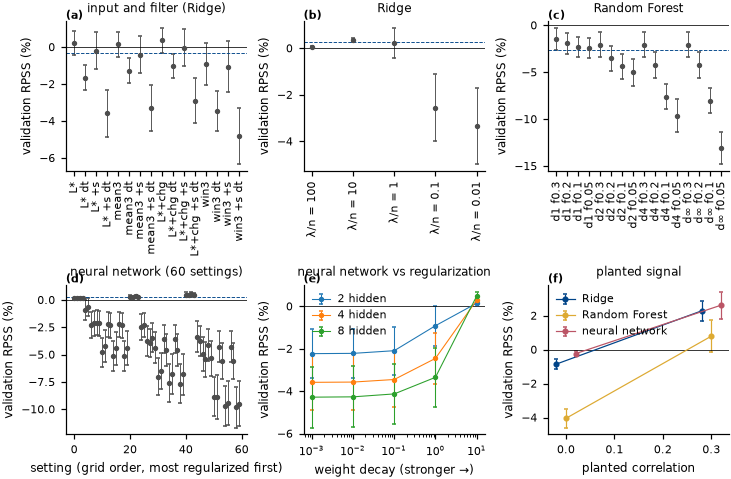

*RPSS de validação (treino 1981–1995, validação 1996–2010, quantis do treino; média e erro-padrão entre os 15 anos de validação) de cada configuração: (a) entrada e filtro, com a Ridge (L*: índice em L*; mean3: média de 3 meses; L*+chg: índice e variação em 3 meses; win3: os 3 meses; +s: interação com o mês; dt: sem tendência); (b) penalidade da Ridge, da mais forte à mais fraca; (c) profundidade (d1 a d∞) e folha mínima (f0.3 a f0.05) da Random Forest; (d) as configurações da rede neural; (e) rede neural contra o decaimento de pesos; (f) sinal plantado. Linha tracejada: um erro-padrão abaixo da melhor configuração do painel. Se a melhor configuração é a mais regularizada, a habilidade converge para a da climatologia (RPSS = 0). Arquivos: `resultados/completo/figuras/F14_calibracao.png` e `.pdf` (169 × 111 mm).*

#### Síntese numérica

- Entrada escolhida: índice em L*, índice bruto (RPSS de validação +0,22 %; melhor da etapa +0,36 %).
- Ridge: {"penalidade_por_mes": 10,0} (RPSS de validação +0,35 %; melhor +0,35 %).
- Random Forest: {"profundidade": 1, "folha": 0,3, "arvores": 100} (RPSS de validação −1,48 %; melhor −1,48 %; a melhor é a mais regularizada da grade).
- Rede neural: {"oculta": 4, "decaimento": 10,0, "passagens": 200, "ativacao": "tanh", "taxa": 0,01} (RPSS de validação +0,29 %; melhor +0,51 %).
- Sinal plantado 0,0, Ridge: RPSS −0,85 % (erro-padrão 0,31) com {"penalidade_por_mes": 100,0}; com a configuração dos dados reais, −0,89 %; defasagem plantada recuperada em 4 % dos casos.
- Sinal plantado 0,0, Random Forest: RPSS −4,05 % (erro-padrão 0,55) com {"profundidade": 1, "folha": 0,3, "arvores": 100}; com a configuração dos dados reais, −4,05 %; defasagem plantada recuperada em 4 % dos casos.
- Sinal plantado 0,0, Rede neural: RPSS −0,24 % (erro-padrão 0,13) com {"oculta": 2, "decaimento": 10,0, "passagens": 200, "ativacao": "tanh", "taxa": 0,01}; com a configuração dos dados reais, −0,26 %; defasagem plantada recuperada em 4 % dos casos.
- Sinal plantado 0,3, Ridge: RPSS +2,28 % (erro-padrão 0,59) com {"penalidade_por_mes": 1,0}; com a configuração dos dados reais, −1,18 %; defasagem plantada recuperada em 63 % dos casos.
- Sinal plantado 0,3, Random Forest: RPSS +0,79 % (erro-padrão 0,93) com {"profundidade": 1, "folha": 0,3, "arvores": 100}; com a configuração dos dados reais, +0,79 %; defasagem plantada recuperada em 63 % dos casos.
- Sinal plantado 0,3, Rede neural: RPSS +2,61 % (erro-padrão 0,80) com {"oculta": 2, "decaimento": 1,0, "passagens": 200, "ativacao": "tanh", "taxa": 0,01}; com a configuração dos dados reais, +0,09 %; defasagem plantada recuperada em 63 % dos casos.

### Relatório parcial 6 · 30/10/2026 19:47 · fim da Seção 4

Modo completo. Tempo decorrido: 8 min. Término geral previsto: 31/10/2026 12:18.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | concluída | 259 / 259 | 6 min | 0 min | — |
| Seção 5 | aguardando | 0 / 9 | 0 min | 0 min (a priori) | 30/10 19:47 |
| Seção 6 | aguardando | 0 / 54 | 0 min | 1 min (a priori) | 30/10 19:48 |
| Seção 7 | aguardando | 0 / 54 | 0 min | 2 min (a priori) | 30/10 19:50 |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 19:57 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 30/10 23:35 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 12:17 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 12:18 |

Últimos registros:
- 2026-10-30T22:43:16+00:00 | Seção 4: Rede neural escolhido: {'oculta': 4, 'decaimento': 10.0, 'passagens': 200, 'ativacao': 'tanh', 'taxa': 0.01}
- 2026-10-30T22:47:19+00:00 | Seção 4: entrada {'entrada': 'pontual', 'sazonal': False, 'filtro': 'bruto'}; treino único; escolhas gravadas em registros/calibracao.json.
- 2026-10-30T22:47:24+00:00 | Seção 4: concluída em 6 min.



In [12]:
# =============================================================================
# 4.3 Tabelas, figuras e síntese da calibração. Lê apenas o que 4.2 calculou e gravou.
# =============================================================================
ROTULO_ENTRADA_PT = {'pontual': 'índice em L*', 'media3': 'média dos 3 meses que terminam em L*',
                     'tendencia': 'índice em L* e variação em 3 meses',
                     'janela3': 'os 3 meses que terminam em L*'}
CURTO_ENTRADA = {'pontual': 'L*', 'media3': 'mean3', 'tendencia': 'L*+chg', 'janela3': 'win3'}
TEXTO_VALIDACAO = (f"treino {CAL_CFG['treino'][0]}–{CAL_CFG['treino'][1]}, validação "
                   f"{CAL_CFG['validacao'][0]}–{CAL_CFG['validacao'][1]}, quantis do treino")

_e2 = ETAPA2.drop(columns='ordem').assign(entrada=ETAPA2.entrada.map(ROTULO_ENTRADA_PT))
_e2['escolhida'] = ((ETAPA2.entrada == ENTRADA['entrada']) & (ETAPA2.sazonal == ENTRADA['sazonal'])
                    & (ETAPA2.filtro == ENTRADA['filtro'])).to_numpy()
tabela(_e2, 'calibracao_entrada', 'Calibração, etapa 2: vetor de entrada e filtro',
       f'RPSS de validação (%) da Ridge ({TEXTO_VALIDACAO}): média dos 15 anos de validação, '
       'cada ano somando os 27 alvos, casos e índices; erro-padrão entre os anos. Sazonal: '
       'interação do índice com o seno e o cosseno do mês. Filtro: índice bruto ou sem a '
       'tendência linear estimada no treino. Escolhida: a mais simples a até um erro-padrão da '
       'melhor (regra heurística, fixada antes).', n=16)
linhas = []
for metodo in MODELOS:
    for _, r in ETAPA3[metodo].iterrows():
        linhas.append({'método': metodo, 'configuração': json.dumps(r['parametros'],
                                                                   ensure_ascii=False),
                       'RPSS (%)': r['RPSS (%)'], 'erro-padrão': r['erro-padrão'],
                       'segundos': r['segundos'], 'escolhida': r['parametros'] == ESCOLHA[metodo]})
ETAPA3_TAB = pd.DataFrame(linhas)
tabela(ETAPA3_TAB, 'calibracao_hiperparametros', 'Calibração, etapa 3: hiperparâmetros',
       f'RPSS de validação (%) de cada configuração ({TEXTO_VALIDACAO}), com a entrada da etapa 2. '
       'As grades vão até configurações tão regularizadas que a previsão se aproxima da '
       f'climatologia; Random Forest com {CAL_CFG["rf_arvores"]} árvores; rede neural com média '
       f'de {REDES} redes, como na aplicação. Escolhida: a mais simples a até um erro-padrão da '
       'melhor do modelo.', n=48)
tabela(SINAL_PLANTADO, 'sinal_plantado', 'Ensaio sintético da calibração (sinal plantado)',
       'Diagnóstico da calibração com uma realização do ruído; não estima o poder do teste, '
       'porque o teste de hipótese não é repetido e a forma de entrada do índice é a escolhida '
       'nos dados reais. Calibração repetida com a classe de cada mês gerada a partir do índice na '
       'defasagem da Seção 2, com correlação plantada de 0 (sem sinal) ou 0,3 (sinal fraco) e '
       'climatologia de 20 % em cada classe: defasagem reaferida em 1981–1995, grade de cada '
       'modelo e regra de um erro-padrão. RPSS (%): configuração escolhida nos dados sintéticos; '
       'com correlação 0, o esperado é zero ou negativo; com 0,3, positivo. Também: a melhor da '
       'grade e a configuração escolhida nos dados reais, aplicada aos sintéticos. Defasagem '
       'recuperada: fração em que a defasagem aferida no treino coincidiu com a plantada.')
ESCOLHA_TAB = pd.DataFrame([
    {'item': 'entrada', 'escolha': ROTULO_ENTRADA_PT[ENTRADA['entrada']]},
    {'item': 'interação com o mês do ano', 'escolha': 'sim' if ENTRADA['sazonal'] else 'não'},
    {'item': 'filtro do índice', 'escolha': 'sem tendência' if ENTRADA['filtro'] == 'sem_tendencia'
     else 'bruto'},
    {'item': 'treino', 'escolha': 'único, com anos hidrológicos inteiros dentro das janelas civis '
     '(jan/1981–dez/2010 na aplicação; jan/1981–dez/1995 no treino e jan/1996–dez/2010 na '
     'validação da calibração)'},
    {'item': 'redes por previsão', 'escolha': str(REDES)},
    *[{'item': f'hiperparâmetros: {m}', 'escolha': json.dumps(ESCOLHA[m], ensure_ascii=False)}
      for m in MODELOS],
    *[{'item': f'cortes ({r["alvo"]}): {papel}', 'escolha': r[papel]}
      for r in CORTES_CAL.to_dict('records') for papel in
      ('treino da calibração', 'validação da calibração', 'treino final', 'teste')]])
tabela(ESCOLHA_TAB, 'calibracao_escolhas', 'Configuração usada nas Seções 6 a 10',
       'Escolhas da calibração, gravadas em registros/calibracao.json antes de o teste ser aberto. '
       'Cortes: meses civis de cada papel; só entram anos hidrológicos com os 12 meses dentro da '
       'janela; a escolha compartilhada termina antes do primeiro mês de teste de qualquer alvo, '
       'e a execução para se essa ordem não se verificar.')

fig, axs = plt.subplots(2, 3, figsize=(7.0, 4.6), squeeze=False)
_fr = ETAPA3['Random Forest'].parametros
paineis = [(axs[0, 0], ETAPA2, [f"{CURTO_ENTRADA[r.entrada]}{' +s' if r.sazonal else ''}"
                                f"{' dt' if r.filtro == 'sem_tendencia' else ''}"
                                for r in ETAPA2.itertuples()], 'input and filter (Ridge)'),
           (axs[0, 1], ETAPA3['Ridge'], [f"λ/n = {p['penalidade_por_mes']:g}"
                                         for p in ETAPA3['Ridge'].parametros], 'Ridge'),
           (axs[0, 2], ETAPA3['Random Forest'], [f"d{p['profundidade'] or '∞'} f{p['folha']:g}"
                                                 for p in _fr], 'Random Forest'),
           (axs[1, 0], ETAPA3['Rede neural'], [None] * len(ETAPA3['Rede neural']),
            f"neural network ({len(ETAPA3['Rede neural'])} settings)")]
for ax, d, rotulos, titulo in paineis:
    x = np.arange(len(d))
    melhor = d['RPSS (%)'].idxmax()
    ax.errorbar(x, d['RPSS (%)'], yerr=d['erro-padrão'], fmt='o', ms=2.5, color='0.3', lw=0.6,
                capsize=1.2)
    ax.axhline(d.loc[melhor, 'RPSS (%)'] - d.loc[melhor, 'erro-padrão'], color=COR['TSA'],
               lw=0.6, ls='--')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_title(titulo)
    if rotulos[0] is not None:
        ax.set_xticks(x, rotulos, rotation=90, fontsize=6)
    else:
        ax.set_xlabel('setting (grid order, most regularized first)')
    ax.set_ylabel('validation RPSS (%)')
# rede: RPSS contra o decaimento de pesos, para cada número de neurônios (passagens e ativação
# escolhidas)
ax = axs[1, 1]
d = ETAPA3['Rede neural']
esc = ESCOLHA['Rede neural']
for o in CAL_CFG['rede_oculta']:
    sel = [p['oculta'] == o and p['passagens'] == esc['passagens']
           and p['ativacao'] == esc['ativacao'] for p in d.parametros]
    dd = d[sel]
    ax.errorbar([p['decaimento'] for p in dd.parametros], dd['RPSS (%)'], yerr=dd['erro-padrão'],
                fmt='o-', ms=2.5, lw=0.7, capsize=1.2, label=f'{o} hidden')
ax.set_xscale('log')
ax.axhline(0, color='k', lw=0.5)
ax.set(xlabel='weight decay (stronger →)', ylabel='validation RPSS (%)',
       title='neural network vs regularization')
ax.legend(loc='best', fontsize=6)
ax = axs[1, 2]
for k, metodo in enumerate(MODELOS):
    d = SINAL_PLANTADO[SINAL_PLANTADO['método'] == metodo]
    ax.errorbar(d['correlação plantada'] + (k - 1) * 0.02, d['RPSS (%)'], yerr=d['erro-padrão'],
                fmt='o-', ms=3, lw=0.8, color=COR[metodo], capsize=1.5, label=EN[metodo])
ax.axhline(0, color='k', lw=0.5)
ax.set(xlabel='planted correlation', ylabel='validation RPSS (%)', title='planted signal')
ax.legend(loc='upper left', fontsize=6)
figura(fig, 'calibracao', 'Calibração em 1981–2010',
       f'RPSS de validação ({TEXTO_VALIDACAO}; média e erro-padrão entre os 15 anos de '
       'validação) de cada configuração: (a) entrada e filtro, com a Ridge (L*: índice em L*; '
       'mean3: média de 3 meses; L*+chg: índice e variação em 3 meses; win3: os 3 meses; +s: '
       'interação com o mês; dt: sem tendência); (b) penalidade da Ridge, da mais forte à mais '
       'fraca; (c) profundidade (d1 a d∞) e folha mínima (f0.3 a f0.05) da Random Forest; (d) as '
       'configurações da rede neural; (e) rede neural contra o decaimento de pesos; (f) sinal '
       'plantado. Linha tracejada: um erro-padrão abaixo da melhor configuração do painel. Se a '
       'melhor configuração é a mais regularizada, a habilidade converge para a da climatologia '
       '(RPSS = 0).')

linhas = [f"Entrada escolhida: {ROTULO_ENTRADA_PT[ENTRADA['entrada']]}"
          f"{', com interação com o mês' if ENTRADA['sazonal'] else ''}, índice "
          f"{'sem tendência' if ENTRADA['filtro'] == 'sem_tendencia' else 'bruto'} "
          f"(RPSS de validação {_e2[_e2.escolhida]['RPSS (%)'].iloc[0]:+.2f} %; melhor da etapa "
          f"{ETAPA2['RPSS (%)'].max():+.2f} %)."]
for metodo in MODELOS:
    d = ETAPA3_TAB[ETAPA3_TAB['método'] == metodo]
    e = d[d.escolhida].iloc[0]
    extremo = d['RPSS (%)'].idxmax() == d.index[0]
    linhas.append(f"{metodo}: {e['configuração']} (RPSS de validação {e['RPSS (%)']:+.2f} %; "
                  f"melhor {d['RPSS (%)'].max():+.2f} %"
                  + ('; a melhor é a mais regularizada da grade' if extremo else '') + ').')
for _, r in SINAL_PLANTADO.iterrows():
    linhas.append(f"Sinal plantado {r['correlação plantada']:.1f}, {r['método']}: RPSS "
                  f"{r['RPSS (%)']:+.2f} % (erro-padrão {r['erro-padrão']:.2f}) com "
                  f"{r['configuração escolhida']}; com a configuração dos dados reais, "
                  f"{r['RPSS com a configuração dos dados reais (%)']:+.2f} %; defasagem "
                  f"plantada recuperada em {r['defasagem plantada recuperada (%)']:.0f} % "
                  'dos casos.')
sintese(linhas)
PROGRESSO.concluir('Seção 4')

### 4.4 Results and discussion

Each panel of the figure shows the validation skill of the configurations of one stage; the dashed line marks one standard error below the best, and the chosen configuration is the simplest one above it, by the rule fixed beforehand. When the validation skill of every configuration lies within one standard error of zero, the rule leads to the most regularized configurations, and the forecasts stay close to the reference. This is an outcome of the 1996–2010 validation, not a later choice, and regularization is not relaxed afterwards in search of significance. The synthetic experiment shows how calibration reacts to a signal of 0.3 in this noise realization; because it does not repeat the hypothesis test and keeps the input form of the real data, it does not say whether the full protocol would confirm that gain.

### 4.5 Conclusion

The section delivers the configuration of each model, stored in `registros/calibracao.json` before any 2011–2025 forecast, and the three models used in Sections 6 to 10.

### 4.6 References

BERGMEIR, C.; HYNDMAN, R. J.; KOO, B. A note on the validity of cross-validation for evaluating autoregressive time series prediction. **Computational Statistics & Data Analysis**, v. 120, p. 70-83, 2018. DOI: 10.1016/j.csda.2017.11.003.

BREIMAN, L. Random forests. **Machine Learning**, v. 45, p. 5-32, 2001. DOI: 10.1023/A:1010933404324.

EPSTEIN, E. S. A scoring system for probability forecasts of ranked categories. **Journal of Applied Meteorology**, v. 8, p. 985-987, 1969. DOI: 10.1175/1520-0450(1969)008<0985:ASSFPF>2.0.CO;2.

HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. **The elements of statistical learning**: data mining, inference, and prediction. 2. ed. New York: Springer, 2009.

HOERL, A. E.; KENNARD, R. W. Ridge regression: biased estimation for nonorthogonal problems. **Technometrics**, v. 12, n. 1, p. 55-67, 1970. DOI: 10.1080/00401706.1970.10488634.

LOSHCHILOV, I.; HUTTER, F. Decoupled weight decay regularization. In: INTERNATIONAL CONFERENCE ON LEARNING REPRESENTATIONS, 7., 2019, New Orleans. **Proceedings** [...]. 2019.

WORLD METEOROLOGICAL ORGANIZATION. Attachment II.8: Standardized Verification System (SVS) for Long-Range Forecasts (LRF). In: WORLD METEOROLOGICAL ORGANIZATION. **Manual on the Global Data-processing and Forecasting System**. Geneva: WMO, 2007. (WMO-No. 485).

---

# Section 5. Climatology as a forecast and the common evaluation protocol

### 5.1 Theoretical and methodological basis

**Scientific question.** How does climatology perform in forecasting the quintile class of each month of 2011–2025, and does the index phase at the assessed lag, without any model, improve that forecast?

**Introduction.** The skill of a probabilistic forecast is measured relative to a simple reference, climatology, with the ranked probability score (Epstein, 1969), which penalizes probability placed in classes far from the observed one more heavily; the WMO standardized verification system uses this score and the area under the ROC curve (WMO, 2007; Mason and Graham, 2002).

**Rationale.** Climatology N is the reference of N-index and the common scale of the comparison between methods. In the models (Sections 6 to 8), the reference of the hypothesis is the control of the same model without the index. A climatology conditioned on the index phase shows whether the index helps even without a model.

**Hypotheses.** For each target, case and index: H0, the RPSS of N-index over N does not exceed that obtained with the time-shifted index; H1, it does. Not rejecting H0 does not demonstrate the absence of an effect; the 95% CI expresses the uncertainty of the estimate; it neither proves the absence of an effect nor replaces the adopted test.

**Objective.** Build the test samples common to all methods, compute N and N-index for each test month, and define the metrics and tests used in Sections 5 to 9.

**Data and methodology.**
- Forecast scale: the whole target. Each sample is one month of a case, and the observed class comes from the quantile `u` of the target's mean rainfall, the same series on which Section 2 assessed the lags. Roles by whole hydrological year within each calendar window: training Jan 1981–Dec 2010 (30 years in NNEB; 29 in INEB and ENEB) and test Jan 2011–Dec 2025 (15 and 14 years).
- N: the frequency of each class in the same month in the 1981–2010 reference (20% each, except for ties), which contains no test year.
- N-index: the frequency of each class in the training months of the case in which the index, at L* (Section 2), was in the same phase: below its q20, between q20 and q80 or above q80 in the training months.
- Metrics: RPSS `100 × (1 − RPS / RPS of N)` (%); hit rate of the most likely class (%; chance = 20%; ties split the hit); area under the ROC curve for the events very dry (Q1), dry or very dry (Q1–Q2), wet or very wet (Q4–Q5) and very wet (Q5) (chance = 0.5).
- Test unit: the test hydrological year, because months of the same year are not independent; RPS and RPS of N are summed by year.
- 95% CI: joint resampling of circular 3-year blocks (Künsch, 1989; Politis and Romano, 1992), with fixed seeds, recomputing the numerator and denominator of the RPSS in each replicate. Three years is a heuristic choice fixed beforehand; Section 9 shows the sensitivity to 2 and 4 years. The 95% CI is conditional on the forecasts produced: it keeps the calibrated configuration, L* and the training fixed and resamples only the test years; it does not include the uncertainty of calibration or of the choice of L*, and it is not simultaneous across the 81 combinations.
- Reference of the hypothesis in the models (Sections 6 to 8): the same model without the index (same hyperparameters, training and seeds, with a constant input). The RPSS measures the benefit of giving the index to that model; on its own, it does not show a gain over the empirical climatology, and the RPSS of different models are not compared with each other.
- p-value of the hypothesis (groups A0 and A): circular shift of the whole index series (1979–2025) relative to rainfall, by 24 months or more, in 4-month steps (130 shifts, no random draws). In each shift the following are repeated: the index preparation in training, the choice of L* (L1 to L12) in training, the model fit with the already calibrated hyperparameters, the no-index control and the test RPSS. Calibration (input form and hyperparameters) and the rainfall classes, which do not depend on the index, are not repeated. H0 represented: the observed RPSS does not exceed those obtained with the index out of its temporal alignment with rainfall, keeping the rainfall series and the internal order of the index (autocorrelation is broken only at the circular seam). Only shifts that are multiples of 12 months (one in three, with a 4-month step) keep the calendar month of each index value; in the others, the position of the index in the annual cycle changes. Inference is conditional on the input form and hyperparameters from calibration. The shift also breaks the alignment of trends between index and rainfall, so a shared trend counts as association; a rejection indicates that temporal alignment matters, without identifying which shared structure produces it. The p-value is the fraction of configurations (observed and shifted) with RPSS greater than or equal to the observed one; Benjamini and Hochberg q-values over the 27 comparisons of each method.
- Resolution: the 4-month step was chosen for computational cost, not for a statistical reason. The smallest possible p-value is 1/131 ≈ 0.0076; with Benjamini and Hochberg over 27 comparisons, if k combinations sit at the floor, the smallest possible q for them is 27/(131·k): 0.206, 0.103, 0.069, 0.052 and 0.041 for k = 1 to 5. With signals restricted to a few combinations, q < 0.05 requires at least 5 of them at the floor; the observed p- and q-values are reported. This is a resolution limitation, separate from the validity of the test. An analysis with a monthly step, if done, would be a sensitivity analysis decided after examining the test and presented alongside this result.
- p-value of the secondary groups (C, E): sign flip of the annual differences, with full enumeration; the false-positive rate of this sign flip is measured under the same null and reported in Section 9.
- Trend sensitivity: if the empirical check of Section 9 (ridge) rejects above 5% (binomial 95% CI entirely above) when the index shares only the linear trend with rainfall, a gain with q < 0.05 in that combination cannot be attributed to interannual variability and is reclassified as inconclusive for all three methods.
- Final fit of each model (used in Sections 6 to 8): configuration from Section 4, a single training with the hydrological years of Jan 1981–Dec 2010, L* assessed in those years, mean of 3 networks for the neural network.

**Limitations declared before the run.** There are 14 or 15 test hydrological years, depending on the target; small gains may not be distinguishable from chance, and the 95% CI expresses the uncertainty of the estimate; it neither proves the absence of an effect nor replaces the adopted test. N-index uses about 6 training years in each extreme phase; with so few years, the frequencies by phase are noisy. The test period was examined during the development of the study; the choices were fixed with months up to Dec 2010, but this prior exposure is declared.

**Outputs.** Tables: training and test months; performance of N and N-index; N-index − N comparison (with the null p-value); classes in the test period; test series. Figures: RPSS of N-index; monthly class of the whole target in 2011–2025.

In [13]:
# =============================================================================
# 5.2 Processamento: contrato comum de avaliação na escala do alvo inteiro (um mês por amostra;
# a previsão é a probabilidade de cada classe de quintil, com a referência 1981–2010), métricas,
# IC95 por reamostragem conjunta de blocos de anos, nulo por deslocamento circular do índice
# (procedimento inteiro repetido) e as previsões N e N-índice em cada mês
# de teste. Não gera figuras.
# =============================================================================
PROGRESSO.iniciar('Seção 5', N_COMB)
R_AVAL = CFG['avaliacao']['reamostras']
ALFA = CFG['avaliacao']['alfa']
BLOCO_ANOS = CFG['avaliacao']['bloco_anos']
K_MIN = CFG['defasagem']['deslocamento_minimo_meses']
DESLOC_NULO = np.arange(K_MIN, len(Z_IDX) - K_MIN + 1, CFG['avaliacao']['passo_nulo'])
PAPEIS = ('treino', 'teste')


def particoes(alvo, caso):
    """Amostras de cada papel: treino (1981–2010) e teste (2011–2025)."""
    return {p: montar_amostras(alvo, caso, ANOS[alvo][p]) for p in PAPEIS}


def defasagem(alvo, caso, indice, versao):
    """L* aferida na Seção 2 (versão 'aferida') ou 1 mês (versão 'L1')."""
    return DEFASAGENS[(alvo, caso)]['L*'][indice] if versao == 'aferida' else 1


# ----- arquivos de amostras e de previsões -----
def arquivo_amostras(alvo, caso):
    """Arquivo com as amostras de teste de um alvo e caso."""
    return PASTAS['preditos'] / f'amostras_{alvo}_{caso}.npz'


def ler_amostras(alvo, caso):
    """Amostras de teste gravadas nesta seção, como dicionário."""
    with np.load(arquivo_amostras(alvo, caso)) as f:
        return {c: f[c] for c in CAMPOS_AMOSTRA}


def chave_unidade(metodo, alvo, caso, indice, versao):
    """Nome dos arquivos de uma unidade (método, alvo, caso, índice, versão)."""
    return f"{metodo.replace(' ', '')}_{alvo}_{caso}_{indice.replace('.', '')}_{versao}"


def gravar_unidade(chave, prob_teste, info):
    """Grava as probabilidades de teste (meses × 5) e o marcador da unidade."""
    salvar_npz(PASTAS['preditos'] / f'{chave}.npz', teste=prob_teste.astype('float32'))
    salvar_json(PASTAS['preditos'] / f'{chave}.json', info)


# número de meses e identidade (SHA-256 dos meses) das amostras de teste de cada alvo e caso,
# gravadas nesta execução; toda unidade reaproveitada precisa coincidir com elas
ESPERADO_TESTE = {}
CAMPOS_UNIDADE = {
    'modelo': ['metodo', 'alvo', 'caso', 'indice', 'versao', 'defasagem', 'hiperparametros',
               'entrada', 'hash_teste', 'curva_resposta'],
    'controle': ['metodo', 'versao', 'indice', 'hash_teste'],
    'Climatologia': ['metodo', 'versao', 'hash_teste']}


def unidade_feita(metodo, alvo, caso, indice, versao):
    """True se a unidade está gravada e íntegra: probabilidades finitas, em [0, 1], cada linha
    somando 1 e um mês por amostra de teste desta execução; marcador com os campos obrigatórios,
    o mesmo método, índice e versão, e a mesma identidade das amostras de teste."""
    chave = chave_unidade(metodo, alvo, caso, indice, versao)
    n, h = ESPERADO_TESTE[(alvo, caso)]
    if metodo == 'Climatologia':
        tipo, versao_gravada = 'Climatologia', 'N' if indice == '-' else f'N-{indice}'
    else:
        tipo, versao_gravada = ('controle' if versao == 'controle' else 'modelo'), versao
    return (reaproveitar(PASTAS['preditos'] / f'{chave}.npz', ['teste'],
                         conferir=lambda a: prob_validas(a['teste'], n))
            and reaproveitar(PASTAS['preditos'] / f'{chave}.json', CAMPOS_UNIDADE[tipo],
                             conferir=lambda i: i['hash_teste'] == h and i['metodo'] == metodo
                             and i['versao'] == versao_gravada
                             and (tipo == 'Climatologia' or i['indice'] == indice)))


def ler_unidade(metodo, alvo, caso, indice, versao):
    """(probabilidades de teste, marcador). Interrompe se a unidade faltar ou não passar na
    conferência (o arquivo inválido é renomeado e refeito na próxima execução)."""
    chave = chave_unidade(metodo, alvo, caso, indice, versao)
    if not unidade_feita(metodo, alvo, caso, indice, versao):
        raise RuntimeError(f'Unidade {chave} ausente ou inválida. Rode o notebook de novo para '
                           'refazê-la.')
    with np.load(PASTAS['preditos'] / f'{chave}.npz') as f:
        return f['teste'].astype('float64'), ler_json(PASTAS['preditos'] / f'{chave}.json')


# ----- métricas e testes -----
def por_ano(am, prob):
    """Somas por ano hidrológico de teste: RPS da previsão e de N, acertos da classe mais
    provável e número de meses."""
    anos, inv = np.unique(am['h'], return_inverse=True)
    r, rn = rps(prob, am['cl']), rps(am['clim'], am['cl'])
    return dict(anos=anos, rps=np.bincount(inv, r), rps_n=np.bincount(inv, rn),
                acerto=np.bincount(inv, acerto_mais_provavel(prob, am['cl'])),
                peso=np.bincount(inv).astype(float))


def blocos_de_anos(n, nome, bloco=None):
    """Índices (reamostras, n) de anos sorteados em blocos circulares (Politis e Romano, 1992)
    de 'bloco' anos consecutivos (padrão BLOCO_ANOS; semente fixa)."""
    bloco = bloco or BLOCO_ANOS
    rng = np.random.default_rng(semente(nome))
    n_blocos = int(np.ceil(n / bloco))
    inicios = rng.integers(0, n, size=(R_AVAL, n_blocos))
    return ((inicios[:, :, None] + np.arange(bloco)) % n).reshape(R_AVAL, -1)[:, :n]


def ic_razao(num, den, nome, escala=100.0, bloco=None):
    """Estimativa escala × (1 − Σnum/Σden) e IC95 e erro-padrão por reamostragem conjunta de
    blocos de anos: numerador e denominador recalculados em cada réplica."""
    idx = blocos_de_anos(len(num), nome, bloco)
    est = escala * (1 - num.sum() / den.sum())
    rep = escala * (1 - num[idx].sum(1) / den[idx].sum(1))
    return float(est), float(np.percentile(rep, 2.5)), float(np.percentile(rep, 97.5)), \
        float(rep.std(ddof=1))


def metricas(am, prob, nome):
    """RPSS (IC95 e p da troca de sinal por ano), acerto da classe mais
    provável e área ROC de cada evento."""
    a = por_ano(am, prob)
    n, W = len(a['anos']), a['peso'].sum()
    hab, lo, hi, ep = ic_razao(a['rps'], a['rps_n'], nome)
    contrib = 100 * n * (a['rps_n'] - a['rps']) / a['rps_n'].sum()
    saida = {'RPSS (%)': hab, 'IC95 inferior': lo, 'IC95 superior': hi,
             'p (troca de sinal)': troca_de_sinal(contrib),
             'acerto da classe mais provável (%)': float(100 * a['acerto'].sum() / W)}
    for evento, ks in EVENTOS.items():
        saida[f'ROC {evento}'] = area_roc(prob[:, ks].sum(1), np.isin(am['cl'], ks))
    saida.update({'anos de teste': n, 'meses de teste': int(W)})
    return saida


def comparar(am, pa, pb, nome):
    """Diferença a − b de RPSS e de acerto (p.p.), com IC95 por reamostragem conjunta de blocos
    de anos e p da troca de sinal por ano de teste."""
    A, B = por_ano(am, pa), por_ano(am, pb)
    n = len(A['anos'])
    idx = blocos_de_anos(n, nome)
    rn = A['rps_n']
    dif = 100 * (B['rps'].sum() - A['rps'].sum()) / rn.sum()
    rep = 100 * (B['rps'][idx].sum(1) - A['rps'][idx].sum(1)) / rn[idx].sum(1)
    ac = 100 * (A['acerto'].sum() - B['acerto'].sum()) / A['peso'].sum()
    rep_ac = 100 * (A['acerto'][idx].sum(1) - B['acerto'][idx].sum(1)) / A['peso'][idx].sum(1)
    return {'diferença de RPSS (p.p.)': float(dif),
            'IC95 inferior': float(np.percentile(rep, 2.5)),
            'IC95 superior': float(np.percentile(rep, 97.5)),
            'p': troca_de_sinal(100 * n * (B['rps'] - A['rps']) / rn.sum()),
            'diferença de acerto (p.p.)': float(ac),
            'IC95 inferior (acerto)': float(np.percentile(rep_ac, 2.5)),
            'IC95 superior (acerto)': float(np.percentile(rep_ac, 97.5)),
            'p (acerto)': troca_de_sinal(100 * n * (A['acerto'] - B['acerto'])
                                         / A['peso'].sum())}


def q_por_grupo(df, coluna_grupo, coluna_p='p'):
    """Valores q de Benjamini-Hochberg dentro de cada grupo de comparações."""
    q = pd.Series(np.nan, index=df.index)
    for _, idx in df.groupby(coluna_grupo).groups.items():
        q.loc[idx] = benjamini_hochberg(df.loc[idx, coluna_p].to_numpy())
    return q


def fase(x, limites):
    """0 abaixo de q20, 1 entre q20 e q80, 2 acima de q80 do índice."""
    return np.where(x < limites[0], 0, np.where(x > limites[1], 2, 1))


def prob_n_indice(tr, x_tr, x_te):
    """Climatologia por fase do índice: frequência de cada classe nos meses de treino em que o
    índice estava na mesma fase (abaixo de q20, entre q20 e q80, acima de q80)."""
    lim = np.quantile(x_tr, [0.2, 0.8])
    f_tr, f_te = fase(x_tr, lim), fase(x_te, lim)
    freq = np.stack([np.bincount(tr.cl[f_tr == f], minlength=K_CLASSES)
                     / max((f_tr == f).sum(), 1) for f in range(3)])
    return freq[f_te], lim, freq, f_tr


# ----- amostras e climatologias N e N-índice -----
LINHAS_AMOSTRAS = []
for alvo in ALVOS:
    for caso in CASOS:
        P = particoes(alvo, caso)
        tr, te = P['treino'], P['teste']
        for papel, a in P.items():
            LINHAS_AMOSTRAS.append({'alvo': alvo, 'caso': caso, 'papel': papel,
                                    'anos': f'{a.h.min()}–{a.h.max()} ({len(np.unique(a.h))})',
                                    'meses': len(a), 'pixels do alvo': len(PESO[alvo]),
                                    **{f'meses em {CLASSES[k][:2]}': int((a.cl == k).sum())
                                       for k in range(K_CLASSES)},
                                    'hash': hash_amostras(a)[:12]})
        salvar_npz(arquivo_amostras(alvo, caso),
                   **{c: getattr(te, c) for c in CAMPOS_AMOSTRA})
        ESPERADO_TESTE[(alvo, caso)] = (len(te), hash_amostras(te))
        gravar_unidade(chave_unidade('Climatologia', alvo, caso, '-', 'N'), te.clim,
                       dict(metodo='Climatologia', versao='N', hash_teste=hash_amostras(te)))
        for j, nome in enumerate(INDICES):
            L = DEFASAGENS[(alvo, caso)]['L*'][nome]
            prob, lim, freq, f_tr = prob_n_indice(tr, Z_IDX[tr.ref + G.D - L, j],
                                                  Z_IDX[te.ref + G.D - L, j])
            gravar_unidade(chave_unidade('Climatologia', alvo, caso, nome, 'N'), prob,
                           dict(metodo='Climatologia', versao=f'N-{nome}', defasagem=int(L),
                                limites_de_fase=[float(v) for v in lim],
                                meses_por_fase=[int((f_tr == f).sum()) for f in range(3)],
                                frequencias=freq.round(4).tolist(),
                                hash_teste=hash_amostras(te)))
        del P, tr, te
        PROGRESSO.avancar('Seção 5')
AMOSTRAS_TAB = pd.DataFrame(LINHAS_AMOSTRAS)


# ----- controle de cada modelo: o mesmo modelo sem o índice -----
def controle(metodo, alvo, caso, indice):
    """Probabilidades de teste do gêmeo sem índice do modelo com o índice em L*: a mesma tarefa,
    com a entrada trocada por zeros de mesma dimensão (mesmos hiperparâmetros, treino, sementes e
    inicializações). Ridge: só o intercepto; Random Forest: as mesmas árvores e os mesmos meses
    sorteados, sem divisões; redes: as mesmas redes com entrada constante. Gravado na Seção 6, 7
    ou 8 como unidade 'controle'."""
    return ler_unidade(metodo, alvo, caso, indice, 'controle')[0]


def com_controle(am, metodo, alvo, caso, indice):
    """Amostras de teste com a referência trocada pelo controle sem índice."""
    return dict(am, clim=controle(metodo, alvo, caso, indice))


# ----- nulo por deslocamento circular do índice: o procedimento inteiro é repetido -----
def rpss_e_troca(am, prob):
    """RPSS (%) de teste e p da troca de sinal por ano."""
    a = por_ano(am, prob)
    n = len(a['anos'])
    return (100 * (1 - a['rps'].sum() / a['rps_n'].sum()),
            troca_de_sinal(100 * n * (a['rps_n'] - a['rps']) / a['rps_n'].sum()))


def nulo_hipotese(metodo):
    """Para cada deslocamento circular da série dos índices (24 meses ou mais, passo fixo, sem
    sorteio): L* reaferido no treino, modelo treinado e teste avaliado, para cada alvo, caso e
    índice. Devolve, por combinação, os RPSS nulos e a fração de p da troca de sinal < 0,05.
    Gravado em registros/ para a retomada."""
    arq = PASTAS['registros'] / f"nulo_{metodo.replace(' ', '').replace('-', '')}.json"
    combos = list(itertools.product(ALVOS, CASOS, INDICES))

    def conferir(o):
        """Um RPSS finito e um p em [0, 1] por deslocamento, em cada combinação."""
        return (set(o) == {f'{a}|{c}|{i}' for a, c, i in combos}
                and all(len(d['rpss']) == len(d['p_troca']) == len(DESLOC_NULO)
                        and np.isfinite(d['rpss']).all()
                        and all(0 <= p <= 1 for p in d['p_troca']) for d in o.values()))
    if reaproveitar(arq, conferir=conferir):
        return ler_json(arq)
    tr = {(a, c): montar_amostras(a, c, ANOS[a]['treino']) for a, c in itertools.product(
        ALVOS, CASOS)}
    te = {(a, c): montar_amostras(a, c, ANOS[a]['teste']) for a, c in itertools.product(
        ALVOS, CASOS)}
    tarefas, chaves = [], []
    for k in DESLOC_NULO:
        base = np.roll(Z_IDX, int(k), axis=0)
        probl = [(a, c, i, aferir_L(tr[(a, c)], a, c, INDICES.index(i), base))
                 for a, c, i in combos]
        if metodo == 'N-índice':
            for a, c, i, L in probl:
                j = INDICES.index(i)
                t1, t2 = tr[(a, c)], te[(a, c)]
                prob = prob_n_indice(t1, base[t1.ref + G.D - L, j], base[t2.ref + G.D - L, j])[0]
                tarefas.append(dict(pr=t2, prob=prob))
                chaves.append((a, c, i))
            continue
        tarefas += montar_tarefas(probl, ENTRADA['entrada'], ENTRADA['sazonal'], ENTRADA['filtro'],
                                  {a: ANOS[a]['treino'] for a in ALVOS},
                                  {a: ANOS[a]['teste'] for a in ALVOS}, versao=f'nulo{k}',
                                  base=base)
        chaves += combos
    if metodo == 'N-índice':
        probs, probs0 = [t['prob'] for t in tarefas], [None] * len(tarefas)
    else:
        probs = prever_tarefas(metodo, ESCOLHA[metodo], tarefas, f'nulo:{metodo}')
        probs0 = prever_tarefas(metodo, ESCOLHA[metodo], sem_indice(tarefas), f'nulo:{metodo}')
    saida = {}
    for (a, c, i), t, P, P0 in zip(chaves, tarefas, probs, probs0):
        am = {k: getattr(t['pr'], k) for k in CAMPOS_AMOSTRA}
        if P0 is not None:
            am['clim'] = P0
        rpss_k, p_k = rpss_e_troca(am, P)
        d = saida.setdefault(f'{a}|{c}|{i}', {'rpss': [], 'p_troca': []})
        d['rpss'].append(float(rpss_k))
        d['p_troca'].append(float(p_k))
    salvar_json(arq, saida)
    return saida


def p_nulo(observado, nulos):
    """Valor-p unilateral: fração das configurações (observada + nulas) com RPSS ≥ o observado."""
    return p_por_maximo(observado, nulos)


# ----- desempenho de N e N-índice e comparação N-índice − N -----
NULO_N = nulo_hipotese('N-índice')
LINHAS_CLIM, LINHAS_A0, SERIE_TESTE = [], [], {}
for alvo, caso in itertools.product(ALVOS, CASOS):
    am = ler_amostras(alvo, caso)
    prev = {v: ler_unidade('Climatologia', alvo, caso, '-' if v == 'N' else v[2:], 'N')
            for v in CLIMATOLOGIAS}
    for v, x in prev.items():
        LINHAS_CLIM.append({'alvo': alvo, 'caso': caso, 'previsão': v,
                            **metricas(am, x[0], f'clim:{alvo}:{caso}:{v}')})
    for v in CLIMATOLOGIAS[1:]:
        cmp_ = comparar(am, prev[v][0], prev['N'][0], f'A0:{alvo}:{caso}:{v}')
        nulos = NULO_N[f'{alvo}|{caso}|{v[2:]}']['rpss']
        cmp_['p (nulo)'] = p_nulo(cmp_['diferença de RPSS (p.p.)'], nulos)
        LINHAS_A0.append({'alvo': alvo, 'caso': caso, 'comparação': f'{v} − N', **cmp_})
    SERIE_TESTE[(alvo, caso)] = pd.DataFrame({'mês': G.tempos[am['ref']], 'quantil u': am['u'],
                                              'classe': [CLASSES[k] for k in am['cl']]})
CLIM = pd.DataFrame(LINHAS_CLIM)
A0 = pd.DataFrame(LINHAS_A0)
A0['q (BH)'] = benjamini_hochberg(A0['p (nulo)'])
registrar(f"Seção 5: amostras gravadas; N-índice melhor que N com q < 0,05 em "
          f"{int(((A0['q (BH)'] < ALFA) & (A0['diferença de RPSS (p.p.)'] > 0)).sum())} "
          f'de {len(A0)} comparações (valor-p pelo nulo de {len(DESLOC_NULO)} deslocamentos).')


# ----- ajuste final de um modelo (usado nas Seções 6 a 8) -----
GRADE_INDICE = np.linspace(-2.5, 2.5, 21)        # valores do índice para a curva de resposta


def atributos_persistentes(v, m, entrada, sazonal):
    """Atributos de um índice que fica no valor v nos meses que a entrada lê."""
    base = {'pontual': [v], 'media3': [v], 'tendencia': [v, 0.0], 'janela3': [v, v, v]}[entrada]
    if sazonal:
        ang = 2 * np.pi * m / 12
        base = base + [v * np.sin(ang), v * np.cos(ang)]
    return base


def ajustar_metodo(metodo, secao):
    """Treina o modelo na configuração da Seção 4 uma única vez com 1981–2010, para cada alvo,
    caso, índice e versão, prevê cada mês de teste e grava as probabilidades. A curva de resposta
    sai do mesmo modelo (os valores da grade vão junto com os meses de teste)."""
    params = ESCOLHA[metodo]
    unidades = [(a, c, i, v) for a, c, i, v in itertools.product(ALVOS, CASOS, INDICES, VERSOES)
                if not (unidade_feita(metodo, a, c, i, v)
                        and (v != 'aferida' or unidade_feita(metodo, a, c, i, 'controle')))]
    PROGRESSO.avancar(secao, N_COMB * len(INDICES) * len(VERSOES) - len(unidades))
    if not unidades:
        return 0
    inicio = time.time()
    tarefas = []
    for v in VERSOES:
        problemas = [(a, c, i, defasagem(a, c, i, v)) for a, c, i, w in unidades if w == v]
        tarefas += montar_tarefas(problemas, ENTRADA['entrada'], ENTRADA['sazonal'],
                                  ENTRADA['filtro'], {a: ANOS[a]['treino'] for a in ALVOS},
                                  {a: ANOS[a]['teste'] for a in ALVOS}, versao=f'{metodo}:{v}')
    for t in tarefas:                      # grade do índice persistente, nos meses do caso
        a, c, _ = t['problema']
        meses = np.array(MESES_CASO[a][c]) - 1
        t['n_teste'], t['n_meses'] = len(t['X_pr']), len(meses)
        X_g = np.array([atributos_persistentes(x, m, ENTRADA['entrada'], ENTRADA['sazonal'])
                        for x in GRADE_INDICE for m in meses])
        t['X_pr'] = np.concatenate([t['X_pr'], X_g])
    probs = prever_tarefas(metodo, params, tarefas, f'final:{metodo}')
    probs0 = prever_tarefas(metodo, params, sem_indice(tarefas), f'final:{metodo}')
    segundos = (time.time() - inicio) / len(unidades)
    iguais = [' '.join(t['problema']) for t, P, P0 in zip(tarefas, probs, probs0)
              if t['chave'].split(':')[1] == 'aferida'
              and np.abs(P[:t['n_teste']] - P0[:t['n_teste']]).max() < 1e-12]
    verificar(f'{metodo}: o modelo com índice difere do controle sem índice',
              not iguais, 'combinações idênticas ao controle: ' + ('; '.join(iguais) or 'nenhuma'))
    registrar(f'{metodo}: nenhuma combinação com o modelo idêntico ao controle sem índice.')
    for t, P, P0 in zip(tarefas, probs, probs0):
        a, c, i = t['problema']
        v = t['chave'].split(':')[1]
        te = ler_amostras(a, c)
        if not np.array_equal(t['pr'].ref, te['ref']):
            raise RuntimeError(f'{metodo} {a} {c} {i} {v}: meses previstos diferentes do teste.')
        curva = P[t['n_teste']:].reshape(len(GRADE_INDICE), t['n_meses'], K_CLASSES).mean(1)
        info = dict(metodo=metodo, alvo=a, caso=c, indice=i, versao=v,
                    defasagem=defasagem(a, c, i, v), hiperparametros=params, entrada=ENTRADA,
                    treino=t['anos_treino'], meses_de_treino=int(t['n_treino']),
                    hash_teste=hash_amostras(Amostras(**{k: te[k] for k in CAMPOS_AMOSTRA})),
                    segundos=round(segundos, 3), curva_resposta=curva.round(5).tolist())
        if v == 'aferida':
            gravar_unidade(chave_unidade(metodo, a, c, i, 'controle'), P0[:t['n_teste']],
                           dict(metodo=metodo, versao='controle', indice=i,
                                hash_teste=info['hash_teste']))
        gravar_unidade(chave_unidade(metodo, a, c, i, v), P[:t['n_teste']], info)
        PROGRESSO.avancar(secao)
    return len(unidades)

Seção 5: amostras gravadas; N-índice melhor que N com q < 0,05 em 0 de 27 comparações (valor-p pelo nulo de 130 deslocamentos).


**Tabela 21. Meses de treino e de teste por alvo e caso**

,alvo,caso,papel,anos,meses,pixels do alvo,meses em Q1,meses em Q2,meses em Q3,meses em Q4,meses em Q5,hash
0,NNEB,ano hidrológico,treino,1981–2010 (30),360,22127,72,72,72,72,72,c5b5d89abc3a
1,NNEB,ano hidrológico,teste,2011–2025 (15),180,22127,30,43,46,28,33,3082bc4eef7b
2,NNEB,estação chuvosa,treino,1981–2010 (30),150,22127,30,30,30,30,30,a3a43305edcb
3,NNEB,estação chuvosa,teste,2011–2025 (15),75,22127,9,19,17,18,12,3d0df61669f0
4,NNEB,estação seca,treino,1981–2010 (30),210,22127,42,42,42,42,42,bdb0ec98cfef
5,NNEB,estação seca,teste,2011–2025 (15),105,22127,21,24,29,10,21,a0088ba0d295
6,INEB,ano hidrológico,treino,1981–2009 (29),348,21179,70,71,67,70,70,930720de4017
7,INEB,ano hidrológico,teste,2011–2024 (14),168,21179,41,40,27,29,31,c2af7ecb9ad3
8,INEB,estação chuvosa,treino,1981–2009 (29),174,21179,35,35,34,35,35,9d9c6b624601
9,INEB,estação chuvosa,teste,2011–2024 (14),84,21179,21,17,12,15,19,0feb172a5a34


*Cada amostra é um mês com todo o território do alvo: a classe observada vem do quantil u da chuva média do alvo, ponderada pela área, em relação a 1981–2010. Papéis por ano hidrológico: treino (1981–2010) e teste (2011–2025). Colunas Q1 a Q5: meses observados em cada classe. Hash: SHA-256 dos meses, o mesmo para todos os métodos e versões. Arquivo: `resultados/completo/tabelas/T21_amostras.csv`.*

**Tabela 22. Desempenho da climatologia (N) e da climatologia por fase do índice (N-índice), 2011–2025**

,alvo,caso,previsão,RPSS (%),IC95 inferior,IC95 superior,p (troca de sinal),acerto da classe mais provável (%),ROC muito seco (Q1),ROC seco ou muito seco (Q1–Q2),ROC chuvoso ou muito chuvoso (Q4–Q5),ROC muito chuvoso (Q5),anos de teste,meses de teste
0,NNEB,ano hidrológico,N,0.0,-0.0,0.0,0.594,20.0,0.500,0.500,0.500,0.500,15,180
1,NNEB,ano hidrológico,N-NINO3.4,-2.7,-11.5,6.2,0.579,23.3,0.559,0.566,0.552,0.573,15,180
2,NNEB,ano hidrológico,N-TSA,0.9,-3.5,5.0,0.648,16.1,0.555,0.541,0.580,0.453,15,180
3,NNEB,ano hidrológico,N-AMM,-0.3,-3.1,3.2,0.887,22.2,0.595,0.573,0.533,0.483,15,180
4,NNEB,estação chuvosa,N,0.0,-0.0,0.0,0.980,20.0,0.500,0.500,0.500,0.500,15,75
5,NNEB,estação chuvosa,N-NINO3.4,-10.7,-31.3,5.6,0.247,16.4,0.534,0.508,0.496,0.517,15,75
6,NNEB,estação chuvosa,N-TSA,3.8,-7.3,13.2,0.543,29.3,0.653,0.617,0.607,0.632,15,75
7,NNEB,estação chuvosa,N-AMM,-1.1,-5.8,4.8,0.760,20.0,0.508,0.589,0.534,0.422,15,75
8,NNEB,estação seca,N,0.0,-0.0,0.0,0.558,20.0,0.500,0.500,0.500,0.500,15,105
9,NNEB,estação seca,N-NINO3.4,8.5,3.4,12.2,0.014,28.6,0.674,0.651,0.670,0.658,15,105


*RPSS em relação a N (frequência de cada classe em 1981–2010), com IC95 por reamostragem conjunta de blocos de 3 anos (numerador e denominador recalculados) e p da troca de sinal por ano; N tem RPSS zero por definição. O IC95 expressa a incerteza da estimativa. Acerto da classe mais provável (acaso = 20 %; empates dividem o acerto). ROC: área sob a curva de cada evento (acaso = 0,5). Arquivo: `resultados/completo/tabelas/T22_desempenho_climatologia.csv`.*

**Figura 15. Habilidade da climatologia por fase do índice**

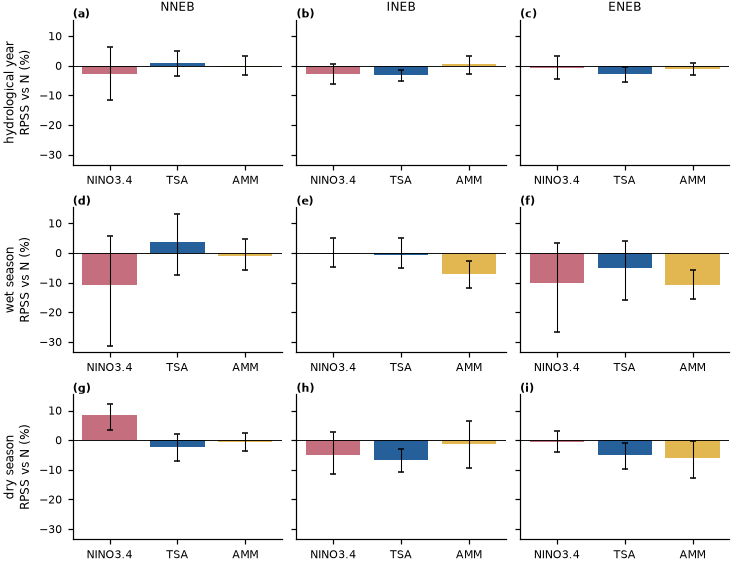

*RPSS de N-NINO3.4, N-TSA e N-AMM em relação à climatologia N, em 2011–2025, por caso (linhas) e alvo (colunas); barras de erro: IC95 por reamostragem de anos. Acima de zero, a fase do índice na defasagem L* melhora as probabilidades das classes. Arquivos: `resultados/completo/figuras/F15_rpss_climatologia.png` e `.pdf` (169 × 130 mm).*

**Tabela 23. Comparação A0: climatologia por fase do índice − climatologia**

,alvo,caso,comparação,diferença de RPSS (p.p.),IC95 inferior,IC95 superior,p,diferença de acerto (p.p.),IC95 inferior (acerto),IC95 superior (acerto),p (acerto),p (nulo),q (BH)
0,NNEB,ano hidrológico,N-NINO3.4 − N,-2.7,-11.6,6.5,0.579,3.3,-5.0,12.2,0.57,0.794,0.962
1,NNEB,ano hidrológico,N-TSA − N,0.9,-3.4,5.0,0.648,-3.9,-8.9,1.7,0.21,0.122,0.824
2,NNEB,ano hidrológico,N-AMM − N,-0.3,-3.2,3.3,0.887,2.2,-5.0,10.0,0.59,0.237,0.956
3,NNEB,estação chuvosa,N-NINO3.4 − N,-10.7,-30.7,5.8,0.247,-3.6,-7.6,0.9,0.29,0.947,0.962
4,NNEB,estação chuvosa,N-TSA − N,3.8,-7.2,13.3,0.543,9.3,-5.3,22.7,0.22,0.015,0.206
5,NNEB,estação chuvosa,N-AMM − N,-1.1,-5.9,4.9,0.760,0.0,-10.7,12.0,1.00,0.389,0.956
6,NNEB,estação seca,N-NINO3.4 − N,8.5,3.9,12.3,0.014,8.6,1.0,17.1,0.16,0.008,0.206
7,NNEB,estação seca,N-TSA − N,-2.4,-7.0,2.1,0.313,-8.6,-15.2,-1.0,0.04,0.763,0.962
8,NNEB,estação seca,N-AMM − N,-0.5,-3.8,2.4,0.733,-3.8,-10.5,2.9,0.26,0.389,0.956
9,INEB,ano hidrológico,N-NINO3.4 − N,-2.8,-6.4,0.4,0.115,2.0,-4.5,7.4,0.51,0.947,0.962


*Diferença de RPSS e de acerto (pontos percentuais) entre N-índice e N, nos mesmos meses. Positivo: N-índice acerta mais. q: Benjamini-Hochberg sobre as 27 comparações. Arquivo: `resultados/completo/tabelas/T23_comparacao_A0.csv`.*

**Tabela 24. As classes de quintil no teste, alvo inteiro**

,alvo,caso,meses de teste,quantil médio,Q1 muito seco (%),Q2 seco (%),Q3 normal (%),Q4 chuvoso (%),Q5 muito chuvoso (%)
0,NNEB,ano hidrológico,180,0.471,16.7,23.9,25.6,15.6,18.3
1,NNEB,estação chuvosa,75,0.493,12.0,25.3,22.7,24.0,16.0
2,NNEB,estação seca,105,0.456,20.0,22.9,27.6,9.5,20.0
3,INEB,ano hidrológico,168,0.438,24.4,23.8,16.1,17.3,18.5
4,INEB,estação chuvosa,84,0.468,25.0,20.2,14.3,17.9,22.6
5,INEB,estação seca,84,0.408,23.8,27.4,17.9,16.7,14.3
6,ENEB,ano hidrológico,168,0.463,22.0,17.9,25.6,19.6,14.9
7,ENEB,estação chuvosa,70,0.460,15.7,22.9,32.9,17.1,11.4
8,ENEB,estação seca,98,0.465,26.5,14.3,20.4,21.4,17.3


*Frequência de cada classe nos meses de 2011–2025 de cada caso, com os limites da referência 1981–2010; 20 % em cada classe indica um teste com a mesma distribuição da referência. Quantil médio abaixo de 0,5: teste mais seco que a referência. Arquivo: `resultados/completo/tabelas/T24_classes_no_teste.csv`.*

**Tabela 25. Quantil e classe mensais do alvo inteiro, 2011–2025**

,mês,quantil u,classe,alvo
0,2011-01-01,0.90,Q5 muito chuvoso,NNEB
1,2011-02-01,0.90,Q5 muito chuvoso,NNEB
2,2011-03-01,0.33,Q2 seco,NNEB
3,2011-04-01,0.63,Q4 chuvoso,NNEB
4,2011-05-01,0.77,Q4 chuvoso,NNEB
5,2011-06-01,0.43,Q3 normal,NNEB
6,2011-07-01,0.87,Q5 muito chuvoso,NNEB
7,2011-08-01,0.73,Q4 chuvoso,NNEB
8,2011-09-01,0.00,Q1 muito seco,NNEB
9,2011-10-01,1.00,Q5 muito chuvoso,NNEB


*Quantil u de cada mês dos anos hidrológicos de teste em relação aos 30 valores do mesmo mês em 1981–2010, e a sua classe. Mostradas 12 de 516 linhas. Arquivo: `resultados/completo/tabelas/T25_serie_teste.csv`.*

**Figura 16. Classe mensal da chuva do alvo inteiro no período de teste**

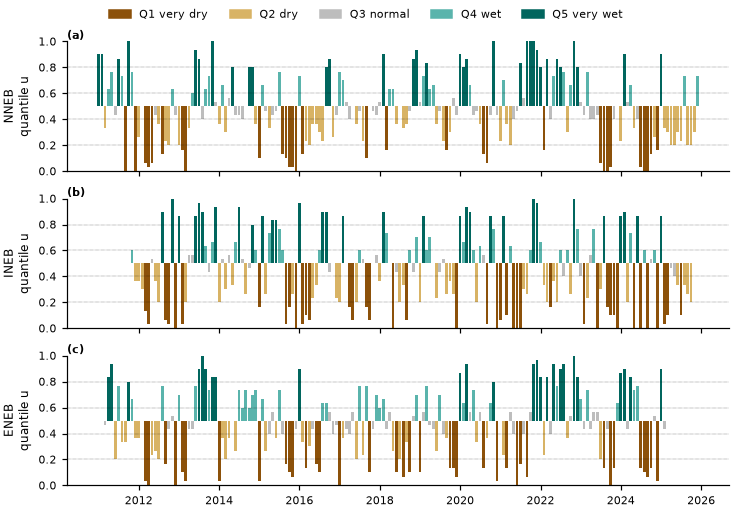

*Quantil u de cada mês dos anos hidrológicos de 2011 a 2025 em relação aos 30 valores do mesmo mês em 1981–2010, para o alvo inteiro, com a cor da classe de quintil; barras a partir da mediana (0,5). Linhas pontilhadas: limites q20, q40, q60 e q80. Arquivos: `resultados/completo/figuras/F16_serie_teste.png` e `.pdf` (169 × 118 mm).*

#### Síntese numérica

- N-índice melhor que N com q < 0,05 em 0 de 27 comparações.
- NNEB, ano hidrológico: no teste, 17 % dos meses em Q1 e 18 % em Q5; maior RPSS entre as N-índice: N-TSA, +0,9 % (IC95 −3,5 a +5,0).
- NNEB, estação chuvosa: no teste, 12 % dos meses em Q1 e 16 % em Q5; maior RPSS entre as N-índice: N-TSA, +3,8 % (IC95 −7,3 a +13,2).
- NNEB, estação seca: no teste, 20 % dos meses em Q1 e 20 % em Q5; maior RPSS entre as N-índice: N-NINO3.4, +8,5 % (IC95 +3,4 a +12,2).
- INEB, ano hidrológico: no teste, 24 % dos meses em Q1 e 18 % em Q5; maior RPSS entre as N-índice: N-AMM, +0,6 % (IC95 −2,6 a +3,3).
- INEB, estação chuvosa: no teste, 25 % dos meses em Q1 e 23 % em Q5; maior RPSS entre as N-índice: N-NINO3.4, −0,3 % (IC95 −4,7 a +5,2).
- INEB, estação seca: no teste, 24 % dos meses em Q1 e 14 % em Q5; maior RPSS entre as N-índice: N-AMM, −1,2 % (IC95 −9,2 a +6,6).
- ENEB, ano hidrológico: no teste, 22 % dos meses em Q1 e 15 % em Q5; maior RPSS entre as N-índice: N-NINO3.4, −0,8 % (IC95 −4,5 a +3,4).
- ENEB, estação chuvosa: no teste, 16 % dos meses em Q1 e 11 % em Q5; maior RPSS entre as N-índice: N-TSA, −5,2 % (IC95 −15,8 a +3,9).
- ENEB, estação seca: no teste, 27 % dos meses em Q1 e 17 % em Q5; maior RPSS entre as N-índice: N-NINO3.4, −0,6 % (IC95 −4,1 a +3,0).

### Relatório parcial 7 · 30/10/2026 19:47 · fim da Seção 5

Modo completo. Tempo decorrido: 9 min. Término geral previsto: 31/10/2026 12:18.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | concluída | 259 / 259 | 6 min | 0 min | — |
| Seção 5 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 6 | aguardando | 0 / 54 | 0 min | 1 min (a priori) | 30/10 19:48 |
| Seção 7 | aguardando | 0 / 54 | 0 min | 2 min (a priori) | 30/10 19:50 |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 19:57 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 30/10 23:35 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 12:17 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 12:18 |

Últimos registros:
- 2026-10-30T22:47:24+00:00 | Seção 5: iniciada (9 unidades de trabalho).
- 2026-10-30T22:47:44+00:00 | Seção 5: amostras gravadas; N-índice melhor que N com q < 0,05 em 0 de 27 comparações (valor-p pelo nulo de 130 deslocamentos).
- 2026-10-30T22:47:50+00:00 | Seção 5: concluída em 0 min.



In [14]:
# =============================================================================
# 5.3 Tabelas, figuras e síntese da climatologia como previsão. Lê apenas o que 5.2 gravou.
# Define relatorio_metodo(), que as Seções 6 a 8 usam para avaliar cada modelo.
# =============================================================================
def com_rotulo(df):
    """Cópia com o nome do caso por extenso."""
    out = df.copy()
    if 'caso' in out:
        out['caso'] = out['caso'].map(ROTULO_CASO)
    return out


CENTRO_CLASSE = (np.arange(K_CLASSES) + 0.5) / K_CLASSES       # quantil central de cada classe


def quantil_esperado(prob):
    """Quantil esperado da previsão: média dos centros das classes pesada pelas probabilidades."""
    return np.asarray(prob) @ CENTRO_CLASSE


tabela(com_rotulo(AMOSTRAS_TAB), 'amostras', 'Meses de treino e de teste por alvo e caso',
       'Cada amostra é um mês com todo o território do alvo: a classe observada vem do quantil u '
       'da chuva média do alvo, ponderada pela área, em relação a 1981–2010. Papéis por ano '
       'hidrológico: treino '
       '(1981–2010) e teste (2011–2025). Colunas Q1 a Q5: meses observados em cada classe. Hash: '
       'SHA-256 dos meses, o mesmo para todos os métodos e versões.', n=18)
tabela(com_rotulo(CLIM), 'desempenho_climatologia',
       'Desempenho da climatologia (N) e da climatologia por fase do índice (N-índice), 2011–2025',
       'RPSS em relação a N (frequência de cada classe em 1981–2010), com IC95 por reamostragem '
       'conjunta de blocos de 3 anos (numerador e denominador recalculados) e p da troca de '
       'sinal por ano; N tem RPSS zero por definição. O IC95 expressa a incerteza da estimativa. '
       'Acerto da '
       'classe mais provável (acaso = 20 %; empates dividem o acerto). ROC: área sob a curva de '
       'cada evento (acaso = 0,5).', n=36)
fig, axs = plt.subplots(len(CASOS), len(ALVOS), figsize=(2.5 * len(ALVOS) + 0.4,
                                                        1.9 * len(CASOS) + 0.4),
                        sharey=True, squeeze=False)
for (i, caso), (k, alvo) in itertools.product(enumerate(CASOS), enumerate(ALVOS)):
    ax = axs[i, k]
    d = CLIM[(CLIM.alvo == alvo) & (CLIM.caso == caso)].set_index('previsão').loc[
        CLIMATOLOGIAS[1:]]
    x = np.arange(len(d))
    ax.bar(x, d['RPSS (%)'], color=[COR[n] for n in INDICES], alpha=0.85)
    ax.errorbar(x, d['RPSS (%)'], yerr=[d['RPSS (%)'] - d['IC95 inferior'],
                                        d['IC95 superior'] - d['RPSS (%)']],
                fmt='none', ecolor='k', lw=0.7, capsize=2)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xticks(x, [n for n in INDICES], rotation=0)
    if i == 0:
        ax.set_title(alvo)
    if k == 0:
        ax.set_ylabel(f'{EN[caso]}\nRPSS vs N (%)')
figura(fig, 'rpss_climatologia', 'Habilidade da climatologia por fase do índice',
       'RPSS de N-NINO3.4, N-TSA e N-AMM em relação à climatologia N, em 2011–2025, por caso '
       '(linhas) e alvo (colunas); barras de erro: IC95 por reamostragem de anos. Acima de zero, '
       'a fase do índice na defasagem L* melhora as probabilidades das classes.')

A0_TAB = com_rotulo(A0)
tabela(A0_TAB, 'comparacao_A0', 'Comparação A0: climatologia por fase do índice − climatologia',
       'Diferença de RPSS e de acerto (pontos percentuais) entre N-índice e N, nos mesmos meses. '
       f'Positivo: N-índice acerta mais. q: Benjamini-Hochberg sobre as {len(A0)} comparações.',
       n=27)

# ----- o teste visto pelo alvo inteiro: classes observadas -----
linhas = []
for (alvo, caso), serie in SERIE_TESTE.items():
    linhas.append({'alvo': alvo, 'caso': ROTULO_CASO[caso], 'meses de teste': len(serie),
                   'quantil médio': float(serie['quantil u'].mean()),
                   **{f'{CLASSES[k]} (%)': float(100 * (serie['classe'] == CLASSES[k]).mean())
                      for k in range(K_CLASSES)}})
tabela(pd.DataFrame(linhas), 'classes_no_teste', 'As classes de quintil no teste, alvo inteiro',
       'Frequência de cada classe nos meses de 2011–2025 de cada caso, com os limites da '
       'referência 1981–2010; 20 % em cada classe indica um teste com a mesma distribuição da '
       'referência. Quantil médio abaixo de 0,5: teste mais seco que a referência.')
SERIE_ANO = pd.concat([d.assign(alvo=a) for (a, c), d in SERIE_TESTE.items() if c == 'ano'],
                      ignore_index=True)
tabela(SERIE_ANO, 'serie_teste', 'Quantil e classe mensais do alvo inteiro, 2011–2025',
       'Quantil u de cada mês dos anos hidrológicos de teste em relação aos 30 valores do mesmo '
       'mês em 1981–2010, e a sua classe.', n=12)
fig, axs = plt.subplots(len(ALVOS), 1, figsize=(7.0, 1.5 * len(ALVOS) + 0.4), sharex=True,
                        squeeze=False)
for k, alvo in enumerate(ALVOS):
    d = SERIE_ANO[SERIE_ANO.alvo == alvo]
    cores = [COR_CLASSE[CLASSES.index(c)] for c in d['classe']]
    ax = axs[k, 0]
    ax.bar(d['mês'], d['quantil u'] - 0.5, bottom=0.5, width=25, color=cores)
    for q in LIMITES_Q:
        ax.axhline(q, color='k', lw=0.3, ls=':')
    ax.set(ylabel=f'{alvo}\nquantile u', ylim=(0, 1))
fig.legend(handles=[Patch(color=COR_CLASSE[k], label=CLASSES_EN[k]) for k in range(K_CLASSES)],
           loc='outside upper center', ncol=5)
figura(fig, 'serie_teste', 'Classe mensal da chuva do alvo inteiro no período de teste',
       'Quantil u de cada mês dos anos hidrológicos de 2011 a 2025 em relação aos 30 valores do '
       'mesmo mês em 1981–2010, para o alvo inteiro, com a cor da classe de quintil; barras a '
       'partir da mediana (0,5). Linhas pontilhadas: limites q20, q40, q60 e q80.')

det = A0[(A0['q (BH)'] < ALFA) & (A0['diferença de RPSS (p.p.)'] > 0)]
linhas = [f"N-índice melhor que N com q < 0,05 em {len(det)} de {len(A0)} comparações"
          + (': ' + '; '.join(f"{r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['comparação']} "
                              f"({r['diferença de RPSS (p.p.)']:+.1f} p.p.)"
                              for _, r in det.iterrows()) + '.' if len(det) else '.')]
for (alvo, caso), g in CLIM.groupby(['alvo', 'caso'], sort=False):
    melhor = g[g['previsão'] != 'N'].sort_values('RPSS (%)').iloc[-1]
    serie = SERIE_TESTE[(alvo, caso)]
    linhas.append(f"{alvo}, {ROTULO_CASO[caso]}: no teste, "
                  f"{100 * (serie['classe'] == CLASSES[0]).mean():.0f} % dos meses em Q1 e "
                  f"{100 * (serie['classe'] == CLASSES[4]).mean():.0f} % em Q5; maior RPSS entre "
                  f"as N-índice: {melhor['previsão']}, {melhor['RPSS (%)']:+.1f} % (IC95 "
                  f"{melhor['IC95 inferior']:+.1f} a {melhor['IC95 superior']:+.1f}).")
sintese(linhas)
PROGRESSO.concluir('Seção 5')


# ----- avaliação de um modelo (usada nas Seções 6 a 8) -----
def avaliar_metodo(metodo):
    """Métricas de todas as previsões do método contra o seu controle sem índice e comparações
    A (índice em L* − controle) e C (índice em L* − índice em L1), por alvo, caso e índice; série
    de teste do quantil esperado."""
    lin_met, lin_cmp, series = [], [], []
    for alvo, caso in itertools.product(ALVOS, CASOS):
        am0 = ler_amostras(alvo, caso)
        serie = pd.DataFrame({'alvo': alvo, 'caso': caso, 'mês': G.tempos[am0['ref']],
                              'quantil observado': am0['u'],
                              'classe observada': [CLASSES[k] for k in am0['cl']]})
        for indice in INDICES:
            am = com_controle(am0, metodo, alvo, caso, indice)
            prev = {v: ler_unidade(metodo, alvo, caso, indice, v) for v in VERSOES}
            prev = {v: x for v, x in prev.items() if x is not None}
            for v, x in prev.items():
                lin_met.append({'método': metodo, 'alvo': alvo, 'caso': caso, 'índice': indice,
                                'versão': v, 'defasagem (meses)': defasagem(alvo, caso, indice, v),
                                **metricas(am, x[0], f'{metodo}:{alvo}:{caso}:{indice}:{v}')})
            if 'aferida' in prev:
                lin_cmp.append({'método': metodo, 'grupo': 'A (hipótese)', 'alvo': alvo,
                                'caso': caso, 'índice': indice, 'comparação': 'L* − sem índice',
                                **comparar(am, prev['aferida'][0], am['clim'],
                                           f'{metodo}:A:{alvo}:{caso}:{indice}')})
                serie[f'{indice} em L*: quantil esperado'] = quantil_esperado(prev['aferida'][0])
                serie[f'{indice} em L*: P(Q1–Q2)'] = prev['aferida'][0][:, :2].sum(1)
            L = defasagem(alvo, caso, indice, 'aferida')
            if L != 1 and all(v in prev for v in VERSOES):
                lin_cmp.append({'método': metodo, 'grupo': 'C', 'alvo': alvo, 'caso': caso,
                                'índice': indice, 'comparação': f'L{L} − L1',
                                **comparar(am, prev['aferida'][0], prev['L1'][0],
                                           f'{metodo}:C:{alvo}:{caso}:{indice}')})
        series.append(serie)
    met, cmp_ = pd.DataFrame(lin_met), pd.DataFrame(lin_cmp)
    if len(cmp_):
        cmp_['q (BH)'] = q_por_grupo(cmp_, 'grupo')
        # hipótese: valor-p pelo nulo de deslocamento circular do índice (procedimento inteiro)
        nulo = nulo_hipotese(metodo)
        sel = cmp_.grupo == 'A (hipótese)'
        cmp_.loc[sel, 'p (nulo)'] = [
            p_nulo(r['diferença de RPSS (p.p.)'], nulo[f"{r['alvo']}|{r['caso']}|{r['índice']}"][
                'rpss']) for _, r in cmp_[sel].iterrows()]
        cmp_.loc[sel, 'q (BH)'] = benjamini_hochberg(cmp_.loc[sel, 'p (nulo)'].to_numpy())
        cmp_.attrs['falsos positivos da troca de sinal (%)'] = 100 * float(np.mean(
            [np.mean(np.asarray(v['p_troca']) < ALFA) for v in nulo.values()]))
    return met, cmp_, pd.concat(series, ignore_index=True)


def com_versao(df):
    """Cópia com caso e versão por extenso."""
    out = com_rotulo(df)
    if 'versão' in out:
        out['versão'] = out['versão'].map(ROTULO_VERSAO)
    return out


def relatorio_metodo(metodo, secao):
    """Tabelas, figuras e síntese de um modelo: configuração, curva de resposta, desempenho,
    comparações A e C, hipótese e série de teste do alvo inteiro."""
    chave = metodo.replace(' ', '').lower()
    lin, curvas = [], []
    for alvo, caso, indice, v in itertools.product(ALVOS, CASOS, INDICES, VERSOES):
        x = ler_unidade(metodo, alvo, caso, indice, v)
        if x is not None:
            info = x[1]
            lin.append({'alvo': alvo, 'caso': ROTULO_CASO[caso], 'índice': indice,
                        'versão': ROTULO_VERSAO[v], 'defasagem (meses)': info['defasagem'],
                        'treino (anos hidrológicos)': info['treino'],
                        'meses de treino': info['meses_de_treino'],
                        'segundos por unidade': info['segundos']})
            if v == 'aferida':
                for xi, pk in zip(GRADE_INDICE, info['curva_resposta']):
                    curvas.append({'alvo': alvo, 'caso': caso, 'índice': indice,
                                   'defasagem (meses)': info['defasagem'],
                                   'índice (dp)': float(xi),
                                   **{f'P({CLASSES[k][:2]})': pk[k] for k in range(K_CLASSES)}})
    tabela(pd.DataFrame(lin), f'unidades_{chave}', f'{metodo}: unidades ajustadas',
           f'Cada unidade lê um único índice, na forma escolhida na Seção 4 '
           f'(registros/calibracao.json), é treinada uma vez com 1981–2010 e prevê a '
           f'probabilidade de cada classe de '
           f'quintil do alvo inteiro. Hiperparâmetros: {json.dumps(ESCOLHA[metodo])}. Meses de '
           'treino: meses do caso nos anos hidrológicos de 1981–2010.', n=18)
    CURVA = pd.DataFrame(curvas)
    tabela(com_rotulo(CURVA), f'resposta_{chave}', f'{metodo}: como o modelo lê cada índice',
           'Probabilidade de cada classe prevista pelo modelo treinado em 1981–2010 para um índice '
           'que permanece no valor indicado nos meses que a entrada lê, média dos meses do caso.',
           n=21)
    fig, axs = plt.subplots(len(CASOS), len(ALVOS), figsize=(2.5 * len(ALVOS) + 0.4,
                                                            1.9 * len(CASOS) + 0.4),
                            sharex=True, sharey=True, squeeze=False)
    for (i, caso), (k, alvo) in itertools.product(enumerate(CASOS), enumerate(ALVOS)):
        ax = axs[i, k]
        for indice in INDICES:
            d = CURVA[(CURVA.alvo == alvo) & (CURVA.caso == caso) & (CURVA['índice'] == indice)]
            if len(d):
                ax.plot(d['índice (dp)'], d['P(Q1)'], color=COR[indice], ls='-', lw=1,
                        label=f"{indice} (L{d['defasagem (meses)'].iloc[0]})")
                ax.plot(d['índice (dp)'], d['P(Q5)'], color=COR[indice], ls=':', lw=1)
        ax.axhline(0.2, color='k', lw=0.5)
        ax.axvline(0, color='k', lw=0.3)
        ax.legend(loc='upper center', fontsize=6)
        if i == 0:
            ax.set_title(alvo)
        if k == 0:
            ax.set_ylabel(f'{EN[caso]}\nprobability')
        if i == len(CASOS) - 1:
            ax.set_xlabel('index at lag L* (SD)')
    figura(fig, f'resposta_{chave}', f'{metodo}: probabilidade dos extremos em função do índice',
           'Probabilidade prevista da classe muito seco (Q1, linha contínua) e muito chuvoso (Q5, '
           'linha pontilhada) para cada valor do índice na defasagem L* (indicada na legenda), por '
           'caso (linhas) e alvo (colunas). Linha horizontal: 20 %.')
    met, cmp_, serie = avaliar_metodo(metodo)
    tabela(com_versao(met), f'metricas_{chave}', f'{metodo}: desempenho, 2011–2025',
           'Alvo inteiro, mês a mês, para cada índice em L* (aferida) e em L1 (mês anterior). RPSS '
           'em relação ao mesmo modelo sem o índice (IC95 por reamostragem conjunta de blocos de '
           '3 anos; p da troca de sinal por ano); acerto da classe mais provável (acaso = 20 %); '
           'área ROC de cada evento (acaso = '
           '0,5).', n=18)
    fig, axs = plt.subplots(len(CASOS), len(ALVOS), figsize=(2.5 * len(ALVOS) + 0.4,
                                                            1.9 * len(CASOS) + 0.4),
                            sharey=True, squeeze=False)
    for (i, caso), (k, alvo) in itertools.product(enumerate(CASOS), enumerate(ALVOS)):
        ax = axs[i, k]
        for j, indice in enumerate(INDICES):
            for desl, v, alfa in ((-0.18, 'aferida', 0.9), (0.18, 'L1', 0.4)):
                d = met[(met.alvo == alvo) & (met.caso == caso) & (met['índice'] == indice)
                        & (met['versão'] == v)]
                if len(d):
                    d = d.iloc[0]
                    ax.bar(j + desl, d['RPSS (%)'], 0.34, color=COR[indice], alpha=alfa)
                    ax.errorbar(j + desl, d['RPSS (%)'],
                                yerr=[[d['RPSS (%)'] - d['IC95 inferior']],
                                      [d['IC95 superior'] - d['RPSS (%)']]],
                                fmt='none', ecolor='k', lw=0.6, capsize=1.5)
        ax.axhline(0, color='k', lw=0.6)
        ax.set_xticks(range(len(INDICES)), INDICES)
        if i == 0:
            ax.set_title(alvo)
        if k == 0:
            ax.set_ylabel(f'{EN[caso]}\nRPSS (%)')
    figura(fig, f'rpss_{chave}', f'{metodo}: ganho de cada índice sobre o modelo sem índice',
           'RPSS em 2011–2025 na previsão da classe de quintil do alvo inteiro, por caso (linhas) '
           'e '
           'alvo (colunas). Para cada índice: barra escura, índice na defasagem aferida L*; barra '
           'clara, índice no mês anterior (L1). Barras de erro: IC95 por blocos de anos. Acima '
           'de zero, fornecer o índice melhora este modelo; não implica ganho sobre a '
           'climatologia empírica.')
    tabela(com_rotulo(cmp_), f'comparacoes_{chave}', f'{metodo}: comparações A e C',
           'Diferença de RPSS e de acerto (pontos percentuais) entre duas previsões, nos mesmos '
           'meses; positivo: a primeira acerta mais. A (hipótese): índice em L* − mesmo modelo sem '
           'índice. C: '
           'índice em L* − índice em L1, só quando L* é diferente de 1. q: Benjamini-Hochberg em '
           'cada grupo.', n=18)
    linhas_h = []
    for alvo, caso, indice in itertools.product(ALVOS, CASOS, INDICES):
        a = cmp_[(cmp_.grupo == 'A (hipótese)') & (cmp_.alvo == alvo) & (cmp_.caso == caso)
                 & (cmp_['índice'] == indice)]
        c = cmp_[(cmp_.grupo == 'C') & (cmp_.alvo == alvo) & (cmp_.caso == caso)
                 & (cmp_['índice'] == indice)]
        m = met[(met.alvo == alvo) & (met.caso == caso) & (met['índice'] == indice)
                & (met['versão'] == 'aferida')]
        if len(a):
            a = a.iloc[0]
            linhas_h.append({
                'método': metodo, 'alvo': alvo, 'caso': caso, 'índice': indice,
                'L* (meses)': defasagem(alvo, caso, indice, 'aferida'),
                'RPSS sobre o modelo sem índice (%)': a['diferença de RPSS (p.p.)'],
                'IC95 inferior': a['IC95 inferior'], 'IC95 superior': a['IC95 superior'],
                'p (nulo)': a['p (nulo)'], 'q': a['q (BH)'],
                'hipótese sustentada': bool(a['q (BH)'] < ALFA
                                            and a['diferença de RPSS (p.p.)'] > 0),
                'acerto (%)': float(m['acerto da classe mais provável (%)'].iloc[0]),
                'ROC muito seco': float(m['ROC muito seco (Q1)'].iloc[0]),
                'ROC muito chuvoso': float(m['ROC muito chuvoso (Q5)'].iloc[0]),
                'ganho de L* sobre L1 (p.p.)': (c['diferença de RPSS (p.p.)'].iloc[0]
                                                 if len(c) else np.nan),
                'q (L* − L1)': c['q (BH)'].iloc[0] if len(c) else np.nan})
    HIP = pd.DataFrame(linhas_h)
    tabela(com_rotulo(HIP), f'hipotese_{chave}',
           f'{metodo}: teste da hipótese em cada alvo, caso e índice',
           'Hipótese sustentada quando o modelo que lê o índice alinhado na defasagem aferida L* '
           'tem RPSS positivo sobre o mesmo modelo sem índice e q < 0,05. p (nulo): fração das '
           f'{len(DESLOC_NULO)} séries do índice deslocadas no tempo (L* reaferido, modelo '
           'retreinado), mais a observada, com RPSS igual ou maior; testa se o alinhamento '
           'temporal do índice importa; q: Benjamini-Hochberg nas 27 comparações do '
           'método. Não detectado não é ausência de efeito: o IC95 expressa a incerteza da '
           'estimativa, sem provar ausência de efeito nem substituir o teste. Ganho de L* sobre '
           'L1: vazio quando L* = 1.', n=27)
    tabela(com_rotulo(serie), f'serie_{chave}', f'{metodo}: quantil observado e previsto',
           'Quantil u observado em cada mês de teste e, para cada índice em L*, o quantil esperado '
           'da previsão (média dos centros das classes pesada pelas probabilidades) e a '
           'probabilidade prevista de seco ou muito seco (Q1–Q2).', n=12)
    fig, axs = plt.subplots(len(CASOS), len(ALVOS), figsize=(7.0, 1.6 * len(CASOS) + 0.4),
                            sharex=True, sharey=True, squeeze=False)
    for (i, caso), (k, alvo) in itertools.product(enumerate(CASOS), enumerate(ALVOS)):
        ax = axs[i, k]
        d = serie[(serie.alvo == alvo) & (serie.caso == caso)]
        cores = [COR_CLASSE[CLASSES.index(c)] for c in d['classe observada']]
        ax.bar(d['mês'], d['quantil observado'] - 0.5, bottom=0.5, width=25, color=cores)
        for indice in INDICES:
            coluna = f'{indice} em L*: quantil esperado'
            if coluna in d:
                ax.plot(d['mês'], d[coluna], color=COR[indice], lw=0.8, label=indice)
        ax.axhline(0.5, color='k', lw=0.4)
        ax.set_ylim(0, 1)
        if i == 0:
            ax.set_title(alvo)
        if k == 0:
            ax.set_ylabel(f'{EN[caso]}\nquantile')
        ax.tick_params(axis='x', labelrotation=90)
    fig.legend(*axs[0, -1].get_legend_handles_labels(), loc='outside upper center', ncol=3)
    figura(fig, f'serie_{chave}', f'{metodo}: quantil observado e previsto no alvo inteiro',
           'Barras: quantil u observado em cada mês de teste (2011–2025), a partir da mediana, com '
           'a cor da classe. Linhas: quantil esperado da previsão do modelo com cada índice, '
           'sozinho, na defasagem aferida L*. Por caso (linhas) e alvo (colunas).')
    linhas = [f"Hipótese sustentada em {int(HIP['hipótese sustentada'].sum())} de {len(HIP)} "
              'combinações de alvo, caso e índice' + (': ' + '; '.join(
                  f"{r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['índice']} em L{r['L* (meses)']} "
                  f"(RPSS {r['RPSS sobre o modelo sem índice (%)']:+.1f} %)"
                  for _, r in HIP[HIP['hipótese sustentada']].iterrows()) + '.'
                  if HIP['hipótese sustentada'].any() else '.')]
    linhas.append(f"Validade do teste: sob o nulo ({len(DESLOC_NULO)} deslocamentos do índice), a "
                  f"troca de sinal deu p < 0,05 em "
                  f"{cmp_.attrs.get('falsos positivos da troca de sinal (%)', np.nan):.1f} % das "
                  'previsões (esperado: 5 %); a hipótese usa o valor-p do nulo por '
                  'deslocamento, que mantém a ordem interna do índice.')
    _larg = HIP['IC95 superior'] - HIP['IC95 inferior']
    linhas.append(f'Largura do IC95 do RPSS: mediana de {_larg.median():.1f} p.p. (de '
                  f'{_larg.min():.1f} a {_larg.max():.1f} p.p.).')
    for grupo, texto in (('A (hipótese)', 'índice em L* contra o modelo sem índice'),
                         ('C', 'índice em L* contra o índice em L1')):
        g = cmp_[cmp_.grupo == grupo]
        if len(g):
            melhor = int(((g['q (BH)'] < ALFA) & (g['diferença de RPSS (p.p.)'] > 0)).sum())
            pior = int(((g['q (BH)'] < ALFA) & (g['diferença de RPSS (p.p.)'] < 0)).sum())
            linhas.append(f'{texto.capitalize()}: {len(g)} comparações; a primeira previsão acerta '
                          f'mais com q < 0,05 em {melhor} e menos em {pior}; com p < 0,05 sem '
                          f"correção, {int((g['p'] < ALFA).sum())} (esperadas por acaso: cerca de "
                          f'{0.05 * len(g):.0f}).')
    for indice in INDICES:
        d = met[(met['índice'] == indice) & (met['versão'] == 'aferida')]
        if len(d):
            r = d.sort_values('RPSS (%)').iloc[-1]
            linhas.append(f"{indice} em L*: maior RPSS em {r['alvo']}, "
                          f"{ROTULO_CASO[r['caso']]} ({r['RPSS (%)']:+.1f} %; IC95 "
                          f"{r['IC95 inferior']:+.1f} a {r['IC95 superior']:+.1f}); área ROC de "
                          f"muito seco {r['ROC muito seco (Q1)']:.2f}.")
    sintese(linhas)
    met.to_csv(PASTAS['registros'] / f'metricas_{chave}.csv', index=False, encoding='utf-8-sig')
    cmp_.to_csv(PASTAS['registros'] / f'comparacoes_{chave}.csv', index=False,
                encoding='utf-8-sig')
    PROGRESSO.concluir(secao)
    return met, cmp_, HIP

### 5.4 Results and discussion

The samples table confirms that all methods and versions are evaluated on the same months (same hash) and shows how many test months fell in each class. A test period with more months in Q1 and Q2 than in Q4 and Q5 was drier than normal, which favours forecasts that shift probability towards the dry classes, with or without a physical reason. The N-index − N comparison answers, without a model, whether the index phase at the assessed lag already changes the odds of the classes. An association detected in Section 2 without a gain here is not a contradiction: the correlation uses 30 training years, and the forecast gain has to appear in 14 or 15 new years, with the reference fixed beforehand.

### 5.5 Conclusion

The section delivers the common evaluation protocol (samples, metrics and tests), the performance of climatology N, the reference of N-index and the common scale of the comparison between methods, and that of the index-phase climatology of each index.

### 5.6 References

EPSTEIN, E. S. A scoring system for probability forecasts of ranked categories. **Journal of Applied Meteorology**, v. 8, p. 985-987, 1969. DOI: 10.1175/1520-0450(1969)008<0985:ASSFPF>2.0.CO;2.

KÜNSCH, H. R. The jackknife and the bootstrap for general stationary observations. **The Annals of Statistics**, v. 17, n. 3, p. 1217-1241, 1989. DOI: 10.1214/aos/1176347265.

MASON, S. J.; GRAHAM, N. E. Areas beneath the relative operating characteristics (ROC) and relative operating levels (ROL) curves: statistical significance and interpretation. **Quarterly Journal of the Royal Meteorological Society**, v. 128, p. 2145-2166, 2002. DOI: 10.1256/003590002320603584.

WORLD METEOROLOGICAL ORGANIZATION. Attachment II.8: Standardized Verification System (SVS) for Long-Range Forecasts (LRF). In: WORLD METEOROLOGICAL ORGANIZATION. **Manual on the Global Data-processing and Forecasting System**. Geneva: WMO, 2007. (WMO-No. 485).

---

# Section 6. Ridge regression

### 6.1 Theoretical and methodological basis

**Scientific question.** In a linear model, does giving each index at the assessed lag improve the forecast of the quintile class of the target's monthly rainfall relative to the same model without the index?

**Introduction.** Ridge regression (Hoerl and Kennard, 1970) fits a line and adds to the error a penalty proportional to the squared weights, which shrinks the slope so that the model does not follow the chance features of the training years. Applied to the normal score of the quantile, with the spread of the training errors, it gives the probability of each class, as in the regression models used in seasonal forecasting.

**Rationale.** The line is the simplest way of reading an index: each standard deviation of the index always shifts the forecast distribution by the same amount. It is the reference for the nonlinear models of Sections 7 and 8.

**Hypotheses.** For each target, case and index: H0, the RPSS of the model with the index aligned at the assessed lag L*, measured over the same model without the index, does not exceed that obtained with the time-shifted index (with no temporal relation to rainfall); H1, it does. Decision: RPSS > 0 and q < 0.05. Complementary question: does the index at L* beat the same index in the previous month (L1)?

**Objective.** For each target, case and index, forecast the probability of each quintile class for each month of 2011–2025 with the index at L* and at L1, and make comparisons A (L* against the same model without the index) and C (L* against L1).

**Data and methodology.**
- Input: a single index, in the form and with the filter chosen in Section 4, anchored at month t − L (L* from Section 2 or L1). Example: NNEB, hydrological year, NINO3.4 with L* = 4: March is forecast with the NINO3.4 of November, April with that of December, and so on.
- Computation: forecast normal score of u = a + Xb, with the penalty chosen in Section 4 (penalty per month × training months); the probability of each class is the area of a normal distribution with this mean and the standard deviation of the training errors (corrected by the effective degrees of freedom) between the class limits.
- Training: a single fit with the months of the case in 1981–2010, which forecasts all months of 2011–2025 (the same protocol as calibration).
- Comparisons and tests: those of the Section 5 protocol; the hypothesis uses the p-value of the index-shift null.

**Limitations declared before the run.** A line does not represent an index that acts in only one of its phases (for example, only in El Niño); the normal distribution of the errors is an approximation.

**Outputs.** Tables: fitted units; response to each index; performance; comparisons A and C; hypothesis; test series. Figures: probability of the extremes as a function of the index; RPSS by index; observed and forecast quantile.

In [15]:
# =============================================================================
# 6.2 Processamento: Ridge. Para cada alvo, caso, índice e versão: reta no escore normal do
# quantil u sobre a entrada escolhida na Seção 4, com a penalidade escolhida; a dispersão dos
# erros de treino transforma a reta em probabilidade de cada classe de quintil. Previsão de
# cada mês de teste com um único treino em 1981–2010.
# =============================================================================
PROGRESSO.iniciar('Seção 6', N_COMB * len(INDICES) * len(VERSOES))
_n = ajustar_metodo('Ridge', 'Seção 6')
registrar(f'Ridge: {_n} unidades ajustadas nesta execução; configuração {ESCOLHA["Ridge"]}.')

Ridge: nenhuma combinação com o modelo idêntico ao controle sem índice.


Ridge: 54 unidades ajustadas nesta execução; configuração {'penalidade_por_mes': 10.0}.


**Tabela 26. Ridge: unidades ajustadas**

,alvo,caso,índice,versão,defasagem (meses),treino (anos hidrológicos),meses de treino,segundos por unidade
0,NNEB,ano hidrológico,NINO3.4,L* (aferida),4,1981–2010,360,0.001
1,NNEB,ano hidrológico,NINO3.4,L1 (mês anterior),1,1981–2010,360,0.001
2,NNEB,ano hidrológico,TSA,L* (aferida),1,1981–2010,360,0.001
3,NNEB,ano hidrológico,TSA,L1 (mês anterior),1,1981–2010,360,0.001
4,NNEB,ano hidrológico,AMM,L* (aferida),1,1981–2010,360,0.001
5,NNEB,ano hidrológico,AMM,L1 (mês anterior),1,1981–2010,360,0.001
6,NNEB,estação chuvosa,NINO3.4,L* (aferida),1,1981–2010,150,0.001
7,NNEB,estação chuvosa,NINO3.4,L1 (mês anterior),1,1981–2010,150,0.001
8,NNEB,estação chuvosa,TSA,L* (aferida),2,1981–2010,150,0.001
9,NNEB,estação chuvosa,TSA,L1 (mês anterior),1,1981–2010,150,0.001


*Cada unidade lê um único índice, na forma escolhida na Seção 4 (registros/calibracao.json), é treinada uma vez com 1981–2010 e prevê a probabilidade de cada classe de quintil do alvo inteiro. Hiperparâmetros: {"penalidade_por_mes": 10.0}. Meses de treino: meses do caso nos anos hidrológicos de 1981–2010. Mostradas 18 de 54 linhas. Arquivo: `resultados/completo/tabelas/T26_unidades_ridge.csv`.*

**Tabela 27. Ridge: como o modelo lê cada índice**

,alvo,caso,índice,defasagem (meses),índice (dp),P(Q1),P(Q2),P(Q3),P(Q4),P(Q5)
0,NNEB,ano hidrológico,NINO3.4,4,-2.50,0.169,0.194,0.206,0.214,0.217
1,NNEB,ano hidrológico,NINO3.4,4,-2.25,0.171,0.195,0.206,0.213,0.215
2,NNEB,ano hidrológico,NINO3.4,4,-2.00,0.173,0.196,0.206,0.212,0.212
3,NNEB,ano hidrológico,NINO3.4,4,-1.75,0.176,0.197,0.206,0.211,0.210
4,NNEB,ano hidrológico,NINO3.4,4,-1.50,0.178,0.198,0.206,0.210,0.207
5,NNEB,ano hidrológico,NINO3.4,4,-1.25,0.180,0.199,0.206,0.209,0.205
6,NNEB,ano hidrológico,NINO3.4,4,-1.00,0.183,0.200,0.206,0.208,0.202
7,NNEB,ano hidrológico,NINO3.4,4,-0.75,0.185,0.201,0.206,0.207,0.200
8,NNEB,ano hidrológico,NINO3.4,4,-0.50,0.187,0.202,0.206,0.207,0.197
9,NNEB,ano hidrológico,NINO3.4,4,-0.25,0.190,0.203,0.207,0.206,0.195


*Probabilidade de cada classe prevista pelo modelo treinado em 1981–2010 para um índice que permanece no valor indicado nos meses que a entrada lê, média dos meses do caso. Mostradas 21 de 567 linhas. Arquivo: `resultados/completo/tabelas/T27_resposta_ridge.csv`.*

**Figura 17. Ridge: probabilidade dos extremos em função do índice**

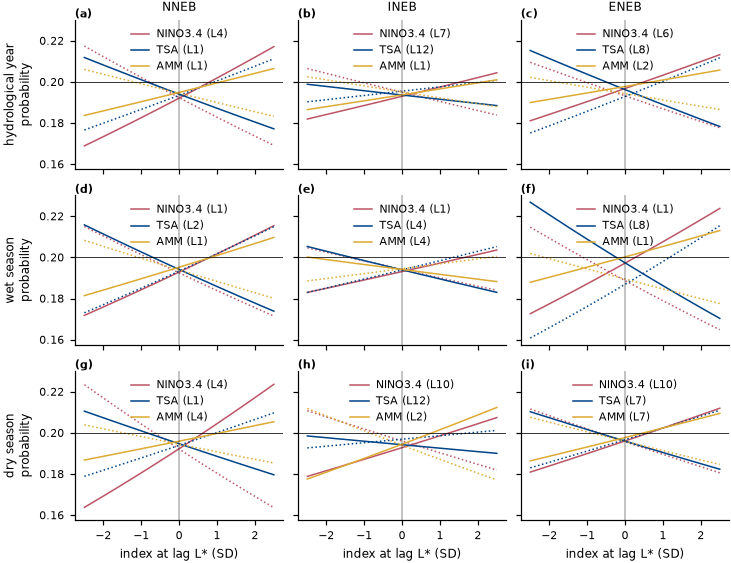

*Probabilidade prevista da classe muito seco (Q1, linha contínua) e muito chuvoso (Q5, linha pontilhada) para cada valor do índice na defasagem L* (indicada na legenda), por caso (linhas) e alvo (colunas). Linha horizontal: 20 %. Arquivos: `resultados/completo/figuras/F17_resposta_ridge.png` e `.pdf` (169 × 130 mm).*

**Tabela 28. Ridge: desempenho, 2011–2025**

,método,alvo,caso,índice,versão,defasagem (meses),RPSS (%),IC95 inferior,IC95 superior,p (troca de sinal),acerto da classe mais provável (%),ROC muito seco (Q1),ROC seco ou muito seco (Q1–Q2),ROC chuvoso ou muito chuvoso (Q4–Q5),ROC muito chuvoso (Q5),anos de teste,meses de teste
0,Ridge,NNEB,ano hidrológico,NINO3.4,L* (aferida),4,0.94,0.02,1.96,0.071,21.1,0.617,0.614,0.608,0.590,15,180
1,Ridge,NNEB,ano hidrológico,NINO3.4,L1 (mês anterior),1,0.86,-0.03,1.85,0.086,23.9,0.603,0.574,0.627,0.635,15,180
2,Ridge,NNEB,ano hidrológico,TSA,L* (aferida),1,0.58,-0.26,1.36,0.143,22.2,0.584,0.602,0.597,0.648,15,180
3,Ridge,NNEB,ano hidrológico,TSA,L1 (mês anterior),1,0.58,-0.24,1.37,0.143,22.2,0.584,0.602,0.597,0.648,15,180
4,Ridge,NNEB,ano hidrológico,AMM,L* (aferida),1,0.06,-0.26,0.40,0.745,25.0,0.593,0.543,0.489,0.437,15,180
5,Ridge,NNEB,ano hidrológico,AMM,L1 (mês anterior),1,0.06,-0.26,0.41,0.745,25.0,0.593,0.543,0.489,0.437,15,180
6,Ridge,NNEB,estação chuvosa,NINO3.4,L* (aferida),1,-0.01,-1.41,1.42,0.987,22.7,0.449,0.479,0.509,0.538,15,75
7,Ridge,NNEB,estação chuvosa,NINO3.4,L1 (mês anterior),1,-0.01,-1.34,1.48,0.987,22.7,0.449,0.479,0.509,0.538,15,75
8,Ridge,NNEB,estação chuvosa,TSA,L* (aferida),2,1.53,-0.02,3.06,0.091,33.3,0.736,0.632,0.647,0.679,15,75
9,Ridge,NNEB,estação chuvosa,TSA,L1 (mês anterior),1,1.78,0.55,3.21,0.014,32.0,0.770,0.701,0.699,0.720,15,75


*Alvo inteiro, mês a mês, para cada índice em L* (aferida) e em L1 (mês anterior). RPSS em relação ao mesmo modelo sem o índice (IC95 por reamostragem conjunta de blocos de 3 anos; p da troca de sinal por ano); acerto da classe mais provável (acaso = 20 %); área ROC de cada evento (acaso = 0,5). Mostradas 18 de 54 linhas. Arquivo: `resultados/completo/tabelas/T28_metricas_ridge.csv`.*

**Figura 18. Ridge: ganho de cada índice sobre o modelo sem índice**

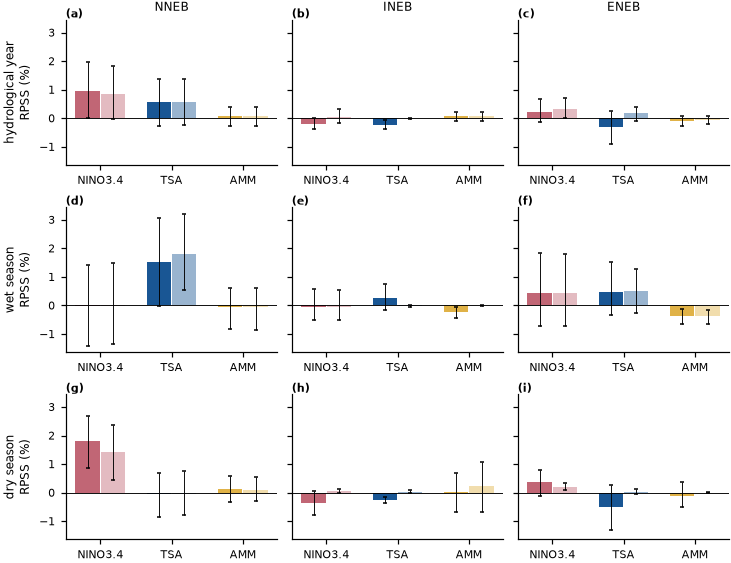

*RPSS em 2011–2025 na previsão da classe de quintil do alvo inteiro, por caso (linhas) e alvo (colunas). Para cada índice: barra escura, índice na defasagem aferida L*; barra clara, índice no mês anterior (L1). Barras de erro: IC95 por blocos de anos. Acima de zero, fornecer o índice melhora este modelo; não implica ganho sobre a climatologia empírica. Arquivos: `resultados/completo/figuras/F18_rpss_ridge.png` e `.pdf` (169 × 130 mm).*

**Tabela 29. Ridge: comparações A e C**

,método,grupo,alvo,caso,índice,comparação,diferença de RPSS (p.p.),IC95 inferior,IC95 superior,p,diferença de acerto (p.p.),IC95 inferior (acerto),IC95 superior (acerto),p (acerto),q (BH),p (nulo)
0,Ridge,A (hipótese),NNEB,ano hidrológico,NINO3.4,L* − sem índice,0.94,0.06,1.90,0.071,-4.4,-11.1,2.8,0.47,0.07,0.01
1,Ridge,C,NNEB,ano hidrológico,NINO3.4,L4 − L1,0.08,-0.26,0.42,0.756,-2.8,-10.0,5.6,0.55,0.85,NaN
2,Ridge,A (hipótese),NNEB,ano hidrológico,TSA,L* − sem índice,0.58,-0.27,1.38,0.143,-3.3,-10.6,3.3,0.59,0.14,0.03
3,Ridge,A (hipótese),NNEB,ano hidrológico,AMM,L* − sem índice,0.06,-0.26,0.39,0.745,-0.6,-5.6,6.1,1.00,0.67,0.27
4,Ridge,A (hipótese),NNEB,estação chuvosa,NINO3.4,L* − sem índice,-0.01,-1.37,1.42,0.987,0.0,-8.0,9.3,1.00,1.00,0.69
5,Ridge,A (hipótese),NNEB,estação chuvosa,TSA,L* − sem índice,1.53,0.06,3.11,0.091,10.7,-5.3,22.7,0.23,0.07,0.01
6,Ridge,C,NNEB,estação chuvosa,TSA,L2 − L1,-0.25,-0.83,0.16,0.475,1.3,-5.3,8.0,1.00,0.78,NaN
7,Ridge,A (hipótese),NNEB,estação chuvosa,AMM,L* − sem índice,-0.07,-0.88,0.62,0.872,12.0,2.7,20.0,0.08,1.00,0.73
8,Ridge,A (hipótese),NNEB,estação seca,NINO3.4,L* − sem índice,1.81,0.77,2.67,0.004,-7.6,-14.3,0.0,0.25,0.07,0.01
9,Ridge,C,NNEB,estação seca,NINO3.4,L4 − L1,0.38,-0.13,0.90,0.318,-7.6,-15.2,0.0,0.19,0.57,NaN


*Diferença de RPSS e de acerto (pontos percentuais) entre duas previsões, nos mesmos meses; positivo: a primeira acerta mais. A (hipótese): índice em L* − mesmo modelo sem índice. C: índice em L* − índice em L1, só quando L* é diferente de 1. q: Benjamini-Hochberg em cada grupo. Mostradas 18 de 45 linhas. Arquivo: `resultados/completo/tabelas/T29_comparacoes_ridge.csv`.*

**Tabela 30. Ridge: teste da hipótese em cada alvo, caso e índice**

,método,alvo,caso,índice,L* (meses),RPSS sobre o modelo sem índice (%),IC95 inferior,IC95 superior,p (nulo),q,hipótese sustentada,acerto (%),ROC muito seco,ROC muito chuvoso,ganho de L* sobre L1 (p.p.),q (L* − L1)
0,Ridge,NNEB,ano hidrológico,NINO3.4,4,0.94,0.06,1.90,0.01,0.07,False,21.1,0.617,0.590,0.084,0.851
1,Ridge,NNEB,ano hidrológico,TSA,1,0.58,-0.27,1.38,0.03,0.14,False,22.2,0.584,0.648,NaN,NaN
2,Ridge,NNEB,ano hidrológico,AMM,1,0.06,-0.26,0.39,0.27,0.67,False,25.0,0.593,0.437,NaN,NaN
3,Ridge,NNEB,estação chuvosa,NINO3.4,1,-0.01,-1.37,1.42,0.69,1.00,False,22.7,0.449,0.538,NaN,NaN
4,Ridge,NNEB,estação chuvosa,TSA,2,1.53,0.06,3.11,0.01,0.07,False,33.3,0.736,0.679,-0.250,0.777
5,Ridge,NNEB,estação chuvosa,AMM,1,-0.07,-0.88,0.62,0.73,1.00,False,34.7,0.492,0.403,NaN,NaN
6,Ridge,NNEB,estação seca,NINO3.4,4,1.81,0.77,2.67,0.01,0.07,False,20.0,0.725,0.701,0.380,0.572
7,Ridge,NNEB,estação seca,TSA,1,-0.03,-0.81,0.73,0.76,1.00,False,15.2,0.471,0.603,NaN,NaN
8,Ridge,NNEB,estação seca,AMM,4,0.13,-0.32,0.57,0.33,0.74,False,16.2,0.630,0.591,0.040,0.905
9,Ridge,INEB,ano hidrológico,NINO3.4,7,-0.19,-0.40,-0.01,0.98,1.00,False,19.6,0.491,0.416,-0.242,0.276


*Hipótese sustentada quando o modelo que lê o índice alinhado na defasagem aferida L* tem RPSS positivo sobre o mesmo modelo sem índice e q < 0,05. p (nulo): fração das 130 séries do índice deslocadas no tempo (L* reaferido, modelo retreinado), mais a observada, com RPSS igual ou maior; testa se o alinhamento temporal do índice importa; q: Benjamini-Hochberg nas 27 comparações do método. Não detectado não é ausência de efeito: o IC95 expressa a incerteza da estimativa, sem provar ausência de efeito nem substituir o teste. Ganho de L* sobre L1: vazio quando L* = 1. Arquivo: `resultados/completo/tabelas/T30_hipotese_ridge.csv`.*

**Tabela 31. Ridge: quantil observado e previsto**

,alvo,caso,mês,quantil observado,classe observada,NINO3.4 em L*: quantil esperado,NINO3.4 em L*: P(Q1–Q2),TSA em L*: quantil esperado,TSA em L*: P(Q1–Q2),AMM em L*: quantil esperado,AMM em L*: P(Q1–Q2)
0,NNEB,ano hidrológico,2011-01-01,0.90,Q5 muito chuvoso,0.517,0.372,0.504,0.391,0.487,0.416
1,NNEB,ano hidrológico,2011-02-01,0.90,Q5 muito chuvoso,0.519,0.370,0.504,0.392,0.489,0.415
2,NNEB,ano hidrológico,2011-03-01,0.33,Q2 seco,0.518,0.371,0.507,0.387,0.495,0.406
3,NNEB,ano hidrológico,2011-04-01,0.63,Q4 chuvoso,0.518,0.371,0.509,0.385,0.498,0.401
4,NNEB,ano hidrológico,2011-05-01,0.77,Q4 chuvoso,0.518,0.371,0.505,0.391,0.500,0.398
5,NNEB,ano hidrológico,2011-06-01,0.43,Q3 normal,0.514,0.377,0.500,0.397,0.498,0.400
6,NNEB,ano hidrológico,2011-07-01,0.87,Q5 muito chuvoso,0.510,0.382,0.499,0.399,0.497,0.402
7,NNEB,ano hidrológico,2011-08-01,0.73,Q4 chuvoso,0.508,0.385,0.502,0.395,0.498,0.400
8,NNEB,ano hidrológico,2011-09-01,0.00,Q1 muito seco,0.506,0.388,0.501,0.396,0.499,0.400
9,NNEB,ano hidrológico,2011-10-01,1.00,Q5 muito chuvoso,0.503,0.393,0.503,0.393,0.496,0.403


*Quantil u observado em cada mês de teste e, para cada índice em L*, o quantil esperado da previsão (média dos centros das classes pesada pelas probabilidades) e a probabilidade prevista de seco ou muito seco (Q1–Q2). Mostradas 12 de 1032 linhas. Arquivo: `resultados/completo/tabelas/T31_serie_ridge.csv`.*

**Figura 19. Ridge: quantil observado e previsto no alvo inteiro**

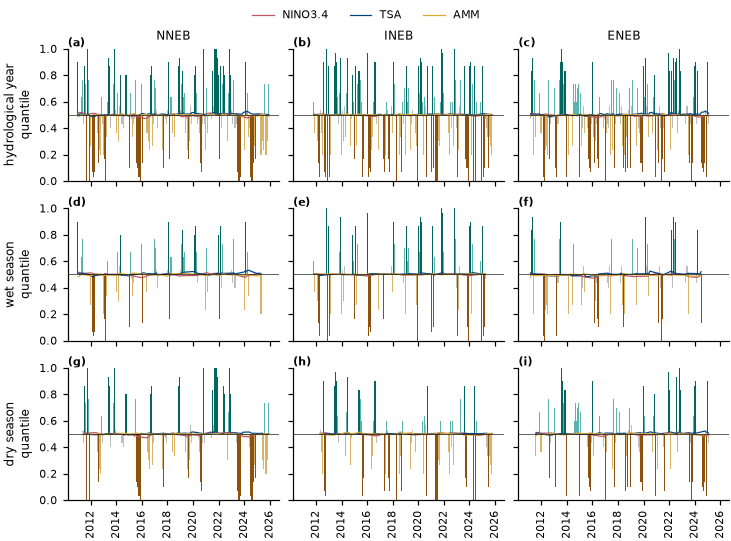

*Barras: quantil u observado em cada mês de teste (2011–2025), a partir da mediana, com a cor da classe. Linhas: quantil esperado da previsão do modelo com cada índice, sozinho, na defasagem aferida L*. Por caso (linhas) e alvo (colunas). Arquivos: `resultados/completo/figuras/F19_serie_ridge.png` e `.pdf` (169 × 125 mm).*

#### Síntese numérica

- Hipótese sustentada em 0 de 27 combinações de alvo, caso e índice.
- Validade do teste: sob o nulo (130 deslocamentos do índice), a troca de sinal deu p < 0,05 em 3,2 % das previsões (esperado: 5 %); a hipótese usa o valor-p do nulo por deslocamento, que mantém a ordem interna do índice.
- Largura do IC95 do RPSS: mediana de 0,9 p.p. (de 0,2 a 3,1 p.p.).
- Índice em l* contra o modelo sem índice: 27 comparações; a primeira previsão acerta mais com q < 0,05 em 0 e menos em 0; com p < 0,05 sem correção, 4 (esperadas por acaso: cerca de 1).
- Índice em l* contra o índice em l1: 18 comparações; a primeira previsão acerta mais com q < 0,05 em 0 e menos em 0; com p < 0,05 sem correção, 3 (esperadas por acaso: cerca de 1).
- NINO3.4 em L*: maior RPSS em NNEB, estação seca (+1,8 %; IC95 +0,9 a +2,7); área ROC de muito seco 0,72.
- TSA em L*: maior RPSS em NNEB, estação chuvosa (+1,5 %; IC95 −0,0 a +3,1); área ROC de muito seco 0,74.
- AMM em L*: maior RPSS em NNEB, estação seca (+0,1 %; IC95 −0,3 a +0,6); área ROC de muito seco 0,63.

### Relatório parcial 8 · 30/10/2026 19:48 · fim da Seção 6

Modo completo. Tempo decorrido: 9 min. Término geral previsto: 31/10/2026 12:18.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | concluída | 259 / 259 | 6 min | 0 min | — |
| Seção 5 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 6 | concluída | 54 / 54 | 1 min | 0 min | — |
| Seção 7 | aguardando | 0 / 54 | 0 min | 2 min (a priori) | 30/10 19:50 |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 19:57 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 30/10 23:35 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 12:17 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 12:18 |

Últimos registros:
- 2026-10-30T22:47:50+00:00 | Ridge: nenhuma combinação com o modelo idêntico ao controle sem índice.
- 2026-10-30T22:47:51+00:00 | Ridge: 54 unidades ajustadas nesta execução; configuração {'penalidade_por_mes': 10.0}.
- 2026-10-30T22:48:23+00:00 | Seção 6: concluída em 1 min.



In [16]:
# =============================================================================
# 6.3 Tabelas, figuras e síntese da Ridge. Lê apenas as previsões gravadas em 6.2 e a
# controle do mesmo modelo sem índice, gravado na mesma seção.
# =============================================================================
MET_RIDGE, CMP_RIDGE, HIP_RIDGE = relatorio_metodo('Ridge', 'Seção 6')

### 6.4 Results and discussion

The response curve shows how the model reads each index: if the probability of very dry rises with positive NINO3.4 and that of very wet rises with positive TSA, the model follows the physical mechanism; flat curves at 20% show that the model barely uses the index. The RPSS, with its 95% CI, compares the model with the control of the same model without the index in the test period; the ROC area of the dry events says whether the model ranks the deficit months well, even when the RPSS is small. For ridge regression, the response curve is monotonic by construction.

### 6.5 Conclusion

The section delivers the forecast probabilities of each test month, the hypothesis test for each target, case and index, and the comparison between the index at the assessed lag and in the previous month, read by Section 9.

### 6.6 References

HOERL, A. E.; KENNARD, R. W. Ridge regression: biased estimation for nonorthogonal problems. **Technometrics**, v. 12, n. 1, p. 55-67, 1970. DOI: 10.1080/00401706.1970.10488634.

---

# Section 7. Random forest

### 7.1 Theoretical and methodological basis

**Scientific question.** In a nonlinear, step-like model, does giving each index at the assessed lag improve the forecast of the quintile class of the target's monthly rainfall relative to the same model without the index?

**Introduction.** The random forest (Breiman, 2001) is the average of many decision trees. Each tree splits the training months by thresholds of the input (for example, NINO3.4 above 0.8 SD) and returns the frequency of each class in each group; each tree receives a different draw of months, and averaging the trees smooths the steps.

**Rationale.** The steps represent responses that the line of Section 6 cannot, such as an index that affects rainfall only beyond a threshold.

**Hypotheses.** For each target, case and index: H0, the RPSS of the model with the index aligned at the assessed lag L*, measured over the same model without the index, does not exceed that obtained with the time-shifted index (with no temporal relation to rainfall); H1, it does. Decision: RPSS > 0 and q < 0.05. Complementary question: does the index at L* beat the same index in the previous month (L1)?

**Objective.** For each target, case and index, forecast the probability of each quintile class for each month of 2011–2025 with the index at L* and at L1, and make comparisons A (L* against the same model without the index) and C (L* against L1).

**Data and methodology.**
- Input: a single index, in the form and with the filter chosen in Section 4, anchored at month t − L (L* from Section 2 or L1). Example: NNEB, hydrological year, NINO3.4 with L* = 4: March is forecast with the NINO3.4 of November, April with that of December, and so on.
- Hyperparameters: depth and minimum leaf chosen in Section 4, 100 trees; each tree receives months drawn with replacement from the training months (the draw is part of the method, with a fixed seed); the probability of each class is the mean, over trees, of the fraction of that class in the leaf.
- Training: a single fit with the months of the case in 1981–2010, which forecasts all months of 2011–2025 (the same protocol as calibration).
- Comparisons and tests: those of the Section 5 protocol; the hypothesis uses the p-value of the index-shift null.

**Limitations declared before the run.** With 30 years of months, a threshold may reflect a few years; the depth and minimum leaf chosen in calibration limit this effect.

**Outputs.** Tables: fitted units; response to each index; performance; comparisons A and C; hypothesis; test series. Figures: probability of the extremes as a function of the index; RPSS by index; observed and forecast quantile.

In [17]:
# =============================================================================
# 7.2 Processamento: Random Forest de classificação. Para cada alvo, caso, índice e versão:
# média de árvores que separam os meses de treino por limiares da entrada e devolvem a
# frequência de cada classe de quintil na folha; profundidade e folha mínima escolhidas na
# Seção 4; cada árvore recebe meses sorteados com reposição (semente fixa). Previsão de cada mês
# de teste com um único treino em 1981–2010.
# =============================================================================
PROGRESSO.iniciar('Seção 7', N_COMB * len(INDICES) * len(VERSOES))
_n = ajustar_metodo('Random Forest', 'Seção 7')
registrar(f'Random Forest: {_n} unidades ajustadas nesta execução; configuração '
          f'{ESCOLHA["Random Forest"]}.')

Random Forest: nenhuma combinação com o modelo idêntico ao controle sem índice.


Random Forest: 54 unidades ajustadas nesta execução; configuração {'profundidade': 1, 'folha': 0.3, 'arvores': 100}.


**Tabela 32. Random Forest: unidades ajustadas**

,alvo,caso,índice,versão,defasagem (meses),treino (anos hidrológicos),meses de treino,segundos por unidade
0,NNEB,ano hidrológico,NINO3.4,L* (aferida),4,1981–2010,360,0.047
1,NNEB,ano hidrológico,NINO3.4,L1 (mês anterior),1,1981–2010,360,0.047
2,NNEB,ano hidrológico,TSA,L* (aferida),1,1981–2010,360,0.047
3,NNEB,ano hidrológico,TSA,L1 (mês anterior),1,1981–2010,360,0.047
4,NNEB,ano hidrológico,AMM,L* (aferida),1,1981–2010,360,0.047
5,NNEB,ano hidrológico,AMM,L1 (mês anterior),1,1981–2010,360,0.047
6,NNEB,estação chuvosa,NINO3.4,L* (aferida),1,1981–2010,150,0.047
7,NNEB,estação chuvosa,NINO3.4,L1 (mês anterior),1,1981–2010,150,0.047
8,NNEB,estação chuvosa,TSA,L* (aferida),2,1981–2010,150,0.047
9,NNEB,estação chuvosa,TSA,L1 (mês anterior),1,1981–2010,150,0.047


*Cada unidade lê um único índice, na forma escolhida na Seção 4 (registros/calibracao.json), é treinada uma vez com 1981–2010 e prevê a probabilidade de cada classe de quintil do alvo inteiro. Hiperparâmetros: {"profundidade": 1, "folha": 0.3, "arvores": 100}. Meses de treino: meses do caso nos anos hidrológicos de 1981–2010. Mostradas 18 de 54 linhas. Arquivo: `resultados/completo/tabelas/T32_unidades_randomforest.csv`.*

**Tabela 33. Random Forest: como o modelo lê cada índice**

,alvo,caso,índice,defasagem (meses),índice (dp),P(Q1),P(Q2),P(Q3),P(Q4),P(Q5)
0,NNEB,ano hidrológico,NINO3.4,4,-2.50,0.062,0.146,0.233,0.194,0.366
1,NNEB,ano hidrológico,NINO3.4,4,-2.25,0.062,0.146,0.233,0.194,0.366
2,NNEB,ano hidrológico,NINO3.4,4,-2.00,0.062,0.146,0.233,0.194,0.366
3,NNEB,ano hidrológico,NINO3.4,4,-1.75,0.062,0.146,0.233,0.194,0.366
4,NNEB,ano hidrológico,NINO3.4,4,-1.50,0.062,0.146,0.233,0.194,0.366
5,NNEB,ano hidrológico,NINO3.4,4,-1.25,0.062,0.146,0.233,0.194,0.366
6,NNEB,ano hidrológico,NINO3.4,4,-1.00,0.062,0.146,0.233,0.194,0.366
7,NNEB,ano hidrológico,NINO3.4,4,-0.75,0.062,0.146,0.233,0.194,0.366
8,NNEB,ano hidrológico,NINO3.4,4,-0.50,0.088,0.152,0.234,0.193,0.333
9,NNEB,ano hidrológico,NINO3.4,4,-0.25,0.267,0.218,0.190,0.202,0.123


*Probabilidade de cada classe prevista pelo modelo treinado em 1981–2010 para um índice que permanece no valor indicado nos meses que a entrada lê, média dos meses do caso. Mostradas 21 de 567 linhas. Arquivo: `resultados/completo/tabelas/T33_resposta_randomforest.csv`.*

**Figura 20. Random Forest: probabilidade dos extremos em função do índice**

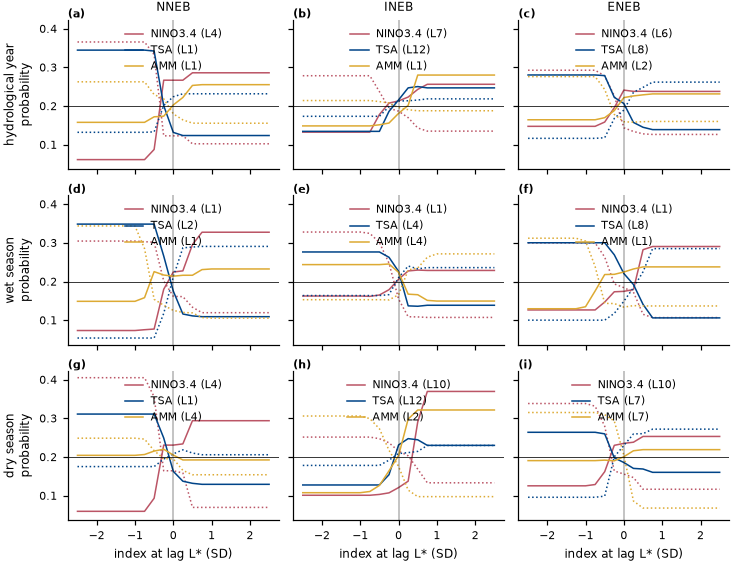

*Probabilidade prevista da classe muito seco (Q1, linha contínua) e muito chuvoso (Q5, linha pontilhada) para cada valor do índice na defasagem L* (indicada na legenda), por caso (linhas) e alvo (colunas). Linha horizontal: 20 %. Arquivos: `resultados/completo/figuras/F20_resposta_randomforest.png` e `.pdf` (169 × 130 mm).*

**Tabela 34. Random Forest: desempenho, 2011–2025**

,método,alvo,caso,índice,versão,defasagem (meses),RPSS (%),IC95 inferior,IC95 superior,p (troca de sinal),acerto da classe mais provável (%),ROC muito seco (Q1),ROC seco ou muito seco (Q1–Q2),ROC chuvoso ou muito chuvoso (Q4–Q5),ROC muito chuvoso (Q5),anos de teste,meses de teste
0,Random Forest,NNEB,ano hidrológico,NINO3.4,L* (aferida),4,-1.8,-10.3,7.0,0.693,18.9,0.616,0.583,0.598,0.571,15,180
1,Random Forest,NNEB,ano hidrológico,NINO3.4,L1 (mês anterior),1,0.4,-7.9,8.7,0.910,26.7,0.570,0.559,0.614,0.621,15,180
2,Random Forest,NNEB,ano hidrológico,TSA,L* (aferida),1,2.5,-3.6,7.7,0.453,20.0,0.583,0.581,0.577,0.583,15,180
3,Random Forest,NNEB,ano hidrológico,TSA,L1 (mês anterior),1,3.0,-3.2,7.9,0.374,19.4,0.584,0.580,0.575,0.582,15,180
4,Random Forest,NNEB,ano hidrológico,AMM,L* (aferida),1,-0.6,-2.2,1.4,0.608,20.0,0.570,0.507,0.478,0.429,15,180
5,Random Forest,NNEB,ano hidrológico,AMM,L1 (mês anterior),1,-0.6,-2.3,1.4,0.638,19.4,0.579,0.531,0.486,0.433,15,180
6,Random Forest,NNEB,estação chuvosa,NINO3.4,L* (aferida),1,-16.6,-31.7,-1.4,0.070,17.3,0.434,0.451,0.477,0.503,15,75
7,Random Forest,NNEB,estação chuvosa,NINO3.4,L1 (mês anterior),1,-15.4,-31.3,0.2,0.081,17.3,0.425,0.451,0.478,0.507,15,75
8,Random Forest,NNEB,estação chuvosa,TSA,L* (aferida),2,2.0,-9.8,12.2,0.785,20.0,0.714,0.622,0.611,0.672,15,75
9,Random Forest,NNEB,estação chuvosa,TSA,L1 (mês anterior),1,8.3,-1.4,16.9,0.128,24.0,0.781,0.698,0.688,0.679,15,75


*Alvo inteiro, mês a mês, para cada índice em L* (aferida) e em L1 (mês anterior). RPSS em relação ao mesmo modelo sem o índice (IC95 por reamostragem conjunta de blocos de 3 anos; p da troca de sinal por ano); acerto da classe mais provável (acaso = 20 %); área ROC de cada evento (acaso = 0,5). Mostradas 18 de 54 linhas. Arquivo: `resultados/completo/tabelas/T34_metricas_randomforest.csv`.*

**Figura 21. Random Forest: ganho de cada índice sobre o modelo sem índice**

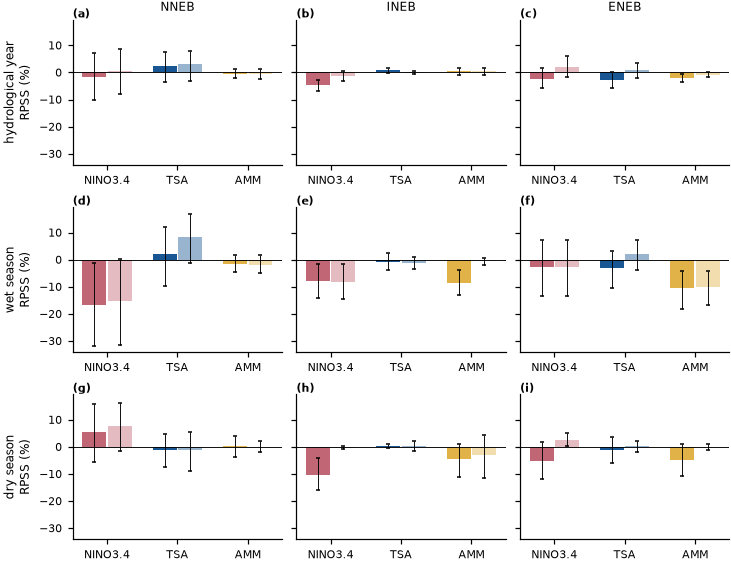

*RPSS em 2011–2025 na previsão da classe de quintil do alvo inteiro, por caso (linhas) e alvo (colunas). Para cada índice: barra escura, índice na defasagem aferida L*; barra clara, índice no mês anterior (L1). Barras de erro: IC95 por blocos de anos. Acima de zero, fornecer o índice melhora este modelo; não implica ganho sobre a climatologia empírica. Arquivos: `resultados/completo/figuras/F21_rpss_randomforest.png` e `.pdf` (169 × 130 mm).*

**Tabela 35. Random Forest: comparações A e C**

,método,grupo,alvo,caso,índice,comparação,diferença de RPSS (p.p.),IC95 inferior,IC95 superior,p,diferença de acerto (p.p.),IC95 inferior (acerto),IC95 superior (acerto),p (acerto),q (BH),p (nulo)
0,Random Forest,A (hipótese),NNEB,ano hidrológico,NINO3.4,L* − sem índice,-1.8,-10.6,6.8,0.693,2.2,-4.4,10.6,0.66,1.00,0.69
1,Random Forest,C,NNEB,ano hidrológico,NINO3.4,L4 − L1,-2.2,-6.1,1.3,0.475,-7.8,-12.8,-2.2,0.09,0.64,NaN
2,Random Forest,A (hipótese),NNEB,ano hidrológico,TSA,L* − sem índice,2.5,-3.9,8.0,0.453,4.4,0.0,8.9,0.25,0.31,0.05
3,Random Forest,A (hipótese),NNEB,ano hidrológico,AMM,L* − sem índice,-0.6,-2.2,1.3,0.608,1.7,-8.9,13.3,0.87,1.00,0.44
4,Random Forest,A (hipótese),NNEB,estação chuvosa,NINO3.4,L* − sem índice,-16.6,-32.4,-1.3,0.070,1.3,-12.0,14.7,1.00,1.00,1.00
5,Random Forest,A (hipótese),NNEB,estação chuvosa,TSA,L* − sem índice,2.0,-10.4,12.0,0.785,-4.0,-20.0,9.3,0.74,0.31,0.05
6,Random Forest,C,NNEB,estação chuvosa,TSA,L2 − L1,-6.3,-14.8,1.0,0.285,-4.0,-12.0,2.7,0.75,0.47,NaN
7,Random Forest,A (hipótese),NNEB,estação chuvosa,AMM,L* − sem índice,-1.5,-4.7,1.6,0.490,-4.0,-14.7,6.7,0.75,1.00,0.38
8,Random Forest,A (hipótese),NNEB,estação seca,NINO3.4,L* − sem índice,5.6,-4.9,16.1,0.309,5.7,-6.7,21.9,0.62,0.21,0.01
9,Random Forest,C,NNEB,estação seca,NINO3.4,L4 − L1,-2.3,-8.3,3.6,0.531,-5.7,-15.2,5.7,0.42,0.64,NaN


*Diferença de RPSS e de acerto (pontos percentuais) entre duas previsões, nos mesmos meses; positivo: a primeira acerta mais. A (hipótese): índice em L* − mesmo modelo sem índice. C: índice em L* − índice em L1, só quando L* é diferente de 1. q: Benjamini-Hochberg em cada grupo. Mostradas 18 de 45 linhas. Arquivo: `resultados/completo/tabelas/T35_comparacoes_randomforest.csv`.*

**Tabela 36. Random Forest: teste da hipótese em cada alvo, caso e índice**

,método,alvo,caso,índice,L* (meses),RPSS sobre o modelo sem índice (%),IC95 inferior,IC95 superior,p (nulo),q,hipótese sustentada,acerto (%),ROC muito seco,ROC muito chuvoso,ganho de L* sobre L1 (p.p.),q (L* − L1)
0,Random Forest,NNEB,ano hidrológico,NINO3.4,4,-1.8,-10.6,6.8,0.69,1.00,False,18.9,0.616,0.571,-2.24,0.637
1,Random Forest,NNEB,ano hidrológico,TSA,1,2.5,-3.9,8.0,0.05,0.31,False,20.0,0.583,0.583,NaN,NaN
2,Random Forest,NNEB,ano hidrológico,AMM,1,-0.6,-2.2,1.3,0.44,1.00,False,20.0,0.570,0.429,NaN,NaN
3,Random Forest,NNEB,estação chuvosa,NINO3.4,1,-16.6,-32.4,-1.3,1.00,1.00,False,17.3,0.434,0.503,NaN,NaN
4,Random Forest,NNEB,estação chuvosa,TSA,2,2.0,-10.4,12.0,0.05,0.31,False,20.0,0.714,0.672,-6.31,0.467
5,Random Forest,NNEB,estação chuvosa,AMM,1,-1.5,-4.7,1.6,0.38,1.00,False,20.0,0.519,0.402,NaN,NaN
6,Random Forest,NNEB,estação seca,NINO3.4,4,5.6,-4.9,16.1,0.01,0.21,False,25.7,0.679,0.663,-2.27,0.637
7,Random Forest,NNEB,estação seca,TSA,1,-1.1,-7.9,4.5,0.63,1.00,False,13.3,0.454,0.519,NaN,NaN
8,Random Forest,NNEB,estação seca,AMM,4,0.3,-3.8,4.1,0.30,1.00,False,21.9,0.328,0.581,0.38,0.892
9,Random Forest,INEB,ano hidrológico,NINO3.4,7,-4.7,-6.8,-2.7,0.99,1.00,False,19.0,0.487,0.423,-3.27,0.183


*Hipótese sustentada quando o modelo que lê o índice alinhado na defasagem aferida L* tem RPSS positivo sobre o mesmo modelo sem índice e q < 0,05. p (nulo): fração das 130 séries do índice deslocadas no tempo (L* reaferido, modelo retreinado), mais a observada, com RPSS igual ou maior; testa se o alinhamento temporal do índice importa; q: Benjamini-Hochberg nas 27 comparações do método. Não detectado não é ausência de efeito: o IC95 expressa a incerteza da estimativa, sem provar ausência de efeito nem substituir o teste. Ganho de L* sobre L1: vazio quando L* = 1. Arquivo: `resultados/completo/tabelas/T36_hipotese_randomforest.csv`.*

**Tabela 37. Random Forest: quantil observado e previsto**

,alvo,caso,mês,quantil observado,classe observada,NINO3.4 em L*: quantil esperado,NINO3.4 em L*: P(Q1–Q2),TSA em L*: quantil esperado,TSA em L*: P(Q1–Q2),AMM em L*: quantil esperado,AMM em L*: P(Q1–Q2)
0,NNEB,ano hidrológico,2011-01-01,0.90,Q5 muito chuvoso,0.631,0.207,0.555,0.325,0.467,0.411
1,NNEB,ano hidrológico,2011-02-01,0.90,Q5 muito chuvoso,0.631,0.207,0.555,0.325,0.467,0.411
2,NNEB,ano hidrológico,2011-03-01,0.33,Q2 seco,0.631,0.207,0.555,0.325,0.467,0.411
3,NNEB,ano hidrológico,2011-04-01,0.63,Q4 chuvoso,0.631,0.207,0.555,0.325,0.480,0.399
4,NNEB,ano hidrológico,2011-05-01,0.77,Q4 chuvoso,0.631,0.207,0.555,0.325,0.493,0.399
5,NNEB,ano hidrológico,2011-06-01,0.43,Q3 normal,0.631,0.207,0.550,0.331,0.484,0.395
6,NNEB,ano hidrológico,2011-07-01,0.87,Q5 muito chuvoso,0.631,0.207,0.537,0.351,0.467,0.411
7,NNEB,ano hidrológico,2011-08-01,0.73,Q4 chuvoso,0.631,0.207,0.555,0.325,0.484,0.395
8,NNEB,ano hidrológico,2011-09-01,0.00,Q1 muito seco,0.624,0.217,0.555,0.325,0.484,0.395
9,NNEB,ano hidrológico,2011-10-01,1.00,Q5 muito chuvoso,0.439,0.485,0.555,0.325,0.467,0.411


*Quantil u observado em cada mês de teste e, para cada índice em L*, o quantil esperado da previsão (média dos centros das classes pesada pelas probabilidades) e a probabilidade prevista de seco ou muito seco (Q1–Q2). Mostradas 12 de 1032 linhas. Arquivo: `resultados/completo/tabelas/T37_serie_randomforest.csv`.*

**Figura 22. Random Forest: quantil observado e previsto no alvo inteiro**

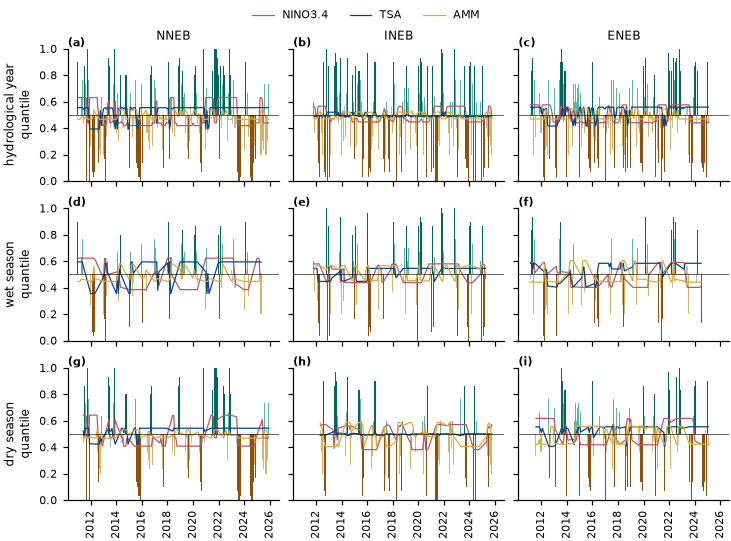

*Barras: quantil u observado em cada mês de teste (2011–2025), a partir da mediana, com a cor da classe. Linhas: quantil esperado da previsão do modelo com cada índice, sozinho, na defasagem aferida L*. Por caso (linhas) e alvo (colunas). Arquivos: `resultados/completo/figuras/F22_serie_randomforest.png` e `.pdf` (169 × 125 mm).*

#### Síntese numérica

- Hipótese sustentada em 0 de 27 combinações de alvo, caso e índice.
- Validade do teste: sob o nulo (130 deslocamentos do índice), a troca de sinal deu p < 0,05 em 6,4 % das previsões (esperado: 5 %); a hipótese usa o valor-p do nulo por deslocamento, que mantém a ordem interna do índice.
- Largura do IC95 do RPSS: mediana de 11,4 p.p. (de 1,5 a 31,2 p.p.).
- Índice em l* contra o modelo sem índice: 27 comparações; a primeira previsão acerta mais com q < 0,05 em 0 e menos em 0; com p < 0,05 sem correção, 5 (esperadas por acaso: cerca de 1).
- Índice em l* contra o índice em l1: 18 comparações; a primeira previsão acerta mais com q < 0,05 em 0 e menos em 0; com p < 0,05 sem correção, 3 (esperadas por acaso: cerca de 1).
- NINO3.4 em L*: maior RPSS em NNEB, estação seca (+5,6 %; IC95 −5,5 a +15,7); área ROC de muito seco 0,68.
- TSA em L*: maior RPSS em NNEB, ano hidrológico (+2,5 %; IC95 −3,6 a +7,7); área ROC de muito seco 0,58.
- AMM em L*: maior RPSS em INEB, ano hidrológico (+0,4 %; IC95 −0,9 a +1,8); área ROC de muito seco 0,55.

### Relatório parcial 9 · 30/10/2026 19:51 · fim da Seção 7

Modo completo. Tempo decorrido: 13 min. Término geral previsto: 31/10/2026 12:19.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | concluída | 259 / 259 | 6 min | 0 min | — |
| Seção 5 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 6 | concluída | 54 / 54 | 1 min | 0 min | — |
| Seção 7 | concluída | 54 / 54 | 3 min | 0 min | — |
| Seção 8 | aguardando | 0 / 54 | 0 min | 7 min (a priori) | 30/10 19:58 |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 30/10 23:36 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 12:18 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 12:19 |

Últimos registros:
- 2026-10-30T22:48:26+00:00 | Random Forest: nenhuma combinação com o modelo idêntico ao controle sem índice.
- 2026-10-30T22:48:26+00:00 | Random Forest: 54 unidades ajustadas nesta execução; configuração {'profundidade': 1, 'folha': 0.3, 'arvores': 100}.
- 2026-10-30T22:51:44+00:00 | Seção 7: concluída em 3 min.



In [18]:
# =============================================================================
# 7.3 Tabelas, figuras e síntese da Random Forest. Lê apenas as previsões gravadas em 7.2 e a
# controle do mesmo modelo sem índice, gravado na mesma seção.
# =============================================================================
MET_RF, CMP_RF, HIP_RF = relatorio_metodo('Random Forest', 'Seção 7')

### 7.4 Results and discussion

The response curve shows how the model reads each index: if the probability of very dry rises with positive NINO3.4 and that of very wet rises with positive TSA, the model follows the physical mechanism; flat curves at 20% show that the model barely uses the index. The RPSS, with its 95% CI, compares the model with the control of the same model without the index in the test period; the ROC area of the dry events says whether the model ranks the deficit months well, even when the RPSS is small. For the random forest, the curve is made of steps; it does not show how many years support each step.

### 7.5 Conclusion

The section delivers the forecast probabilities of each test month, the hypothesis test for each target, case and index, and the comparison between the index at the assessed lag and in the previous month, read by Section 9.

### 7.6 References

BREIMAN, L. Random forests. **Machine Learning**, v. 45, p. 5-32, 2001. DOI: 10.1023/A:1010933404324.

---

# Section 8. Neural network

### 8.1 Theoretical and methodological basis

**Scientific question.** In a neural network, does giving each index at the assessed lag improve the forecast of the quintile class of the target's monthly rainfall relative to the same model without the index?

**Introduction.** A dense neural network with one hidden layer transforms the input through several nonlinear functions and combines them into five outputs that, through the softmax function, sum to 1; with few neurons, it produces probabilities that change smoothly with the index. Networks of this kind, fed with climate indices, have been used for rainfall in Ceará (Pinheiro and Ouarda, 2023).

**Rationale.** The smooth curve lies between the ridge line and the random forest steps. Because each model receives only the index, a network that reads sequences of maps (such as a ConvLSTM) would have nothing to read; the dense network receives exactly the same input as the other two models.

**Hypotheses.** For each target, case and index: H0, the RPSS of the model with the index aligned at the assessed lag L*, measured over the same model without the index, does not exceed that obtained with the time-shifted index (with no temporal relation to rainfall); H1, it does. Decision: RPSS > 0 and q < 0.05. Complementary question: does the index at L* beat the same index in the previous month (L1)?

**Objective.** For each target, case and index, forecast the probability of each quintile class for each month of 2011–2025 with the index at L* and at L1, and make comparisons A (L* against the same model without the index) and C (L* against L1).

**Data and methodology.**
- Input: a single index, in the form and with the filter chosen in Section 4, anchored at month t − L (L* from Section 2 or L1). Example: NNEB, hydrological year, NINO3.4 with L* = 4: March is forecast with the NINO3.4 of November, April with that of December, and so on.
- Architecture and training chosen in Section 4 (hidden neurons, activation, weight decay and passes); cross-entropy loss; AdamW (Loshchilov and Hutter, 2019) with all training months in each pass, nothing drawn or shuffled, cosine learning-rate schedule; fixed number of passes, without early stopping. The forecast is the mean of 3 networks that differ only in their initial weights, the same number as in calibration and Section 10. Dropout is not used: with one hidden layer of few neurons and a single feature, the weight decay chosen in calibration already controls overfitting, and the grid extends to networks whose forecast is almost climatology.
- Training: a single fit with the months of the case in 1981–2010, which forecasts all months of 2011–2025 (the same protocol as calibration).
- Comparisons and tests: those of the Section 5 protocol; the hypothesis uses the p-value of the index-shift null.

**Limitations declared before the run.** Even with the chosen regularization, the network may follow part of the chance features of the training years; the response curve shows whether this happens.

**Outputs.** Tables: fitted units; response to each index; performance; comparisons A and C; hypothesis; test series. Figures: probability of the extremes as a function of the index; RPSS by index; observed and forecast quantile.

In [19]:
# =============================================================================
# 8.2 Processamento: rede neural densa. Para cada alvo, caso, índice e versão: entrada →
# camada oculta → 5 saídas com softmax (probabilidade de cada classe de quintil), treinada com
# entropia cruzada, todos os meses de treino em cada passagem (sem sorteio nem ordem), número
# fixo de passagens e sem parada antecipada; arquitetura, decaimento de pesos, passagens e
# ativação escolhidos na Seção 4; média de 3 redes que diferem só nos pesos iniciais.
# =============================================================================
PROGRESSO.iniciar('Seção 8', N_COMB * len(INDICES) * len(VERSOES))
_n = ajustar_metodo('Rede neural', 'Seção 8')
registrar(f'Rede neural: {_n} unidades treinadas nesta execução; configuração '
          f'{ESCOLHA["Rede neural"]}.')

Rede neural: nenhuma combinação com o modelo idêntico ao controle sem índice.


Rede neural: 54 unidades treinadas nesta execução; configuração {'oculta': 4, 'decaimento': 10.0, 'passagens': 200, 'ativacao': 'tanh', 'taxa': 0.01}.


**Tabela 38. Rede neural: unidades ajustadas**

,alvo,caso,índice,versão,defasagem (meses),treino (anos hidrológicos),meses de treino,segundos por unidade
0,NNEB,ano hidrológico,NINO3.4,L* (aferida),4,1981–2010,360,0.044
1,NNEB,ano hidrológico,NINO3.4,L1 (mês anterior),1,1981–2010,360,0.044
2,NNEB,ano hidrológico,TSA,L* (aferida),1,1981–2010,360,0.044
3,NNEB,ano hidrológico,TSA,L1 (mês anterior),1,1981–2010,360,0.044
4,NNEB,ano hidrológico,AMM,L* (aferida),1,1981–2010,360,0.044
5,NNEB,ano hidrológico,AMM,L1 (mês anterior),1,1981–2010,360,0.044
6,NNEB,estação chuvosa,NINO3.4,L* (aferida),1,1981–2010,150,0.044
7,NNEB,estação chuvosa,NINO3.4,L1 (mês anterior),1,1981–2010,150,0.044
8,NNEB,estação chuvosa,TSA,L* (aferida),2,1981–2010,150,0.044
9,NNEB,estação chuvosa,TSA,L1 (mês anterior),1,1981–2010,150,0.044


*Cada unidade lê um único índice, na forma escolhida na Seção 4 (registros/calibracao.json), é treinada uma vez com 1981–2010 e prevê a probabilidade de cada classe de quintil do alvo inteiro. Hiperparâmetros: {"oculta": 4, "decaimento": 10.0, "passagens": 200, "ativacao": "tanh", "taxa": 0.01}. Meses de treino: meses do caso nos anos hidrológicos de 1981–2010. Mostradas 18 de 54 linhas. Arquivo: `resultados/completo/tabelas/T38_unidades_redeneural.csv`.*

**Tabela 39. Rede neural: como o modelo lê cada índice**

,alvo,caso,índice,defasagem (meses),índice (dp),P(Q1),P(Q2),P(Q3),P(Q4),P(Q5)
0,NNEB,ano hidrológico,NINO3.4,4,-2.50,0.180,0.184,0.212,0.210,0.215
1,NNEB,ano hidrológico,NINO3.4,4,-2.25,0.182,0.185,0.211,0.209,0.213
2,NNEB,ano hidrológico,NINO3.4,4,-2.00,0.183,0.187,0.210,0.208,0.212
3,NNEB,ano hidrológico,NINO3.4,4,-1.75,0.185,0.188,0.209,0.207,0.210
4,NNEB,ano hidrológico,NINO3.4,4,-1.50,0.187,0.190,0.207,0.206,0.209
5,NNEB,ano hidrológico,NINO3.4,4,-1.25,0.189,0.192,0.206,0.205,0.208
6,NNEB,ano hidrológico,NINO3.4,4,-1.00,0.191,0.193,0.205,0.204,0.206
7,NNEB,ano hidrológico,NINO3.4,4,-0.75,0.194,0.195,0.204,0.203,0.205
8,NNEB,ano hidrológico,NINO3.4,4,-0.50,0.196,0.197,0.203,0.202,0.203
9,NNEB,ano hidrológico,NINO3.4,4,-0.25,0.198,0.198,0.201,0.201,0.202


*Probabilidade de cada classe prevista pelo modelo treinado em 1981–2010 para um índice que permanece no valor indicado nos meses que a entrada lê, média dos meses do caso. Mostradas 21 de 567 linhas. Arquivo: `resultados/completo/tabelas/T39_resposta_redeneural.csv`.*

**Figura 23. Rede neural: probabilidade dos extremos em função do índice**

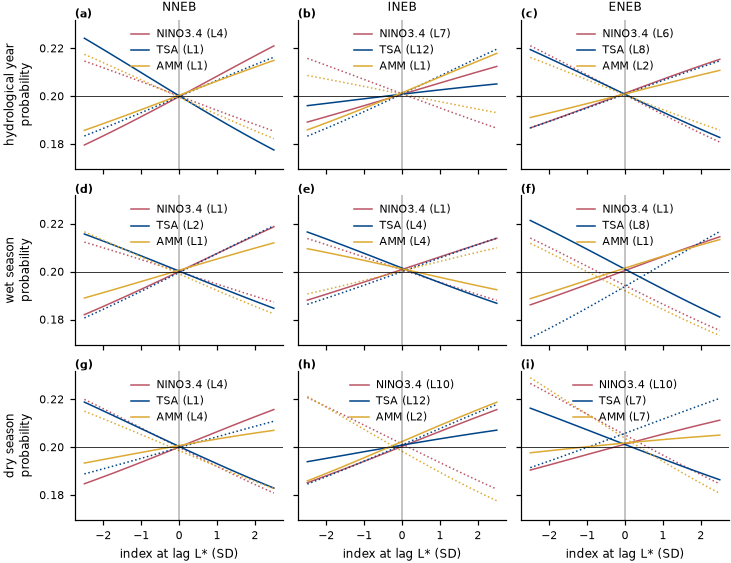

*Probabilidade prevista da classe muito seco (Q1, linha contínua) e muito chuvoso (Q5, linha pontilhada) para cada valor do índice na defasagem L* (indicada na legenda), por caso (linhas) e alvo (colunas). Linha horizontal: 20 %. Arquivos: `resultados/completo/figuras/F23_resposta_redeneural.png` e `.pdf` (169 × 130 mm).*

**Tabela 40. Rede neural: desempenho, 2011–2025**

,método,alvo,caso,índice,versão,defasagem (meses),RPSS (%),IC95 inferior,IC95 superior,p (troca de sinal),acerto da classe mais provável (%),ROC muito seco (Q1),ROC seco ou muito seco (Q1–Q2),ROC chuvoso ou muito chuvoso (Q4–Q5),ROC muito chuvoso (Q5),anos de teste,meses de teste
0,Rede neural,NNEB,ano hidrológico,NINO3.4,L* (aferida),4,0.80,-0.02,1.71,0.088,23.3,0.617,0.614,0.608,0.590,15,180
1,Rede neural,NNEB,ano hidrológico,NINO3.4,L1 (mês anterior),1,0.75,-0.13,1.68,0.123,20.0,0.603,0.574,0.627,0.635,15,180
2,Rede neural,NNEB,ano hidrológico,TSA,L* (aferida),1,0.57,-0.35,1.43,0.199,20.0,0.584,0.602,0.597,0.648,15,180
3,Rede neural,NNEB,ano hidrológico,TSA,L1 (mês anterior),1,0.52,-0.28,1.33,0.190,22.8,0.584,0.602,0.597,0.648,15,180
4,Rede neural,NNEB,ano hidrológico,AMM,L* (aferida),1,0.04,-0.44,0.57,0.906,20.0,0.593,0.543,0.489,0.437,15,180
5,Rede neural,NNEB,ano hidrológico,AMM,L1 (mês anterior),1,0.05,-0.54,0.70,0.900,20.0,0.593,0.543,0.489,0.437,15,180
6,Rede neural,NNEB,estação chuvosa,NINO3.4,L* (aferida),1,-0.13,-1.30,1.15,0.842,12.0,0.449,0.479,0.509,0.538,15,75
7,Rede neural,NNEB,estação chuvosa,NINO3.4,L1 (mês anterior),1,-0.14,-1.27,1.11,0.827,17.3,0.449,0.479,0.509,0.538,15,75
8,Rede neural,NNEB,estação chuvosa,TSA,L* (aferida),2,1.46,-0.17,3.06,0.133,22.7,0.736,0.632,0.647,0.679,15,75
9,Rede neural,NNEB,estação chuvosa,TSA,L1 (mês anterior),1,1.45,0.38,2.61,0.019,21.3,0.770,0.701,0.699,0.720,15,75


*Alvo inteiro, mês a mês, para cada índice em L* (aferida) e em L1 (mês anterior). RPSS em relação ao mesmo modelo sem o índice (IC95 por reamostragem conjunta de blocos de 3 anos; p da troca de sinal por ano); acerto da classe mais provável (acaso = 20 %); área ROC de cada evento (acaso = 0,5). Mostradas 18 de 54 linhas. Arquivo: `resultados/completo/tabelas/T40_metricas_redeneural.csv`.*

**Figura 24. Rede neural: ganho de cada índice sobre o modelo sem índice**

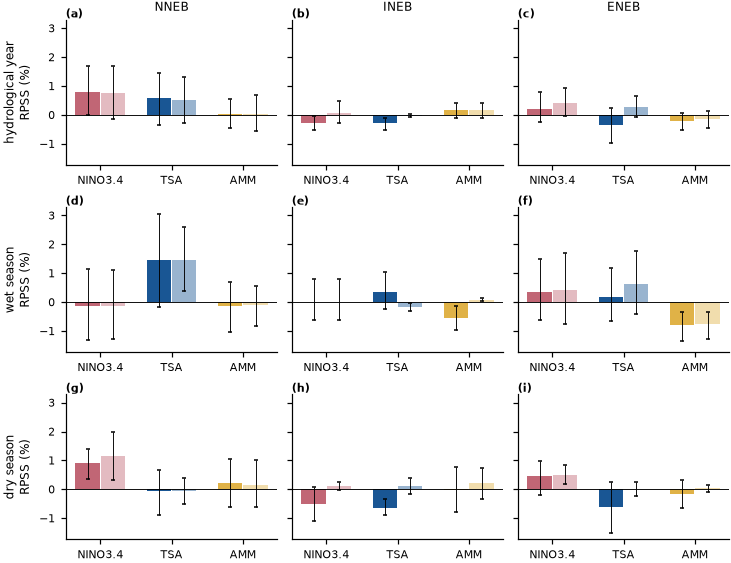

*RPSS em 2011–2025 na previsão da classe de quintil do alvo inteiro, por caso (linhas) e alvo (colunas). Para cada índice: barra escura, índice na defasagem aferida L*; barra clara, índice no mês anterior (L1). Barras de erro: IC95 por blocos de anos. Acima de zero, fornecer o índice melhora este modelo; não implica ganho sobre a climatologia empírica. Arquivos: `resultados/completo/figuras/F24_rpss_redeneural.png` e `.pdf` (169 × 130 mm).*

**Tabela 41. Rede neural: comparações A e C**

,método,grupo,alvo,caso,índice,comparação,diferença de RPSS (p.p.),IC95 inferior,IC95 superior,p,diferença de acerto (p.p.),IC95 inferior (acerto),IC95 superior (acerto),p (acerto),q (BH),p (nulo)
0,Rede neural,A (hipótese),NNEB,ano hidrológico,NINO3.4,L* − sem índice,0.80,-0.03,1.69,0.088,6.7,0.0,16.1,0.23,0.103,0.008
1,Rede neural,C,NNEB,ano hidrológico,NINO3.4,L4 − L1,0.05,-0.26,0.35,0.841,3.3,-3.3,10.6,0.47,0.946,NaN
2,Rede neural,A (hipótese),NNEB,ano hidrológico,TSA,L* − sem índice,0.57,-0.42,1.47,0.199,3.3,-4.4,8.9,0.52,0.137,0.015
3,Rede neural,A (hipótese),NNEB,ano hidrológico,AMM,L* − sem índice,0.04,-0.42,0.62,0.906,3.1,-0.8,6.9,0.54,0.745,0.359
4,Rede neural,A (hipótese),NNEB,estação chuvosa,NINO3.4,L* − sem índice,-0.13,-1.33,1.04,0.842,-10.7,-21.3,4.0,0.30,0.985,0.794
5,Rede neural,A (hipótese),NNEB,estação chuvosa,TSA,L* − sem índice,1.46,-0.23,3.08,0.133,-1.3,-9.3,9.3,1.00,0.103,0.008
6,Rede neural,C,NNEB,estação chuvosa,TSA,L2 − L1,0.01,-0.74,0.63,0.988,1.3,-8.0,9.3,1.00,0.988,NaN
7,Rede neural,A (hipótese),NNEB,estação chuvosa,AMM,L* − sem índice,-0.13,-1.01,0.74,0.813,-10.7,-26.7,4.0,0.28,0.985,0.687
8,Rede neural,A (hipótese),NNEB,estação seca,NINO3.4,L* − sem índice,0.91,0.39,1.39,0.007,10.5,-1.0,22.9,0.26,0.155,0.023
9,Rede neural,C,NNEB,estação seca,NINO3.4,L4 − L1,-0.25,-0.71,0.24,0.419,-1.0,-3.8,2.9,1.00,0.745,NaN


*Diferença de RPSS e de acerto (pontos percentuais) entre duas previsões, nos mesmos meses; positivo: a primeira acerta mais. A (hipótese): índice em L* − mesmo modelo sem índice. C: índice em L* − índice em L1, só quando L* é diferente de 1. q: Benjamini-Hochberg em cada grupo. Mostradas 18 de 45 linhas. Arquivo: `resultados/completo/tabelas/T41_comparacoes_redeneural.csv`.*

**Tabela 42. Rede neural: teste da hipótese em cada alvo, caso e índice**

,método,alvo,caso,índice,L* (meses),RPSS sobre o modelo sem índice (%),IC95 inferior,IC95 superior,p (nulo),q,hipótese sustentada,acerto (%),ROC muito seco,ROC muito chuvoso,ganho de L* sobre L1 (p.p.),q (L* − L1)
0,Rede neural,NNEB,ano hidrológico,NINO3.4,4,0.80,-0.03,1.69,0.008,0.103,False,23.3,0.617,0.590,0.049,0.946
1,Rede neural,NNEB,ano hidrológico,TSA,1,0.57,-0.42,1.47,0.015,0.137,False,20.0,0.584,0.648,NaN,NaN
2,Rede neural,NNEB,ano hidrológico,AMM,1,0.04,-0.42,0.62,0.359,0.745,False,20.0,0.593,0.437,NaN,NaN
3,Rede neural,NNEB,estação chuvosa,NINO3.4,1,-0.13,-1.33,1.04,0.794,0.985,False,12.0,0.449,0.538,NaN,NaN
4,Rede neural,NNEB,estação chuvosa,TSA,2,1.46,-0.23,3.08,0.008,0.103,False,22.7,0.736,0.679,0.006,0.988
5,Rede neural,NNEB,estação chuvosa,AMM,1,-0.13,-1.01,0.74,0.687,0.985,False,12.0,0.492,0.403,NaN,NaN
6,Rede neural,NNEB,estação seca,NINO3.4,4,0.91,0.39,1.39,0.023,0.155,False,30.5,0.725,0.701,-0.248,0.745
7,Rede neural,NNEB,estação seca,TSA,1,-0.06,-0.86,0.68,0.763,0.985,False,22.9,0.471,0.603,NaN,NaN
8,Rede neural,NNEB,estação seca,AMM,4,0.23,-0.59,1.10,0.321,0.745,False,22.9,0.630,0.591,0.096,0.946
9,Rede neural,INEB,ano hidrológico,NINO3.4,7,-0.28,-0.52,-0.05,0.954,0.985,False,17.3,0.491,0.416,-0.342,0.419


*Hipótese sustentada quando o modelo que lê o índice alinhado na defasagem aferida L* tem RPSS positivo sobre o mesmo modelo sem índice e q < 0,05. p (nulo): fração das 130 séries do índice deslocadas no tempo (L* reaferido, modelo retreinado), mais a observada, com RPSS igual ou maior; testa se o alinhamento temporal do índice importa; q: Benjamini-Hochberg nas 27 comparações do método. Não detectado não é ausência de efeito: o IC95 expressa a incerteza da estimativa, sem provar ausência de efeito nem substituir o teste. Ganho de L* sobre L1: vazio quando L* = 1. Arquivo: `resultados/completo/tabelas/T42_hipotese_redeneural.csv`.*

**Tabela 43. Rede neural: quantil observado e previsto**

,alvo,caso,mês,quantil observado,classe observada,NINO3.4 em L*: quantil esperado,NINO3.4 em L*: P(Q1–Q2),TSA em L*: quantil esperado,TSA em L*: P(Q1–Q2),AMM em L*: quantil esperado,AMM em L*: P(Q1–Q2)
0,NNEB,ano hidrológico,2011-01-01,0.90,Q5 muito chuvoso,0.514,0.373,0.505,0.395,0.481,0.420
1,NNEB,ano hidrológico,2011-02-01,0.90,Q5 muito chuvoso,0.516,0.370,0.504,0.396,0.483,0.418
2,NNEB,ano hidrológico,2011-03-01,0.33,Q2 seco,0.515,0.372,0.509,0.391,0.492,0.409
3,NNEB,ano hidrológico,2011-04-01,0.63,Q4 chuvoso,0.515,0.371,0.510,0.390,0.497,0.404
4,NNEB,ano hidrológico,2011-05-01,0.77,Q4 chuvoso,0.515,0.372,0.505,0.394,0.500,0.400
5,NNEB,ano hidrológico,2011-06-01,0.43,Q3 normal,0.511,0.378,0.501,0.399,0.498,0.403
6,NNEB,ano hidrológico,2011-07-01,0.87,Q5 muito chuvoso,0.509,0.384,0.499,0.401,0.495,0.405
7,NNEB,ano hidrológico,2011-08-01,0.73,Q4 chuvoso,0.507,0.386,0.502,0.398,0.498,0.403
8,NNEB,ano hidrológico,2011-09-01,0.00,Q1 muito seco,0.505,0.390,0.502,0.398,0.498,0.402
9,NNEB,ano hidrológico,2011-10-01,1.00,Q5 muito chuvoso,0.502,0.395,0.504,0.396,0.494,0.406


*Quantil u observado em cada mês de teste e, para cada índice em L*, o quantil esperado da previsão (média dos centros das classes pesada pelas probabilidades) e a probabilidade prevista de seco ou muito seco (Q1–Q2). Mostradas 12 de 1032 linhas. Arquivo: `resultados/completo/tabelas/T43_serie_redeneural.csv`.*

**Figura 25. Rede neural: quantil observado e previsto no alvo inteiro**

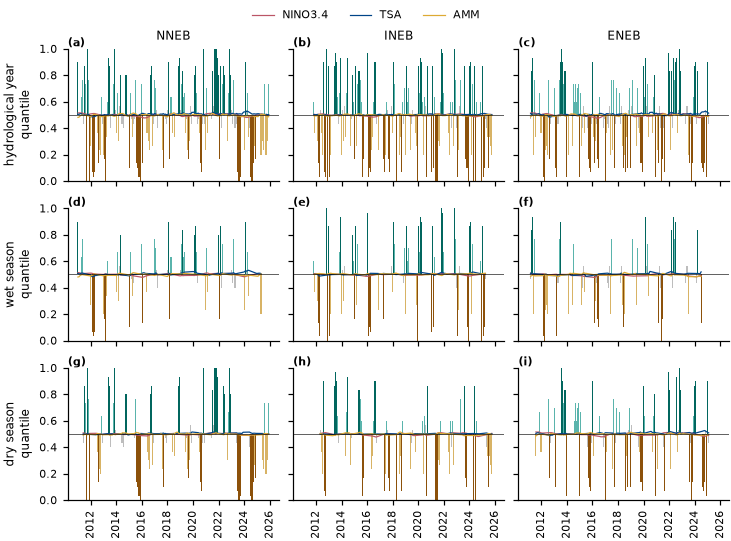

*Barras: quantil u observado em cada mês de teste (2011–2025), a partir da mediana, com a cor da classe. Linhas: quantil esperado da previsão do modelo com cada índice, sozinho, na defasagem aferida L*. Por caso (linhas) e alvo (colunas). Arquivos: `resultados/completo/figuras/F25_serie_redeneural.png` e `.pdf` (169 × 125 mm).*

#### Síntese numérica

- Hipótese sustentada em 0 de 27 combinações de alvo, caso e índice.
- Validade do teste: sob o nulo (130 deslocamentos do índice), a troca de sinal deu p < 0,05 em 3,1 % das previsões (esperado: 5 %); a hipótese usa o valor-p do nulo por deslocamento, que mantém a ordem interna do índice.
- Largura do IC95 do RPSS: mediana de 1,2 p.p. (de 0,4 a 3,3 p.p.).
- Índice em l* contra o modelo sem índice: 27 comparações; a primeira previsão acerta mais com q < 0,05 em 0 e menos em 0; com p < 0,05 sem correção, 4 (esperadas por acaso: cerca de 1).
- Índice em l* contra o índice em l1: 18 comparações; a primeira previsão acerta mais com q < 0,05 em 0 e menos em 0; com p < 0,05 sem correção, 2 (esperadas por acaso: cerca de 1).
- NINO3.4 em L*: maior RPSS em NNEB, estação seca (+0,9 %; IC95 +0,4 a +1,4); área ROC de muito seco 0,72.
- TSA em L*: maior RPSS em NNEB, estação chuvosa (+1,5 %; IC95 −0,2 a +3,1); área ROC de muito seco 0,74.
- AMM em L*: maior RPSS em NNEB, estação seca (+0,2 %; IC95 −0,6 a +1,0); área ROC de muito seco 0,63.

### Relatório parcial 10 · 30/10/2026 19:54 · fim da Seção 8

Modo completo. Tempo decorrido: 15 min. Término geral previsto: 31/10/2026 12:15.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | concluída | 259 / 259 | 6 min | 0 min | — |
| Seção 5 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 6 | concluída | 54 / 54 | 1 min | 0 min | — |
| Seção 7 | concluída | 54 / 54 | 3 min | 0 min | — |
| Seção 8 | concluída | 54 / 54 | 2 min | 0 min | — |
| Seção 9 | aguardando | 0 / 201 | 0 min | 3 h 38 min (a priori) | 30/10 23:31 |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 12:14 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 12:15 |

Últimos registros:
- 2026-10-30T22:51:47+00:00 | Rede neural: nenhuma combinação com o modelo idêntico ao controle sem índice.
- 2026-10-30T22:51:47+00:00 | Rede neural: 54 unidades treinadas nesta execução; configuração {'oculta': 4, 'decaimento': 10.0, 'passagens': 200, 'ativacao': 'tanh', 'taxa': 0.01}.
- 2026-10-30T22:54:02+00:00 | Seção 8: concluída em 2 min.



In [20]:
# =============================================================================
# 8.3 Tabelas, figuras e síntese da rede neural. Lê apenas as previsões gravadas em 8.2 e a
# controle do mesmo modelo sem índice, gravado na mesma seção.
# =============================================================================
MET_REDE, CMP_REDE, HIP_REDE = relatorio_metodo('Rede neural', 'Seção 8')

### 8.4 Results and discussion

The response curve shows how the model reads each index: if the probability of very dry rises with positive NINO3.4 and that of very wet rises with positive TSA, the model follows the physical mechanism; flat curves at 20% show that the model barely uses the index. The RPSS, with its 95% CI, compares the model with the control of the same model without the index in the test period; the ROC area of the dry events says whether the model ranks the deficit months well, even when the RPSS is small. For the network, oscillations in the response curve are compatible with overfitting but do not demonstrate it.

### 8.5 Conclusion

The section delivers the forecast probabilities of each test month, the hypothesis test for each target, case and index, and the comparison between the index at the assessed lag and in the previous month, read by Section 9.

### 8.6 References

LOSHCHILOV, I.; HUTTER, F. Decoupled weight decay regularization. In: INTERNATIONAL CONFERENCE ON LEARNING REPRESENTATIONS, 7., 2019, New Orleans. **Proceedings** [...]. 2019.

PINHEIRO, E.; OUARDA, T. B. M. J. Short-lead seasonal precipitation forecast in northeastern Brazil using an ensemble of artificial neural networks. **Scientific Reports**, v. 13, 20429, 2023. DOI: 10.1038/s41598-023-47841-y.

---

# Section 9. Comparison between methods

### 9.1 Theoretical and methodological basis

**Scientific question.** On the same months, does one method forecast better than another with the same index, and does the gain from each index change between the hydrological year, the wet season and the dry season? Do the validity checks support the conclusions?

**Introduction.** Sections 6 to 8 test the hypothesis within each method. A more flexible method is preferable only if it scores better on the same months on which the others were evaluated.

**Rationale.** The three methods receive exactly the same input (the index at the assessed lag, in the form of Section 4); the comparison separates what comes from the index from what comes from the shape of the response (line, steps or curve) and shows in which part of the year each index helps most.

**Hypotheses.** For each target, case, index and pair of methods: H0, the two methods have the same RPS; H1, one has a lower RPS. The comparison between cases is descriptive, because the months evaluated differ.

**Objective.** Compare the three methods for each index at L* (group E), put the three cases side by side (group F), gather the hypothesis test of the three methods, indicate the forecast with the highest RPSS for each target, case and index, and evaluate the reliability of the probabilities and the validity of the tests.

**Data and methodology.**
- Comparison E: RPS difference between two methods on the same months, divided by the RPS of climatology N and multiplied by 100 (skill difference normalized by climatology, in percentage points); sign flip by year and Benjamini and Hochberg (1995) for each pair.
- Comparison F: the RPSS of each method over its control, side by side in the three cases (descriptive).
- Reliability: Brier score decomposition (Murphy, 1973) and reliability diagram for Q1 and Q5 (Gneiting et al., 2007).
- Check of the shift test, with ridge regression only and for the whole target only: 200 realizations in which the index is replaced by a series with the linear trend of the real index, kept in its position in time, plus residuals with the same spectrum and randomized phases (Ebisuzaki, 1997); rainfall is the real one. The scenario represents an index with no interannual relation to rainfall but with the linear trend of the real index. In each realization the whole p-value procedure (Section 5) is repeated. The observed rejection rate estimates the true rate with binomial uncertainty. Under the declared H0 (Section 5), a shared trend between index and rainfall counts as information from the index; a rate above 5% in this scenario is therefore not a type I error but the sensitivity of the test to the trend: where it occurs, a gain cannot be attributed to interannual variability. The check holds only for ridge regression, the whole target and this scenario; it does not extend to the random forest, the neural network, the maps or other scenarios.
- Sensitivity of the 95% CI to blocks of 2, 3 and 4 years, without retraining.

**Limitations declared before the run.** The configuration of each method comes from calibration in 1981–2010; another configuration might change the ranking of the methods in the test. The same shift scheme applied to statistics of different models does not guarantee the same false-positive rate; the empirical check covers ridge regression only.

**Outputs.** Tables: comparison between methods; cases side by side; hypothesis for the three methods; reliability; validity of the tests; check of the shift test; block sensitivity. Figures: RPSS difference between methods; RPSS by case; reliability diagram.

In [21]:
# =============================================================================
# 9.2 Processamento: comparação entre métodos para cada índice em L* (grupo E: diferença de
# RPS nos mesmos meses, dividida pelo RPS da climatologia N), casos lado a lado (grupo F) e
# hipótese nos três métodos. Lê apenas as previsões gravadas nas Seções 5 a 8. Não gera figuras.
# =============================================================================
R_SIM = CFG['avaliacao']['realizacoes_validade']
PROGRESSO.iniciar('Seção 9', 1 + R_SIM)
PARES = list(itertools.combinations(MODELOS, 2))
LINHAS_E = []
for alvo, caso in itertools.product(ALVOS, CASOS):
    am = ler_amostras(alvo, caso)
    for indice in INDICES:
        prev = {m: ler_unidade(m, alvo, caso, indice, 'aferida') for m in MODELOS}
        prev = {m: x for m, x in prev.items() if x is not None}
        for a, b in PARES:
            if a in prev and b in prev:
                LINHAS_E.append({'alvo': alvo, 'caso': caso, 'índice': indice,
                                 'comparação': f'{a} − {b}',
                                 **comparar(am, prev[a][0], prev[b][0],
                                            f'E:{alvo}:{caso}:{indice}:{a}:{b}')})
DIF_E = 'diferença de habilidade normalizada por N (p.p.)'
E_TAB = pd.DataFrame(LINHAS_E).rename(columns={'diferença de RPSS (p.p.)': DIF_E})
E_TAB['q (BH)'] = q_por_grupo(E_TAB, 'comparação')

MET_TODOS = pd.concat([MET_RIDGE, MET_RF, MET_REDE], ignore_index=True)
HIPOTESE = pd.concat([HIP_RIDGE, HIP_RF, HIP_REDE], ignore_index=True)
linhas = []
for metodo, alvo, indice in itertools.product(MODELOS, ALVOS, INDICES):
    linha = {'método': metodo, 'alvo': alvo, 'índice': indice}
    for caso in CASOS:
        d = MET_TODOS[(MET_TODOS['método'] == metodo) & (MET_TODOS.alvo == alvo)
                      & (MET_TODOS.caso == caso) & (MET_TODOS['índice'] == indice)
                      & (MET_TODOS['versão'] == 'aferida')]
        linha[f'L*, {ROTULO_CASO[caso]}'] = (int(d['defasagem (meses)'].iloc[0])
                                             if len(d) else np.nan)
        linha[f'RPSS, {ROTULO_CASO[caso]} (%)'] = (float(d['RPSS (%)'].iloc[0])
                                                  if len(d) else np.nan)
    linhas.append(linha)
F_TAB = pd.DataFrame(linhas)


# ----- confiabilidade das probabilidades de Q1 e Q5 (decomposição de Murphy do escore de Brier),
# juntando as 27 combinações de cada modelo, no L* -----
BINS_CONF = np.linspace(0, 1, 11)
LINHAS_CONF, LINHAS_DIAGRAMA = [], []
for metodo in MODELOS:
    for evento, ks in (('muito seco (Q1)', [0]), ('muito chuvoso (Q5)', [4])):
        pf, ob = [], []
        for alvo, caso, indice in itertools.product(ALVOS, CASOS, INDICES):
            am = ler_amostras(alvo, caso)
            x = ler_unidade(metodo, alvo, caso, indice, 'aferida')
            pf.append(x[0][:, ks].sum(1))
            ob.append(np.isin(am['cl'], ks).astype(float))
        pf, ob = np.concatenate(pf), np.concatenate(ob)
        caixa = np.clip(np.digitize(pf, BINS_CONF) - 1, 0, len(BINS_CONF) - 2)
        o_med = ob.mean()
        rel = res = 0.0
        for b in range(len(BINS_CONF) - 1):
            sel = caixa == b
            if sel.any():
                rel += sel.sum() * (pf[sel].mean() - ob[sel].mean()) ** 2
                res += sel.sum() * (ob[sel].mean() - o_med) ** 2
                LINHAS_DIAGRAMA.append({'método': metodo, 'evento': evento,
                                        'probabilidade prevista média': pf[sel].mean(),
                                        'frequência observada': ob[sel].mean(),
                                        'meses': int(sel.sum())})
        LINHAS_CONF.append({'método': metodo, 'evento': evento, 'meses': len(pf),
                            'frequência observada (%)': 100 * o_med,
                            'Brier': float(((pf - ob) ** 2).mean()),
                            'Brier da climatologia (20 %)': float(((0.2 - ob) ** 2).mean()),
                            'confiabilidade agrupada (menor é melhor)': rel / len(pf),
                            'resolução agrupada (maior é melhor)': res / len(pf),
                            'incerteza': o_med * (1 - o_med)})
CONFIAB = pd.DataFrame(LINHAS_CONF)
DIAGRAMA = pd.DataFrame(LINHAS_DIAGRAMA)
VALIDADE = pd.DataFrame([{
    'método': m, 'deslocamentos do nulo': len(DESLOC_NULO),
    'troca de sinal com p < 0,05 sob o nulo (%)':
        c.attrs.get('falsos positivos da troca de sinal (%)', np.nan),
    'largura mediana do IC95 do RPSS (p.p.)': float(
        (HIPOTESE[HIPOTESE['método'] == m]['IC95 superior']
         - HIPOTESE[HIPOTESE['método'] == m]['IC95 inferior']).median())}
    for m, c in zip(MODELOS, (CMP_RIDGE, CMP_RF, CMP_REDE))])
PROGRESSO.avancar('Seção 9')


# ----- validade do teste por deslocamento: índice substituto sem relação com a chuva -----
def substituto(r):
    """Índices substitutos da realização r: tendência linear de cada índice + resíduos com o
    mesmo espectro e fases sorteadas (Ebisuzaki, 1997; semente fixa). A chuva fica a real."""
    t = np.arange(len(Z_IDX))
    saida = np.empty_like(Z_IDX)
    for j in range(Z_IDX.shape[1]):
        b, a = np.polyfit(t, Z_IDX[:, j], 1)
        tendencia = a + b * t
        F = np.fft.rfft(Z_IDX[:, j] - tendencia)
        fases = np.random.default_rng(semente(f'substituto:{r}:{j}')).uniform(
            0, 2 * np.pi, len(F))
        fases[0] = 0.0
        if len(t) % 2 == 0:
            fases[-1] = 0.0
        saida[:, j] = tendencia + np.fft.irfft(np.abs(F) * np.exp(1j * fases), n=len(t))
    return saida


def p_deslocamento_ridge(base, tr, te):
    """Valor-p do nulo por deslocamento para cada alvo, caso e índice, repetindo o procedimento
    da Ridge (L* aferido no treino, ajuste, RPSS sobre o controle) com o índice 'base'."""
    combos = list(itertools.product(ALVOS, CASOS, INDICES))
    rpss = {}
    for k in [0, *DESLOC_NULO]:
        b = base if k == 0 else np.roll(base, int(k), axis=0)
        probl = [(a, c, i, aferir_L(tr[(a, c)], a, c, INDICES.index(i), b)) for a, c, i in combos]
        tarefas = montar_tarefas(probl, ENTRADA['entrada'], ENTRADA['sazonal'], ENTRADA['filtro'],
                                 {a: ANOS[a]['treino'] for a in ALVOS},
                                 {a: ANOS[a]['teste'] for a in ALVOS}, versao=f'sim{k}', base=b)
        probs = prever_tarefas('Ridge', ESCOLHA['Ridge'], tarefas, 'simulacao')
        probs0 = prever_tarefas('Ridge', ESCOLHA['Ridge'], sem_indice(tarefas), 'simulacao')
        for (a, c, i), P, P0 in zip(combos, probs, probs0):
            rpss.setdefault((a, c, i), []).append(rpss_e_troca(dict(te[(a, c)], clim=P0), P)[0])
    return {f'{a}|{c}|{i}': p_nulo(v[0], v[1:]) for (a, c, i), v in rpss.items()}


def validar_deslocamento():
    """Fração de p < 0,05 em cada combinação, em R_SIM realizações (gravada por realização)."""
    arq = PASTAS['registros'] / 'validade_deslocamento.json'
    combos = {f'{a}|{c}|{i}' for a, c, i in itertools.product(ALVOS, CASOS, INDICES)}
    feitos = ler_json(arq) if reaproveitar(arq, conferir=lambda o: all(
        k.isdigit() and int(k) < R_SIM and set(v) == combos
        and all(0 < p <= 1 for p in v.values()) for k, v in o.items())) else {}
    tr = {(a, c): montar_amostras(a, c, ANOS[a]['treino']) for a, c in itertools.product(
        ALVOS, CASOS)}
    te = {(a, c): ler_amostras(a, c) for a, c in itertools.product(ALVOS, CASOS)}
    for r in range(R_SIM):
        if str(r) not in feitos:
            feitos[str(r)] = p_deslocamento_ridge(substituto(r), tr, te)
            salvar_json(arq, feitos)
        PROGRESSO.avancar('Seção 9')
    return feitos


_sim = validar_deslocamento()
linhas = []
for chave in next(iter(_sim.values())):
    a, c, i = chave.split('|')
    p = np.array([_sim[r][chave] for r in _sim])
    k, n = int((p < ALFA).sum()), len(p)
    lo = stats.beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(0.975, k + 1, n - k) if k < n else 1.0
    linhas.append({'alvo': a, 'caso': c, 'índice': i, 'realizações': n, 'p < 0,05': k,
                   'taxa de rejeição (%)': 100 * k / n, 'IC95 inferior (%)': 100 * lo,
                   'IC95 superior (%)': 100 * hi,
                   'leitura': 'acima de 5 %' if lo > ALFA else ('abaixo de 5 %' if hi < ALFA
                                                                else 'compatível com 5 %')})
VALIDADE_DESLOC = pd.DataFrame(linhas)
# onde a verificação com a Ridge rejeita acima de 5 % com o índice substituto que compartilha com
# a chuva só a tendência linear, um ganho "significativo" não pode ser atribuído à variabilidade
# interanual e é requalificado como inconclusivo, em todos os métodos. Pela H0 declarada (a
# tendência comum conta como informação do índice), essas rejeições não são erros tipo I: medem
# a sensibilidade do teste à tendência.
_leitura = VALIDADE_DESLOC.set_index(['alvo', 'caso', 'índice'])['leitura']
HIPOTESE['teste por deslocamento (Ridge)'] = [
    _leitura.get((r.alvo, r.caso, r['índice']), 'não verificado') for _, r in HIPOTESE.iterrows()]
_liberal = HIPOTESE['teste por deslocamento (Ridge)'] == 'acima de 5 %'
HIPOTESE['veredito'] = np.where(HIPOTESE['hipótese sustentada'] & ~_liberal, 'sustentada',
                                np.where(HIPOTESE['hipótese sustentada'],
                                         'inconclusiva (sensível à tendência)', 'não detectada'))
HIPOTESE['hipótese sustentada'] = HIPOTESE['hipótese sustentada'] & ~_liberal

# ----- sensibilidade do IC95 ao comprimento dos blocos (sem retreinar) -----
linhas = []
for metodo, bloco in itertools.product(MODELOS, CFG['avaliacao']['blocos_sensibilidade']):
    larguras, acima = [], 0
    for alvo, caso, indice in itertools.product(ALVOS, CASOS, INDICES):
        x = ler_unidade(metodo, alvo, caso, indice, 'aferida')
        if x is None:
            continue
        a = por_ano(com_controle(ler_amostras(alvo, caso), metodo, alvo, caso, indice), x[0])
        _, lo, hi, _ = ic_razao(a['rps'], a['rps_n'], f'blocos:{metodo}:{alvo}:{caso}:{indice}',
                                bloco=bloco)
        larguras.append(hi - lo)
        acima += lo > 0
    linhas.append({'método': metodo, 'bloco (anos)': bloco,
                   'largura mediana do IC95 (p.p.)': float(np.median(larguras)),
                   'combinações com IC95 acima de zero': int(acima), 'combinações': len(larguras)})
BLOCOS_TAB = pd.DataFrame(linhas)
registrar(f"Seção 9: {len(E_TAB)} comparações entre métodos; hipótese sustentada em "
          f"{int(HIPOTESE['hipótese sustentada'].sum())} de {len(HIPOTESE)} combinações de "
          'método, alvo, caso e índice.')

Seção 9: 81 comparações entre métodos; hipótese sustentada em 0 de 81 combinações de método, alvo, caso e índice.


**Tabela 44. Comparação E: entre métodos, para cada índice em L***

,alvo,caso,índice,comparação,diferença de habilidade normalizada por N (p.p.),IC95 inferior,IC95 superior,p,diferença de acerto (p.p.),IC95 inferior (acerto),IC95 superior (acerto),p (acerto),q (BH)
0,NNEB,ano hidrológico,NINO3.4,Ridge − Random Forest,2.8,-5.6,10.7,0.509,2.2,-11.7,17.8,0.80,0.675
1,NNEB,ano hidrológico,NINO3.4,Ridge − Rede neural,0.2,0.1,0.4,0.022,-2.2,-15.6,13.9,0.80,0.201
2,NNEB,ano hidrológico,NINO3.4,Random Forest − Rede neural,-2.6,-10.8,5.5,0.544,-4.4,-7.2,-1.1,0.09,0.700
3,NNEB,ano hidrológico,TSA,Ridge − Random Forest,-1.8,-6.7,4.4,0.556,2.2,-6.1,11.7,0.76,0.675
4,NNEB,ano hidrológico,TSA,Ridge − Rede neural,0.1,-0.1,0.3,0.424,2.2,-6.7,11.7,0.77,0.674
5,NNEB,ano hidrológico,TSA,Random Forest − Rede neural,1.9,-3.6,6.3,0.527,0.0,-1.1,1.1,1.00,0.700
6,NNEB,ano hidrológico,AMM,Ridge − Random Forest,0.8,-0.9,2.2,0.412,5.0,-4.4,14.4,0.37,0.675
7,NNEB,ano hidrológico,AMM,Ridge − Rede neural,0.1,-0.1,0.3,0.370,5.0,0.0,10.0,0.26,0.647
8,NNEB,ano hidrológico,AMM,Random Forest − Rede neural,-0.7,-1.9,0.7,0.427,0.0,-8.3,7.8,1.00,0.642
9,NNEB,estação chuvosa,NINO3.4,Ridge − Random Forest,16.9,2.8,32.2,0.047,5.3,-4.0,14.7,0.53,0.212


*Diferença de habilidade normalizada pela climatologia: 100 × (RPS do segundo − RPS do primeiro) / RPS de N, nos mesmos meses de 2011–2025, entre dois métodos que leem o mesmo índice na mesma defasagem (pontos percentuais); e diferença de acerto. Positivo: o primeiro método tem RPS menor ou acerta mais. Os RPSS de cada método não são comparados entre si, porque cada um tem o seu controle. IC95 por reamostragem de anos; p da troca de sinal por ano; q: Benjamini-Hochberg em cada par de métodos. Mostradas 27 de 81 linhas. Arquivo: `resultados/completo/tabelas/T44_comparacao_E.csv`.*

**Figura 26. Diferença de RPS normalizada por N entre métodos**

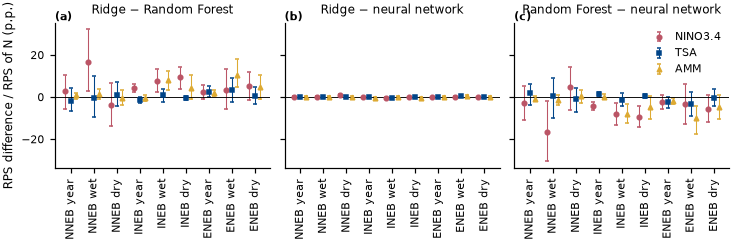

*Diferença de RPS normalizada por N: 100 × (RPS do segundo − RPS do primeiro) / RPS de N, nos mesmos meses de 2011–2025, com cada índice na defasagem aferida L*, por alvo e caso (pontos percentuais); barras de erro: IC95 por reamostragem de anos. Acima de zero, o primeiro método do par tem RPS menor. Não compara os RPSS de cada método, que têm controles diferentes. Arquivos: `resultados/completo/figuras/F26_comparacao_metodos.png` e `.pdf` (169 × 56 mm).*

**Tabela 45. Comparação F: os três casos lado a lado**

,método,alvo,índice,"L*, ano hidrológico","RPSS, ano hidrológico (%)","L*, estação chuvosa","RPSS, estação chuvosa (%)","L*, estação seca","RPSS, estação seca (%)"
0,Ridge,NNEB,NINO3.4,4,0.94,1,-0.0,4,1.8
1,Ridge,NNEB,TSA,1,0.58,2,1.5,1,-0.0
2,Ridge,NNEB,AMM,1,0.06,1,-0.1,4,0.1
3,Ridge,INEB,NINO3.4,7,-0.19,1,-0.0,10,-0.4
4,Ridge,INEB,TSA,12,-0.23,4,0.3,12,-0.3
5,Ridge,INEB,AMM,1,0.08,4,-0.2,2,0.0
6,Ridge,ENEB,NINO3.4,6,0.23,1,0.4,10,0.4
7,Ridge,ENEB,TSA,8,-0.32,8,0.5,7,-0.5
8,Ridge,ENEB,AMM,2,-0.09,1,-0.4,7,-0.1
9,Random Forest,NNEB,NINO3.4,4,-1.81,1,-16.6,4,5.6


*Por método, alvo e índice: defasagem aferida L* e RPSS em relação ao controle do mesmo modelo sem índice no ano hidrológico e nas estações chuvosa e seca. Descritivo: cada caso tem os seus meses e a sua defasagem. Arquivo: `resultados/completo/tabelas/T45_comparacao_F.csv`.*

**Figura 27. Ganho de cada índice sobre o modelo sem índice, por método e caso**

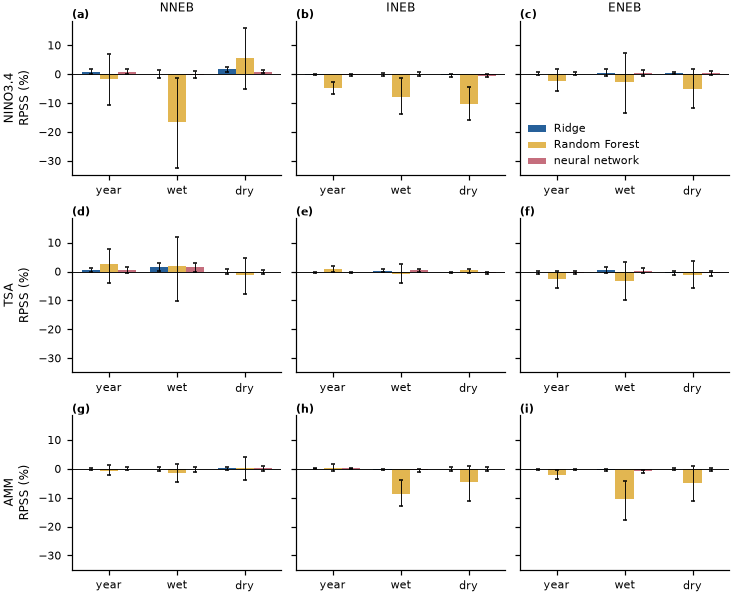

*RPSS em relação ao mesmo modelo sem índice (%) em 2011–2025, com cada índice (linhas) na defasagem aferida do seu alvo (colunas) e caso (eixo horizontal), por método (cores); barras de erro: IC95 por blocos de anos. Acima de zero, o índice melhora aquele modelo; os RPSS de métodos diferentes têm denominadores diferentes e não são comparados entre si. Arquivos: `resultados/completo/figuras/F27_rpss_por_caso.png` e `.pdf` (169 × 137 mm).*

**Tabela 46. Teste da hipótese nos três métodos**

,método,alvo,caso,índice,L* (meses),RPSS sobre o modelo sem índice (%),IC95 inferior,IC95 superior,p (nulo),q,hipótese sustentada,acerto (%),ROC muito seco,ROC muito chuvoso,ganho de L* sobre L1 (p.p.),q (L* − L1),teste por deslocamento (Ridge),veredito
0,Ridge,NNEB,ano hidrológico,NINO3.4,4,0.94,0.06,1.90,0.01,0.07,False,21.1,0.617,0.590,0.084,0.851,compatível com 5 %,não detectada
1,Ridge,NNEB,ano hidrológico,TSA,1,0.58,-0.27,1.38,0.03,0.14,False,22.2,0.584,0.648,NaN,NaN,acima de 5 %,não detectada
2,Ridge,NNEB,ano hidrológico,AMM,1,0.06,-0.26,0.39,0.27,0.67,False,25.0,0.593,0.437,NaN,NaN,compatível com 5 %,não detectada
3,Ridge,NNEB,estação chuvosa,NINO3.4,1,-0.01,-1.37,1.42,0.69,1.00,False,22.7,0.449,0.538,NaN,NaN,compatível com 5 %,não detectada
4,Ridge,NNEB,estação chuvosa,TSA,2,1.53,0.06,3.11,0.01,0.07,False,33.3,0.736,0.679,-0.250,0.777,compatível com 5 %,não detectada
5,Ridge,NNEB,estação chuvosa,AMM,1,-0.07,-0.88,0.62,0.73,1.00,False,34.7,0.492,0.403,NaN,NaN,compatível com 5 %,não detectada
6,Ridge,NNEB,estação seca,NINO3.4,4,1.81,0.77,2.67,0.01,0.07,False,20.0,0.725,0.701,0.380,0.572,compatível com 5 %,não detectada
7,Ridge,NNEB,estação seca,TSA,1,-0.03,-0.81,0.73,0.76,1.00,False,15.2,0.471,0.603,NaN,NaN,acima de 5 %,não detectada
8,Ridge,NNEB,estação seca,AMM,4,0.13,-0.32,0.57,0.33,0.74,False,16.2,0.630,0.591,0.040,0.905,compatível com 5 %,não detectada
9,Ridge,INEB,ano hidrológico,NINO3.4,7,-0.19,-0.40,-0.01,0.98,1.00,False,19.6,0.491,0.416,-0.242,0.276,compatível com 5 %,não detectada


*Hipótese sustentada quando o modelo que lê o índice alinhado na defasagem aferida L* tem RPSS positivo sobre o mesmo modelo sem índice e q < 0,05 (valor-p do nulo por deslocamento; Benjamini-Hochberg nas 27 comparações de cada método). Ganho de L* sobre L1: se conhecer a defasagem melhora a previsão; vazio quando L* = 1. Mostradas 27 de 81 linhas. Arquivo: `resultados/completo/tabelas/T46_hipotese_tres_metodos.csv`.*

**Tabela 47. Confiabilidade das probabilidades de Q1 e Q5**

,método,evento,meses,frequência observada (%),Brier,Brier da climatologia (20 %),confiabilidade agrupada (menor é melhor),resolução agrupada (maior é melhor),incerteza
0,Ridge,muito seco (Q1),3096,20.9,0.165,0.166,0.001,0.001,0.165
1,Ridge,muito chuvoso (Q5),3096,17.2,0.143,0.143,0.001,0.000,0.143
2,Random Forest,muito seco (Q1),3096,20.9,0.166,0.166,0.001,0.001,0.165
3,Random Forest,muito chuvoso (Q5),3096,17.2,0.148,0.143,0.005,0.000,0.143
4,Rede neural,muito seco (Q1),3096,20.9,0.165,0.166,0.001,0.001,0.165
5,Rede neural,muito chuvoso (Q5),3096,17.2,0.143,0.143,0.001,0.000,0.143


*Decomposição de Murphy do escore de Brier dos eventos muito seco e muito chuvoso, juntando os meses de teste das 27 combinações de cada modelo com o índice em L*, com as probabilidades agrupadas em faixas de 0,1: confiabilidade e resolução são componentes agrupados e não somam exatamente o Brier original (Stephenson et al., 2008). Confiabilidade: quanto as probabilidades previstas se afastam das frequências observadas; resolução: quanto as frequências observadas mudam com a previsão. A área ROC mede discriminação, e não calibração. Arquivo: `resultados/completo/tabelas/T47_confiabilidade.csv`.*

**Figura 28. Diagrama de confiabilidade dos eventos extremos**

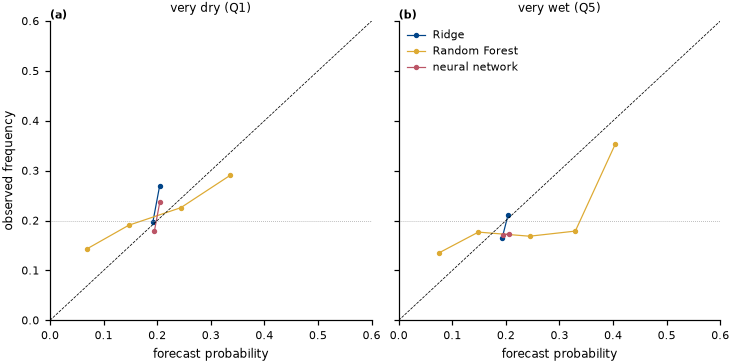

*Frequência observada contra a probabilidade prevista, em faixas de 0,1, para os eventos muito seco (a) e muito chuvoso (b), juntando as 27 combinações de cada modelo com o índice em L*. Diagonal: confiabilidade perfeita; linha pontilhada: frequência climatológica de 20 %. Arquivos: `resultados/completo/figuras/F28_confiabilidade.png` e `.pdf` (169 × 84 mm).*

**Tabela 48. Validade dos testes secundários**

,método,deslocamentos do nulo,"troca de sinal com p < 0,05 sob o nulo (%)",largura mediana do IC95 do RPSS (p.p.)
0,Ridge,130,3.25,0.9
1,Random Forest,130,6.41,11.4
2,Rede neural,130,3.11,1.2


*Fração das previsões feitas com o índice deslocado no tempo em que a troca de sinal por ano (usada nas comparações C e E) deu p < 0,05. Largura mediana do IC95 do RPSS da hipótese, como escala de incerteza; não é um cálculo de poder. Arquivo: `resultados/completo/tabelas/T48_validade_testes.csv`.*

**Tabela 49. Verificação do teste por deslocamento (Ridge, alvo inteiro, cenário com tendência)**

,alvo,caso,índice,realizações,"p < 0,05",taxa de rejeição (%),IC95 inferior (%),IC95 superior (%),leitura
0,NNEB,ano,NINO3.4,200,11,5.5,2.8,9.6,compatível com 5 %
1,NNEB,ano,TSA,200,18,9.0,5.4,13.9,acima de 5 %
2,NNEB,ano,AMM,200,8,4.0,1.7,7.7,compatível com 5 %
3,NNEB,chuvosa,NINO3.4,200,11,5.5,2.8,9.6,compatível com 5 %
4,NNEB,chuvosa,TSA,200,10,5.0,2.4,9.0,compatível com 5 %
5,NNEB,chuvosa,AMM,200,9,4.5,2.1,8.4,compatível com 5 %
6,NNEB,seca,NINO3.4,200,15,7.5,4.3,12.1,compatível com 5 %
7,NNEB,seca,TSA,200,34,17.0,12.1,22.9,acima de 5 %
8,NNEB,seca,AMM,200,13,6.5,3.5,10.9,compatível com 5 %
9,INEB,ano,NINO3.4,200,11,5.5,2.8,9.6,compatível com 5 %


... (2 outputs left out)

,método,bloco (anos),largura mediana do IC95 (p.p.),combinações com IC95 acima de zero,combinações
0,Ridge,2,1.0,3,27
1,Ridge,3,0.9,3,27
2,Ridge,4,0.9,2,27
3,Random Forest,2,12.3,0,27
4,Random Forest,3,11.3,0,27
5,Random Forest,4,9.2,1,27
6,Rede neural,2,1.4,2,27
7,Rede neural,3,1.2,2,27
8,Rede neural,4,1.1,2,27


*IC95 do RPSS da hipótese recalculado com blocos circulares de 2, 3 e 4 anos a partir das mesmas somas anuais, sem retreinar; o texto principal usa 3 anos, fixado antes como heurística. Arquivo: `resultados/completo/tabelas/T50_sensibilidade_blocos.csv`.*

#### Síntese numérica

- Ridge − Random Forest: 27 comparações; Ridge tem RPS menor com q < 0,05 em 0 e maior em 0.
- Ridge − Rede neural: 27 comparações; Ridge tem RPS menor com q < 0,05 em 1 e maior em 0.
- Random Forest − Rede neural: 27 comparações; Random Forest tem RPS menor com q < 0,05 em 0 e maior em 1.
- Ridge: hipótese sustentada em 0 de 27 combinações; maior ganho em NNEB, estação seca, NINO3.4 em L4 (RPSS +1,8 %).
- Random Forest: hipótese sustentada em 0 de 27 combinações; maior ganho em NNEB, estação seca, NINO3.4 em L4 (RPSS +5,6 %).
- Rede neural: hipótese sustentada em 0 de 27 combinações; maior ganho em NNEB, estação chuvosa, TSA em L2 (RPSS +1,5 %).
- NINO3.4: RPSS positivo sobre o modelo sem índice em 11 de 27 combinações de método, alvo e caso.
- TSA: RPSS positivo sobre o modelo sem índice em 12 de 27 combinações de método, alvo e caso.
- AMM: RPSS positivo sobre o modelo sem índice em 9 de 27 combinações de método, alvo e caso.
- Ridge, muito seco (Q1): Brier 0,165 contra 0,166 da climatologia; confiabilidade 0,0007, resolução agrupada 0,0007.
- Ridge, muito chuvoso (Q5): Brier 0,143 contra 0,143 da climatologia; confiabilidade 0,0007, resolução agrupada 0,0003.
- Random Forest, muito seco (Q1): Brier 0,166 contra 0,166 da climatologia; confiabilidade 0,0013, resolução agrupada 0,0007.
- Random Forest, muito chuvoso (Q5): Brier 0,148 contra 0,143 da climatologia; confiabilidade 0,0049, resolução agrupada 0,0003.
- Rede neural, muito seco (Q1): Brier 0,165 contra 0,166 da climatologia; confiabilidade 0,0006, resolução agrupada 0,0008.
- Rede neural, muito chuvoso (Q5): Brier 0,143 contra 0,143 da climatologia; confiabilidade 0,0008, resolução agrupada 0,0000.
- Ridge: sob o nulo, troca de sinal com p < 0,05 em 3,2 % das previsões.
- Random Forest: sob o nulo, troca de sinal com p < 0,05 em 6,4 % das previsões.
- Rede neural: sob o nulo, troca de sinal com p < 0,05 em 3,1 % das previsões.
- Teste por deslocamento (Ridge, 200 realizações por combinação): taxa de rejeição a 5 % de 2,0 a 18,5 %; acima de 5 % em 7 (NNEB ano TSA, NNEB seca TSA, INEB ano TSA, INEB seca TSA, INEB seca AMM, ENEB seca NINO3.4, ENEB seca TSA) e abaixo de 5 % em 0 das 27 combinações (cenário com a tendência linear do índice; não é taxa de erro tipo I da H0 declarada).
- Ridge: largura mediana do IC95 com blocos de 2 anos 1,0, 3 anos 0,9, 4 anos 0,9 p.p.; combinações com IC95 acima de zero: 3, 3, 2.
- Random Forest: largura mediana do IC95 com blocos de 2 anos 12,3, 3 anos 11,3, 4 anos 9,2 p.p.; combinações com IC95 acima de zero: 0, 0, 1.
- Rede neural: largura mediana do IC95 com blocos de 2 anos 1,4, 3 anos 1,2, 4 anos 1,1 p.p.; combinações com IC95 acima de zero: 2, 2, 2.

### Relatório parcial 11 · 30/10/2026 20:53 · fim da Seção 9

Modo completo. Tempo decorrido: 1 h 14 min. Término geral previsto: 31/10/2026 09:36.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | concluída | 259 / 259 | 6 min | 0 min | — |
| Seção 5 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 6 | concluída | 54 / 54 | 1 min | 0 min | — |
| Seção 7 | concluída | 54 / 54 | 3 min | 0 min | — |
| Seção 8 | concluída | 54 / 54 | 2 min | 0 min | — |
| Seção 9 | concluída | 201 / 201 | 59 min | 0 min | — |
| Seção 10 | aguardando | 0 / 3267 | 0 min | 12 h 42 min (a priori) | 31/10 09:35 |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 09:36 |

Últimos registros:
- 2026-10-30T22:54:02+00:00 | Seção 9: iniciada (201 unidades de trabalho).
- 2026-10-30T23:53:04+00:00 | Seção 9: 81 comparações entre métodos; hipótese sustentada em 0 de 81 combinações de método, alvo, caso e índice.
- 2026-10-30T23:53:09+00:00 | Seção 9: concluída em 59 min.



In [22]:
# =============================================================================
# 9.3 Tabelas, figuras e síntese do confronto entre métodos. Lê apenas o que 9.2 calculou.
# =============================================================================
tabela(com_rotulo(E_TAB), 'comparacao_E', 'Comparação E: entre métodos, para cada índice em L*',
       'Diferença de habilidade normalizada pela climatologia: 100 × (RPS do segundo − RPS do '
       'primeiro) / RPS de N, nos mesmos meses de 2011–2025, entre dois métodos que leem o mesmo '
       'índice na mesma defasagem (pontos percentuais); e diferença de acerto. Positivo: o '
       'primeiro método tem RPS menor ou acerta mais. Os RPSS de cada método não são '
       'comparados entre si, porque '
       'cada um tem o seu controle. IC95 por reamostragem de anos; p da troca de sinal por ano; q: '
       'Benjamini-Hochberg em cada par de métodos.', n=27)
COMBOS = list(itertools.product(ALVOS, CASOS))
CURTO = {'ano': 'year', 'chuvosa': 'wet', 'seca': 'dry'}
fig, axs = plt.subplots(1, len(PARES), figsize=(2.6 * len(PARES), 2.6), sharey=True,
                        squeeze=False)
for k, (a, b) in enumerate(PARES):
    ax = axs[0, k]
    for j, indice in enumerate(INDICES):
        d = E_TAB[(E_TAB['comparação'] == f'{a} − {b}') & (E_TAB['índice'] == indice)]
        d = d.set_index(['alvo', 'caso']).reindex(COMBOS)
        x = np.arange(len(COMBOS)) + (j - 1) * 0.25
        ax.errorbar(x, d[DIF_E],
                    yerr=[d[DIF_E] - d['IC95 inferior'],
                          d['IC95 superior'] - d[DIF_E]],
                    fmt=ESTILO[indice]['marker'], color=COR[indice], ms=3, lw=0.7, capsize=1.5,
                    label=indice)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xticks(np.arange(len(COMBOS)), [f'{al} {CURTO[c]}' for al, c in COMBOS], rotation=90)
    ax.set_title(f'{EN[a]} − {EN[b]}')
    if k == 0:
        ax.set_ylabel('RPS difference / RPS of N (p.p.)')
axs[0, -1].legend(loc='best', fontsize=6)
figura(fig, 'comparacao_metodos', 'Diferença de RPS normalizada por N entre métodos',
       'Diferença de RPS normalizada por N: 100 × (RPS do segundo − RPS do primeiro) / RPS de N, '
       'nos mesmos meses de 2011–2025, com cada índice na defasagem aferida L*, por alvo e caso '
       '(pontos percentuais); barras de erro: IC95 por reamostragem de anos. Acima de zero, o '
       'primeiro método do par tem RPS menor. Não compara os RPSS de cada método, que têm '
       'controles diferentes.')

tabela(F_TAB, 'comparacao_F', 'Comparação F: os três casos lado a lado',
       'Por método, alvo e índice: defasagem aferida L* e RPSS em relação ao controle do mesmo '
       'modelo sem índice no ano '
       'hidrológico e nas estações chuvosa e seca. Descritivo: cada caso tem os seus meses e a '
       'sua defasagem.', n=27)
fig, axs = plt.subplots(len(INDICES), len(ALVOS), figsize=(2.5 * len(ALVOS),
                                                          1.9 * len(INDICES) + 0.4),
                        sharey=True, squeeze=False)
largura = 0.8 / len(MODELOS)
for (i, indice), (k, alvo) in itertools.product(enumerate(INDICES), enumerate(ALVOS)):
    ax = axs[i, k]
    for m, metodo in enumerate(MODELOS):
        d = HIPOTESE[(HIPOTESE['método'] == metodo) & (HIPOTESE.alvo == alvo)
                     & (HIPOTESE['índice'] == indice)].set_index('caso').reindex(CASOS)
        x = np.arange(len(CASOS)) + (m - (len(MODELOS) - 1) / 2) * largura
        g = d['RPSS sobre o modelo sem índice (%)']
        ax.bar(x, g, largura, color=COR[metodo], alpha=0.85, label=EN[metodo])
        ax.errorbar(x, g, yerr=[g - d['IC95 inferior'], d['IC95 superior'] - g], fmt='none',
                    ecolor='k', lw=0.6, capsize=1.5)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xticks(np.arange(len(CASOS)), [CURTO[c] for c in CASOS])
    if i == 0:
        ax.set_title(alvo)
    if k == 0:
        ax.set_ylabel(f'{indice}\nRPSS (%)')
axs[0, -1].legend(loc='best', fontsize=6)
figura(fig, 'rpss_por_caso', 'Ganho de cada índice sobre o modelo sem índice, por método e caso',
       'RPSS em relação ao mesmo modelo sem índice (%) em 2011–2025, com cada índice (linhas) '
       'na defasagem '
       'aferida do seu alvo (colunas) e caso (eixo horizontal), por método (cores); barras de '
       'erro: IC95 por blocos de anos. Acima de zero, o índice melhora aquele modelo; os RPSS '
       'de métodos diferentes têm denominadores diferentes e não são comparados entre si.')

tabela(com_rotulo(HIPOTESE), 'hipotese_tres_metodos', 'Teste da hipótese nos três métodos',
       'Hipótese sustentada quando o modelo que lê o índice alinhado na defasagem aferida L* tem '
       'RPSS positivo sobre o mesmo modelo sem índice e q < 0,05 (valor-p do nulo por '
       'deslocamento; Benjamini-Hochberg nas 27 comparações de cada método). Ganho de '
       'L* sobre L1: se conhecer a defasagem melhora a previsão; vazio quando L* = 1.', n=27)

tabela(CONFIAB, 'confiabilidade', 'Confiabilidade das probabilidades de Q1 e Q5',
       'Decomposição de Murphy do escore de Brier dos eventos muito seco e muito chuvoso, juntando '
       'os meses de teste das 27 combinações de cada modelo com o índice em L*, com as '
       'probabilidades agrupadas em faixas de 0,1: confiabilidade e resolução são componentes '
       'agrupados e não somam exatamente o Brier original (Stephenson et al., 2008). '
       'Confiabilidade: quanto as probabilidades '
       'previstas se afastam das frequências observadas; resolução: quanto as frequências '
       'observadas mudam com a previsão. A área ROC mede discriminação, e não calibração.')
fig, axs = plt.subplots(1, 2, figsize=(5.6, 2.8), sharey=True, squeeze=False)
for ax, evento in zip(axs[0], ('muito seco (Q1)', 'muito chuvoso (Q5)')):
    for metodo in MODELOS:
        d = DIAGRAMA[(DIAGRAMA['método'] == metodo) & (DIAGRAMA.evento == evento)]
        ax.plot(d['probabilidade prevista média'], d['frequência observada'], 'o-', ms=2.5,
                lw=0.8, color=COR[metodo], label=EN[metodo])
    ax.plot([0, 1], [0, 1], color='k', lw=0.5, ls='--')
    ax.axhline(0.2, color='0.6', lw=0.5, ls=':')
    ax.set(xlim=(0, 0.6), ylim=(0, 0.6), xlabel='forecast probability',
           title='very dry (Q1)' if 'Q1' in evento else 'very wet (Q5)')
axs[0, 0].set_ylabel('observed frequency')
axs[0, 1].legend(loc='upper left', fontsize=6)
figura(fig, 'confiabilidade', 'Diagrama de confiabilidade dos eventos extremos',
       'Frequência observada contra a probabilidade prevista, em faixas de 0,1, para os eventos '
       'muito seco (a) e muito chuvoso (b), juntando as 27 combinações de cada modelo com o índice '
       'em L*. Diagonal: confiabilidade perfeita; linha pontilhada: frequência climatológica de '
       '20 %.')
tabela(VALIDADE, 'validade_testes', 'Validade dos testes secundários',
       'Fração das previsões feitas com o índice deslocado no tempo em que a troca de sinal por '
       'ano (usada nas comparações C e E) deu p < 0,05. Largura mediana do IC95 do RPSS da '
       'hipótese, como escala de incerteza; não é um cálculo de poder.')
tabela(VALIDADE_DESLOC, 'validade_deslocamento',
       'Verificação do teste por deslocamento (Ridge, alvo inteiro, cenário com '
       'tendência)',
       f'Verificação empírica com a Ridge, no alvo inteiro: {R_SIM} realizações de índices '
       'substitutos sem relação interanual com a chuva (tendência linear de cada índice, '
       'mantida no tempo, mais resíduos com o mesmo espectro e fases sorteadas; Ebisuzaki, '
       '1997) e a chuva real. Pela H0 declarada, a tendência comum conta como informação do '
       'índice; uma taxa acima de 5 % nesse cenário mede, portanto, a sensibilidade do teste à '
       'tendência, e não um erro tipo I. Em cada realização, o procedimento do valor-p (L* '
       'aferido no treino, ajuste, RPSS sobre o controle, valor-p pelos '
       'mesmos deslocamentos). A taxa observada de rejeições a 5 % estima a taxa verdadeira, '
       'desconhecida; o IC95 binomial exato expressa essa incerteza. Acima de 5 %: IC inteiro '
       'acima; abaixo de 5 %: inteiro abaixo; compatível: IC contém 5 %, o que não prova que a '
       'taxa verdadeira seja 5 %. Vale só para a Ridge e para o cenário examinado.', n=27)
tabela(BLOCOS_TAB, 'sensibilidade_blocos', 'Sensibilidade do IC95 ao comprimento dos blocos',
       'IC95 do RPSS da hipótese recalculado com blocos circulares de 2, 3 e 4 anos a partir das '
       'mesmas somas anuais, sem retreinar; o texto principal usa 3 anos, fixado antes como '
       'heurística.')

linhas = []
for a, b in PARES:
    g = E_TAB[E_TAB['comparação'] == f'{a} − {b}']
    melhor = int(((g['q (BH)'] < ALFA) & (g[DIF_E] > 0)).sum())
    pior = int(((g['q (BH)'] < ALFA) & (g[DIF_E] < 0)).sum())
    linhas.append(f'{a} − {b}: {len(g)} comparações; {a} tem RPS menor com q < 0,05 em '
                  f'{melhor} e maior em {pior}.')
for metodo in MODELOS:
    d = HIPOTESE[HIPOTESE['método'] == metodo]
    if len(d):
        r = d.sort_values('RPSS sobre o modelo sem índice (%)').iloc[-1]
        linhas.append(f"{metodo}: hipótese sustentada em {int(d['hipótese sustentada'].sum())} "
                      f'de {len(d)} combinações; maior ganho em {r["alvo"]}, '
                      f"{ROTULO_CASO[r['caso']]}, {r['índice']} em L{r['L* (meses)']} "
                      f"(RPSS {r['RPSS sobre o modelo sem índice (%)']:+.1f} %).")
for indice in INDICES:
    d = HIPOTESE[HIPOTESE['índice'] == indice]
    linhas.append(f"{indice}: RPSS positivo sobre o modelo sem índice em "
                  f"{int((d['RPSS sobre o modelo sem índice (%)'] > 0).sum())} de {len(d)} "
                  'combinações de método, alvo e caso.')
for _, r in CONFIAB.iterrows():
    linhas.append(f"{r['método']}, {r['evento']}: Brier {r['Brier']:.3f} contra "
                  f"{r['Brier da climatologia (20 %)']:.3f} da climatologia; confiabilidade "
                  f"{r['confiabilidade agrupada (menor é melhor)']:.4f}, resolução agrupada "
                  f"{r['resolução agrupada (maior é melhor)']:.4f}.")
for _, r in VALIDADE.iterrows():
    linhas.append(f"{r['método']}: sob o nulo, troca de sinal com p < 0,05 em "
                  f"{r['troca de sinal com p < 0,05 sob o nulo (%)']:.1f} % das previsões.")
_lib = VALIDADE_DESLOC[VALIDADE_DESLOC['leitura'] == 'acima de 5 %']
_con = VALIDADE_DESLOC[VALIDADE_DESLOC['leitura'] == 'abaixo de 5 %']
linhas.append(f"Teste por deslocamento (Ridge, {R_SIM} realizações por combinação): taxa de "
              f"rejeição a 5 % de {VALIDADE_DESLOC['taxa de rejeição (%)'].min():.1f} a "
              f"{VALIDADE_DESLOC['taxa de rejeição (%)'].max():.1f} %; acima de 5 % em {len(_lib)} "
              + (f"({', '.join(_lib.alvo + ' ' + _lib.caso + ' ' + _lib['índice'])})"
                 if len(_lib) else '')
              + f" e abaixo de 5 % em {len(_con)} das {len(VALIDADE_DESLOC)} combinações (cenário "
              "com a tendência linear do índice; não é taxa de erro tipo I da H0 declarada).")
for metodo in MODELOS:
    g = BLOCOS_TAB[BLOCOS_TAB['método'] == metodo]
    linhas.append(f"{metodo}: largura mediana do IC95 com blocos de "
                  + ', '.join(f"{int(r['bloco (anos)'])} anos "
                              f"{r['largura mediana do IC95 (p.p.)']:.1f}"
                              for _, r in g.iterrows())
                  + ' p.p.; combinações com IC95 acima de zero: '
                  + ', '.join(str(int(v)) for v in g['combinações com IC95 acima de zero']) + '.')
sintese(linhas)
E_TAB.to_csv(PASTAS['registros'] / 'comparacoes_E.csv', index=False, encoding='utf-8-sig')
HIPOTESE.to_csv(PASTAS['registros'] / 'hipotese_consolidada.csv', index=False,
                encoding='utf-8-sig')
PROGRESSO.concluir('Seção 9')

### 9.4 Results and discussion

Comparison E measures the RPS difference between methods on the same months, with climatology N as the scale, together with its 95% CI and q-value. Comparison F puts side by side the RPSS of each method over its control in the three cases; because each case has its own months and lag, it is descriptive. The hypothesis table gathers the three methods with magnitude, 95% CI and q; a skill present in all three or in only one is described without attributing its cause. In the reliability diagram, points on the diagonal indicate calibrated probabilities; a cloud near 20% indicates forecasts close to climatology. In the validity table, the fraction of sign-flip rejections under the null is an estimate with uncertainty, and the width of the 95% CI gives the scale of the RPSS uncertainty.

### 9.5 Conclusion

The section answers whether the gain from each index changes between ridge regression, the random forest and the neural network and between the hydrological year, the wet season and the dry season, and delivers the hypothesis table for the three methods, the reliability of the probabilities and the validity of the tests, used in Section 10 and in the closing.

### 9.6 References

BENJAMINI, Y.; HOCHBERG, Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. **Journal of the Royal Statistical Society: Series B**, v. 57, n. 1, p. 289-300, 1995. DOI: 10.1111/j.2517-6161.1995.tb02031.x.

GNEITING, T.; BALABDAOUI, F.; RAFTERY, A. E. Probabilistic forecasts, calibration and sharpness. **Journal of the Royal Statistical Society: Series B**, v. 69, n. 2, p. 243-268, 2007. DOI: 10.1111/j.1467-9868.2007.00587.x.

MURPHY, A. H. A new vector partition of the probability score. **Journal of Applied Meteorology**, v. 12, p. 595-600, 1973. DOI: 10.1175/1520-0450(1973)012<0595:ANVPOT>2.0.CO;2.

EBISUZAKI, W. A method to estimate the statistical significance of a correlation when the data are serially correlated. **Journal of Climate**, v. 10, p. 2147-2153, 1997. DOI: 10.1175/1520-0442(1997)010<2147:AMTETS>2.0.CO;2.

POLITIS, D. N.; ROMANO, J. P. A circular block-resampling procedure for stationary data. In: LEPAGE, R.; BILLARD, L. (Ed.). **Exploring the limits of bootstrap**. New York: Wiley, 1992. p. 263-270.

STEPHENSON, D. B.; COELHO, C. A. S.; JOLLIFFE, I. T. Two extra components in the Brier score decomposition. **Weather and Forecasting**, v. 23, p. 752-757, 2008. DOI: 10.1175/2007WAF2006116.1.

---

# Section 10. Pixel-by-pixel forecasting

### 10.1 Theoretical and methodological basis

**Scientific question.** In which parts of each target (for example, internal sub-basins) does each index, read at the pixel lag, improve the forecast of the quintile class of monthly rainfall, and which index has the highest skill in each pixel?

**Introduction.** The target mean removes part of the local noise and tends to be more predictable than an isolated pixel; in exchange, it hides areas where the index acts with another lag or another sign. Forecasting each pixel with its own model and its own lag shows these areas, provided the maps are read with significance controlled over the whole field (Wilks, 2016).

**Rationale.** The index has the same value in every pixel in a given month; what changes from one pixel to another is rainfall and lag. One model per pixel with the pixel lag is the direct way of answering where the index helps, without mixing pixels or indices.

**Hypotheses.** For each pixel, case, index and method: H0, the pixel model with the index has the same RPS as its no-index twin; H1, it has a different RPS. In each map, the false discovery rate is controlled at 10%. The maps evaluate their own local associations and forecasts, not only where the regional result appears: the two may differ, because the target mean and the pixel are different responses.

**Objective.** Forecast the probability of each class in each 0.05° pixel and each test month, with each index and each method; map the RPSS, the significance and the index with the highest skill.

**Data and methodology.**
- Response: quintile class of the pixel (Section 1). Pixels suspected of a break are kept; the list is in `registros/pixels_suspeitos.csv`.
- Input: the index at the pixel lag (Section 3: its own where the pixel correlation is significant, otherwise the regional one), in the form and with the filter of Section 4.
- Models: the three of Section 4, with the hyperparameters of the regional calibration (not calibrated per pixel), one per pixel; the rule that chooses between the own and the regional lag is fixed beforehand; trained once with 1981–2010 and with a mean of 3 networks, exactly the protocol of calibration and of Sections 6 to 8.
- Reference of each pixel: the no-index twin, with the same hyperparameters, training, dimensions, seeds and initializations (ridge: intercept only, that is, the normal with the training mean and spread; random forest: the same trees, with the same drawn months, without input; neural network: the same networks trained with a constant input). The comparison is between nested models, and the gain measures only what the index adds. The measured gain therefore comes only from the index, not from the shape of the forecast distribution; in a test with the time-shifted index, comparison against the empirical climatology flagged as gain areas of the INEB dry season with no relation at all between index and rainfall. For the whole target (Sections 5 to 9) this effect is already discounted by the null p-value.
- Evaluation: RPSS of each pixel in 2011–2025; t-test of the annual RPS differences (one value per hydrological year) in each pixel; Benjamini–Hochberg procedure with a 10% false discovery rate in each map (Wilks, 2016). Significance comes only from the false discovery rate; on the maps, the first colour class runs from −1 to +1% and serves only for reading. For the whole target, aggregate pixel RPSS over the no-index control: area-weighted sum of the pixel RPS against those of each pixel's no-index control, with a 95% CI from joint resampling of blocks of years and p from sign flips.
- Validation of the pixel test: the same computation with ridge regression and time-shifted index series (5 equally spaced shifts of the Section 5 null), with the same false discovery rate as the maps, but with each pixel's own lag reassessed in training, without the step that chooses between own and regional lag: it is an alternative selection scenario, not the exact rule of the main analysis. The area flagged as gain under this null indicates false alarms in these scenarios; on its own, it does not demonstrate control of the false discovery rate.
- Index with the highest RPSS: in each pixel, the index with the highest RPSS among the three, provided it is positive; exploratory.

**Limitations declared before the run.** Neighbouring pixels are not independent, and the pixel test uses only 14 or 15 years; control of the false discovery rate limits, but does not eliminate, chance patches, and the validation with the shifted index gives an indicator of false alarms. Validation uses ridge regression for computational cost and does not extend to the random forest or the neural network.

**Outputs.** Tables: skill by target, with that of the regional model alongside; index with the highest RPSS; validation of the pixel test. Figures: pixel-by-pixel RPSS of each method; index with the highest skill in each pixel.

In [23]:
# =============================================================================
# 10.2 Processamento: previsão pixel a pixel. Em cada pixel de 0,05°, para cada caso e índice:
# o índice na defasagem do pixel (Seção 3: a própria onde o pixel é significativo, senão a
# regional), na forma de entrada da Seção 4, prevê a probabilidade de cada classe de quintil do
# pixel com os três modelos, treinados uma vez com 1981–2010 (o mesmo protocolo do alvo inteiro);
# RPS de cada mês de teste contra o mesmo modelo sem o índice (mesmas sementes e hiperparâmetros),
# RPSS e teste t por ano;
# validação do teste por pixel com séries do índice deslocadas no tempo (Ridge). Grava um
# arquivo por método, alvo, caso e índice; a execução retoma do último lote gravado.
# =============================================================================
PIX_CFG = CFG['pixel']
PASSO_PIX = PIX_CFG['passo_piloto'] if MODO == 'piloto' else 1
LOTE_RF = 1024                                         # pixels por lote gravado da Random Forest
ORDEM_PIXEL = ['Ridge', 'Rede neural', 'Random Forest']   # do mais rápido ao mais lento
CUSTO = PIX_CFG['custo_relativo']                     # unidades do relatório de tempo
PROGRESSO.iniciar('Seção 10', N_COMB * len(INDICES) * sum(CUSTO.values()))


def dados_pixel(alvo, caso, indice):
    """Pixels do alvo (um a cada PASSO_PIX), defasagem de cada um, quantis e classes de treino
    e de teste."""
    pos = np.arange(0, len(PESO[alvo]), PASSO_PIX)
    iy, ix = CELULAS[alvo][0][pos], CELULAS[alvo][1][pos]
    tr = meses_do_caso(alvo, caso, ANOS[alvo]['treino'])
    te = meses_do_caso(alvo, caso, ANOS[alvo]['teste'])
    U_tr = U_CEL[tr[:, None], iy[None, :], ix[None, :]]
    U_te = U_CEL[te[:, None], iy[None, :], ix[None, :]]
    valido = (np.isfinite(R_PIX[(alvo, caso, indice)][pos]) & np.isfinite(U_tr).all(0)
              & np.isfinite(U_te).all(0))
    return dict(pos=pos, L=L_PIX[(alvo, caso, indice)][pos], valido=valido, tr=tr, te=te,
                u_tr=U_tr, ns_tr=escore_normal(U_tr, N_REF), cl_tr=classe_de_u(U_tr).astype(int),
                cl_te=classe_de_u(U_te).astype(int))


def ridge_pixels(X_tr, NS, X_te, penalidade_por_mes):
    """Ridge de cada pixel (colunas de NS), com a mesma entrada: solução fechada para todos."""
    Xs, Xt = padronizar(X_tr, X_te)
    n = len(Xs)
    A = Xs.T @ Xs + penalidade_por_mes * n * np.eye(Xs.shape[1])
    media = NS.mean(0)
    beta = np.linalg.solve(A, Xs.T @ (NS - media))
    gl = 1 + float(np.trace(np.linalg.solve(A, Xs.T @ Xs)))
    desvio = np.sqrt(((NS - media - Xs @ beta) ** 2).sum(0) / max(n - gl, 1))
    forma = (len(Xt), NS.shape[1])
    P = prob_gaussiana(media + Xt @ beta, np.broadcast_to(desvio, forma))
    # sem o índice: só o intercepto (média e desvio do treino, 1 grau de liberdade)
    P0 = prob_gaussiana(np.broadcast_to(media, forma), np.broadcast_to(NS.std(0, ddof=1), forma))
    return P, P0


def rede_pixels(X_tr, CL, X_te, params, nome):
    """REDES redes por pixel, em lotes fixos; média dos membros. Devolve também as mesmas redes
    (mesmas sementes, dimensões, inicializações e hiperparâmetros) treinadas sem o índice: com
    entrada constante, todos os meses têm a mesma saída, e a perda é a média da entropia cruzada
    pelas frequências das classes no treino (cálculo idêntico, com 5 linhas em vez de n)."""
    Xs, Xt = padronizar(X_tr, X_te)
    n, P = CL.shape
    por_lote = max(1, PIX_CFG['lote_redes'] // REDES)
    saida = np.empty((len(Xt), P, K_CLASSES))
    saida0 = np.empty((len(Xt), P, K_CLASSES))
    for k, p0 in enumerate(range(0, P, por_lote)):
        cl = np.repeat(CL[:, p0:p0 + por_lote].T, REDES, axis=0)            # (pixels × redes, n)
        sem = semente(f'{nome}:lote{k}')
        prob, _ = rede_lote(Xs, cl, np.full(cl.shape, 1.0 / n), Xt, sem, **params)
        media = prob.reshape(-1, REDES, len(Xt), K_CLASSES).mean(1)
        saida[:, p0:p0 + por_lote] = media.transpose(1, 0, 2)
        freq = np.stack([(cl == c).mean(1) for c in range(K_CLASSES)], 1)      # (B, 5)
        classes = np.broadcast_to(np.arange(K_CLASSES), freq.shape).copy()
        prob0, _ = rede_lote(np.zeros((K_CLASSES, Xs.shape[1])), classes, freq,
                             np.zeros((1, Xs.shape[1])), sem, **params)
        media0 = prob0.reshape(-1, REDES, 1, K_CLASSES).mean(1)               # (pixels, 1, 5)
        saida0[:, p0:p0 + por_lote] = media0.transpose(1, 0, 2)
    return saida, saida0


def floresta_pixels(X_tr, CL, X_te, params, nome):
    """Uma Random Forest por pixel, em paralelo, e a mesma floresta sem o índice."""
    res = Parallel(n_jobs=N_NUCLEOS)(delayed(rf_ajustar_prever)(
        X_tr, CL[:, p], X_te, params['profundidade'], params['folha'], params['arvores'],
        semente(f'{nome}:{p}'), referencia=True) for p in range(CL.shape[1]))
    P = np.stack([r[0] for r in res], 1)
    P0 = np.broadcast_to(np.stack([r[1] for r in res], 0), P.shape)
    return P, P0


def arquivo_pixel(metodo, alvo, caso, indice):
    """Arquivo do resultado de um método, alvo, caso e índice."""
    return PASTAS['pixels'] / f"{chave_unidade(metodo, alvo, caso, indice, 'pixel')}.npz"


def rps_pixels(metodo, d, j, L_vec, nome, base=None, lotes=True):
    """RPS de teste (meses, pixels) do modelo de cada pixel com o índice (R) e do mesmo modelo
    sem o índice (R0), agrupando pixels de mesma defasagem; com 'lotes', grava e reaproveita
    lotes parciais (retomada)."""
    params = ESCOLHA[metodo]
    serie = serie_indice(j, ENTRADA['filtro'], int(d['tr'].max()), base)
    R = np.full((len(d['te']), len(d['pos'])), np.nan)
    R0 = R.copy()
    for L in np.unique(L_vec[d['valido']]):
        g = np.flatnonzero(d['valido'] & (L_vec == L))
        X_tr = atributos(d['tr'], G.mes[d['tr']] - 1, serie, int(L), ENTRADA['entrada'],
                         ENTRADA['sazonal'])
        X_te = atributos(d['te'], G.mes[d['te']] - 1, serie, int(L), ENTRADA['entrada'],
                         ENTRADA['sazonal'])
        if metodo == 'Ridge':
            P, P0 = ridge_pixels(X_tr, d['ns_tr'][:, g], X_te, params['penalidade_por_mes'])
            R[:, g], R0[:, g] = rps(P, d['cl_te'][:, g]), rps(P0, d['cl_te'][:, g])
            continue
        lote = LOTE_RF if metodo == 'Random Forest' else PIX_CFG['lote_redes']
        for k, p0 in enumerate(range(0, len(g), lote)):
            gk = g[p0:p0 + lote]
            nome_k = f'{nome}:L{L}:{k}'
            parcial = PASTAS['pixels'] / f"parcial_{re.sub(r'[^A-Za-z0-9.]+', '_', nome_k)}.npy"
            if lotes and reaproveitar(parcial, forma=(2, len(d['te']), len(gk)),
                                      conferir=lambda a: bool(np.isfinite(a).all())
                                      and bool((a >= -TOL_RPS).all() and (a <= 1 + TOL_RPS).all())):
                R[:, gk], R0[:, gk] = np.load(parcial)
                continue
            if metodo == 'Random Forest':
                P, P0 = floresta_pixels(X_tr, d['cl_tr'][:, gk], X_te, params, nome_k)
            else:
                P, P0 = rede_pixels(X_tr, d['cl_tr'][:, gk], X_te, params, nome_k)
            R[:, gk], R0[:, gk] = rps(P, d['cl_te'][:, gk]), rps(P0, d['cl_te'][:, gk])
            if lotes:
                salvar_npy(parcial, np.stack([R[:, gk], R0[:, gk]]).astype('float32'))
    return R, R0


def resumo_pixels(alvo, d, R, R0):
    """RPSS sobre o mesmo modelo sem o índice e valor-p (teste t das diferenças anuais de RPS) de
    cada pixel e somas anuais ponderadas pela área."""
    anos, inv = np.unique(ANO_HIDRO[alvo][d['te']], return_inverse=True)
    H = np.eye(len(anos))[inv]                                            # (meses, anos)
    R_ano, Rn_ano = H.T @ np.nan_to_num(R), H.T @ np.nan_to_num(R0)
    ok = d['valido'] & np.isfinite(R).all(0) & np.isfinite(R0).all(0)
    with np.errstate(invalid='ignore', divide='ignore'):
        rpss = np.where(ok, 100 * (1 - R_ano.sum(0) / Rn_ano.sum(0)), np.nan)
    p = np.where(ok, p_t_por_ano(Rn_ano - R_ano, 0), np.nan)
    w = np.where(ok, PESO[alvo][d['pos']], 0.0)
    return dict(rpss=rpss, p=p, ok=ok, anos=anos, soma=R_ano @ w, soma_n=Rn_ano @ w)


RPSS_AGREG = 'RPSS agregado dos pixels sobre o controle sem índice (%)'
# RPS de cada mês em [0, 1] (a função rps divide a soma das 4 fronteiras por 4); folga para o
# arredondamento em float32 dos lotes parciais
TOL_RPS = 1e-5
CHAVES_PIXEL = ['pos', 'rpss', 'p', 'L', 'anos', 'soma', 'soma_n', 'pixels']


def pixel_valido(alvo, caso, indice):
    """Conferência do conteúdo do resultado gravado de um método, alvo, caso e índice: os mesmos
    pixels e defasagens desta execução, os mesmos anos de teste, valores-p em [0, 1], RPSS finito
    onde há pixel válido e somas anuais finitas, com numerador ≥ 0 e denominador > 0."""
    pos = np.arange(0, len(PESO[alvo]), PASSO_PIX)
    anos = np.unique(ANO_HIDRO[alvo][meses_do_caso(alvo, caso, ANOS[alvo]['teste'])])
    L = L_PIX[(alvo, caso, indice)][pos]

    def conferir(r):
        ok = np.isfinite(r['rpss'])
        return (np.array_equal(r['pos'], pos) and np.array_equal(r['L'], L, equal_nan=True)
                and np.array_equal(r['anos'], anos) and r['rpss'].shape == r['p'].shape == pos.shape
                and int(r['pixels']) == int(ok.sum()) and bool(np.isfinite(r['p'][ok]).all())
                and bool(((r['p'][ok] >= 0) & (r['p'][ok] <= 1)).all())
                and r['soma'].shape == r['soma_n'].shape == anos.shape
                and bool(np.isfinite(r['soma']).all() and np.isfinite(r['soma_n']).all())
                and bool((r['soma'] >= 0).all() and (r['soma_n'] > 0).all()))
    return conferir



def prever_pixels(metodo, alvo, caso, indice):
    """Previsão de todos os pixels do alvo e gravação do resumo."""
    d = dados_pixel(alvo, caso, indice)
    R, R0 = rps_pixels(metodo, d, INDICES.index(indice), d['L'],
                       f'pixel:{metodo}:{alvo}:{caso}:{indice}')
    r = resumo_pixels(alvo, d, R, R0)
    salvar_npz(arquivo_pixel(metodo, alvo, caso, indice), pos=d['pos'], rpss=r['rpss'],
               p=r['p'], L=d['L'], anos=r['anos'], soma=r['soma'], soma_n=r['soma_n'],
               pixels=int(r['ok'].sum()))
    return int(r['ok'].sum())


for metodo in ORDEM_PIXEL:
    for alvo, caso, indice in itertools.product(ALVOS, CASOS, INDICES):
        if not reaproveitar(arquivo_pixel(metodo, alvo, caso, indice), CHAVES_PIXEL,
                            conferir=pixel_valido(alvo, caso, indice)):
            inicio = time.time()
            n_pix = prever_pixels(metodo, alvo, caso, indice)
            registrar(f'Seção 10: {metodo}, {alvo}, {caso}, {indice}: {n_pix} pixels em '
                      f'{duracao(time.time() - inicio)}.', mostrar=False)
        PROGRESSO.avancar('Seção 10', CUSTO[metodo])
for parcial in PASTAS['pixels'].glob('parcial_*.npy*'):
    parcial.unlink()


# ----- validação do teste por pixel: séries do índice deslocadas no tempo (sem relação com a
# chuva), defasagem de cada pixel reaferida no treino, Ridge; fração da área marcada como ganho
# significativo pela taxa de falsas descobertas -----
def validar_teste_pixel():
    """Fração da área com ganho significativo sob o nulo, por deslocamento (gravado). A taxa de
    falsas descobertas é aplicada ao mapa inteiro de cada caso e índice, como nos mapas reais."""
    arq = PASTAS['registros'] / 'validacao_pixel.json'
    colunas = ['área com ganho significativo sob o nulo (%)', 'área com RPSS > 0 sob o nulo (%)']
    if reaproveitar(arq, conferir=lambda o: linhas_validas(
            o, PIX_CFG['deslocamentos_validacao'] * len(CASOS) * len(INDICES) * len(ALVOS),
            ['deslocamento (meses)', 'alvo', 'caso', 'índice', *colunas], colunas)
            and all(0 <= r[c] <= 100 for r in o for c in colunas)):
        return ler_json(arq)
    escolhidos = DESLOC_NULO[np.linspace(0, len(DESLOC_NULO) - 1,
                                         PIX_CFG['deslocamentos_validacao']).round().astype(int)]
    linhas = []
    for k in escolhidos:
        base = np.roll(Z_IDX, int(k), axis=0)
        for caso, indice in itertools.product(CASOS, INDICES):
            j = INDICES.index(indice)
            res = {}
            for alvo in ALVOS:
                d = dados_pixel(alvo, caso, indice)
                lags = np.arange(1, LMAX[(alvo, caso)] + 1)
                r = np.stack([corr_colunas(base[d['tr'] + G.D - L, j],
                                           d['u_tr'].astype('float64')) for L in lags])
                L_nulo = lags[np.nanargmax(np.nan_to_num(np.abs(r), nan=-1.0), 0)]
                res[alvo] = resumo_pixels(alvo, d, *rps_pixels('Ridge', d, j, L_nulo,
                                                               'validacao', base=base,
                                                               lotes=False))
                res[alvo]['w'] = PESO[alvo][d['pos']]
            p_todos = np.concatenate([res[a]['p'][res[a]['ok']] for a in ALVOS])
            sig_todos = bh_rejeita(p_todos, PIX_CFG['alfa_fdr'])
            inicio = 0
            for alvo in ALVOS:
                ok, w, rp = res[alvo]['ok'], res[alvo]['w'], res[alvo]['rpss']
                sig = np.zeros(len(ok), bool)
                sig[ok] = sig_todos[inicio:inicio + ok.sum()]
                inicio += ok.sum()
                linhas.append({'deslocamento (meses)': int(k), 'alvo': alvo, 'caso': caso,
                               'índice': indice,
                               'área com ganho significativo sob o nulo (%)':
                                   float(100 * w[sig & (rp > 0)].sum() / w[ok].sum()),
                               'área com RPSS > 0 sob o nulo (%)':
                                   float(100 * w[ok & (rp > 0)].sum() / w[ok].sum())})
    salvar_json(arq, linhas)
    return linhas


VALIDACAO_PIX = pd.DataFrame(validar_teste_pixel())


def ler_pixel(metodo, alvo, caso, indice):
    """Resultado gravado de um método, alvo, caso e índice."""
    with np.load(arquivo_pixel(metodo, alvo, caso, indice)) as f:
        return {k: f[k] for k in f.files}


# ----- mapas: RPSS, significância (taxa de falsas descobertas) e índice de maior RPSS -----
MAPA_RPSS, MAPA_SIG = {}, {}
LINHAS_PIX = []
for metodo, caso, indice in itertools.product(MODELOS, CASOS, INDICES):
    rpss, pval = grade_vazia(), np.full(DONO.shape, np.nan)
    for alvo in ALVOS:
        r = ler_pixel(metodo, alvo, caso, indice)
        iy, ix = CELULAS[alvo][0][r['pos']], CELULAS[alvo][1][r['pos']]
        rpss[iy, ix], pval[iy, ix] = r['rpss'], r['p']
    sig = np.zeros(DONO.shape, bool)
    ok = np.isfinite(pval)
    sig[ok] = bh_rejeita(pval[ok], PIX_CFG['alfa_fdr'])
    MAPA_RPSS[(metodo, caso, indice)], MAPA_SIG[(metodo, caso, indice)] = rpss, sig
    for alvo in ALVOS:
        r = ler_pixel(metodo, alvo, caso, indice)
        iy, ix = CELULAS[alvo][0][r['pos']], CELULAS[alvo][1][r['pos']]
        w = PESO[alvo][r['pos']]
        okp = np.isfinite(r['rpss'])
        s, sn = r['soma'], r['soma_n']
        rpss_alvo, lo, hi, _ = ic_razao(s, sn, f'pixel:{metodo}:{alvo}:{caso}:{indice}')
        pv = troca_de_sinal(100 * len(s) * (sn - s) / sn.sum())
        LINHAS_PIX.append({
            'método': metodo, 'alvo': alvo, 'caso': caso, 'índice': indice,
            'pixels': int(okp.sum()),
            RPSS_AGREG: rpss_alvo, 'IC95 inferior': lo,
            'IC95 superior': hi, 'p': pv,
            'área com RPSS > 0 (%)': 100 * w[okp & (r['rpss'] > 0)].sum() / w[okp].sum(),
            'área com ganho significativo (%)':
                100 * w[okp & sig[iy, ix] & (r['rpss'] > 0)].sum() / w[okp].sum(),
            'área com perda significativa (%)':
                100 * w[okp & sig[iy, ix] & (r['rpss'] < 0)].sum() / w[okp].sum()})
PIXEL_TAB = pd.DataFrame(LINHAS_PIX)

# índice de maior RPSS em cada pixel, por método e caso (só onde o maior RPSS é positivo)
PRED_PIX, LINHAS_PRED = {}, []
for metodo, caso in itertools.product(MODELOS, CASOS):
    pilha = np.stack([MAPA_RPSS[(metodo, caso, i)] for i in INDICES])
    validos = np.isfinite(pilha).all(0)
    melhor = np.where(validos, np.nanargmax(np.where(validos, pilha, -np.inf), 0), -1)
    valor = np.where(validos, np.nanmax(np.where(validos, pilha, -np.inf), 0), np.nan)
    PRED_PIX[(metodo, caso)] = (melhor, valor)
    for alvo in ALVOS:
        sel = (DONO == ALVOS.index(alvo)) & validos
        w = G.area[alvo][sel]
        for j, indice in enumerate(INDICES):
            m = (melhor[sel] == j) & (valor[sel] > 0)
            LINHAS_PRED.append({'método': metodo, 'alvo': alvo, 'caso': caso, 'índice': indice,
                                'área em que tem o maior RPSS, positivo (%)':
                                    100 * w[m].sum() / w.sum() if w.sum() else np.nan,
                                'RPSS médio onde predomina (%)':
                                    float(np.average(valor[sel][m], weights=w[m])) if m.any()
                                    else np.nan})
        LINHAS_PRED.append({'método': metodo, 'alvo': alvo, 'caso': caso, 'índice': 'nenhum',
                            'área em que tem o maior RPSS, positivo (%)':
                                100 * w[valor[sel] <= 0].sum() / w.sum() if w.sum() else np.nan,
                            'RPSS médio onde predomina (%)': np.nan})
PRED_PIX_TAB = pd.DataFrame(LINHAS_PRED)
_positivos = int((PIXEL_TAB[RPSS_AGREG] > 0).sum())
registrar(f'Seção 10: {len(PIXEL_TAB)} combinações de método, alvo, caso e índice; RPSS '
          f'agregado dos pixels sobre o controle sem índice positivo em {_positivos}.')

Seção 10: 81 combinações de método, alvo, caso e índice; RPSS agregado dos pixels sobre o controle sem índice positivo em 29.


**Tabela 51. Previsão pixel a pixel: habilidade por alvo**

,método,alvo,caso,índice,pixels,RPSS agregado dos pixels sobre o controle sem índice (%),IC95 inferior,IC95 superior,p,área com RPSS > 0 (%),área com ganho significativo (%),área com perda significativa (%),L* regional,RPSS do modelo regional sobre o seu controle sem índice (%)
0,Ridge,NNEB,ano hidrológico,NINO3.4,22127,0.279,-0.122,0.68,0.205,74.4,0.0,0.0,4,0.94
1,Ridge,INEB,ano hidrológico,NINO3.4,21179,-0.020,-0.124,0.08,0.702,38.0,0.0,0.0,7,-0.19
2,Ridge,ENEB,ano hidrológico,NINO3.4,8717,0.119,-0.151,0.40,0.467,74.4,0.0,0.0,6,0.23
3,Ridge,NNEB,ano hidrológico,TSA,22127,0.219,-0.169,0.57,0.221,72.7,11.0,0.0,1,0.58
4,Ridge,INEB,ano hidrológico,TSA,21179,-0.106,-0.214,-0.02,0.053,19.0,3.0,8.7,12,-0.23
5,Ridge,ENEB,ano hidrológico,TSA,8717,-0.058,-0.247,0.15,0.754,38.0,2.4,1.8,8,-0.32
6,Ridge,NNEB,ano hidrológico,AMM,22127,-0.042,-0.164,0.10,0.660,47.3,0.0,0.0,1,0.06
7,Ridge,INEB,ano hidrológico,AMM,21179,0.032,-0.021,0.09,0.344,76.0,0.0,0.0,1,0.08
8,Ridge,ENEB,ano hidrológico,AMM,8717,-0.022,-0.105,0.06,0.715,50.3,0.0,0.0,2,-0.09
9,Ridge,NNEB,estação chuvosa,NINO3.4,22127,0.071,-0.762,0.92,0.882,54.0,0.0,0.0,1,-0.01


*Cada pixel de 0,05° tem o seu modelo, com o índice na defasagem do pixel (Seção 3: a própria onde a correlação do pixel é significativa, senão a regional) e treino único em 1981–2010. RPSS agregado dos pixels sobre o controle sem índice: 1 − soma dos RPS dos pixels / soma dos RPS do controle (o mesmo modelo sem o índice) em cada pixel, ponderadas pela área (IC95 por reamostragem conjunta de blocos de anos; p da troca de sinal por ano). Áreas significativas: teste t por ano em cada pixel, com taxa de falsas descobertas de 10 % em cada mapa (Wilks, 2016). Última coluna: RPSS do modelo regional da mesma combinação sobre o seu controle sem índice (Seções 6 a 8), que prevê a classe do alvo inteiro. Mostradas 27 de 81 linhas. Arquivo: `resultados/completo/tabelas/T51_pixel_habilidade.csv`.*

**Tabela 52. Índice de maior RPSS em cada pixel**

,método,alvo,caso,índice,"área em que tem o maior RPSS, positivo (%)",RPSS médio onde predomina (%)
0,Ridge,NNEB,ano hidrológico,NINO3.4,52.1,0.52
1,Ridge,NNEB,ano hidrológico,TSA,42.2,0.48
2,Ridge,NNEB,ano hidrológico,AMM,5.0,0.07
3,Ridge,NNEB,ano hidrológico,nenhum,0.7,NaN
4,Ridge,INEB,ano hidrológico,NINO3.4,24.8,0.10
5,Ridge,INEB,ano hidrológico,TSA,9.7,0.11
6,Ridge,INEB,ano hidrológico,AMM,53.1,0.06
7,Ridge,INEB,ano hidrológico,nenhum,12.3,NaN
8,Ridge,ENEB,ano hidrológico,NINO3.4,52.9,0.25
9,Ridge,ENEB,ano hidrológico,TSA,26.6,0.36


*Para cada método e caso, a área de cada alvo em que cada índice, sozinho, tem o maior RPSS entre os três e esse RPSS é positivo; "nenhum": área em que nenhum índice supera o controle sem índice do pixel. Exploratório: o índice de maior RPSS pode trocar por acaso onde os RPSS são próximos. Mostradas 36 de 108 linhas. Arquivo: `resultados/completo/tabelas/T52_pixel_predominante.csv`.*

**Tabela 53. Validação do teste por pixel**

,alvo,caso,índice,área com ganho significativo sob o nulo (%) (média),área com ganho significativo sob o nulo (%) (máximo),área com RPSS > 0 sob o nulo (%) (média),área com RPSS > 0 sob o nulo (%) (máximo)
0,NNEB,ano,NINO3.4,0.00,0.00,53.2,80.0
1,INEB,ano,NINO3.4,0.00,0.00,50.5,69.3
2,ENEB,ano,NINO3.4,0.00,0.00,55.5,75.1
3,NNEB,ano,TSA,0.00,0.00,48.6,61.6
4,INEB,ano,TSA,0.00,0.00,50.4,78.4
5,ENEB,ano,TSA,0.00,0.00,53.3,64.8
6,NNEB,ano,AMM,0.02,0.12,48.2,60.8
7,INEB,ano,AMM,0.01,0.04,47.7,56.8
8,ENEB,ano,AMM,0.03,0.13,54.7,57.8
9,NNEB,chuvosa,NINO3.4,0.00,0.00,48.7,85.9


*Séries do índice deslocadas no tempo (5 deslocamentos circulares, sem relação com a chuva), com a defasagem de cada pixel reaferida no treino (sem a escolha entre a própria e a regional: cenário alternativo de seleção) e a Ridge do pixel, com a mesma taxa de falsas descobertas dos mapas (Benjamini e Hochberg a 10 % no mapa inteiro de cada caso e índice). Área com ganho significativo sob o nulo: área marcada como ganho sem relação entre índice e chuva (falsos alarmes nesses cenários); não demonstra, por si, o controle da taxa de falsas descobertas. Área com RPSS > 0 sob o nulo: o que o acaso produz sem teste. Arquivo: `resultados/completo/tabelas/T53_pixel_validacao.csv`.*

**Figura 29. Ridge: habilidade pixel a pixel, 2011–2025**

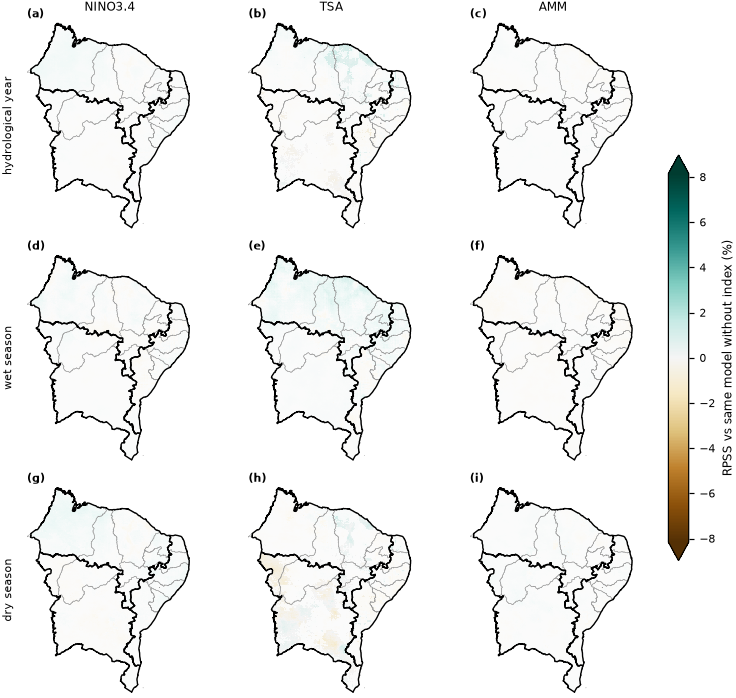

*RPSS de cada pixel de 0,05° em relação ao mesmo modelo sem o índice, com o modelo Ridge do pixel lendo o índice (colunas) na defasagem do pixel, por caso (linhas). Verde: o índice melhora a previsão da classe de quintil; marrom: piora. Cores esmaecidas: pixels sem significância com taxa de falsas descobertas de 10 %; a primeira classe de cor vai de −1 a +1 %. Arquivos: `resultados/completo/figuras/F29_pixel_rpss_ridge.png` e `.pdf` (170 × 161 mm).*

**Figura 30. Random Forest: habilidade pixel a pixel, 2011–2025**

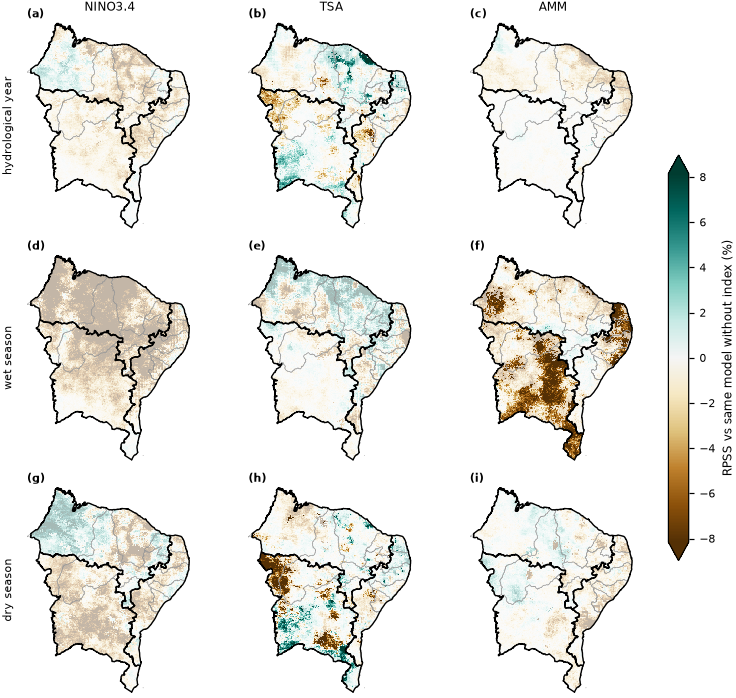

*RPSS de cada pixel de 0,05° em relação ao mesmo modelo sem o índice, com o modelo Random Forest do pixel lendo o índice (colunas) na defasagem do pixel, por caso (linhas). Verde: o índice melhora a previsão da classe de quintil; marrom: piora. Cores esmaecidas: pixels sem significância com taxa de falsas descobertas de 10 %; a primeira classe de cor vai de −1 a +1 %. Arquivos: `resultados/completo/figuras/F30_pixel_rpss_randomforest.png` e `.pdf` (170 × 161 mm).*

**Figura 31. Rede neural: habilidade pixel a pixel, 2011–2025**

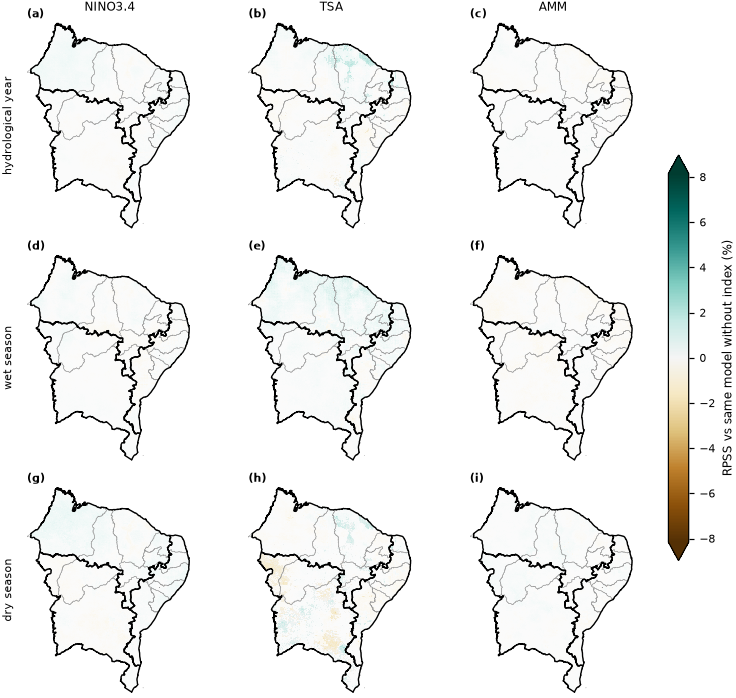

*RPSS de cada pixel de 0,05° em relação ao mesmo modelo sem o índice, com o modelo Rede neural do pixel lendo o índice (colunas) na defasagem do pixel, por caso (linhas). Verde: o índice melhora a previsão da classe de quintil; marrom: piora. Cores esmaecidas: pixels sem significância com taxa de falsas descobertas de 10 %; a primeira classe de cor vai de −1 a +1 %. Arquivos: `resultados/completo/figuras/F31_pixel_rpss_redeneural.png` e `.pdf` (170 × 161 mm).*

**Figura 32. Índice de maior habilidade em cada pixel**

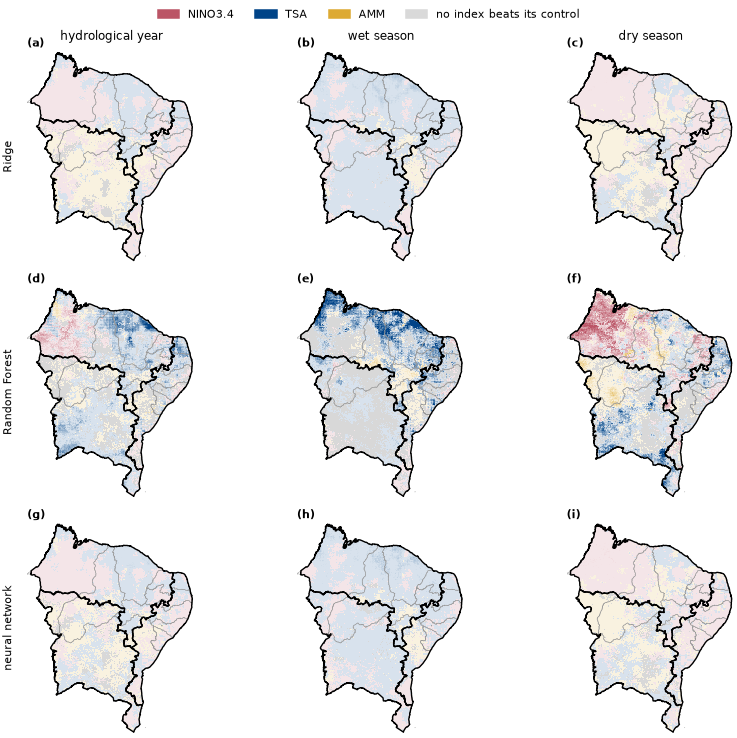

*Índice, entre os três avaliados sozinhos, com o maior RPSS em cada pixel, por método (linhas) e caso (colunas); cor mais intensa quanto maior o RPSS (saturada a partir de 10 %). Cinza: nenhum índice supera o controle sem índice do pixel. Exploratório. Arquivos: `resultados/completo/figuras/F32_pixel_predominante.png` e `.pdf` (170 × 171 mm).*

#### Síntese numérica

- Ridge: RPSS agregado dos pixels sobre o controle sem índice positivo em 13 de 27 combinações; maior em NNEB, estação chuvosa, TSA (+0,9 %; área com ganho significativo 0 %).
- Ridge: maior área com ganho significativo em INEB, estação seca, TSA (14 % da área).
- Random Forest: RPSS agregado dos pixels sobre o controle sem índice positivo em 3 de 27 combinações; maior em NNEB, estação chuvosa, TSA (+1,4 %; área com ganho significativo 0 %).
- Random Forest: maior área com ganho significativo em INEB, ano hidrológico, TSA (15 % da área).
- Rede neural: RPSS agregado dos pixels sobre o controle sem índice positivo em 13 de 27 combinações; maior em NNEB, estação chuvosa, TSA (+0,9 %; área com ganho significativo 0 %).
- Rede neural: maior área com ganho significativo em INEB, estação seca, TSA (11 % da área).
- Ridge, NNEB, ano hidrológico: NINO3.4 tem o maior RPSS positivo em 52 % da área.
- Ridge, INEB, ano hidrológico: AMM tem o maior RPSS positivo em 53 % da área.
- Ridge, ENEB, ano hidrológico: NINO3.4 tem o maior RPSS positivo em 53 % da área.
- Ridge, NNEB, estação chuvosa: TSA tem o maior RPSS positivo em 81 % da área.
- Ridge, INEB, estação chuvosa: TSA tem o maior RPSS positivo em 78 % da área.
- Ridge, ENEB, estação chuvosa: TSA tem o maior RPSS positivo em 54 % da área.
- Ridge, NNEB, estação seca: NINO3.4 tem o maior RPSS positivo em 71 % da área.
- Ridge, INEB, estação seca: AMM tem o maior RPSS positivo em 55 % da área.
- Ridge, ENEB, estação seca: NINO3.4 tem o maior RPSS positivo em 67 % da área.
- Validação do teste por pixel (índice deslocado, Ridge, cenário alternativo de seleção, com a mesma taxa de falsas descobertas dos mapas): área marcada como ganho sem relação entre índice e chuva de 0,01 % em média (máximo 0,6 %), um indicador de falsos alarmes, e não uma prova do controle da taxa de falsas descobertas; área com RPSS > 0 sob o nulo de 50 % em média, a referência do acaso para as áreas com RPSS > 0 da tabela de habilidade.

### Relatório parcial 14 · 31/10/2026 00:56 · fim da Seção 10

Modo completo. Tempo decorrido: 5 h 18 min. Término geral previsto: 31/10/2026 00:57.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | concluída | 259 / 259 | 6 min | 0 min | — |
| Seção 5 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 6 | concluída | 54 / 54 | 1 min | 0 min | — |
| Seção 7 | concluída | 54 / 54 | 3 min | 0 min | — |
| Seção 8 | concluída | 54 / 54 | 2 min | 0 min | — |
| Seção 9 | concluída | 201 / 201 | 59 min | 0 min | — |
| Seção 10 | concluída | 3267 / 3267 | 4 h 04 min | 0 min | — |
| Fechamento | aguardando | 0 / 1 | 0 min | 1 min (a priori) | 31/10 00:57 |

Últimos registros:
- 2026-10-31T03:50:22+00:00 | Seção 10: Random Forest, ENEB, seca, AMM: 8717 pixels em 3 min.
- 2026-10-31T03:55:51+00:00 | Seção 10: 81 combinações de método, alvo, caso e índice; RPSS agregado dos pixels sobre o controle sem índice positivo em 29.
- 2026-10-31T03:56:46+00:00 | Seção 10: concluída em 4 h 04 min.



In [24]:
# =============================================================================
# 10.3 Tabelas, figuras e síntese da previsão pixel a pixel. Lê apenas o que 10.2 gravou e a
# hipótese regional da Seção 9.
# =============================================================================
_reg = HIPOTESE[['método', 'alvo', 'caso', 'índice', 'L* (meses)',
                 'RPSS sobre o modelo sem índice (%)']].rename(
    columns={'L* (meses)': 'L* regional', 'RPSS sobre o modelo sem índice (%)':
             'RPSS do modelo regional sobre o seu controle sem índice (%)'})
PIXEL_TAB = PIXEL_TAB.merge(_reg, on=['método', 'alvo', 'caso', 'índice'], how='left')
tabela(com_rotulo(PIXEL_TAB), 'pixel_habilidade', 'Previsão pixel a pixel: habilidade por alvo',
       'Cada pixel de 0,05° tem o seu modelo, com o índice na defasagem do pixel (Seção 3: a '
       'própria onde a correlação do pixel é significativa, senão a regional) e treino único em '
       '1981–2010. RPSS agregado dos pixels sobre o controle sem índice: 1 − soma dos RPS '
       'dos pixels / soma dos RPS do controle (o mesmo modelo sem o índice) em cada pixel, '
       'ponderadas pela área (IC95 por '
       'reamostragem conjunta de blocos de anos; p da troca de sinal por ano). Áreas '
       'significativas: teste t por ano '
       'em cada pixel, com taxa de falsas descobertas de '
       f"{100 * PIX_CFG['alfa_fdr']:.0f} % em cada mapa (Wilks, 2016). Última coluna: RPSS do "
       'modelo regional da mesma combinação sobre o seu controle sem índice (Seções 6 a 8), que '
       'prevê a classe do alvo inteiro.',
       n=27)
tabela(com_rotulo(PRED_PIX_TAB), 'pixel_predominante', 'Índice de maior RPSS em cada pixel',
       'Para cada método e caso, a área de cada alvo em que cada índice, sozinho, tem o maior RPSS '
       'entre os três e esse RPSS é positivo; "nenhum": área em que nenhum índice supera o '
       'controle sem índice do pixel. Exploratório: o índice de maior RPSS pode trocar por '
       'acaso onde '
       'os RPSS são próximos.', n=36)
_val = VALIDACAO_PIX.groupby(['alvo', 'caso', 'índice'], sort=False)[
    ['área com ganho significativo sob o nulo (%)', 'área com RPSS > 0 sob o nulo (%)']].agg(
    ['mean', 'max']).round(2)
_val.columns = [f'{a} ({"média" if b == "mean" else "máximo"})' for a, b in _val.columns]
_val = _val.reset_index()
tabela(_val, 'pixel_validacao', 'Validação do teste por pixel',
       f"Séries do índice deslocadas no tempo ({PIX_CFG['deslocamentos_validacao']} "
       'deslocamentos circulares, sem relação com a chuva), com a defasagem de cada pixel '
       'reaferida no treino (sem a escolha entre a própria e a regional: cenário alternativo de '
       'seleção) e a Ridge do pixel, com a mesma taxa de falsas descobertas dos mapas (Benjamini '
       'e Hochberg a 10 % no mapa inteiro de cada caso e índice). Área com ganho significativo '
       'sob o nulo: '
       'área marcada como ganho sem relação entre índice e chuva (falsos alarmes nesses '
       'cenários); não demonstra, por si, o controle da taxa de falsas descobertas. Área com '
       'RPSS > 0 sob o nulo: o que o acaso produz sem teste.', n=27)


def mapa_rpss(ax, campo, sig, vmax):
    """RPSS por pixel em escala contínua divergente centrada em zero (BrBG), sem faixa central
    que esconda efeitos pequenos; pixels sem significância ficam esmaecidos, fora dos alvos em
    branco."""
    cmap = plt.get_cmap('BrBG')
    norma = matplotlib.colors.Normalize(-vmax, vmax)
    rgba = cmap(norma(np.nan_to_num(campo)))
    rgba[~sig] = 0.35 * rgba[~sig] + 0.65
    rgba[~np.isfinite(campo) | (DONO < 0)] = (1, 1, 1, 1)
    ax.imshow(rgba, origin='lower', extent=EXTENSAO, interpolation='nearest')
    desenhar_alvos(ax)
    formatar_mapa(ax, rotulos=False)
    return plt.cm.ScalarMappable(norm=norma, cmap=cmap)


todas = np.concatenate([v[np.isfinite(v)] for v in MAPA_RPSS.values()])
VMAX_RPSS = max(float(np.nanpercentile(np.abs(todas), 98)), PIX_CFG['classe_cor'])
for metodo in MODELOS:
    fig, axs = plt.subplots(len(CASOS), len(INDICES), figsize=(2.3 * len(INDICES) + 0.6,
                                                              2.3 * len(CASOS)), squeeze=False)
    for (i, caso), (j, indice) in itertools.product(enumerate(CASOS), enumerate(INDICES)):
        ax = axs[i, j]
        sm = mapa_rpss(ax, MAPA_RPSS[(metodo, caso, indice)], MAPA_SIG[(metodo, caso, indice)],
                       VMAX_RPSS)
        if i == 0:
            ax.set_title(indice)
        if j == 0:
            ax.text(-0.08, 0.5, EN[caso], transform=ax.transAxes, rotation=90, ha='right',
                    va='center', fontsize=7)
    fig.colorbar(sm, ax=axs, shrink=0.6, extend='both', label='RPSS vs same model without index (%)')
    figura(fig, f"pixel_rpss_{metodo.replace(' ', '').lower()}",
           f'{metodo}: habilidade pixel a pixel, 2011–2025',
           f'RPSS de cada pixel de 0,05° em relação ao mesmo modelo sem o índice, com o modelo '
           f'{metodo} do pixel lendo o índice (colunas) na defasagem do pixel, por caso '
           '(linhas). Verde: o índice melhora a previsão da classe de quintil; marrom: piora. '
           'Cores '
           'esmaecidas: pixels sem significância com taxa de falsas descobertas de '
           f"{100 * PIX_CFG['alfa_fdr']:.0f} %; a primeira classe de cor vai de "
           f"−{PIX_CFG['classe_cor']:g} a +{PIX_CFG['classe_cor']:g} %.",
           dpi=CFG['figuras']['dpi_mapas'])

cores_idx = np.array([to_rgb(COR[n]) for n in INDICES])
fig, axs = plt.subplots(len(MODELOS), len(CASOS), figsize=(2.3 * len(CASOS) + 0.6,
                                                          2.3 * len(MODELOS)), squeeze=False)
for (i, metodo), (k, caso) in itertools.product(enumerate(MODELOS), enumerate(CASOS)):
    ax = axs[i, k]
    melhor, valor = PRED_PIX[(metodo, caso)]
    a = np.clip(np.nan_to_num(valor) / 10, 0.15, 1.0)[..., None]
    rgb = 1 - a * (1 - cores_idx[np.clip(melhor, 0, None)])
    rgb[~(valor > 0)] = 0.85
    rgb[(DONO < 0) | (melhor < 0)] = 1.0
    ax.imshow(rgb, origin='lower', extent=EXTENSAO, interpolation='nearest')
    desenhar_alvos(ax)
    formatar_mapa(ax, rotulos=False)
    if i == 0:
        ax.set_title(EN[caso])
    if k == 0:
        ax.text(-0.08, 0.5, EN[metodo], transform=ax.transAxes, rotation=90, ha='right',
                va='center', fontsize=7)
fig.legend(handles=[Patch(color=COR[n], label=n) for n in INDICES]
           + [Patch(color='0.85', label='no index beats its control')],
           loc='outside upper center', ncol=4)
figura(fig, 'pixel_predominante', 'Índice de maior habilidade em cada pixel',
       'Índice, entre os três avaliados sozinhos, com o maior RPSS em cada pixel, por método '
       '(linhas) e caso (colunas); cor mais intensa quanto maior o RPSS (saturada a partir de 10 '
       '%). Cinza: nenhum índice supera o controle sem índice do pixel. Exploratório.',
       dpi=CFG['figuras']['dpi_mapas'])

linhas = []
for metodo in MODELOS:
    d = PIXEL_TAB[PIXEL_TAB['método'] == metodo]
    r = d.sort_values(RPSS_AGREG).iloc[-1]
    linhas.append(f"{metodo}: RPSS agregado dos pixels sobre o controle sem índice positivo em "
                  f"{int((d[RPSS_AGREG] > 0).sum())} de {len(d)} "
                  f"combinações; maior em {r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['índice']} "
                  f"({r[RPSS_AGREG]:+.1f} %; área com ganho "
                  f"significativo {r['área com ganho significativo (%)']:.0f} %).")
    s = d.sort_values('área com ganho significativo (%)').iloc[-1]
    linhas.append(f"{metodo}: maior área com ganho significativo em {s['alvo']}, "
                  f"{ROTULO_CASO[s['caso']]}, {s['índice']} "
                  f"({s['área com ganho significativo (%)']:.0f} % da área).")
for (metodo, alvo, caso), g in PRED_PIX_TAB.groupby(['método', 'alvo', 'caso'], sort=False):
    if metodo != 'Ridge':
        continue
    r = g.sort_values('área em que tem o maior RPSS, positivo (%)').iloc[-1]
    linhas.append(f"Ridge, {alvo}, {ROTULO_CASO[caso]}: {r['índice']} tem o maior RPSS positivo "
                  f"em {r['área em que tem o maior RPSS, positivo (%)']:.0f} % da área.")
_g = VALIDACAO_PIX['área com ganho significativo sob o nulo (%)']
_r = VALIDACAO_PIX['área com RPSS > 0 sob o nulo (%)']
linhas.append(f'Validação do teste por pixel (índice deslocado, Ridge, cenário alternativo de '
              'seleção, com a mesma taxa de falsas descobertas dos mapas): '
              f'área marcada como ganho sem relação entre índice e chuva de {_g.mean():.2f} % em '
              f'média (máximo {_g.max():.1f} %), um indicador de falsos alarmes, e não uma prova '
              'do controle da taxa de falsas descobertas; '
              f'área com RPSS > 0 sob o nulo de {_r.mean():.0f} % em média, a referência do '
              'acaso para as áreas com RPSS > 0 da tabela de habilidade.')
sintese(linhas)
PIXEL_TAB.to_csv(PASTAS['registros'] / 'pixel_habilidade.csv', index=False, encoding='utf-8-sig')
PROGRESSO.concluir('Seção 10')

### 10.4 Results and discussion

On the maps, each pixel shows the magnitude of the RPSS over the no-index control, and faded colour marks pixels without significance under the false discovery rate; magnitude and significance are read together, and a significant area with a very small RPSS carries little practical weight. The area with significant gain is compared with the area flagged under the null in the validation table, which is an alternative selection scenario, not the exact rule. The aggregate pixel RPSS over the no-index control and the RPSS of the regional model over its control answer different questions, and the difference between them does not, on its own, identify its cause. The map of the index with the highest skill is exploratory.

### 10.5 Conclusion

The section delivers the skill of each index and method in each 0.05° pixel, its field-controlled significance, an indicator of false alarms for that control and the index with the highest skill in each pixel.

### 10.6 References

BENJAMINI, Y.; HOCHBERG, Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. **Journal of the Royal Statistical Society: Series B**, v. 57, n. 1, p. 289-300, 1995. DOI: 10.1111/j.2517-6161.1995.tb02031.x.

WILKS, D. S. “The stippling shows statistically significant grid points”: how research results are routinely overstated and overinterpreted, and what to do about it. **Bulletin of the American Meteorological Society**, v. 97, n. 12, p. 2263-2273, 2016. DOI: 10.1175/BAMS-D-15-00267.1.

---

# Closing

Answers the question of each section and the hypothesis with the numbers from the tables, checks the figures against the International Journal of Climatology standard and writes the run manifest (`resultados/<mode>/registros/manifesto.json`): signature of the code and configuration, environment, input data and SHA-256 of each table, figure, forecast and map. No number in this part is typed by hand.

In [25]:
# =============================================================================
# Fechamento: respostas às perguntas das seções e à hipótese, conformidade das figuras, tempo
# de cada seção e manifesto da execução (SHA-256 de cada saída). Lê apenas o que foi calculado.
# =============================================================================
PROGRESSO.iniciar('Fechamento', 1)


def lista(df, formato, vazio='nenhuma'):
    """Itens de um DataFrame em uma frase, separados por ponto e vírgula."""
    return '; '.join(formato(r) for _, r in df.iterrows()) if len(df) else vazio


def melhor_q(df):
    """Linhas com primeira previsão melhor (q < 0,05 e diferença positiva)."""
    return df[(df['q (BH)'] < ALFA) & (df['diferença de RPSS (p.p.)'] > 0)]


n_ok = sum(v['resultado'] == 'ok' for v in VERIFICACOES)
det = SINAL[SINAL['detectado (q < 0,05)']]
campo_L = CAMPO[CAMPO['defasagem atribuída (L*)']]
pred = PREDOMINIO.dropna(subset=['área em que predomina (%)'])
pred = pred.loc[pred.groupby(['alvo', 'caso'])['área em que predomina (%)'].idxmax()]
a0 = melhor_q(A0)
RESPOSTAS = [
    ('1', 'base de todas as seções',
     f'{n_ok} de {len(VERIFICACOES)} verificações aprovadas, entre elas o calendário das estações '
     'calculado pela referência 1981–2010, igual ao fixado na capa nos três alvos, e as classes '
     'de quintil equilibradas na referência. Pixels suspeitos de quebra no CHIRPS, mantidos nas '
     'análises e listados em registros/pixels_suspeitos.csv: '
     + '; '.join(f"{r['alvo']} {r['suspeito, 3–4 testes, marcado (% da área)']:.1f} % da área"
                 for _, r in HOMOG_TAB.iterrows())
     + '. Área com ao menos 1 mês de classes desequilibradas por empates: '
     + '; '.join(f"{r['alvo']} {r['área com ao menos 1 mês desequilibrado (%)']:.0f} %"
                 for _, r in HOMOG_TAB.iterrows()) + '.'),
    ('2', 'em que defasagem cada índice se associa à chuva?',
     f'associação detectada (q < 0,05) em {len(det)} de {len(SINAL)} combinações: '
     + lista(det, lambda r: f"{r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['índice']} em "
                            f"L{r['L* (meses)']} (r = {r['r(L*)']:+.2f})") + '. Diagnóstico '
     f"até L{CFG['defasagem']['diagnostico_ate']}: pico além da janela em "
     f"{int(DIAG_JANELA['pico além da janela'].sum())} de {len(DIAG_JANELA)} combinações, com "
     f"ganho de |r| de até {DIAG_JANELA['ganho de |r| além da janela'].max():.2f}."),
    ('3', 'onde a associação aparece e qual índice predomina?',
     f"{int(CAMPO['campo detectado'].sum())} de {len(CAMPO)} mapas detectados pelo teste de "
     f"campo; nas defasagens atribuídas, {int(campo_L['campo detectado'].sum())} de "
     f"{len(campo_L)}; área com pixel significativo (taxa de falsas descobertas de "
     f"{100 * ALFA_PIX:.0f} %): mediana de "
     f"{DEF_PIX['área com pixel significativo (%)'].median():.0f} % entre as {len(DEF_PIX)} "
     'combinações. Índice de maior área (exploratório): '
     + lista(pred, lambda r: f"{r['alvo']}, {ROTULO_CASO[r['caso']]}: {r['índice']} "
                             f"({r['área em que predomina (%)']:.0f} %)") + '.'),
    ('4', 'qual configuração cada modelo usa?',
     f"entrada {ROTULO_ENTRADA_PT[ENTRADA['entrada']]}"
     f"{', com interação com o mês' if ENTRADA['sazonal'] else ''}, índice "
     f"{'sem tendência' if ENTRADA['filtro'] == 'sem_tendencia' else 'bruto'}; treino único; "
     f'média de {REDES} redes; '
     + '; '.join(f'{m}: {json.dumps(ESCOLHA[m], ensure_ascii=False)}' for m in MODELOS)
     + '. Sinal plantado de 0,3: RPSS de validação ' + ', '.join(
         f"{r['método']} {r['RPSS (%)']:+.2f} %" for _, r in
         SINAL_PLANTADO[SINAL_PLANTADO['correlação plantada'] > 0].iterrows())
     + '; sem sinal: ' + ', '.join(
         f"{r['método']} {r['RPSS (%)']:+.2f} %" for _, r in
         SINAL_PLANTADO[SINAL_PLANTADO['correlação plantada'] == 0].iterrows()) + '.'),
    ('5', 'a fase do índice, sem modelo, melhora a climatologia?',
     f'N-índice supera N com q < 0,05 (valor-p do nulo de deslocamento do índice) em {len(a0)} '
     f'de {len(A0)} comparações: '
     + lista(a0, lambda r: f"{r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['comparação']} "
                           f"({r['diferença de RPSS (p.p.)']:+.1f} p.p.)") + '.'),
]
for k, metodo in enumerate(MODELOS):
    d = HIPOTESE[HIPOTESE['método'] == metodo]
    s = d[d['hipótese sustentada']]
    c = d.dropna(subset=['q (L* − L1)'])
    c_sim = c[(c['q (L* − L1)'] < ALFA) & (c['ganho de L* sobre L1 (p.p.)'] > 0)]
    pergunta = ['o índice melhora a previsão num modelo linear?',
                'e num modelo não linear em degraus?', 'e numa rede neural?'][k]
    RESPOSTAS.append((str(6 + k), pergunta,
                      f"{metodo}: hipótese sustentada em {len(s)} de {len(d)} combinações de alvo, "
                      'caso e índice: '
                      + lista(s, lambda r: f"{r['alvo']}, {ROTULO_CASO[r['caso']]}, "
                                           f"{r['índice']} em L{r['L* (meses)']} "
                                           '(RPSS '
                                           f"{r['RPSS sobre o modelo sem índice (%)']:+.1f} %)")
                      + f'. L* melhor que L1 com q < 0,05 em {len(c_sim)} de {len(c)}.'))
partes = []
for a, b in PARES:
    g = E_TAB[E_TAB['comparação'] == f'{a} − {b}']
    mais = int(((g['q (BH)'] < ALFA) & (g[DIF_E] < 0)).sum())
    menos = int(((g['q (BH)'] < ALFA) & (g[DIF_E] > 0)).sum())
    partes.append(f'{a} − {b}: {menos} a favor de {a} e {mais} a favor de {b}')
partes_f = []
for c in CASOS:
    g = HIPOTESE[HIPOTESE.caso == c]
    partes_f.append(f"{ROTULO_CASO[c]}: "
                    f"{int((g['RPSS sobre o modelo sem índice (%)'] > 0).sum())} de {len(g)}")
RESPOSTAS.append(('9', 'a habilidade muda entre modelos e entre casos?',
                  'comparações entre métodos com q < 0,05 (grupo E, diferença de habilidade '
                  'normalizada por N): ' + '; '.join(partes)
                  + '. Combinações de método, alvo e índice com RPSS positivo sobre o modelo '
                  'sem índice (grupo F): ' + '; '.join(partes_f)
                  + '. Confiabilidade (Brier, eventos Q1 e Q5): '
                  + '; '.join(f"{r['método']} {r['evento']} {r['Brier']:.3f} contra "
                              f"{r['Brier da climatologia (20 %)']:.3f} da climatologia"
                              for _, r in CONFIAB.iterrows())
                  + '. Largura mediana do IC95 do RPSS: '
                  + '; '.join(f"{r['método']} "
                              f"{r['largura mediana do IC95 do RPSS (p.p.)']:.1f} p.p."
                              for _, r in VALIDADE.iterrows()) + '.'))
_pix = PIXEL_TAB.sort_values('área com ganho significativo (%)', ascending=False).head(3)
RESPOSTAS.append(('10', 'onde cada índice melhora a previsão?',
                  'RPSS agregado dos pixels sobre o controle sem índice positivo em '
                  f"{int((PIXEL_TAB[RPSS_AGREG] > 0).sum())} de "
                  f'{len(PIXEL_TAB)} combinações de método, alvo, caso e índice; maiores áreas com '
                  'ganho significativo: ' + lista(_pix, lambda r: (
                      f"{r['método']}, {r['alvo']}, {ROTULO_CASO[r['caso']]}, {r['índice']} "
                      f"({r['área com ganho significativo (%)']:.0f} % da área)"))
                  + '. Validação com o índice deslocado: área com ganho significativo sob o '
                  'nulo de '
                  f"{VALIDACAO_PIX['área com ganho significativo sob o nulo (%)'].mean():.2f}"
                  ' % em média.'))
RESPOSTAS = pd.DataFrame(RESPOSTAS, columns=['seção', 'pergunta', 'resposta'])
RESPOSTAS['resposta'] = RESPOSTAS['resposta'].map(br)
tabela(RESPOSTAS, 'respostas', 'Resposta de cada seção',
       'Frases montadas a partir das tabelas das Seções 1 a 10; nenhum número foi digitado.')

linhas = []
for alvo, caso, indice in itertools.product(ALVOS, CASOS, INDICES):
    linha = {'alvo': alvo, 'caso': ROTULO_CASO[caso], 'índice': indice,
             'L* (meses)': DEFASAGENS[(alvo, caso)]['L*'][indice]}
    for metodo in MODELOS:
        d = HIPOTESE[(HIPOTESE['método'] == metodo) & (HIPOTESE.alvo == alvo)
                     & (HIPOTESE.caso == caso) & (HIPOTESE['índice'] == indice)]
        linha[metodo] = ('sem unidade' if not len(d) else br(
            f"{d['veredito'].iloc[0]} "
            f"(RPSS {d['RPSS sobre o modelo sem índice (%)'].iloc[0]:+.1f} %; "
            f"q = {d['q'].iloc[0]:.3f})"))   # 3 casas: 0,0515 não pode aparecer como 0,05
    linhas.append(linha)
VEREDITO = pd.DataFrame(linhas)
tabela(VEREDITO, 'veredito_hipotese', 'Hipótese: veredito por alvo, caso, índice e método',
       'Sim: o modelo que lê o índice alinhado na defasagem aferida L* tem RPSS positivo sobre o '
       'mesmo modelo sem índice e q < 0,05 (valor-p do nulo de deslocamento do índice, que repete '
       'a busca da defasagem). Não: o teste não detectou ganho, o que não prova ausência de efeito '
       '(ver o IC95). Inconclusiva: ganho com q < 0,05 numa combinação em que a verificação com '
       'a Ridge rejeitou acima de 5 % com o índice que só compartilha a tendência linear com a '
       'chuva. Entre parênteses: RPSS (%) e '
       'valor q.', n=27)

INVENTARIO = pd.DataFrame(FIGURAS_INV)
tabela(INVENTARIO, 'inventario_figuras', 'Conformidade das figuras',
       'Largura e altura finais, resolução e tamanho de cada figura. Padrão do International '
       'Journal of Climatology: largura de 80 a 180 mm e arquivos menores que 10 MB.', n=40)

with PROGRESSO.trava:
    TEMPOS = pd.DataFrame([{'seção': n, 'unidades': s['total'],
                            'duração': duracao(s['fim'] - s['inicio']) if s['fim'] else
                            (duracao(time.time() - s['inicio']) if s['inicio'] else '—')}
                           for n, s in PROGRESSO.secoes.items()])
tabela(TEMPOS, 'tempo_secoes', 'Tempo de execução de cada seção',
       f'Medido nesta execução, no modo {MODO}; seções retomadas a partir de unidades já gravadas '
       'contam só o tempo da retomada.')

VOLATEIS = {'relatorio_parcial.md', 'relatorio_atual.md', 'execucao.log', 'manifesto.json'}
arquivos = sorted(p for p in SAIDA.rglob('*') if p.is_file() and p.name not in VOLATEIS
                  and not p.name.endswith(('.tmp', '.invalido')))
MANIFESTO = dict(assinatura=ASSINATURA, gerado_utc=agora_utc(),
                 ambiente=dict(zip(AMBIENTE['item'], AMBIENTE['valor'].astype(str))),
                 configuracao=CFG, dados=registro(), numeracao=REF,
                 arquivos={p.relative_to(RAIZ).as_posix(): dict(bytes=p.stat().st_size,
                                                                sha256=sha256_arquivo(p))
                           for p in tqdm(arquivos, desc='SHA-256 das saídas')})
salvar_json(PASTAS['registros'] / 'manifesto.json', MANIFESTO)
resumo_pastas = pd.DataFrame([{'pasta': p.relative_to(RAIZ).as_posix(),
                               'arquivos': sum(1 for a in arquivos if a.parent == p),
                               'MB': sum(a.stat().st_size for a in arquivos if a.parent == p) / 1e6}
                              for p in PASTAS.values()])
tabela(resumo_pastas, 'manifesto_saidas', 'Manifesto das saídas',
       f'Arquivos gravados nesta execução, por pasta; o SHA-256 de cada um está em '
       f"`resultados/{MODO}/registros/manifesto.json` (assinatura "
       f"{ASSINATURA['assinatura'][:12]}).")

fora = INVENTARIO[~INVENTARIO['dentro do padrão']] if len(INVENTARIO) else INVENTARIO
sintese([
    f"Hipótese sustentada em {int(HIPOTESE['hipótese sustentada'].sum())} de {len(HIPOTESE)} "
    'combinações de método, alvo, caso e índice.',
    f"{len(INVENTARIO)} figuras e {sum(1 for r in REF.values() if r.startswith('Tabela'))} tabelas "
    f'numeradas; figuras fora do padrão: {len(fora)}.',
    f'{len(arquivos)} arquivos de saída com SHA-256 no manifesto.',
    f'Modo {MODO}' + ('; os números do piloto só conferem o código e não servem para conclusões.'
                      if MODO == 'piloto' else '.')])
PROGRESSO.concluir('Fechamento')
PROGRESSO.parar()
registrar(f'fim da execução | modo {MODO} | assinatura {ASSINATURA["assinatura"][:12]}')

**Tabela 54. Resposta de cada seção**

,seção,pergunta,resposta
0,1,base de todas as seções,"32 de 32 verificações aprovadas, entre elas o ..."
1,2,em que defasagem cada índice se associa à chuva?,"associação detectada (q < 0,05) em 11 de 27 co..."
2,3,onde a associação aparece e qual índice predom...,112 de 351 mapas detectados pelo teste de camp...
3,4,qual configuração cada modelo usa?,"entrada índice em L*, índice bruto; treino úni..."
4,5,"a fase do índice, sem modelo, melhora a climat...","N-índice supera N com q < 0,05 (valor-p do nul..."
5,6,o índice melhora a previsão num modelo linear?,Ridge: hipótese sustentada em 0 de 27 combinaç...
6,7,e num modelo não linear em degraus?,Random Forest: hipótese sustentada em 0 de 27 ...
7,8,e numa rede neural?,Rede neural: hipótese sustentada em 0 de 27 co...
8,9,a habilidade muda entre modelos e entre casos?,"comparações entre métodos com q < 0,05 (grupo ..."
9,10,onde cada índice melhora a previsão?,RPSS agregado dos pixels sobre o controle sem ...


*Frases montadas a partir das tabelas das Seções 1 a 10; nenhum número foi digitado. Arquivo: `resultados/completo/tabelas/T54_respostas.csv`.*

**Tabela 55. Hipótese: veredito por alvo, caso, índice e método**

,alvo,caso,índice,L* (meses),Ridge,Random Forest,Rede neural
0,NNEB,ano hidrológico,NINO3.4,4,"não detectada (RPSS +0,9 %; q = 0,069)","não detectada (RPSS −1,8 %; q = 1,000)","não detectada (RPSS +0,8 %; q = 0,103)"
1,NNEB,ano hidrológico,TSA,1,"não detectada (RPSS +0,6 %; q = 0,137)","não detectada (RPSS +2,5 %; q = 0,309)","não detectada (RPSS +0,6 %; q = 0,137)"
2,NNEB,ano hidrológico,AMM,1,"não detectada (RPSS +0,1 %; q = 0,675)","não detectada (RPSS −0,6 %; q = 1,000)","não detectada (RPSS +0,0 %; q = 0,745)"
3,NNEB,estação chuvosa,NINO3.4,1,"não detectada (RPSS −0,0 %; q = 1,000)","não detectada (RPSS −16,6 %; q = 1,000)","não detectada (RPSS −0,1 %; q = 0,985)"
4,NNEB,estação chuvosa,TSA,2,"não detectada (RPSS +1,5 %; q = 0,069)","não detectada (RPSS +2,0 %; q = 0,309)","não detectada (RPSS +1,5 %; q = 0,103)"
5,NNEB,estação chuvosa,AMM,1,"não detectada (RPSS −0,1 %; q = 1,000)","não detectada (RPSS −1,5 %; q = 1,000)","não detectada (RPSS −0,1 %; q = 0,985)"
6,NNEB,estação seca,NINO3.4,4,"não detectada (RPSS +1,8 %; q = 0,069)","não detectada (RPSS +5,6 %; q = 0,206)","não detectada (RPSS +0,9 %; q = 0,155)"
7,NNEB,estação seca,TSA,1,"não detectada (RPSS −0,0 %; q = 1,000)","não detectada (RPSS −1,1 %; q = 1,000)","não detectada (RPSS −0,1 %; q = 0,985)"
8,NNEB,estação seca,AMM,4,"não detectada (RPSS +0,1 %; q = 0,739)","não detectada (RPSS +0,3 %; q = 1,000)","não detectada (RPSS +0,2 %; q = 0,745)"
9,INEB,ano hidrológico,NINO3.4,7,"não detectada (RPSS −0,2 %; q = 1,000)","não detectada (RPSS −4,7 %; q = 1,000)","não detectada (RPSS −0,3 %; q = 0,985)"


*Sim: o modelo que lê o índice alinhado na defasagem aferida L* tem RPSS positivo sobre o mesmo modelo sem índice e q < 0,05 (valor-p do nulo de deslocamento do índice, que repete a busca da defasagem). Não: o teste não detectou ganho, o que não prova ausência de efeito (ver o IC95). Inconclusiva: ganho com q < 0,05 numa combinação em que a verificação com a Ridge rejeitou acima de 5 % com o índice que só compartilha a tendência linear com a chuva. Entre parênteses: RPSS (%) e valor q. Arquivo: `resultados/completo/tabelas/T55_veredito_hipotese.csv`.*

... (18 outputs left out)

*Arquivos gravados nesta execução, por pasta; o SHA-256 de cada um está em `resultados/completo/registros/manifesto.json` (assinatura 23f3260ccb7c). Arquivo: `resultados/completo/tabelas/T58_manifesto_saidas.csv`.*

#### Síntese numérica

- Hipótese sustentada em 0 de 81 combinações de método, alvo, caso e índice.
- 32 figuras e 48 tabelas numeradas; figuras fora do padrão: 0.
- 794 arquivos de saída com SHA-256 no manifesto.
- Modo completo.

### Relatório parcial 15 · 31/10/2026 00:56 · fim da Fechamento

Modo completo. Tempo decorrido: 5 h 18 min. Término geral previsto: 31/10/2026 00:56.

| seção | situação | feitas / total | decorrido | restante previsto | término previsto |
|---|---|---|---|---|---|
| Aquisição | concluída | 46 / 46 | 0 min | 0 min | — |
| Seção 1 | concluída | 1 / 1 | 0 min | 0 min | — |
| Seção 2 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 3 | concluída | 9 / 9 | 2 min | 0 min | — |
| Seção 4 | concluída | 259 / 259 | 6 min | 0 min | — |
| Seção 5 | concluída | 9 / 9 | 0 min | 0 min | — |
| Seção 6 | concluída | 54 / 54 | 1 min | 0 min | — |
| Seção 7 | concluída | 54 / 54 | 3 min | 0 min | — |
| Seção 8 | concluída | 54 / 54 | 2 min | 0 min | — |
| Seção 9 | concluída | 201 / 201 | 59 min | 0 min | — |
| Seção 10 | concluída | 3267 / 3267 | 4 h 04 min | 0 min | — |
| Fechamento | concluída | 1 / 1 | 0 min | 0 min | — |

Últimos registros:
- 2026-10-31T03:56:46+00:00 | Seção 10: concluída em 4 h 04 min.
- 2026-10-31T03:56:46+00:00 | Fechamento: iniciada (1 unidades de trabalho).
- 2026-10-31T03:56:47+00:00 | Fechamento: concluída em 0 min.



fim da execução | modo completo | assinatura 23f3260ccb7c
